# Final thesis plots

Clean, publication-quality versions of the main oscillon results, all in one place.
Every panel is rendered inline **and** saved as a PDF (with a PNG mirror) in `GoodFigures/`.

**Conventions (applied to every panel below):**
- One *selection* cell with explicit lists of which parameters to plot.
- One *plot* cell ending in `save_fig(fig, NAME); plt.show()`.

**Index of panels:**
1. Scalar field at $r=0$ vs $t$ and vs shifted $\ln(a)$.
2. Four-panel paper diagnostics (`plot_paper_diagnostics`) for one chosen run.
3. Central density $\rho_c$ vs background density $\bar\rho$ — decoupling from the Hubble flow.
4. Compactness, weak-coupling condition and $g_2$ hyperbolicity (3-stack EFT diagnostics, $\ln(a)\in[2,3.5]$).
5. Density contrast $\delta_c$: with vs without backreaction.
4a. Max compactness heatmap over $(\lambda_{\rm GB},\, g_2)$ at $\beta=0$.
6. GW spectrum benchmark (Antusch-Cefala-Orani 2017, Fig. 2).

Further panels will be added on request, following the same pattern.

## 0 — Imports and output directory

In [1]:
import sys, os, re, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
sys.path.insert(0, PROJECT_ROOT)

from core.grid import Grid
from core.spacing import CubicSpacing
from core.statevector import StateVector
from matter.scalarmatter_MG import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.oscillondiagnostic import get_oscillon_diagnostic, plot_paper_diagnostics
from bssn.EFTdiagnostic import get_eft_diagnostic

from paths import RUN_DATA
DATA_DIR = str(RUN_DATA)
FIG_DIR  = Path(os.getcwd()) / "GoodFigures"
FIG_DIR.mkdir(exist_ok=True)

print(f"DATA_DIR = {DATA_DIR}")
print(f"FIG_DIR  = {FIG_DIR}")

DATA_DIR = /lustre/hpc/astro/syildiz/VSC_home/0scillons/oscillon_runs_data
FIG_DIR  = /lustre/hpc/astro/syildiz/VSC_home/0scillons/February26Oscillons/Feb26/RunningCode/DATA/GoodFigures


## 1 — Publication style and figure-saving helper

In [6]:
plt.rcParams.update({
    "font.family":      "serif",
    "mathtext.fontset": "cm",
    "figure.dpi":       120,
    "savefig.dpi":      300,
    "savefig.bbox":     "tight",
    "axes.labelsize":   23,
    "axes.titlesize":   16,
    "xtick.labelsize":  15,
    "ytick.labelsize":  15,
    "legend.fontsize":  15,
    "lines.linewidth":  1,
    "axes.linewidth":   1.1,
    "xtick.major.width": 1.1,
    "ytick.major.width": 1.1,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,
    "xtick.major.size":  5.0,
    "ytick.major.size":  5.0,
    "axes.grid":        False,
    "grid.alpha":       0.3,
    "ytick.direction":  "in",
    "xtick.direction":  "in",
})

def save_fig(fig, name):
    """Save fig as both PDF and PNG in GoodFigures/."""
    pdf_path = FIG_DIR / f"{name}.pdf"
    png_path = FIG_DIR / f"{name}.png"
    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, bbox_inches="tight")
    print(f"  saved {pdf_path.name} and {png_path.name}")

In [7]:
plt.rcParams.update({
    "font.family":      "serif",
    "mathtext.fontset": "cm",
    "figure.dpi":       120,
    "savefig.dpi":      300,
    "savefig.bbox":     "tight",
    "axes.labelsize":   23,
    "axes.titlesize":   16,
    "xtick.labelsize":  12,
    "ytick.labelsize":  12,
    "legend.fontsize":  13,
    "lines.linewidth":  2.5,
    "axes.linewidth":   3,
    "xtick.major.width": 1.3,
    "ytick.major.width": 1.3,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,
    "xtick.major.size":  5.0,
    "ytick.major.size":  5.0,
    "axes.grid":        False,
    "grid.alpha":       0.3,
    "ytick.direction":  "in",
    "xtick.direction":  "in",
})

def save_fig(fig, name):
    """Save fig as both PDF and PNG in GoodFigures/."""
    pdf_path = FIG_DIR / f"{name}.pdf"
    png_path = FIG_DIR / f"{name}.png"
    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, bbox_inches="tight")
    print(f"  saved {pdf_path.name} and {png_path.name}")

## 2 — Alignment and grid parameters

All runs share the same physical grid and modified-gravity background; alignment shifts each
run's $\ln(a)$ axis so the last crossing of a per-amplitude compactness threshold sits at
`ALIGN_LNA`.

In [8]:
ALIGN_LNA      = 2.0
ALIGN_METHOD   = "last_cross"   # "min_C" or "last_cross"
LNA_MIN_SEARCH = 0.0

C_CROSS_LEVELS = {
    -0.02: 0.02,
    -0.05: 0.04,
    -0.1:  0.06,
    -0.5:  0.125,
}
C_CROSS_DEFAULT = 0.02

LN_A_COMP_MIN = 2.0
LN_A_COMP_MAX = 3.5

scalar_mu = 1
r_max     = 150
min_dr    = 1 / 16
max_dr    = 2
a_mg      = 0.2
b_mg      = 0.4
chi0      = 0.15

## 3 — Alignment helpers

In [9]:
def find_peak_lna(osc, lna_min=0.0):
    """Return ln(a) of the minimum compactness after lna_min."""
    C = osc["C"]
    ln_a = osc["ln_a"]
    mask = ln_a > lna_min
    if not np.any(mask):
        return np.nan
    idx = np.where(mask)[0]
    peak = idx[np.argmin(C[idx])]
    return ln_a[peak]

def find_last_crossing_lna(osc, level, lna_min=0.0):
    """Return ln(a) of the last time C crosses `level` (from above) after lna_min."""
    C = osc["C"]
    ln_a = osc["ln_a"]
    mask = ln_a > lna_min
    if not np.any(mask):
        return np.nan
    idx = np.where(mask)[0]
    C_sub = C[idx]
    ln_a_sub = ln_a[idx]
    above = C_sub > level
    crossings = np.where(above[:-1] & ~above[1:])[0]
    if len(crossings) == 0:
        return np.nan
    last = crossings[-1]
    frac = (level - C_sub[last+1]) / (C_sub[last] - C_sub[last+1])
    return ln_a_sub[last] * frac + ln_a_sub[last+1] * (1 - frac)

def compactness_in_window(shifted_ln_a, C, lo=LN_A_COMP_MIN, hi=LN_A_COMP_MAX):
    """Mean, min, max, std of C inside [lo, hi] on the *shifted* axis."""
    mask = (shifted_ln_a >= lo) & (shifted_ln_a <= hi)
    if not np.any(mask):
        return np.nan, np.nan, np.nan, np.nan
    c = C[mask]
    return np.mean(c), np.min(c), np.max(c), np.std(c)

def _key_sort(key):
    """Sort key for run-keys that may contain None (e.g. beta=None for linear coupling).

    Maps None -> +inf so linear runs sort after numeric beta values.
    """
    return tuple(float('inf') if v is None else v for v in key)

## 4 — Load all runs at the chosen resolution

Loads every run that matches the loading filters (default: $a_{\rm MG}=b_{\rm MG}=0$, $\Delta r = 1/24$),
computes/loads diagnostics, applies the alignment shift, and also stashes the central scalar field
$\phi(r=0,t)$ so plot 1 doesn't need to reload `solution.npy`.

In [10]:
######## LOADING FILTERS ########
FILTER_A_MG = 0       # None to load all
FILTER_B_MG = 0       # None to load all
FILTER_DR   = 1/24    # None to load all
############################

# Key now includes g2 so quadratic and g2-EFT runs with the same
# (lgb, mu, beta, amp, width) but different g2 don't overwrite each other.
all_runs = {}   # key = (lgb, mu, beta, amp, width, g2)

for run_dir in sorted(glob.glob(os.path.join(DATA_DIR, "lgb*"))):
    tag = os.path.basename(run_dir)
    if not os.path.exists(os.path.join(run_dir, "solution.npy")):
        continue

    m_lgb = re.search(r"lgb([0-9eE.+-]+)", tag)
    m_mu  = re.search(r"mu([0-9eE.+-]+)", tag)
    m_amp = re.search(r"_amp([0-9eE.+-]+)", tag)
    m_R   = re.search(r"_R([0-9eE.+-]+)", tag)
    if not m_lgb or not m_mu:
        continue
    lgb   = float(m_lgb.group(1))
    mu    = float(m_mu.group(1))
    amp   = float(m_amp.group(1)) if m_amp else -0.02
    width = float(m_R.group(1))   if m_R   else 3.0

    m_a = re.search(r"_a([0-9eE.+-]+)_b", tag)
    m_b = re.search(r"_b([0-9eE.+-]+)_amp", tag)
    tag_a = float(m_a.group(1)) if m_a else 0.2
    tag_b = float(m_b.group(1)) if m_b else 0.4

    m_dr = re.search(r"_dr([0-9eE.+-]+)", tag)
    tag_dr = float(m_dr.group(1)) if m_dr else 0.0625

    if FILTER_A_MG is not None and abs(tag_a - FILTER_A_MG) > 1e-10:
        continue
    if FILTER_B_MG is not None and abs(tag_b - FILTER_B_MG) > 1e-10:
        continue
    if FILTER_DR is not None and abs(tag_dr - FILTER_DR) > 1e-4:
        continue

    # Derive coupling and beta from metadata.npz (authoritative source).
    # Per bssn/ModifiedGravity.py: "quadratic" (no suffix) => beta=250;
    # "quadratic_X" => beta=X; "linear" => beta=None.
    _meta_for_cpl = os.path.join(run_dir, "metadata.npz")
    _cpl_meta = None
    if os.path.exists(_meta_for_cpl):
        try:
            _md = dict(np.load(_meta_for_cpl, allow_pickle=True))
            if "coupling" in _md:
                _cpl_meta = str(_md["coupling"])
        except Exception:
            pass

    if _cpl_meta is not None:
        if _cpl_meta == "linear":
            coupling = "linear"; beta = None
        elif _cpl_meta.startswith("quadratic"):
            _parts = _cpl_meta.split("_")
            beta = float(_parts[1]) if len(_parts) > 1 else 250.0
            coupling = _cpl_meta
        else:
            coupling = _cpl_meta; beta = None
    else:
        # Fallback for runs with missing metadata: parse from tag string.
        if "_linear" in tag:
            coupling = "linear"; beta = None
        else:
            _m_beta = re.search(r"quadratic_(\d+\.?\d*)", tag)
            if _m_beta:
                beta = float(_m_beta.group(1))
                coupling = f"quadratic_{int(beta)}" if beta == int(beta) else f"quadratic_{beta}"
            else:
                # "_quadratic_g2X" or trailing "_quadratic" => coupling="quadratic" => beta=250
                coupling = "quadratic"; beta = 250.0

    # Extract g2: first from directory name, then from metadata, default 0.0
    g2_val = 0.0
    m_g2 = re.search(r"_g2([0-9eE.+-]+)", tag)
    if m_g2:
        g2_val = float(m_g2.group(1))
    else:
        meta_path = os.path.join(run_dir, "metadata.npz")
        if os.path.exists(meta_path):
            try:
                meta = dict(np.load(meta_path, allow_pickle=True))
                if "g2" in meta:
                    g2_val = float(meta["g2"])
            except Exception:
                pass

    # Grid must match the run that wrote solution.npy (notebook r_max/min_dr alone can differ).
    _meta_for_grid = os.path.join(run_dir, "metadata.npz")
    _meta_grid = dict(np.load(_meta_for_grid, allow_pickle=True)) if os.path.exists(_meta_for_grid) else {}
    run_r_max  = float(_meta_grid.get("r_max", r_max))
    run_min_dr = float(_meta_grid.get("min_dr", tag_dr))
    run_max_dr = float(_meta_grid.get("max_dr", max_dr))

    sol = np.load(os.path.join(run_dir, "solution.npy"))
    t   = np.load(os.path.join(run_dir, "t.npy"))

    matter_i  = ScalarMatter(scalar_mu, mu)
    sv_i      = StateVector(matter_i)
    spacing_i = CubicSpacing(**CubicSpacing.get_parameters(run_r_max, run_min_dr, run_max_dr))
    grid_i    = Grid(spacing_i, sv_i)
    bg_i      = FlatSphericalBackground(grid_i.r)

    diag_path = os.path.join(run_dir, "diagnostics.npz")
    if os.path.exists(diag_path):
        osc = dict(np.load(diag_path, allow_pickle=True))
    else:
        params = (lgb, a_mg, b_mg, chi0, coupling, g2_val)
        osc = get_oscillon_diagnostic(
            sol, t, grid_i, bg_i,
            ScalarMatter(scalar_mu, mu),
            params, surface_threshold=0.05, r_max_diag=100.0,
        )
        np.savez(diag_path, **osc)

    # Stash central scalar field phi(r=0, t)
    N_grid   = len(grid_i.r)
    NUM_VARS = sol.shape[1] // N_grid
    phi_c    = sol[:, 12 * N_grid].copy()

    if ALIGN_METHOD == "last_cross":
        cross_level = C_CROSS_LEVELS.get(amp, C_CROSS_DEFAULT)
        anchor_lna  = find_last_crossing_lna(osc, level=cross_level, lna_min=LNA_MIN_SEARCH)
    else:
        anchor_lna  = find_peak_lna(osc, lna_min=LNA_MIN_SEARCH)
    shift = ALIGN_LNA - anchor_lna if not np.isnan(anchor_lna) else 0.0
    shifted_ln_a = osc["ln_a"] + shift

    C_mean, C_min, C_max, C_std = compactness_in_window(shifted_ln_a, osc["C"])

    key = (lgb, mu, beta, amp, width, g2_val)
    new_entry = dict(
        osc=osc, t=t, phi_c=phi_c, tag=tag,
        lgb=lgb, mu=mu, beta=beta, coupling=coupling, amp=amp, width=width, g2=g2_val,
        run_dir=run_dir, dr=tag_dr,
        run_r_max=run_r_max, run_min_dr=run_min_dr, run_max_dr=run_max_dr,
        shift=shift, shifted_ln_a=shifted_ln_a,
        C_mean=C_mean, C_min=C_min, C_max=C_max, C_std=C_std,
    )

    # If another run already occupies this key, keep the one with the longer
    # shifted_ln_a span so a short/incomplete duplicate doesn't shadow a good
    # run. Ties are broken by the alphabetically-later tag (matches the old
    # "sorted() last wins" behaviour).
    if key in all_runs:
        prev = all_runs[key]
        prev_span = float(np.ptp(np.asarray(prev["shifted_ln_a"])))
        new_span  = float(np.ptp(np.asarray(shifted_ln_a)))
        if new_span > prev_span or (new_span == prev_span and tag > prev["tag"]):
            print(f"  [overwrite] {prev['tag']} -> {tag}  "
                  f"(ln_a span {prev_span:.3f} -> {new_span:.3f})")
            all_runs[key] = new_entry
        else:
            print(f"  [skip]      {tag}  (would shadow {prev['tag']} "
                  f"with shorter ln_a span {new_span:.3f} < {prev_span:.3f})")
            del sol
            continue
    else:
        all_runs[key] = new_entry

    beta_str = f"beta={int(beta)}" if beta is not None else "linear"
    if np.isnan(C_mean):
        print(f"  lgb={lgb:6.1f}, mu={mu}, {beta_str:>10s}, A={amp}, R={width}, g2={g2_val:g}  "
              f"shift={shift:+.3f}  C: no data in window  ({len(t)} steps)")
    else:
        print(f"  lgb={lgb:6.1f}, mu={mu}, {beta_str:>10s}, A={amp}, R={width}, g2={g2_val:g}  "
              f"shift={shift:+.3f}  C={C_mean:.4e} [{C_min:.4e}, {C_max:.4e}]  ({len(t)} steps)")
    del sol

print(f"\nTotal: {len(all_runs)} run(s) loaded and aligned")

  lgb=  -1.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=0  shift=+0.075  C=3.7425e-03 [2.4388e-03, 7.5874e-03]  (1000 steps)
  lgb=  -1.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=20  shift=+0.538  C=7.1395e-03 [4.3339e-03, 1.4466e-02]  (1000 steps)
  lgb=  -2.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=0  shift=+0.046  C=3.5947e-03 [2.3579e-03, 7.4759e-03]  (1000 steps)
  lgb=  -2.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=20  shift=+0.536  C=7.0535e-03 [4.2847e-03, 1.3609e-02]  (1000 steps)
  lgb=  -3.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=0  shift=+0.039  C=3.4475e-03 [2.2732e-03, 7.2629e-03]  (1000 steps)
  lgb=  -3.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=20  shift=+0.531  C=6.9746e-03 [4.2228e-03, 1.3554e-02]  (1000 steps)
  lgb=  -4.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=0  shift=+0.007  C=3.3198e-03 [2.1817e-03, 7.1751e-03]  (1000 steps)
  lgb=  -4.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=20  shift=+0.526  C=6.8850e-03 [4.1713e-03, 1.3361e-02]  (1000 steps)
  lgb=  -5.0

## 5 — Parameter catalogue

Overview of which parameters are available in `all_runs` after filtering.

In [11]:
all_lgb   = sorted(set(k[0] for k in all_runs))
all_mu    = sorted(set(k[1] for k in all_runs))
all_beta  = sorted(set(k[2] for k in all_runs if k[2] is not None))
has_linear = any(k[2] is None for k in all_runs)
all_amp   = sorted(set(k[3] for k in all_runs))
all_width = sorted(set(k[4] for k in all_runs))
all_g2    = sorted(set(k[5] for k in all_runs))
all_couplings = sorted(set(d["coupling"] for d in all_runs.values()))

print(f"runs loaded:      {len(all_runs)}")
print(f"lambda_GB values: {all_lgb}")
print(f"mu values:        {all_mu}")
print(f"beta values:      {all_beta}" + ('  (+ linear runs present)' if has_linear else ''))
print(f"amplitude values: {all_amp}")
print(f"width values:     {all_width}")
print(f"g2 values:        {all_g2}")
print(f"couplings:        {all_couplings}")

print("\nLoaded keys (lgb, mu, beta, amp, width, g2):")
header = (f"  {'lgb':>6s}  {'mu':>5s}  {'beta':>5s}  {'amp':>6s}  {'R':>4s}  {'g2':>6s}  "
          f"{'coupling':<14s}  {'shift':>7s}  {'C_mean':>10s}")
print(header)
print("  " + "-" * (len(header) - 2))
for k in sorted(all_runs.keys(), key=_key_sort):
    d = all_runs[k]
    beta_s = "lin" if k[2] is None else f"{k[2]:g}"
    cmean  = "nan" if np.isnan(d['C_mean']) else f"{d['C_mean']:.3e}"
    print(f"  {k[0]:>6g}  {k[1]:>5g}  {beta_s:>5s}  {k[3]:>6g}  {k[4]:>4g}  {k[5]:>6g}  "
          f"{d['coupling']:<14s}  {d['shift']:>+7.3f}  {cmean:>10s}")

runs loaded:      236
lambda_GB values: [-9.0, -8.0, -7.0, -6.0, -5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0]
mu values:        [0.08]
beta values:      [0.0, 250.0]  (+ linear runs present)
amplitude values: [-1.0, -0.5, -0.1, -0.05, -0.02, -0.0002]
width values:     [3.0]
g2 values:        [-20.0, -18.0, -16.0, -14.0, -12.0, -10.0, -8.0, -6.0, -5.0, -4.0, -3.0, -2.0, -1.0, -0.5, 0.0, 0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 25.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 40.0, 50.0]
couplings:        ['linear', 'quadratic', 'quadratic_0', 'quadratic_0_noBR', 'quadratic_0_rampOn']

Loaded keys (lgb, mu, beta, amp, width, g2):
     lgb     mu   beta     amp     R      g2  coupling          shift      C_mean
  -------------------------------------------------------------------------------
      -9

## 6 — `select_runs` helper

One-liner for the per-panel selection cells. Any argument left as `None` matches all values.

In [12]:
def select_runs(lgb=None, mu=None, beta=None, amp=None, width=None, g2=None, coupling=None):
    """Return list of keys in all_runs whose fields are in the given allowed lists.

    Pass a single value or a list; None = no filter on that dimension.
    Keys are 6-tuples: (lgb, mu, beta, amp, width, g2).
    """
    def _norm(v):
        if v is None: return None
        return v if isinstance(v, (list, tuple, set)) else [v]

    lgb, mu, beta = _norm(lgb), _norm(mu), _norm(beta)
    amp, width, g2 = _norm(amp), _norm(width), _norm(g2)
    coupling = _norm(coupling)

    def _in(x, allowed): return allowed is None or x in allowed

    matches = [
        k for k, d in all_runs.items()
        if _in(k[0], lgb) and _in(k[1], mu) and _in(k[2], beta)
        and _in(k[3], amp) and _in(k[4], width) and _in(k[5], g2)
        and _in(d["coupling"], coupling)
    ]
    return sorted(matches, key=_key_sort)

## Panel 1 — Scalar field at $r=0$

Left subplot: $\phi(r=0)$ vs simulation time $t\ [1/m]$.<br>
Right subplot: $\phi(r=0)$ vs aligned $\ln(a)$.

Edit `PLOT1_*` below to pick which runs go on the figure.

In [13]:
### --- Panel 1 selection (edit me) ---
PLOT1_KEYS = select_runs(
    lgb   = [0,10],
    mu    = [0.08],
    beta  = [0],
    amp   = [-0.02],
    width = [3.0],
    g2= [0]
)
PLOT1_NAME = "Radius evolution"

print(f"{len(PLOT1_KEYS)} run(s) selected for Panel 1:")
for k in PLOT1_KEYS:
    print(" ", k, " coupling=", all_runs[k]["coupling"])

2 run(s) selected for Panel 1:
  (0.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0
  (10.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0


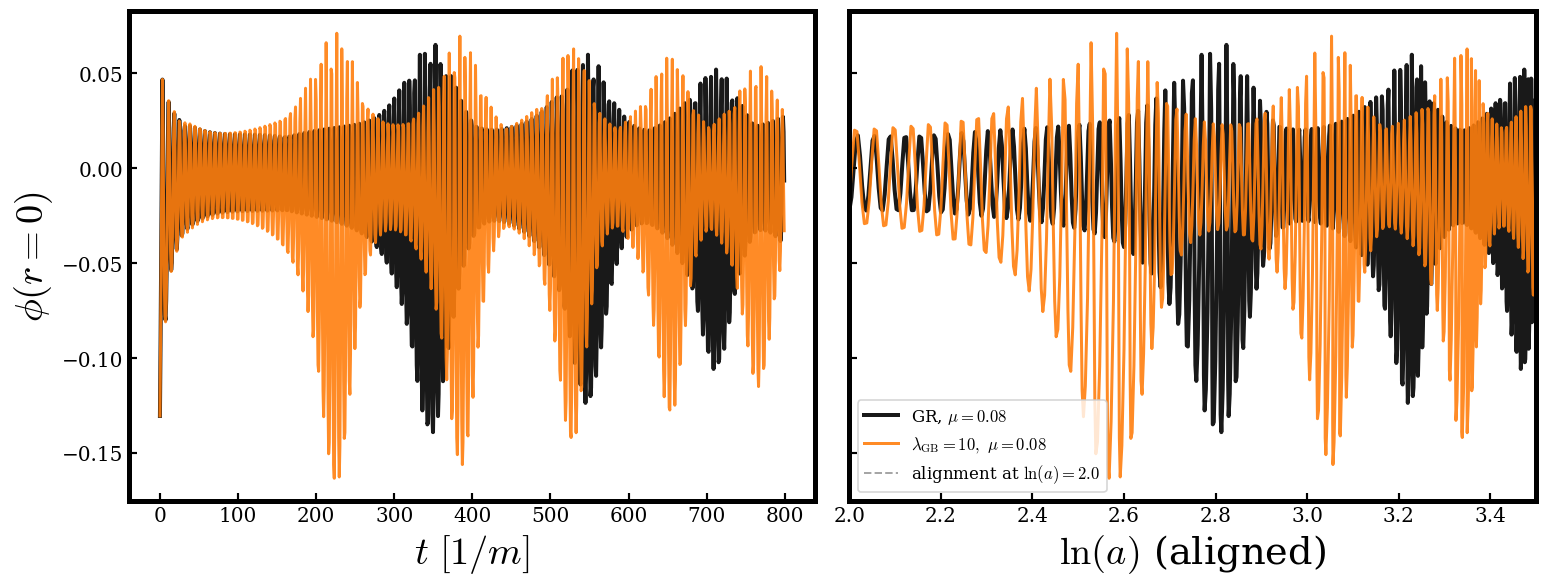

In [14]:
fig, (ax_t, ax_lna) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
cmap = plt.cm.tab10

for i, key in enumerate(PLOT1_KEYS):
    data = all_runs[key]
    lgb, mu, beta, amp, width, g2 = key

    if lgb == 0.0:
        label = rf"GR, $\mu={mu}$"
    else:
        beta_s = "" if (beta is None or beta == 0) else rf",\ \beta={int(beta)}"
        label  = rf"$\lambda_{{\rm GB}}={lgb:g},\ \mu={mu}{beta_s}$"

    color = "k" if lgb == 0.0 else cmap(i % 10)
    lw    = 2.4 if lgb == 0.0 else 1.8

    ax_t.plot(data["t"], data["phi_c"], color=color, lw=lw, label=label, alpha=0.9)
    ax_lna.plot(data["shifted_ln_a"], data["phi_c"], color=color, lw=lw, label=label, alpha=0.9)

ax_lna.axvline(ALIGN_LNA, color="grey", ls="--", lw=1.2, alpha=0.7,
               label=rf"alignment at $\ln(a)={ALIGN_LNA}$")

ax_t.set_xlabel(r"$t\ [1/m]$")
ax_t.set_ylabel(r"$\phi(r=0)$")
#ax_t.set_ylim(1,1.0025)
#ax_t.set_xlim(0,100)
#ax_t.set_title("Central scalar field vs physical time")

ax_lna.set_xlabel(r"$\ln(a)$ (aligned)")
ax_lna.set_xlim(2,3.5)

ax_lna.legend(fontsize=10, loc="best", frameon=True)
fig.tight_layout()
#save_fig(fig, PLOT1_NAME)
plt.show()

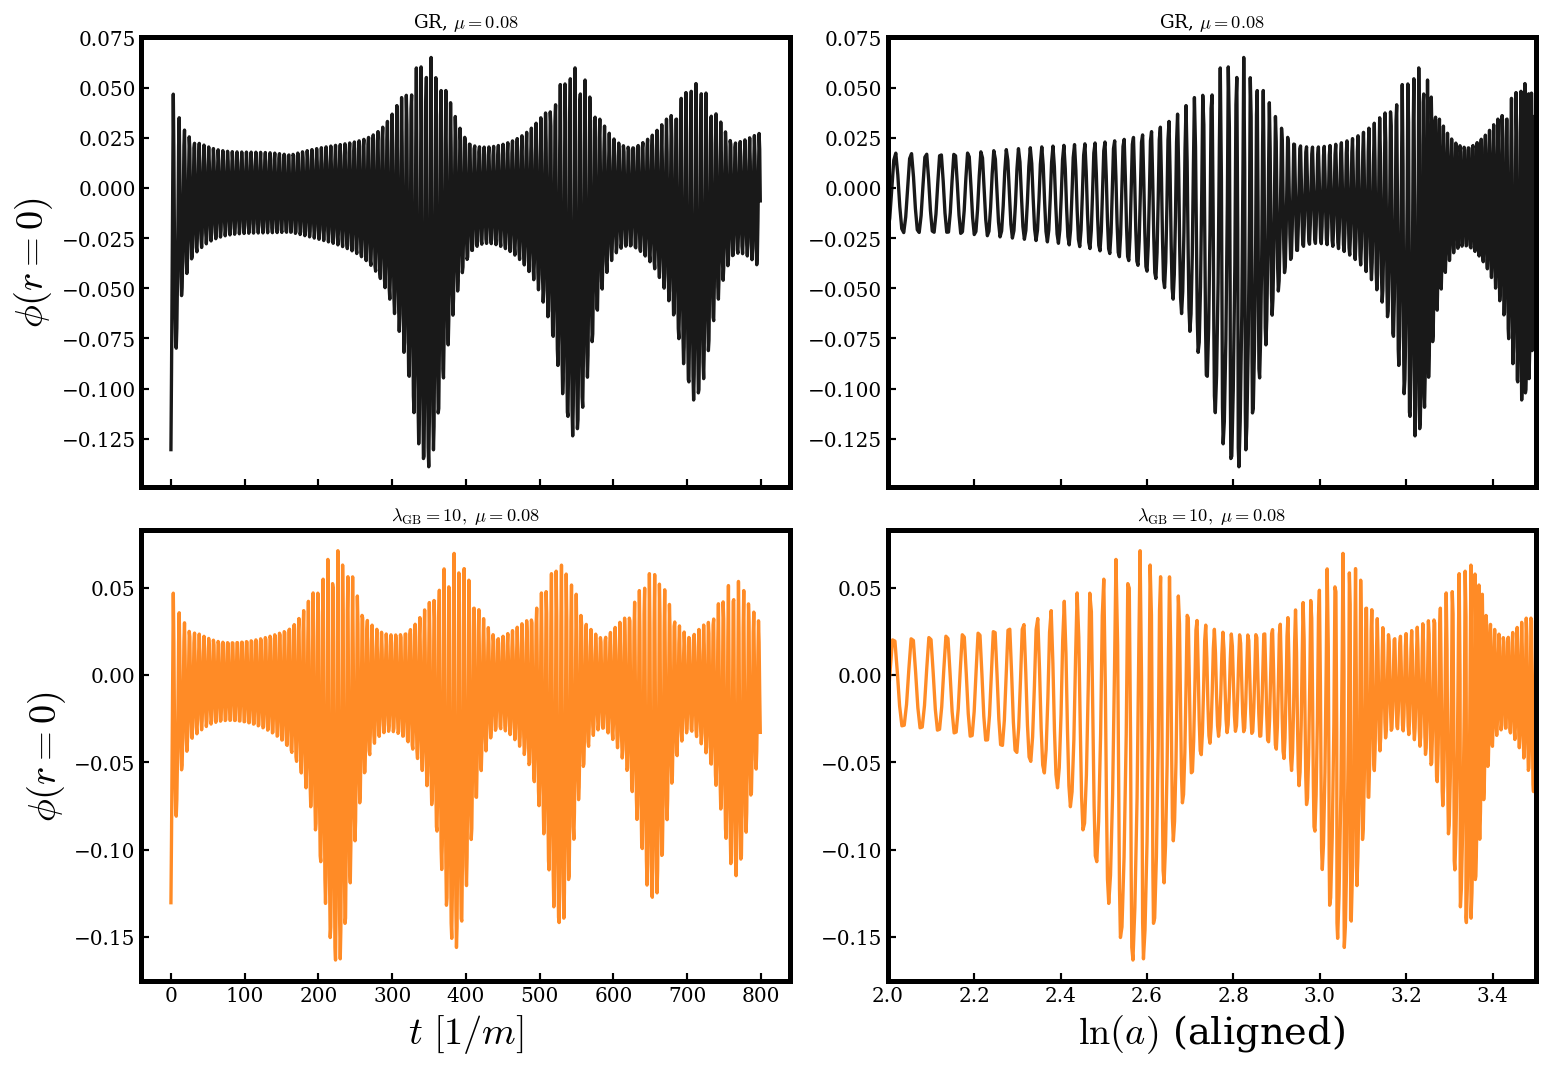

In [15]:
n_keys = len(PLOT1_KEYS)
fig, axes = plt.subplots(n_keys, 2, figsize=(13, 4.5 * n_keys), squeeze=False)
cmap = plt.cm.tab10

for i, key in enumerate(PLOT1_KEYS):
    ax_t, ax_lna = axes[i]
    data = all_runs[key]
    lgb, mu, beta, amp, width, g2 = key

    if lgb == 0.0:
        label = rf"GR, $\mu={mu}$"
    else:
        beta_s = "" if (beta is None or beta == 0) else rf",\ \beta={int(beta)}"
        label  = rf"$\lambda_{{\rm GB}}={lgb:g},\ \mu={mu}{beta_s}$"

    color = "k" if lgb == 0.0 else cmap(i % 10)
    lw = 2.0

    ax_t.plot(data["t"], data["phi_c"], color=color, lw=lw, alpha=0.9)
    ax_lna.plot(data["shifted_ln_a"], data["phi_c"], color=color, lw=lw, alpha=0.9)

    ax_lna.axvline(ALIGN_LNA, color="grey", ls="--", lw=1.2, alpha=0.7)

    ax_t.set_ylabel(r"$\phi(r=0)$")
    ax_t.set_title(label, fontsize=11)
    ax_lna.set_title(label, fontsize=11)
    ax_lna.set_xlim(2,3.5)

    if i == n_keys - 1:
        ax_t.set_xlabel(r"$t\ [1/m]$")
        ax_lna.set_xlabel(r"$\ln(a)$ (aligned)")
    else:
        ax_t.tick_params(labelbottom=False)
        ax_lna.tick_params(labelbottom=False)

fig.tight_layout()
plt.show()

  saved phi_c_compactness_lgb0_mu0.08_beta0.0_amp-0.02_w3.0_g20.pdf and phi_c_compactness_lgb0_mu0.08_beta0.0_amp-0.02_w3.0_g20.png


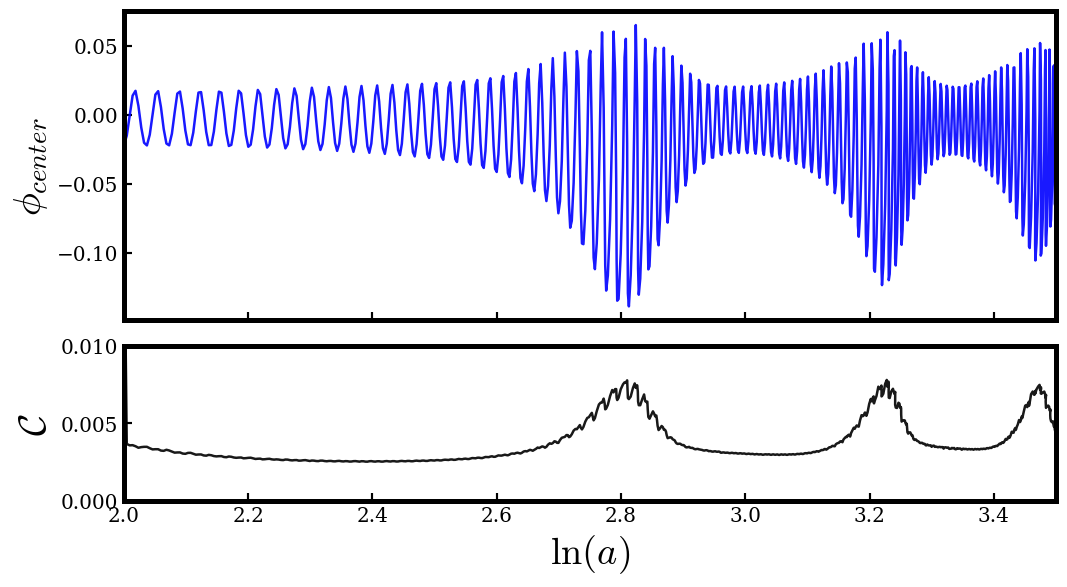

  saved phi_c_compactness_lgb10_mu0.08_beta0.0_amp-0.02_w3.0_g20.pdf and phi_c_compactness_lgb10_mu0.08_beta0.0_amp-0.02_w3.0_g20.png


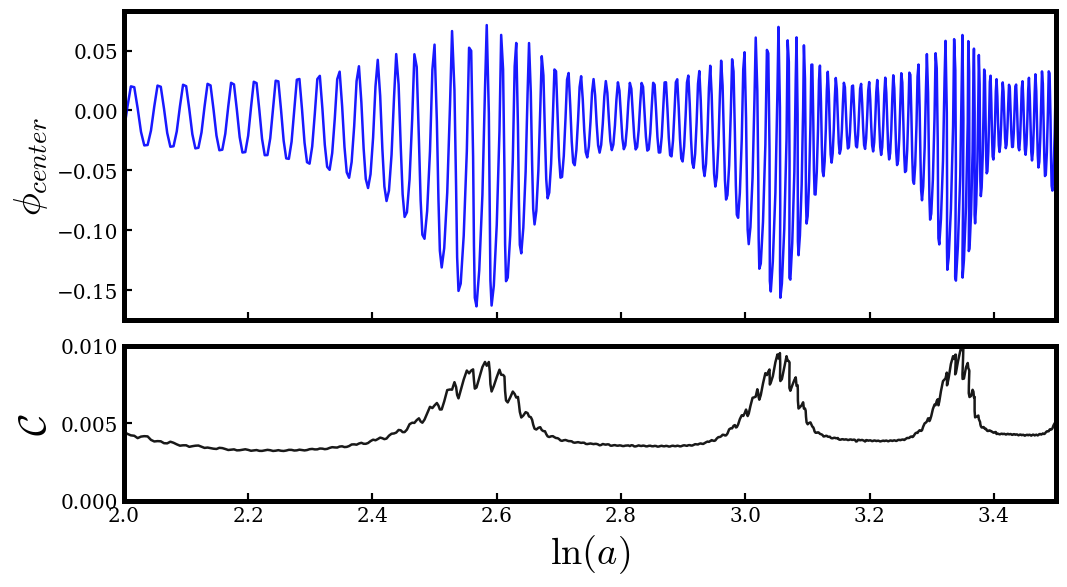

In [225]:
### --- Parameter selection (edit me) ---
PHIC_COMP_KEYS = select_runs(
    lgb   = [0,10],
    mu    = [0.08],
    beta  = [0],
    amp   = [-0.02],
    width = [3.0],
    g2    = [0],
)

### --- Plot: phi_c and compactness vs ln(a) ---
cmap_pc = plt.cm.tab10

for i, key in enumerate(PHIC_COMP_KEYS):
    data = all_runs[key]
    lgb, mu, beta, amp, width, g2 = key
    osc = data["osc"]
    shifted_ln_a = np.asarray(data["shifted_ln_a"])
    phi_c = np.asarray(data["phi_c"])
    C = np.asarray(osc["C"])

    if lgb == 0.0:
        label = rf"GR, $\mu={mu}$"
    else:
        beta_s = "" if (beta is None or beta == 0) else rf",\ \beta={int(beta)}"
        label  = rf"$\lambda_{{\rm GB}}={lgb:g},\ \mu={mu}{beta_s}$"

    color = "k" if lgb == 0.0 else cmap_pc(i % 10)

    fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(9, 5), sharex=True,
                                          gridspec_kw={"height_ratios": [2, 1]})

    ax_top.plot(shifted_ln_a, phi_c, color="b", lw=1.5, alpha=0.9)
    ax_top.set_ylabel(r"$\phi_{center}$")
    #ax_top.set_title(label, fontsize=12)
    ax_top.set_xlim(2,3.5)

    ax_bot.plot(shifted_ln_a[:len(C)], C, color="k", lw=1.5, alpha=0.9)
    ax_bot.set_ylabel(r"$\mathcal{C}$")
    ax_bot.set_xlabel(r"$\ln(a)$")
    ax_bot.set_xlim(2,3.5)
    ax_bot.set_ylim(0,1e-2)

    fig.tight_layout()
    tag = f"lgb{lgb:g}_mu{mu}_beta{beta}_amp{amp}_w{width}_g2{g2:g}"
    save_fig(fig, f"phi_c_compactness_{tag}")
    plt.show()

  saved phi_c_compactness_vs_t_lgb0_mu0.08_beta0.0_amp-0.02_w3.0_g20.pdf and phi_c_compactness_vs_t_lgb0_mu0.08_beta0.0_amp-0.02_w3.0_g20.png


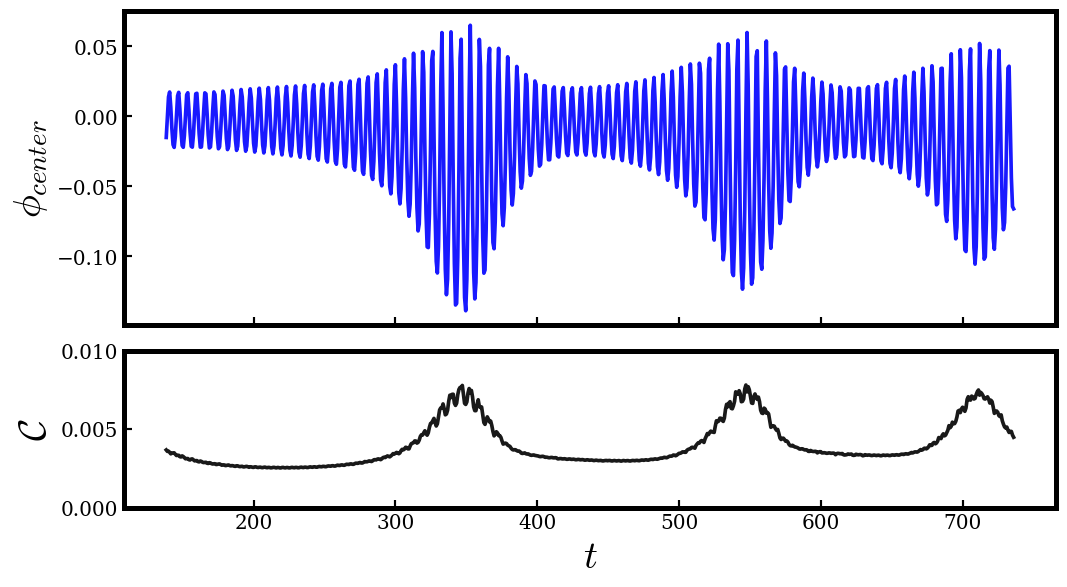

  saved phi_c_compactness_vs_t_lgb10_mu0.08_beta0.0_amp-0.02_w3.0_g20.pdf and phi_c_compactness_vs_t_lgb10_mu0.08_beta0.0_amp-0.02_w3.0_g20.png


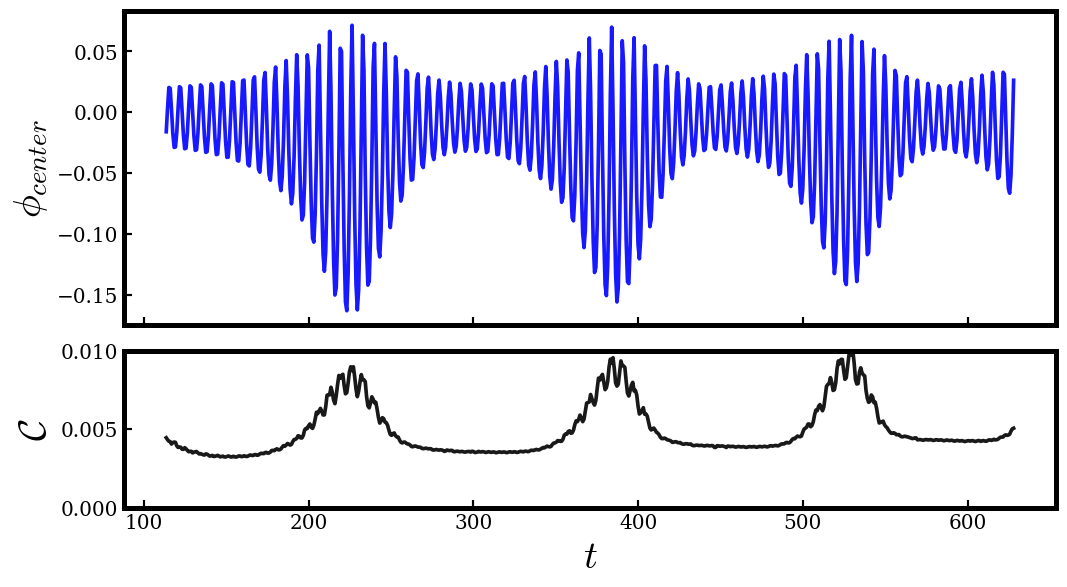

In [226]:
### --- Plot: phi_c and compactness vs cosmic time t ---
for i, key in enumerate(PHIC_COMP_KEYS):
    data = all_runs[key]
    lgb, mu, beta, amp, width, g2 = key
    osc = data["osc"]
    t_full = np.asarray(data["t"])
    t_osc = np.asarray(osc["t"])
    phi_c = np.asarray(data["phi_c"])
    C = np.asarray(osc["C"])

    if lgb == 0.0:
        label = rf"GR, $\mu={mu}$"
    else:
        beta_s = "" if (beta is None or beta == 0) else rf",\ \beta={int(beta)}"
        label  = rf"$\lambda_{{\rm GB}}={lgb:g},\ \mu={mu}{beta_s}$"

    color = "k" if lgb == 0.0 else cmap_pc(i % 10)

    # Restrict to the same ln(a) window [2, 3.5] used above
    shifted_ln_a = np.asarray(data["shifted_ln_a"])
    mask_phi = (shifted_ln_a >= 2) & (shifted_ln_a <= 3.5)
    shifted_ln_a_C = shifted_ln_a[:len(C)]
    mask_C = (shifted_ln_a_C >= 2) & (shifted_ln_a_C <= 3.5)

    fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(9, 5), sharex=True,
                                          gridspec_kw={"height_ratios": [2, 1]})

    ax_top.plot(t_full[mask_phi], phi_c[mask_phi], color="b", lw=2.2, alpha=0.9)
    ax_top.set_ylabel(r"$\phi_{center}$")

    ax_bot.plot(t_osc[:len(C)][mask_C], C[mask_C], color="k", lw=2.2, alpha=0.9)
    ax_bot.set_ylabel(r"$\mathcal{C}$")
    ax_bot.set_xlabel(r"$t$")
    ax_bot.set_ylim(0, 1e-2)

    fig.tight_layout()
    tag = f"lgb{lgb:g}_mu{mu}_beta{beta}_amp{amp}_w{width}_g2{g2:g}"
    save_fig(fig, f"phi_c_compactness_vs_t_{tag}")
    plt.show()

## Panel 2 — Paper diagnostics for one run

The four standard diagnostic panels from `bssn.oscillondiagnostic.plot_paper_diagnostics`
(density contrast, central density, mass & radius, compactness) plotted on the **shifted**
$\ln(a)$ axis for a single chosen run.

Edit `PLOT2_KEY` and `PLOT2_NAME` below.

In [227]:
### --- Panel 2 selection (edit me) ---
# key format: (lgb, mu, beta, amp, width, g2)
PLOT2_KEY  = (0, 0.08, 0, -0.02, 3.0, 0)
#PLOT2_NAME = "paper_diagnostics_GR_amp-0.02"
PLOT2_NAME = "MassRadiusCompactnessGR"

if PLOT2_KEY not in all_runs:
    print(f"Key {PLOT2_KEY} not found in all_runs.")
    print("Available keys:")
    for k in sorted(all_runs.keys(), key=_key_sort):
        print(" ", k)
else:
    print(f"Selected: {PLOT2_KEY}")
    print(f"  tag      = {all_runs[PLOT2_KEY]['tag']}")
    print(f"  coupling = {all_runs[PLOT2_KEY]['coupling']}")
    print(f"  shift    = {all_runs[PLOT2_KEY]['shift']:+.3f}")

Selected: (0, 0.08, 0, -0.02, 3.0, 0)
  tag      = lgb0.0_mu0.08_a0.0_b0.0_amp-0.02_R3.0_dr0.041666666666666664_quadratic_0
  coupling = quadratic_0
  shift    = +0.082


<>:68: SyntaxWarning: invalid escape sequence '\l'
<>:68: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1482965/854109404.py:68: SyntaxWarning: invalid escape sequence '\l'
  """


  saved MassRadiusCompactnessGR.pdf and MassRadiusCompactnessGR.png


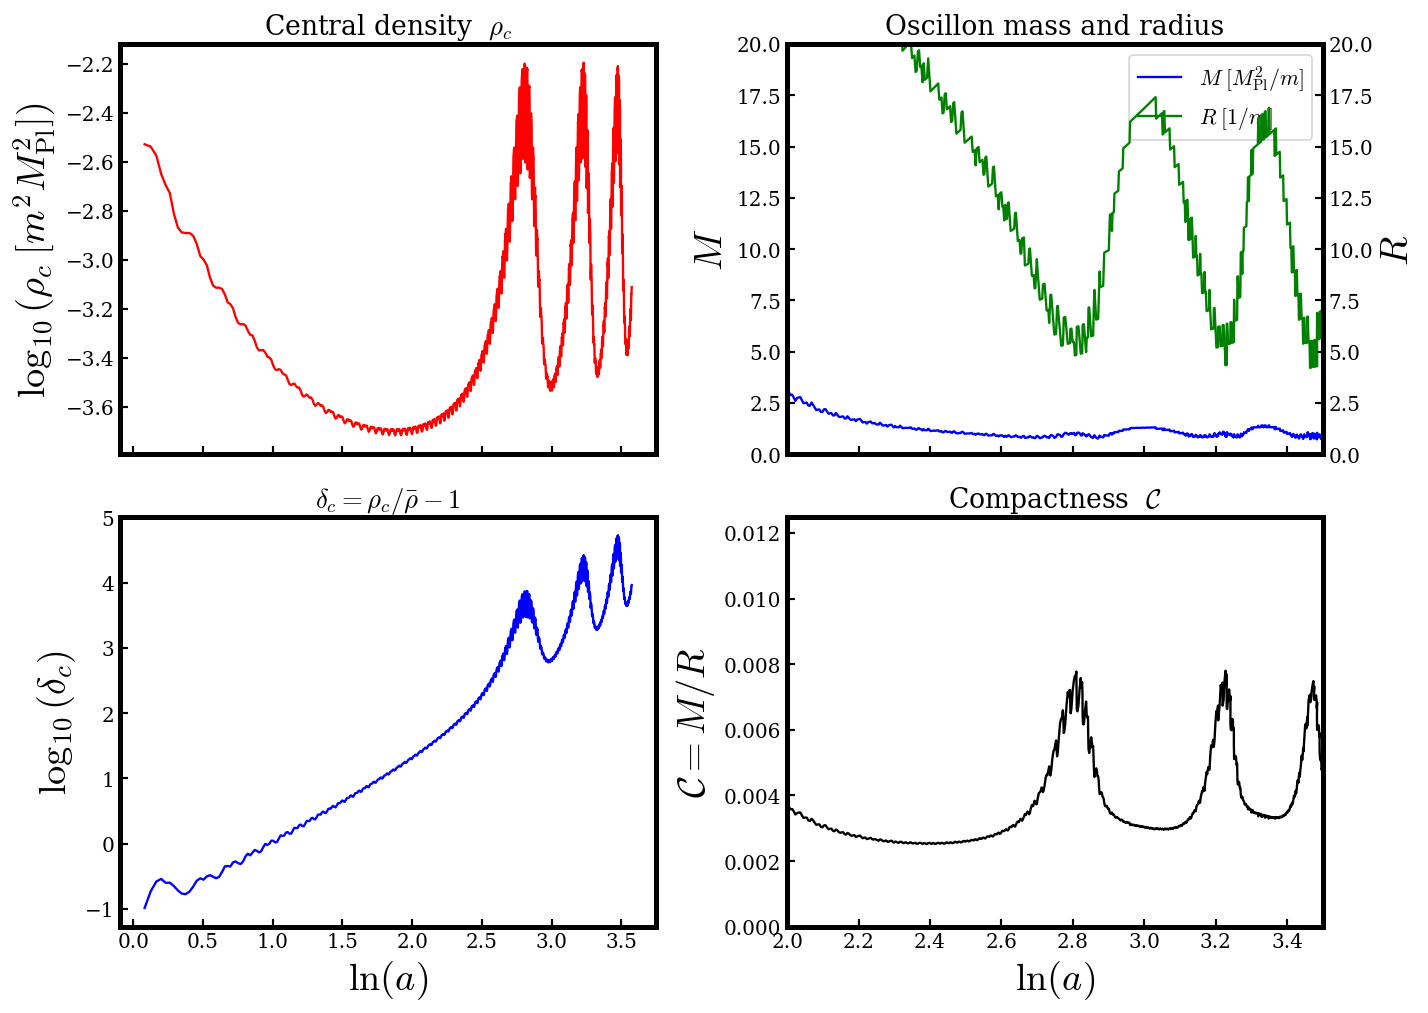

In [228]:
run = all_runs[PLOT2_KEY]
lgb_i, mu_i, beta_i, amp_i, width_i, g2_i = PLOT2_KEY

osc_shifted = {**run["osc"], "ln_a": run["shifted_ln_a"]}

# Custom 2x2 layout (re-arranged from plot_paper_diagnostics):
#   [0,0] log10(rho_c)   [0,1] M and R   (column 1 starts at ln(a)=2)
#   [1,0] log10(delta_c) [1,1] C         (column 1 starts at ln(a)=2)
# Columns share x via sharex='col' so stacked panels have identical x ranges.
x       = osc_shifted["ln_a"]
delta_c = osc_shifted["delta_c"]
rho_c   = osc_shifted["rho_c"]
M_arr   = osc_shifted["M"]
R_arr   = osc_shifted["R"]
C_arr   = osc_shifted["C"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex="col")

# [0,0] central density rho_c
ax = axes[0, 0]
pos_rho = rho_c > 0
y_rho = np.full_like(rho_c, np.nan)
y_rho[pos_rho] = np.log10(rho_c[pos_rho])
ax.plot(x, y_rho, "r-", lw=1.4)
ax.set_ylabel(r"$\log_{10}(\rho_c \; [m^2 M_{\rm Pl}^2])$")
ax.set_title(r"Central density  $\rho_c$")
#ax.grid(True, alpha=0.3)

# [0,1] oscillon mass and radius (starts at ln(a)=2)
ax_mr = axes[0, 1]
ax_mr.plot(x, M_arr, "b-", lw=1.4, label=r"$M \; [M_{\rm Pl}^2/m]$")
ax_mr_r = ax_mr.twinx()
ax_mr_r.plot(x, R_arr, "g-", lw=1.4, label=r"$R \; [1/m]$")
ax_mr.set_ylabel(r"$M$", color="black")
ax_mr_r.set_ylabel(r"$R$", color="black")
ax_mr_r.set_ylim(0,20)
ax_mr.set_ylim(0,20)
ax_mr.set_title("Oscillon mass and radius")
lines1, labels1 = ax_mr.get_legend_handles_labels()
lines2, labels2 = ax_mr_r.get_legend_handles_labels()
ax_mr.legend(lines1 + lines2, labels1 + labels2, fontsize=13, loc="best")
#ax_mr.grid(True, alpha=0.3)

# [1,0] density contrast delta_c
ax = axes[1, 0]
pos = delta_c > 0
y_d = np.full_like(delta_c, np.nan)
y_d[pos] = np.log10(delta_c[pos])
ax.plot(x, y_d, "b-", lw=1.4)
ax.set_xlabel(r"$\ln(a)$")
ax.set_ylabel(r"$\log_{10}(\delta_c)$")
ax.set_title(r"$\delta_c = \rho_c / \bar\rho - 1$")
#ax.grid(True, alpha=0.3)

# [1,1] compactness C (starts at ln(a)=2)
ax = axes[1, 1]
ax.plot(x, C_arr, "k-", lw=1.4)
ax.set_xlabel(r"$\ln(a)$")
ax.set_ylabel(r"$\mathcal{C} = M/R$")
ax.set_title(r"Compactness  $\mathcal{C}$")
ax.set_ylim(0, 1.25e-2)
#ax.grid(True, alpha=0.3)

# x-axis limits per column (column 1 starts at ln(a)=2). sharex='col' propagates.
axes[0, 1].set_xlim(2.0, 3.5)

beta_s = "linear" if beta_i is None else rf"\beta={int(beta_i)}"
"""
fig.suptitle(
    rf"$\lambda_{{\rm GB}}={lgb_i:g},\ \mu={mu_i},\ {beta_s},\ A={amp_i},\ R={width_i}$",
    fontsize=13,)
"""
fig.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, PLOT2_NAME)
plt.show()

  saved MassRadiusCompactnessGR_3stack.pdf and MassRadiusCompactnessGR_3stack.png


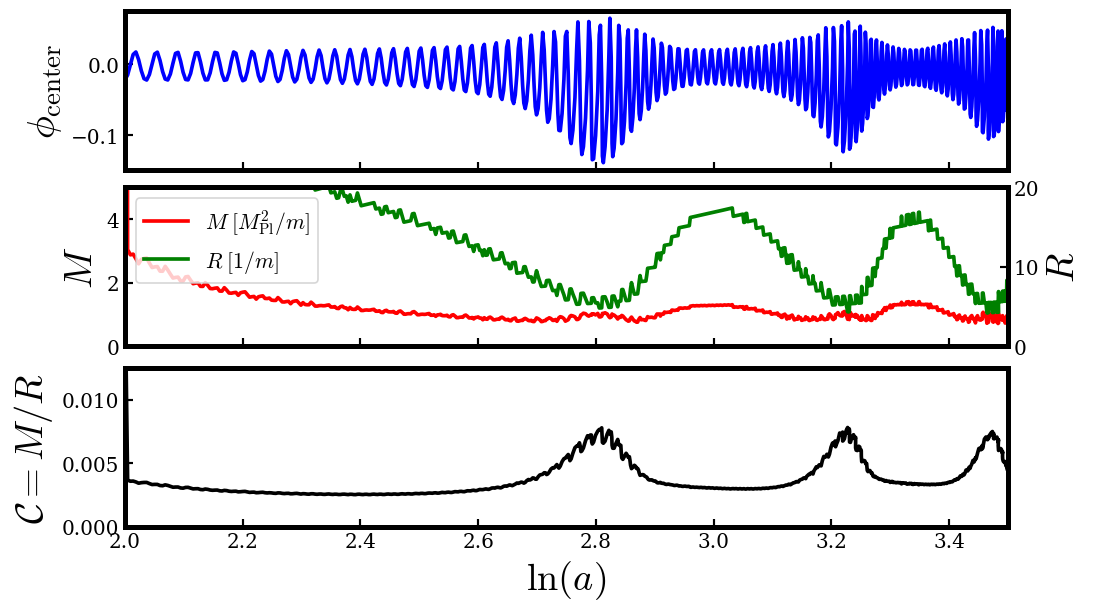

In [229]:
# Panel 2b — same data as Panel 2 (PLOT2_KEY), arranged as 3 stacked panels:
#   top:    log10(delta_c)   vs ln(a)
#   middle: M and R (twinx) vs ln(a)
#   bottom: compactness C    vs ln(a)
# All share x-range [0, 3.5]; vertical grey dotted line at ln(a)=2 marks
# the alignment / "oscillon formed" threshold.
x       = osc_shifted["ln_a"]
delta_c = osc_shifted["delta_c"]
M_arr   = osc_shifted["M"]
R_arr   = osc_shifted["R"]
C_arr   = osc_shifted["C"]

LNA_MIN, LNA_MAX = 2.0, 3.5
LNA_FORM         = 2.0

fig3, (ax_d, ax_mr, ax_c) = plt.subplots(
    3, 1, figsize=(9, 5), sharex=True, constrained_layout=True
)

phi_c_2b = np.asarray(run["phi_c"])
shifted_ln_a_2b = np.asarray(run["shifted_ln_a"])
ax_d.plot(shifted_ln_a_2b, phi_c_2b, "b-", lw=2.2)
ax_d.set_ylabel(r"$\phi_{\rm center}$")


ax_mr.plot(x, M_arr, "r-", lw=2.2, label=r"$M \; [M_{\rm Pl}^2/m]$")
ax_mr_r = ax_mr.twinx()
ax_mr_r.plot(x, R_arr, "g-", lw=2.2, label=r"$R \; [1/m]$")
ax_mr.set_ylabel(r"$M$", color="black")
ax_mr_r.set_ylabel(r"$R$", color="black")
ax_mr.set_ylim(0, 5)
ax_mr_r.set_ylim(0, 20)
#ax_mr.set_title("Oscillon mass and radius")
lines1, labels1 = ax_mr.get_legend_handles_labels()
lines2, labels2 = ax_mr_r.get_legend_handles_labels()
ax_mr.legend(lines1 + lines2, labels1 + labels2,
             fontsize=13, loc="upper left")

ax_c.plot(x, C_arr, "k-", lw=2.2)
ax_c.set_xlabel(r"$\ln(a)$")
ax_c.set_ylabel(r"$\mathcal{C} = M/R$")
#ax_c.set_title(r"Compactness  $\mathcal{C}$")
ax_c.set_ylim(0, 1.25e-2)

for ax in (ax_d, ax_mr, ax_c):
    ax.axvline(LNA_FORM, color="grey", ls=":", lw=1.4, alpha=0.8)
    ax.set_xlim(LNA_MIN, LNA_MAX)

for ax in (ax_mr, ax_c):
    ax.axvspan(LNA_MIN, LNA_FORM, color="lightgrey", alpha=0.45, zorder=0)
    #ax.text(0.5 * (LNA_MIN + LNA_FORM),ax.get_ylim()[0] + 0.92 * (ax.get_ylim()[1] - ax.get_ylim()[0]),"oscillon not formed yet",ha="center", va="top",color="dimgrey", fontsize=13, style="italic")

save_fig(fig3, PLOT2_NAME + "_3stack")
plt.show()

  saved MassRadiusCompactnessGR_2stack.pdf and MassRadiusCompactnessGR_2stack.png


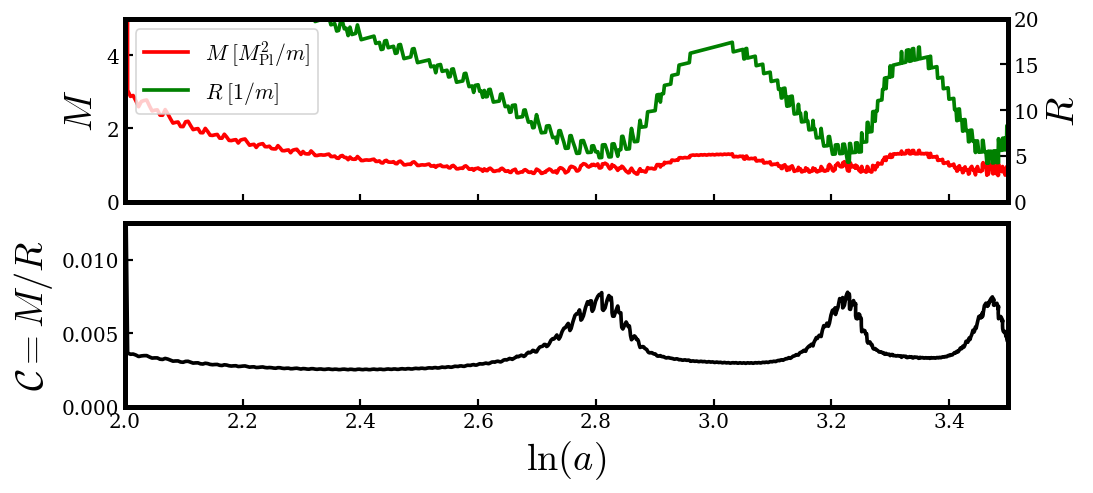

In [230]:
# Panel 2c — same as Panel 2b but with the top log10(delta_c) panel removed.
#   top:    M and R (twinx) vs ln(a)
#   bottom: compactness C    vs ln(a)
x       = osc_shifted["ln_a"]
M_arr   = osc_shifted["M"]
R_arr   = osc_shifted["R"]
C_arr   = osc_shifted["C"]

LNA_MIN, LNA_MAX = 2.0, 3.5
LNA_FORM         = 2.0

fig4, (ax_mr, ax_c) = plt.subplots(
    2, 1, figsize=(9, 4), sharex=True, constrained_layout=True
)

ax_mr.plot(x, M_arr, "r-", lw=2.2, label=r"$M \; [M_{\rm Pl}^2/m]$")
ax_mr_r = ax_mr.twinx()
ax_mr_r.plot(x, R_arr, "g-", lw=2.2, label=r"$R \; [1/m]$")
ax_mr.set_ylabel(r"$M$", color="black")
ax_mr_r.set_ylabel(r"$R$", color="black")
ax_mr.set_ylim(0, 5)
ax_mr_r.set_ylim(0, 20)
lines1, labels1 = ax_mr.get_legend_handles_labels()
lines2, labels2 = ax_mr_r.get_legend_handles_labels()
ax_mr.legend(lines1 + lines2, labels1 + labels2,
             fontsize=13, loc="upper left")

ax_c.plot(x, C_arr, "k-", lw=2.2)
ax_c.set_xlabel(r"$\ln(a)$")
ax_c.set_ylabel(r"$\mathcal{C} = M/R$")
ax_c.set_ylim(0, 1.25e-2)

for ax in (ax_mr, ax_c):
    ax.axvline(LNA_FORM, color="grey", ls=":", lw=1.4, alpha=0.8)
    ax.set_xlim(LNA_MIN, LNA_MAX)
    ax.axvspan(LNA_MIN, LNA_FORM, color="lightgrey", alpha=0.45, zorder=0)

save_fig(fig4, PLOT2_NAME + "_2stack")
plt.show()

## Panel 3 — Central vs background density (decoupling from the Hubble flow)

For each selected run, $\log_{10}\rho_c$ (solid) and $\log_{10}\bar\rho$ (dashed) vs aligned $\ln(a)$.
Where $\rho_c$ stops tracking $\bar\rho$ the configuration has decoupled from the Hubble flow.

In [231]:
### --- Panel 3 selection (edit me) ---
PLOT3_KEYS = select_runs(
    lgb   = [0],
    mu    = [0.08],
    beta  = [0],
    amp   = [-0.02],
    width = [3.0],
    g2 = [0]
)
PLOT3_NAME = "rho_c_vs_rho_bar"

print(f"{len(PLOT3_KEYS)} run(s) selected for Panel 3:")
for k in PLOT3_KEYS:
    print(" ", k, " coupling=", all_runs[k]["coupling"])

1 run(s) selected for Panel 3:
  (0.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0


  saved rho_c_vs_rho_bar.pdf and rho_c_vs_rho_bar.png


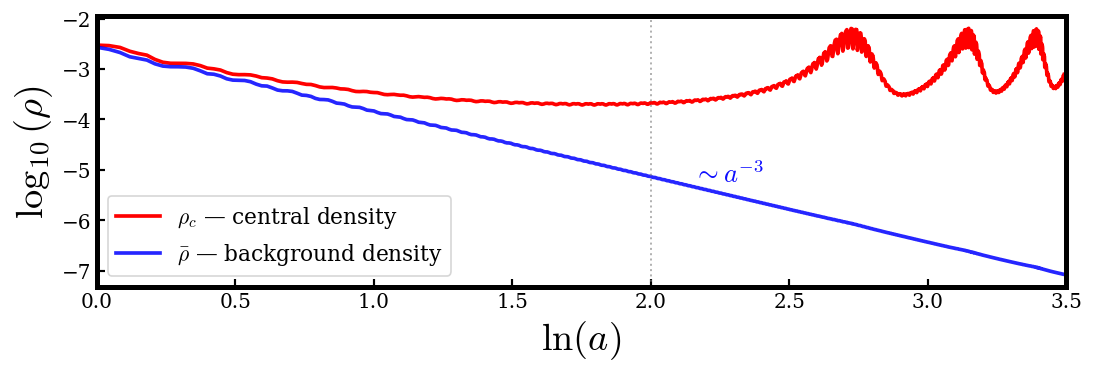

In [232]:
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
cmap = plt.cm.tab10
single_run = (len(PLOT3_KEYS) == 1)

for i, key in enumerate(PLOT3_KEYS):
    data = all_runs[key]
    osc  = data["osc"]
    lgb, mu, beta, amp, width, g2 = key

    if "rho_bar" not in osc:
        print(f"  skipping {key}: rho_bar not in diagnostics")
        continue

    #ln_a = data["shifted_ln_a"]
    ln_a = np.asarray(data["osc"]["ln_a"]) #WE USED THE RAW LN(A) FOR GR SINCE THE SHIFTING IS ONLY NEEDED IN MG

    rc   = np.asarray(osc["rho_c"])
    rb   = np.asarray(osc["rho_bar"])

    pos_c = rc >= 0
    pos_b = rb >= 0

    if single_run:
        color_c, color_b = "r", "b"
        lbl_c = r"$\rho_c$ — central density"
        lbl_b = r"$\bar{\rho}$ — background density"
    else:
        color_c = cmap(i % 10)
        color_b = color_c
        beta_s  = "" if (beta is None or beta == 0) else rf",\ \beta={int(beta)}"
        if lgb == 0.0:
            run_lbl = rf"GR, $\mu={mu}$"
        else:
            run_lbl = rf"$\lambda_{{\rm GB}}={lgb:g},\ \mu={mu}{beta_s}$"
        lbl_c = rf"$\rho_c$ (central density) ({run_lbl})"
        lbl_b = rf"$\bar\rho$ (background density) ({run_lbl})"

    ax.plot(ln_a[pos_c], np.log10(rc[pos_c]),color=color_c, lw=2.2, label=lbl_c)
    ax.plot(ln_a[pos_b], np.log10(rb[pos_b]),color=color_b, lw=2.2, ls="-", alpha=0.85, label=lbl_b)

ln_a_ref = np.linspace(1.5, 2.5, 100)
anchor_x = ln_a_ref[0] +2.4
log_rho_anchor = np.interp(anchor_x, ln_a[pos_b], np.log10(rb[pos_b]))
log_rho_ref = log_rho_anchor - 3.0 * (ln_a_ref - anchor_x) / np.log(10)
#ax.plot(ln_a_ref, log_rho_ref,color="black", ls="--", lw=1.5, alpha=0.9)

txt_x = ln_a_ref[len(ln_a_ref) // 2]+0.1
txt_y = -5.5#log_rho_anchor - 3.0 * (txt_x - anchor_x) / np.log(10)
ax.annotate(r"$\sim a^{-3}$",
            xy=(txt_x, txt_y),
            xytext=(8, 8), textcoords="offset points",
            color="blue", fontsize=16, alpha=0.95)

ax.axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)

ax.set_xlabel(r"$\ln(a)$")
ax.set_ylabel(r"$\log_{10}(\rho)$")
ax.set_xlim(0,3.5)
#ax.set_title(r"Central density $\rho_c$ vs background $\bar{\rho}$")
ax.legend(fontsize=13, loc="best", frameon=True)
save_fig(fig, PLOT3_NAME)
plt.show()

---
## Further panels

Future panels follow the same two-cell pattern:

- **Selection cell** — set parameter lists and a `*_NAME` string used for the PDF filename.
- **Plot cell** — build the figure, then `save_fig(fig, NAME); plt.show()` so it is shown
  inline and saved to `GoodFigures/NAME.pdf` (with a `.png` mirror).

## Panel 5 — Density contrast $\delta_c$: with vs without backreaction

Compares $\log_{10}(\delta_c)$ vs $\ln(a)$ for the **same** physical setup
( $\mu = 0.08$, $\lambda_{\rm GB} = 0$, $g_2 = 0$, $a_{\rm mg}=b_{\rm mg}=0$,
$A=-0.02$, $R=3$, $\mathrm{d}r=1/24$, $T=800$ ) with two different gravity settings:

- **With backreaction**: `eight_pi_G = 1` in `bssn/tensoralgebra.py` (the existing run).
- **Without backreaction**: `eight_pi_G = 0` (the run currently submitted to wICE).
  This effectively evolves the scalar on a fixed FLRW background, mirroring what a
  linear / fixed-background code computes.

The black dashed line shows the matter-domination linear growth $\delta_c \propto a$
(slope $\log_{10}(e) \approx 0.4343$ in this plane), anchored to the no-BR curve's
first positive value.

Both runs are loaded directly from disk (not from `all_runs`), because the
notebook's loader keys on `(\lambda_{GB}, \mu, \beta, A, R, g_2)` and both runs collide
to the same key — only their `coupling` string differs (`"quadratic"` vs
`"quadratic_0_noBR"`).

with backreaction:
  dir          : /lustre/hpc/astro/syildiz/VSC_home/0scillons/oscillon_runs_data/lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g20
  solution.npy : True
  diagnostics  : True
no backreaction:
  dir          : /lustre/hpc/astro/syildiz/VSC_home/0scillons/oscillon_runs_data/lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_noBR_g20
  solution.npy : True
  diagnostics  : True
  saved delta_c_with_vs_no_backreaction_mu0.08_amp-0.02.pdf and delta_c_with_vs_no_backreaction_mu0.08_amp-0.02.png


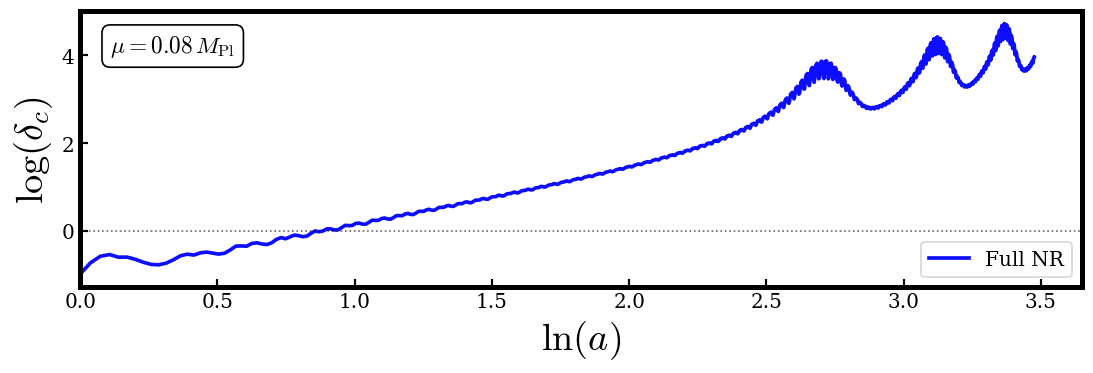

In [11]:
# ── Panel 5 selection (edit me if you change run parameters) ──────────────
# Pick ONE pair below by commenting/uncommenting.  Both pairs share the same
# physical parameters (mu=0.08, lgb=0, g2=0, a=b=0, R=3, dr=1/24, T=800);
# they only differ in the initial perturbation amplitude A.

# --- A = -0.02 ---
NOBR_TAG    = "lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_noBR_g20"
WITHBR_TAG  = "lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g20"
P5_NAME     = "delta_c_with_vs_no_backreaction_mu0.08_amp-0.02"

# --- A = -0.0002 ---
#NOBR_TAG    = "lgb0_mu0.08_a0_b0_amp-0.0002_R3_dr0.0416667_quadratic_0_noBR_g20"
#WITHBR_TAG  = "lgb0_mu0.08_a0_b0_amp-0.0002_R3_dr0.0416667_quadratic_g20"
#P5_NAME     = "delta_c_with_vs_no_backreaction_mu0.08_amp-0.0002"

# Physical parameters (must match the runs above)
P5_LGB, P5_MU, P5_G2 = 0.0, 0.08, 0.0
P5_COUPLING_NOBR    = "quadratic_0_noBR"
P5_COUPLING_WITHBR  = "quadratic"


def _p5_load_or_compute_diag(run_dir, mu, coupling, lgb, g2):
    """Load diagnostics.npz from `run_dir`; compute if missing but solution.npy exists.
    Returns None if the simulation hasn't produced solution.npy yet.
    """
    diag_path = os.path.join(run_dir, "diagnostics.npz")
    if os.path.exists(diag_path):
        return dict(np.load(diag_path, allow_pickle=True))

    sol_path = os.path.join(run_dir, "solution.npy")
    t_path   = os.path.join(run_dir, "t.npy")
    if not (os.path.exists(sol_path) and os.path.exists(t_path)):
        return None

    meta_path = os.path.join(run_dir, "metadata.npz")
    if os.path.exists(meta_path):
        meta = dict(np.load(meta_path, allow_pickle=True))
        run_r_max  = float(meta.get("r_max",  r_max))
        run_min_dr = float(meta.get("min_dr", 1/24))
        run_max_dr = float(meta.get("max_dr", max_dr))
    else:
        run_r_max, run_min_dr, run_max_dr = r_max, 1/24, max_dr

    sol_i   = np.load(sol_path)
    t_i     = np.load(t_path)
    matter_i  = ScalarMatter(scalar_mu, mu)
    sv_i      = StateVector(matter_i)
    spacing_i = CubicSpacing(**CubicSpacing.get_parameters(run_r_max, run_min_dr, run_max_dr))
    grid_i    = Grid(spacing_i, sv_i)
    bg_i      = FlatSphericalBackground(grid_i.r)
    params_i  = (lgb, a_mg, b_mg, chi0, coupling, g2)
    osc_d = get_oscillon_diagnostic(
        sol_i, t_i, grid_i, bg_i,
        ScalarMatter(scalar_mu, mu),
        params_i, surface_threshold=0.05, r_max_diag=100.0,
    )
    np.savez(diag_path, **osc_d)
    return osc_d


nobr_dir   = os.path.join(DATA_DIR, NOBR_TAG)
withbr_dir = os.path.join(DATA_DIR, WITHBR_TAG)

print("with backreaction:")
print(f"  dir          : {withbr_dir}")
print(f"  solution.npy : {os.path.exists(os.path.join(withbr_dir, 'solution.npy'))}")
print(f"  diagnostics  : {os.path.exists(os.path.join(withbr_dir, 'diagnostics.npz'))}")
print("no backreaction:")
print(f"  dir          : {nobr_dir}")
print(f"  solution.npy : {os.path.exists(os.path.join(nobr_dir,  'solution.npy'))}")
print(f"  diagnostics  : {os.path.exists(os.path.join(nobr_dir,  'diagnostics.npz'))}")

osc_with = _p5_load_or_compute_diag(withbr_dir, mu=P5_MU, coupling=P5_COUPLING_WITHBR,
                                     lgb=P5_LGB, g2=P5_G2)
osc_no   = _p5_load_or_compute_diag(nobr_dir,   mu=P5_MU, coupling=P5_COUPLING_NOBR,
                                     lgb=P5_LGB, g2=P5_G2)

if osc_with is None:
    print("\n[warn] with-backreaction run has no solution.npy yet — plot will be empty for that curve.")
if osc_no is None:
    print("\n[info] no-backreaction run has not produced solution.npy yet "
          "(simulation still in progress). Only the with-backreaction curve will be drawn.")

# ── Plot ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)

def _plot_logdelta(ax, osc, color, ls, lw, label, x_override=None):
    if osc is None:
        return
    ln_a = x_override if x_override is not None else np.asarray(osc["ln_a"])
    dc   = np.asarray(osc["delta_c"])
    pos = (dc > 0) & np.isfinite(dc)
    if not np.any(pos):
        return
    y = np.full_like(dc, np.nan, dtype=float)
    y[pos] = np.log10(dc[pos])
    ax.plot(ln_a, y, color=color, ls=ls, lw=lw, label=label, alpha=0.95)

# ── X-axis mode ───────────────────────────────────────────────────────────
# Toggle: "t" = coordinate time,  "ln_a" = with-BR ln(a) for both curves
#P5_XAXIS = "t"
P5_XAXIS = "ln_a"

if P5_XAXIS == "t":
    x_with = np.asarray(osc_with["t"]) if osc_with is not None else None
    x_no   = np.asarray(osc_no["t"])   if osc_no   is not None else None
    p5_xlabel = r"$t \; [1/m]$"
else:
    x_with = np.asarray(osc_with["ln_a"]) if osc_with is not None else None
    x_no   = x_with
    p5_xlabel = r"$\ln(a)$"

_plot_logdelta(ax, osc_with, color="blue", ls="-",  lw=2.2, label="Full NR",x_override=x_with)
#_plot_logdelta(ax, osc_no,   color="red",  ls="-", lw=2.2, label="no backreaction",x_override=x_no)

ax.axhline(0.0, color="k", ls=":", lw=1.0, alpha=0.6)

ax.set_xlabel(p5_xlabel)
ax.set_ylabel(r"$\log(\delta_c)$")
ax.set_xlim(left=0.0)
ax.legend(loc="lower right", frameon=True, fontsize=12)

ax.text(0.03, 0.92, rf"$\mu = {P5_MU:g}\,M_{{\rm Pl}}$",
        transform=ax.transAxes, fontsize=14, ha="left", va="top",
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="black", lw=1.0))

save_fig(fig, P5_NAME)
plt.show()

## Panel 3+5 — Stacked $\rho_c, \bar\rho$ and $\delta_c$ vs $\ln(a)$

Combined view of Panel 3 (central vs background density) on top and Panel 5
(density contrast with backreaction) on the bottom, sharing the same
$\ln(a)$ axis.

Requires Panel 3 and Panel 5 cells above to have been executed so that
`PLOT3_KEYS`, `all_runs`, `osc_with`, `P5_MU`, and `ALIGN_LNA` are in scope.

  saved rho_and_delta_c_stacked.pdf and rho_and_delta_c_stacked.png


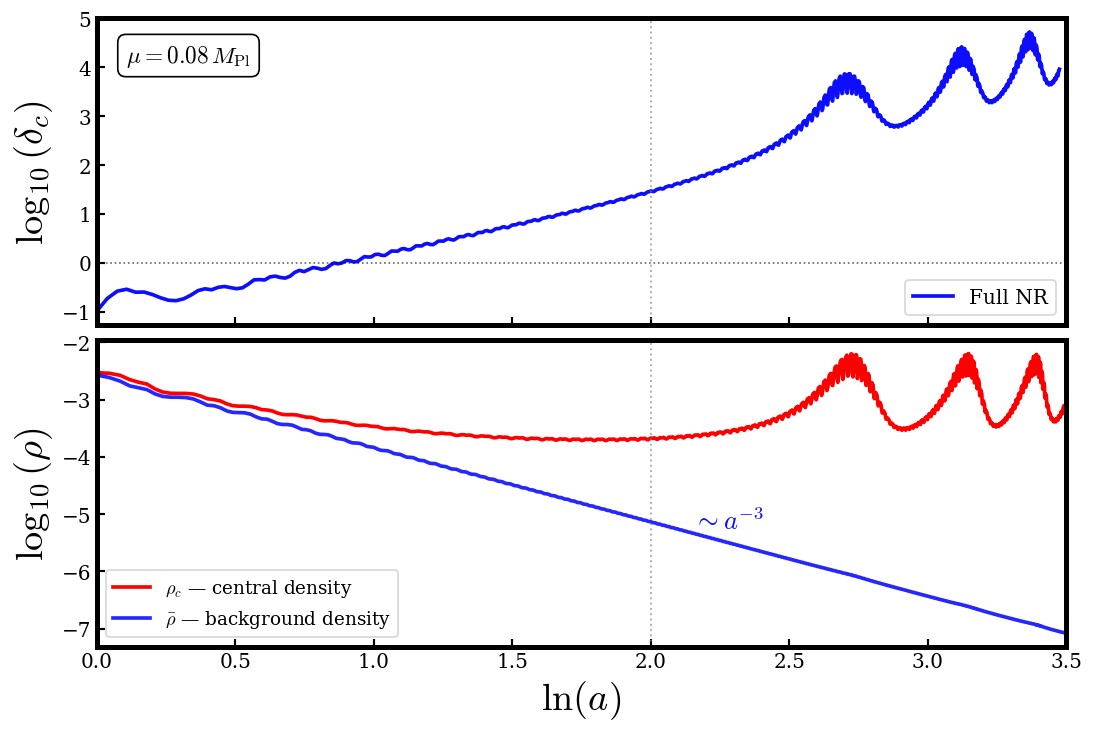

In [234]:
P35_NAME = "rho_and_delta_c_stacked"

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(9, 6), sharex=True, constrained_layout=True
)

if osc_with is not None:
    ln_a_w = np.asarray(osc_with["ln_a"])
    dc     = np.asarray(osc_with["delta_c"])
    pos    = (dc > 0) & np.isfinite(dc)
    y      = np.full_like(dc, np.nan, dtype=float)
    y[pos] = np.log10(dc[pos])
    ax_top.plot(ln_a_w, y, color="blue", lw=2.2, label="Full NR", alpha=0.95)
else:
    print("[warn] osc_with is None — top panel will be empty. Run Panel 5 first.")

ax_top.axhline(0.0, color="k",    ls=":", lw=1.0, alpha=0.6)
ax_top.axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
ax_top.set_ylabel(r"$\log_{10}(\delta_c)$")
ax_top.legend(loc="lower right", frameon=True, fontsize=12)

ax_top.text(0.03, 0.92, rf"$\mu = {P5_MU:g}\,M_{{\rm Pl}}$",
            transform=ax_top.transAxes, fontsize=14, ha="left", va="top",
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="black", lw=1.0))

cmap = plt.cm.tab10
single_run = (len(PLOT3_KEYS) == 1)
last_ln_a_b = None
last_log_rb_b = None

for i, key in enumerate(PLOT3_KEYS):
    data = all_runs[key]
    osc  = data["osc"]
    lgb, mu, beta, amp, width, g2 = key

    if "rho_bar" not in osc:
        print(f"  skipping {key}: rho_bar not in diagnostics")
        continue

    ln_a = np.asarray(osc["ln_a"])
    rc   = np.asarray(osc["rho_c"])
    rb   = np.asarray(osc["rho_bar"])

    pos_c = rc >= 0
    pos_b = rb >= 0

    if single_run:
        color_c, color_b = "r", "b"
        lbl_c = r"$\rho_c$ — central density"
        lbl_b = r"$\bar{\rho}$ — background density"
    else:
        color_c = cmap(i % 10)
        color_b = color_c
        beta_s  = "" if (beta is None or beta == 0) else rf",\ \beta={int(beta)}"
        if lgb == 0.0:
            run_lbl = rf"GR, $\mu={mu}$"
        else:
            run_lbl = rf"$\lambda_{{\rm GB}}={lgb:g},\ \mu={mu}{beta_s}$"
        lbl_c = rf"$\rho_c$ ({run_lbl})"
        lbl_b = rf"$\bar\rho$ ({run_lbl})"

    ax_bot.plot(ln_a[pos_c], np.log10(rc[pos_c]), color=color_c, lw=2.2, label=lbl_c)
    ax_bot.plot(ln_a[pos_b], np.log10(rb[pos_b]), color=color_b, lw=2.2,
                ls="-", alpha=0.85, label=lbl_b)

    last_ln_a_b   = ln_a[pos_b]
    last_log_rb_b = np.log10(rb[pos_b])

ax_bot.axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
ax_bot.set_xlabel(r"$\ln(a)$")
ax_bot.set_ylabel(r"$\log_{10}(\rho)$")
ax_bot.legend(fontsize=11, loc="best", frameon=True)

if last_ln_a_b is not None and last_ln_a_b.size:
    ln_a_ref = np.linspace(1.5, 2.5, 100)
    anchor_x = ln_a_ref[0] + 2.4
    txt_x = ln_a_ref[len(ln_a_ref) // 2] + 0.1
    txt_y = -5.5
    ax_bot.annotate(r"$\sim a^{-3}$",
                    xy=(txt_x, txt_y),
                    xytext=(8, 8), textcoords="offset points",
                    color="blue", fontsize=16, alpha=0.95)

ax_bot.set_xlim(0.0, 3.5)

save_fig(fig, P35_NAME)
plt.show()

## Panel 6 — Density-contrast profile $\delta(r)$

Snapshot plot of the spatial density-contrast profile

$$\delta(r,\, t) \;=\; \frac{\rho(r,\, t)}{\bar\rho(t)} \;-\; 1$$

against the radial coordinate $r$, evaluated at a set of aligned $\ln(a)$
snapshots.  This is the radial generalisation of the central density
contrast $\delta_c = \rho_c / \bar\rho - 1$ used in the earlier panels;
note that $\delta(r=0,\, t) \equiv \delta_c(t)$, so each curve passes
through $\delta_c$ on the y-axis at $r=0$.

Two display modes are available:

* `PLOT6_USE_OSC_RADIUS = False` — x-axis is the **physical radial coordinate**
  $r\,[1/m]$, capped at `PLOT6_R_MAX`.
* `PLOT6_USE_OSC_RADIUS = True`  — x-axis is **rescaled by the time-dependent
  oscillon radius** $R_{\rm osc}(t)$, i.e. $r/R_{\rm osc}(t)$, capped at
  `PLOT6_X_NORM_MAX`.  In this mode the oscillon "edge" sits at
  $r/R_{\rm osc}=1$ (marked with a thin grey dotted vertical line) and
  self-similar profiles collapse onto each other.

Edit `PLOT6_KEY`, `PLOT6_SNAPS`, `PLOT6_USE_OSC_RADIUS`, `PLOT6_R_MAX`,
`PLOT6_X_NORM_MAX` and `PLOT6_NAME` below.


In [16]:
PLOT6_KEY    = (0, 0.08, 0, -0.02, 3.0, 0)
#PLOT6_SNAPS  = [2.0, 2.25, 2.5, 3]
PLOT6_SNAPS  = [2.0,2.1,2.15,2.2, 2.25,2.3,2.35,2.4,2.45, 2.5,2.55,2.6,2.65]

PLOT6_USE_OSC_RADIUS = False
PLOT6_USE_AREAL_R    = True
PLOT6_R_MAX          = 30
PLOT6_X_NORM_MAX     = 5.0

PLOT6_NAME   = "delta_profile_lgb0_mu0.08_amp-0.02"

if PLOT6_KEY not in all_runs:
    print(f"Key {PLOT6_KEY} not found in all_runs.")
    print("Available keys:")
    for k in sorted(all_runs.keys()):
        print(f"  {k}  coupling={all_runs[k]['coupling']}")
else:
    print(f"Selected: {PLOT6_KEY}")
    print(f"  tag      = {all_runs[PLOT6_KEY]['tag']}")
    print(f"  coupling = {all_runs[PLOT6_KEY]['coupling']}")
    print(f"  shift    = {all_runs[PLOT6_KEY]['shift']:+.3f}")


Selected: (0, 0.08, 0, -0.02, 3.0, 0)
  tag      = lgb0.0_mu0.08_a0.0_b0.0_amp-0.02_R3.0_dr0.041666666666666664_quadratic_0
  coupling = quadratic_0
  shift    = +0.082


  saved delta_profile_lgb0_mu0.08_amp-0.02_vs_RA.pdf and delta_profile_lgb0_mu0.08_amp-0.02_vs_RA.png


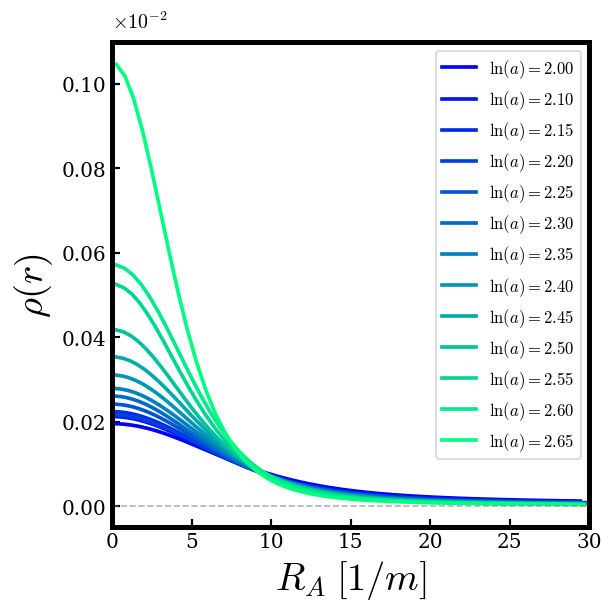

In [17]:
from bssn.bssnstatevariables import idx_phi, idx_htt, NUM_BSSN_VARS

run    = all_runs[PLOT6_KEY]
osc    = run["osc"]
r_grid = np.asarray(osc["r"])
s_ln_a = np.asarray(run["shifted_ln_a"])

if "delta_rho" in osc:
    delta_rho = np.asarray(osc["rho"])
else:
    rho     = np.asarray(osc["rho"])
    rho_bar = np.asarray(osc["rho_bar"])
    delta_rho = rho / np.maximum(rho_bar[:, None], 1e-30) - 1.0

R_osc_t = np.asarray(osc["R"])

_sol6 = None
if PLOT6_USE_AREAL_R:
    _sol_path = os.path.join(run["run_dir"], "solution.npy")
    _sol6 = np.load(_sol_path)
    _N_grid6 = len(r_grid)

snap_indices = [int(np.argmin(np.abs(s_ln_a - v))) for v in PLOT6_SNAPS]

fig, ax = plt.subplots(figsize=(5,5), constrained_layout=True)
cmap = plt.cm.winter
n    = len(snap_indices)

for j, idx in enumerate(snap_indices):
    color   = cmap(j / max(n - 1, 1))
    lna_val = s_ln_a[idx]
    delta_r = delta_rho[idx]

    if PLOT6_USE_AREAL_R:
        _state_i = _sol6[idx].reshape(-1, _N_grid6)
        _phi_i = _state_i[idx_phi]
        _htt_i = _state_i[idx_htt]
        x = np.exp(2.0 * _phi_i) * r_grid * np.sqrt(np.maximum(1.0 + _htt_i, 1e-30))
        x_mask = (r_grid >= 0) & (x <= PLOT6_R_MAX)
        lbl = rf"$\ln(a) = {lna_val:.2f}$"
    elif PLOT6_USE_OSC_RADIUS:
        R_osc = R_osc_t[idx]
        if R_osc <= 0:
            print(f"Skipping ln(a)={lna_val:.2f}: R_osc = {R_osc:.3g} (no oscillon yet)")
            continue
        x      = r_grid / R_osc
        x_mask = (r_grid >= 0) & (x <= PLOT6_X_NORM_MAX)
        lbl    = rf"$\ln(a) = {lna_val:.2f},\ R_{{\rm osc}} = {R_osc:.2f}$"
    else:
        x      = r_grid
        x_mask = (r_grid >= 0) & (r_grid <= PLOT6_R_MAX)
        lbl    = rf"$\ln(a) = {lna_val:.2f}$"

    ax.plot(x[x_mask], delta_r[x_mask], color=color, lw=2.2, label=lbl)

del _sol6

ax.axhline(0.0, color="grey", ls="--", lw=1.0, alpha=0.6)

if PLOT6_USE_AREAL_R:
    ax.set_xlabel(r"$R_A \; [1/m]$")
    ax.set_xlim(0, PLOT6_R_MAX)
    save_suffix = "_vs_RA"
elif PLOT6_USE_OSC_RADIUS:
    ax.axvline(1.0, color="grey", ls=":", lw=1.2, alpha=0.7)
    ax.set_xlabel(r"$r / R_{\rm osc}(t)$")
    ax.set_xlim(0, PLOT6_X_NORM_MAX)
    save_suffix = "_vs_rOverR"
else:
    ax.set_xlabel(r"$r \; [1/m]$")
    ax.set_xlim(0, PLOT6_R_MAX)
    save_suffix = ""

ax.set_ylabel(r"$\rho(r)$")

from matplotlib.ticker import FuncFormatter
_Y_SCALE = 1e-2
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _pos: f"{v / _Y_SCALE:.2f}"))
ax.annotate(r"$\times 10^{-2}$", xy=(0, 1), xycoords="axes fraction",
            xytext=(0, 6), textcoords="offset points",
            ha="left", va="bottom", fontsize=12)

ax.legend(fontsize=10, loc="best", frameon=True)
save_fig(fig, PLOT6_NAME + save_suffix)
plt.show()


## Panel 6b — GR vs $g_2$ density contributions

Fractional energy-density contributions $\rho_i/\rho_{\rm tot}$ versus areal radius $R_A$ at one aligned $\ln(a)$ snapshot, for $\lambda_{\rm GB}=0$ and $g_2=10$.  Here $\rho_{\rm tot}=\rho_{\rm GR}+\rho_{g_2}$.  The grey dashed line marks the oscillon surface $\rho_{\rm tot}/\rho_c=5\%$, with $\rho_c=\max\rho_{\rm tot}$.


Selected: (3, 0.08, 0, -0.02, 3.0, 10)
  tag      = lgb3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g210
  coupling = quadratic_0
  lgb      = 3.0
  g2       = 10.0
  ln(a)    = 3.2337  (requested 3.2337)
-0.001932847615970283
-0.0006214159232168534
Average rho 0.0002308540862396293
rho_GB/average_rho -0.06311507123561433
rho_g2/average_rho -0.17631552070232223
  saved rho_frac_lgb0_g210_lna2.60_vs_RA.pdf and rho_frac_lgb0_g210_lna2.60_vs_RA.png


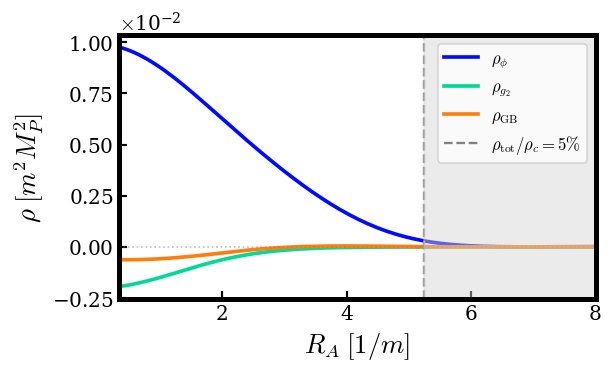

In [18]:
from bssn.bssnstatevariables import idx_phi, idx_htt
from bssn.bssnvars import BSSNVars
from bssn.ModifiedGravity import GBVars, get_gb_core, get_esgb_br_terms

PLOT6B_KEY   = (3, 0.08, 0, -0.02, 3.0, 10)   # lambda_GB=0, g2=10
PLOT6B_LNA   = 3.2337 #(for GB + g2)
#PLOT6B_LNA   = 3.385 #(For pure GB)
#PLOT6B_LNA   = 3.45 #(For pure g2)
factor = 1
PLOT6B_R_MAX = PLOT6_R_MAX
PLOT6B_NAME  = "rho_frac_lgb0_g210_lna2.60_vs_RA"

if PLOT6B_KEY not in all_runs:
    print(f"Key {PLOT6B_KEY} not found in all_runs.")
    print("Available g2=10, lgb=0 keys:")
    for k in sorted(all_runs.keys()):
        if abs(k[0]) < 1e-12 and abs(k[5] - 10) < 1e-12:
            print(f"  {k}  coupling={all_runs[k]['coupling']}")
else:
    run    = all_runs[PLOT6B_KEY]
    osc    = run["osc"]
    r_grid = np.asarray(osc["r"])
    s_ln_a = np.asarray(run["shifted_ln_a"])
    idx    = int(np.argmin(np.abs(s_ln_a - PLOT6B_LNA)))
    lna_val = float(s_ln_a[idx])
    print(f"Selected: {PLOT6B_KEY}")
    print(f"  tag      = {run['tag']}")
    print(f"  coupling = {run['coupling']}")
    print(f"  lgb      = {run['lgb']}")
    print(f"  g2       = {run['g2']}")
    print(f"  ln(a)    = {lna_val:.4f}  (requested {PLOT6B_LNA})")

    matter  = ScalarMatter(scalar_mu, run["mu"])
    sv      = StateVector(matter)
    spacing = CubicSpacing(**CubicSpacing.get_parameters(
        run["run_r_max"], run["run_min_dr"], run["run_max_dr"]))
    grid    = Grid(spacing, sv)
    bg      = FlatSphericalBackground(grid.r)
    r_grid  = grid.r

    _sol = np.load(os.path.join(run["run_dir"], "solution.npy"))
    state = _sol[idx].reshape(grid.NUM_VARS, -1)
    del _sol

    bssn = BSSNVars(grid.N)
    bssn.set_bssn_vars(state)
    matter.set_matter_vars(state, bssn, grid)

    d1 = grid.get_d1_metric_quantities(state)
    d2 = grid.get_d2_metric_quantities(state)
    gb = GBVars(grid.N)
    get_gb_core(gb, r_grid, bssn, d1, d2, grid, bg, run["lgb"], chi0)
    get_esgb_br_terms(gb, r_grid, matter, bssn, d1, d2, grid, bg,
                      run["lgb"], chi0, run["coupling"], run["g2"])

    rho_GR = matter.get_emtensor(r_grid, bssn, bg, gb).rho.copy()
    rho_g2 = gb.rho_g2.copy()
    rho_GB = gb.rho_GB.copy()
    print(np.min(rho_g2))
    print(np.min(rho_GB))

    grid.fill_inner_boundary_single_variable(rho_GR)
    grid.fill_inner_boundary_single_variable(rho_g2)
    grid.fill_inner_boundary_single_variable(rho_GB)

    rho_tot = rho_GR + rho_g2 + rho_GB
    rho_c   = float(np.max(np.where(r_grid >= 0, rho_tot, -np.inf)))
    frac_GR = rho_GR
    frac_g2 = rho_g2
    frac_GB = rho_GB 
    frac_sum = frac_GR + frac_g2 + frac_GB
    average_rho = np.mean(rho_tot)
    print('Average rho',average_rho)
    print('rho_GB/average_rho',np.mean(rho_GB)/average_rho)
    #print('rho_GB/average_rho',rho_GB[8]/average_rho)
    print('rho_g2/average_rho',np.mean(rho_g2)/average_rho)

    R_A = (np.exp(2.0 * state[idx_phi]) * r_grid
           * np.sqrt(np.maximum(1.0 + state[idx_htt], 1e-30)))

    i_c = int(np.argmax(np.where(r_grid >= 0, rho_tot, -np.inf)))
    r_out = np.where(r_grid >= r_grid[i_c])[0]
    below = rho_tot[r_out] <= 0.05 * rho_c
    R_cut = float(R_A[r_out[int(np.argmax(below))]]) if np.any(below) else np.nan

    x_mask = (r_grid >= 0) & (R_A <= PLOT6B_R_MAX)
    cmap = plt.cm.winter

    from scipy.interpolate import interp1d
    _order = np.argsort(R_A[x_mask])
    x = np.asarray(R_A[x_mask][_order], dtype=float)
    y_phi = np.asarray(frac_GR[x_mask][_order], dtype=float)
    y_g2  = np.asarray(frac_g2[x_mask][_order], dtype=float)
    y_GB  = np.asarray(frac_GB[x_mask][_order], dtype=float)
    _uniq = np.concatenate(([True], np.diff(x) > 1e-14))
    x, y_phi, y_g2, y_GB = x[_uniq], y_phi[_uniq], y_g2[_uniq], y_GB[_uniq]
    # Here is the number of refinement on the plot
    x_fine = np.linspace(x.min(), x.max(), 400)
    s_phi = interp1d(x, y_phi, kind="cubic")
    s_g2  = interp1d(x, y_g2,  kind="cubic")
    s_GB  = interp1d(x, y_GB,  kind="cubic")

    fig, ax = plt.subplots(figsize=(5, 3), constrained_layout=True)
    ax.plot(x_fine, s_phi(x_fine), color=cmap(0.05), lw=2.2,label=r"$\rho_{\phi}$")
    ax.plot(x_fine, s_g2(x_fine), color=cmap(0.85), lw=2.2,label=r"$\rho_{g_2}$")
    ax.plot(x_fine, s_GB(x_fine), color="tab:orange", lw=2.2,label=r"$\rho_{\rm GB}$")
    #ax.plot(R_A[x_mask], frac_sum[x_mask], color="k", ls="--", lw=1.8,label=r"$(\rho_{\phi}+\rho_{g_2}+\rho_{\rm GB})$")


    if np.isfinite(R_cut) and (0.0 < R_cut <= PLOT6B_R_MAX):
        ax.axvline(R_cut, color="grey", ls="--", lw=1.4,label=r"$\rho_{\rm tot}/\rho_c = 5\%$")

    from matplotlib.ticker import ScalarFormatter
    class _FixedOrderFormatter(ScalarFormatter):
        
        def __init__(self, order=0, **kwargs):
            self._fixed_order = order
            super().__init__(**kwargs)
        def _set_order_of_magnitude(self):
            self.orderOfMagnitude = self._fixed_order
    
    _PLOT8_ORDER = -2
    _fmtL = _FixedOrderFormatter(order=_PLOT8_ORDER, useMathText=True)
    _fmtL.set_scientific(True)
    _fmtL.set_powerlimits((_PLOT8_ORDER, _PLOT8_ORDER))
    ax.yaxis.set_major_formatter(_fmtL)

    txt = 'P'
    ax.axhline(0.0, color="grey", ls=":", lw=1.0, alpha=0.5)
    ax.set_xlabel(r"$R_A \; [1/m]$", fontsize=16)
    ax.set_ylabel(fr"$\rho \; [m^2 M_{txt}^2]$", fontsize=16)
    ax.set_xlim(0, PLOT6B_R_MAX)
    ax.set_xlim(x.min(), 8)
    _xright = ax.get_xlim()[1]
    _xleft = R_cut if (np.isfinite(R_cut) and 0.0 < R_cut < _xright) else 11
    ax.axvspan(_xleft, _xright, color="lightgrey", alpha=0.45, zorder=2)
    #ax.legend(fontsize=10, loc="best", frameon=True)
    ax.legend(fontsize=10, loc="upper right", frameon=True)
    #ax.text(0.97, 0.5,rf"$\lambda_{{\rm GB}}=0,\ g_2=10,\ \ln(a)={lna_val:.2f}$",transform=ax.transAxes, ha="right", va="bottom", fontsize=11)

    save_fig(fig, PLOT6B_NAME)
    plt.show()


Central value at r = -0.020787  (599 / 599 snapshots, tag=lgb3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g210)
    50/599  ln(a)=1.429
   100/599  ln(a)=1.905
   150/599  ln(a)=2.221
   200/599  ln(a)=2.467
   250/599  ln(a)=2.648
   300/599  ln(a)=2.806
   350/599  ln(a)=2.954
   400/599  ln(a)=3.062
   450/599  ln(a)=3.174
   500/599  ln(a)=3.271
   550/599  ln(a)=3.355
   599/599  ln(a)=3.441
  saved rho_center_vs_lna_lgb3_g210.pdf and rho_center_vs_lna_lgb3_g210.png


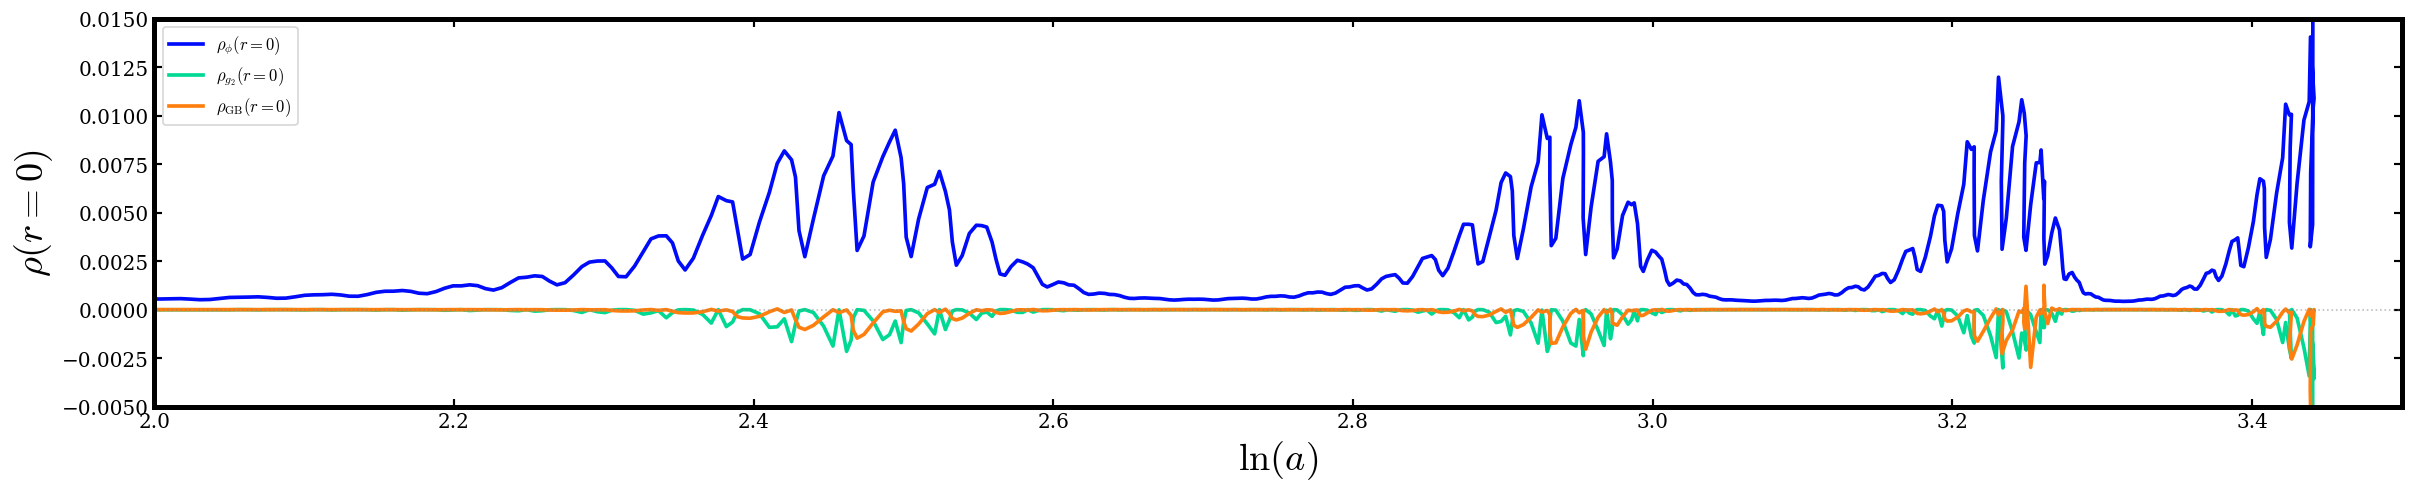

In [19]:
# Panel 6c — central densities vs aligned ln(a).
# Uses PLOT6B_KEY from the snapshot cell above.
# At each time, take rho_phi, rho_g2, rho_GB at the grid point closest to r = 0.

PLOT6C_STRIDE = 1          # evaluate every Nth snapshot (1 = all)
PLOT6C_NAME  = "rho_center_vs_lna_lgb3_g210"

if PLOT6B_KEY not in all_runs:
    print(f"Key {PLOT6B_KEY} not found in all_runs.")
else:
    run    = all_runs[PLOT6B_KEY]
    s_ln_a = np.asarray(run["shifted_ln_a"])
    n_t    = len(s_ln_a)
    idxs   = np.arange(0, n_t, max(int(PLOT6C_STRIDE), 1))

    matter  = ScalarMatter(scalar_mu, run["mu"])
    sv      = StateVector(matter)
    spacing = CubicSpacing(**CubicSpacing.get_parameters(
        run["run_r_max"], run["run_min_dr"], run["run_max_dr"]))
    grid    = Grid(spacing, sv)
    bg      = FlatSphericalBackground(grid.r)
    r_grid  = grid.r
    gb      = GBVars(grid.N)
    bssn    = BSSNVars(grid.N)

    _sol = np.load(os.path.join(run["run_dir"], "solution.npy"))

    lna_c = np.empty(len(idxs))
    rho_phi_c = np.empty(len(idxs))
    rho_g2_c  = np.empty(len(idxs))
    rho_GB_c  = np.empty(len(idxs))

    i_center = int(np.argmin(np.abs(r_grid)))
    print(f"Central value at r = {r_grid[i_center]:.6g}  "
          f"({len(idxs)} / {n_t} snapshots, tag={run['tag']})")

    for k, it in enumerate(idxs):
        state = _sol[it].reshape(grid.NUM_VARS, -1)
        bssn.set_bssn_vars(state)
        matter.set_matter_vars(state, bssn, grid)
        d1 = grid.get_d1_metric_quantities(state)
        d2 = grid.get_d2_metric_quantities(state)
        get_gb_core(gb, r_grid, bssn, d1, d2, grid, bg, run["lgb"], chi0)
        get_esgb_br_terms(gb, r_grid, matter, bssn, d1, d2, grid, bg,
                          run["lgb"], chi0, run["coupling"], run["g2"])

        rho_GR = matter.get_emtensor(r_grid, bssn, bg, gb).rho.copy()
        rho_g2 = gb.rho_g2.copy()
        rho_GB = gb.rho_GB.copy()
        grid.fill_inner_boundary_single_variable(rho_GR)
        grid.fill_inner_boundary_single_variable(rho_g2)
        grid.fill_inner_boundary_single_variable(rho_GB)

        lna_c[k]      = s_ln_a[it]
        rho_phi_c[k]  = float(rho_GR[i_center])
        rho_g2_c[k]   = float(rho_g2[i_center])
        rho_GB_c[k]   = float(rho_GB[i_center])

        if (k + 1) % 50 == 0 or k + 1 == len(idxs):
            print(f"  {k+1:4d}/{len(idxs)}  ln(a)={s_ln_a[it]:.3f}")

    del _sol

    cmap = plt.cm.winter
    fig, ax = plt.subplots(figsize=(20, 4), constrained_layout=True)
    ax.plot(lna_c, rho_phi_c, color=cmap(0.05), lw=2.2,
            label=r"$\rho_{\phi}(r=0)$")
    ax.plot(lna_c, rho_g2_c, color=cmap(0.85), lw=2.2,
            label=r"$\rho_{g_2}(r=0)$")
    ax.plot(lna_c, rho_GB_c, color="tab:orange", lw=2.2,
            label=r"$\rho_{\rm GB}(r=0)$")
    ax.axhline(0.0, color="grey", ls=":", lw=1.0, alpha=0.5)
    ax.set_xlabel(r"$\ln(a)$")
    ax.set_ylabel(r"$\rho(r=0)$")
    ax.set_xlim(2 ,3.5)
    ax.set_ylim(-0.005, 0.015)
    ax.legend(fontsize=10, loc="best", frameon=True)
    ax.tick_params(which="both", top=True, right=True)

    save_fig(fig, PLOT6C_NAME)
    plt.show()


Selected: (3, 0.08, 0, -0.02, 3.0, 10)  tag=lgb3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g210
  3 snapshots, R_A <= 6
  ln(a) = 3.1994  (requested nearest of the linspace)
  ln(a) = 3.2035  (requested nearest of the linspace)
  ln(a) = 3.2099  (requested nearest of the linspace)
  saved rho_phi_GB_g2_vs_RA_times.pdf and rho_phi_GB_g2_vs_RA_times.png


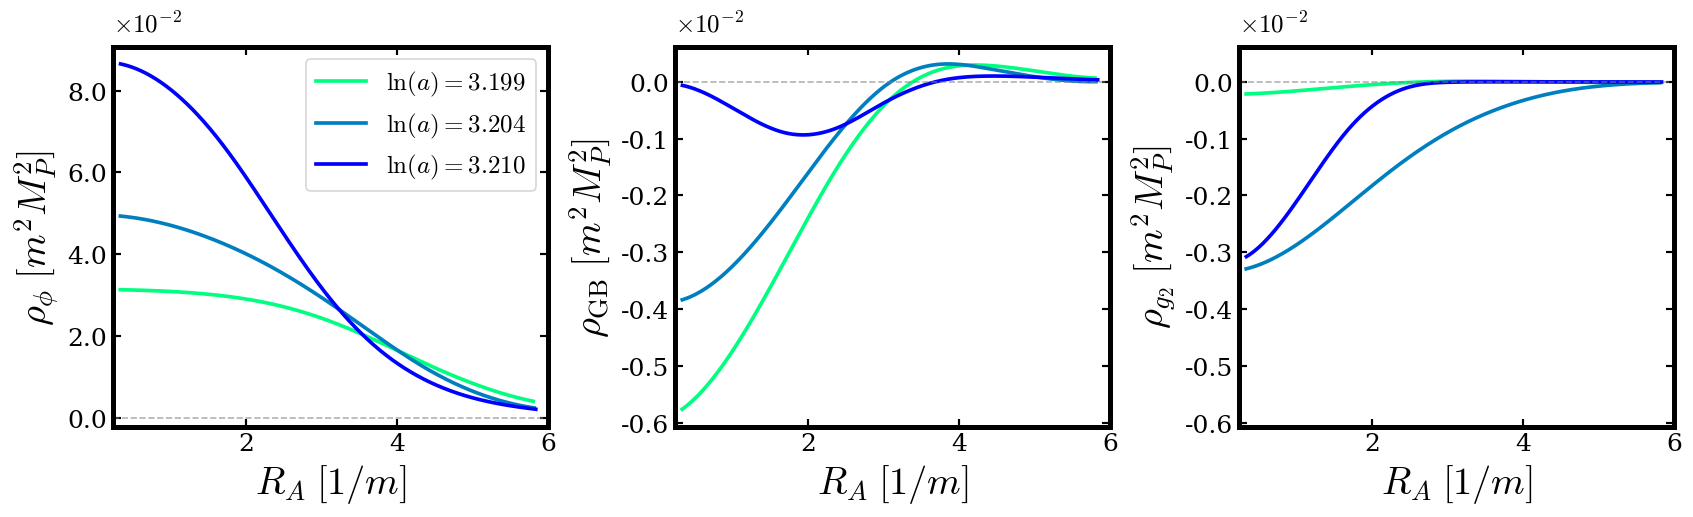

In [44]:
# Panel 6d — rho_phi, rho_GB, rho_g2 vs areal radius at the same ln(a) times.
# Uses PLOT6B_KEY from the cells above (the run that has both GB and g2).
# Left:   GR scalar density rho_phi
# Middle: Gauss-Bonnet density rho_GB
# Right:  g2 density rho_g2
# All three panels use the same snapshots. Times are equally spaced in ln(a)
# from PLOT6D_LNA_START to PLOT6D_LNA_END, with PLOT6D_N curves in total
# (including the start and end). Colormaps can differ per panel; winter
# matches the multi-time radial plot above.

from bssn.bssnstatevariables import idx_phi, idx_htt
from bssn.bssnvars import BSSNVars
from bssn.ModifiedGravity import GBVars, get_gb_core, get_esgb_br_terms
from matplotlib.ticker import FuncFormatter
from scipy.interpolate import interp1d

PLOT6D_LNA_START = 3.20    # first ln(a)
PLOT6D_LNA_END   = 3.21     # last ln(a)
PLOT6D_N         = 3    # number of times from start to end (inclusive)
PLOT6D_R_MAX     = 6      # areal-radius window
PLOT6D_CMAP_PHI  = "winter_r"   # left panel
PLOT6D_CMAP_GB   = "winter_r"   # middle panel
PLOT6D_CMAP_G2   = "winter_r"   # right panel
PLOT6D_NAME      = "rho_phi_GB_g2_vs_RA_times"

if PLOT6B_KEY not in all_runs:
    print(f"Key {PLOT6B_KEY} not found in all_runs.")
else:
    run    = all_runs[PLOT6B_KEY]
    s_ln_a = np.asarray(run["shifted_ln_a"])
    n_req  = max(int(PLOT6D_N), 2)
    lna_req = np.linspace(PLOT6D_LNA_START, PLOT6D_LNA_END, n_req)
    snap_indices = [int(np.argmin(np.abs(s_ln_a - v))) for v in lna_req]
    # drop duplicate snapshots if the grid is coarser than the requested spacing
    snap_indices = list(dict.fromkeys(snap_indices))

    matter  = ScalarMatter(scalar_mu, run["mu"])
    sv      = StateVector(matter)
    spacing = CubicSpacing(**CubicSpacing.get_parameters(
        run["run_r_max"], run["run_min_dr"], run["run_max_dr"]))
    grid    = Grid(spacing, sv)
    bg      = FlatSphericalBackground(grid.r)
    r_grid  = grid.r
    gb      = GBVars(grid.N)
    bssn    = BSSNVars(grid.N)

    _sol = np.load(os.path.join(run["run_dir"], "solution.npy"))

    curves = []
    print(f"Selected: {PLOT6B_KEY}  tag={run['tag']}")
    print(f"  {len(snap_indices)} snapshots, R_A <= {PLOT6D_R_MAX:g}")
    for it in snap_indices:
        state = _sol[it].reshape(grid.NUM_VARS, -1)
        bssn.set_bssn_vars(state)
        matter.set_matter_vars(state, bssn, grid)
        d1 = grid.get_d1_metric_quantities(state)
        d2 = grid.get_d2_metric_quantities(state)
        get_gb_core(gb, r_grid, bssn, d1, d2, grid, bg, run["lgb"], chi0)
        get_esgb_br_terms(gb, r_grid, matter, bssn, d1, d2, grid, bg,
                          run["lgb"], chi0, run["coupling"], run["g2"])

        rho_GR = matter.get_emtensor(r_grid, bssn, bg, gb).rho.copy()
        rho_g2 = gb.rho_g2.copy()
        rho_GB = gb.rho_GB.copy()
        grid.fill_inner_boundary_single_variable(rho_GR)
        grid.fill_inner_boundary_single_variable(rho_g2)
        grid.fill_inner_boundary_single_variable(rho_GB)

        R_A = (np.exp(2.0 * state[idx_phi]) * r_grid
               * np.sqrt(np.maximum(1.0 + state[idx_htt], 1e-30)))
        mask = (r_grid >= 0.0) & (R_A <= PLOT6D_R_MAX) & np.isfinite(R_A)
        curves.append((float(s_ln_a[it]), R_A[mask],
                       rho_GR[mask], rho_GB[mask], rho_g2[mask]))
        print(f"  ln(a) = {s_ln_a[it]:.4f}  (requested nearest of the linspace)")

    del _sol

    cmaps = (
        plt.get_cmap(PLOT6D_CMAP_PHI),
        plt.get_cmap(PLOT6D_CMAP_GB),
        plt.get_cmap(PLOT6D_CMAP_G2),
    )
    ylabels = (
        r"$\rho_{\phi} \; [m^2 M_{P}^2]$",
        r"$\rho_{\rm GB} \; [m^2 M_{P}^2]$",
        r"$\rho_{g_2} \; [m^2 M_{P}^2]$",
    )
    n = len(curves)
    _Y_SCALE = 1e-3
    _N_FINE = 400

    def _smooth(x, y):
        order = np.argsort(x)
        x = np.asarray(x[order], dtype=float)
        y = np.asarray(y[order], dtype=float)
        uniq = np.concatenate(([True], np.diff(x) > 1e-14))
        x, y = x[uniq], y[uniq]
        x_fine = np.linspace(x.min(), x.max(), _N_FINE)
        return x_fine, interp1d(x, y, kind="cubic")(x_fine)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True,
                             sharex=True)
    y_right = []
    for j, (lna_val, x, y_phi, y_GB, y_g2) in enumerate(curves):
        ys = (y_phi, y_GB, y_g2)
        lbl = rf"$\ln(a) = {lna_val:.3f}$"
        for i_ax, (ax, y, cmap) in enumerate(zip(axes, ys, cmaps)):
            color = cmap(j / max(n - 1, 1))
            x_fine, y_fine = _smooth(x, y)
            ax.plot(x_fine, y_fine, color=color, lw=2.2, label=lbl)
            if i_ax > 0:
                y_right.append(y_fine)

    y_right = np.concatenate(y_right)
    y_lo = float(np.nanmin(y_right))
    y_hi = float(np.nanmax(y_right))
    pad = 0.05 * (y_hi - y_lo if y_hi > y_lo else max(abs(y_hi), 1e-30))

    for ax, ylab in zip(axes, ylabels):
        ax.axhline(0.0, color="grey", ls="--", lw=1.0, alpha=0.6)
        ax.set_xlim(0, PLOT6D_R_MAX)
        ax.set_xlabel(r"$R_A \; [1/m]$")
        ax.set_ylabel(ylab)
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda v, _pos: f"{v / _Y_SCALE:.1f}"))
        ax.annotate(r"$\times 10^{-2}$", xy=(0, 1), xycoords="axes fraction",
                    xytext=(0, 6), textcoords="offset points",
                    ha="left", va="bottom", fontsize=15)
        ax.tick_params(which="both", top=True, right=True, labelsize=15)

    for ax in axes[1:]:
        ax.set_ylim(y_lo - pad, y_hi + pad)
    axes[0].set_xlim(0.24, PLOT6D_R_MAX)
    axes[0].set_ylabel(ylabels[0], fontsize=23)
    axes[1].set_ylabel(ylabels[1], fontsize=23)
    axes[2].set_ylabel(ylabels[2], fontsize=23)

    axes[0].legend(fontsize=15, loc="best", frameon=True)
    save_fig(fig, PLOT6D_NAME)
    plt.show()


  saved rho_phi_GB_g2_vs_RA_times_sharedy.pdf and rho_phi_GB_g2_vs_RA_times_sharedy.png


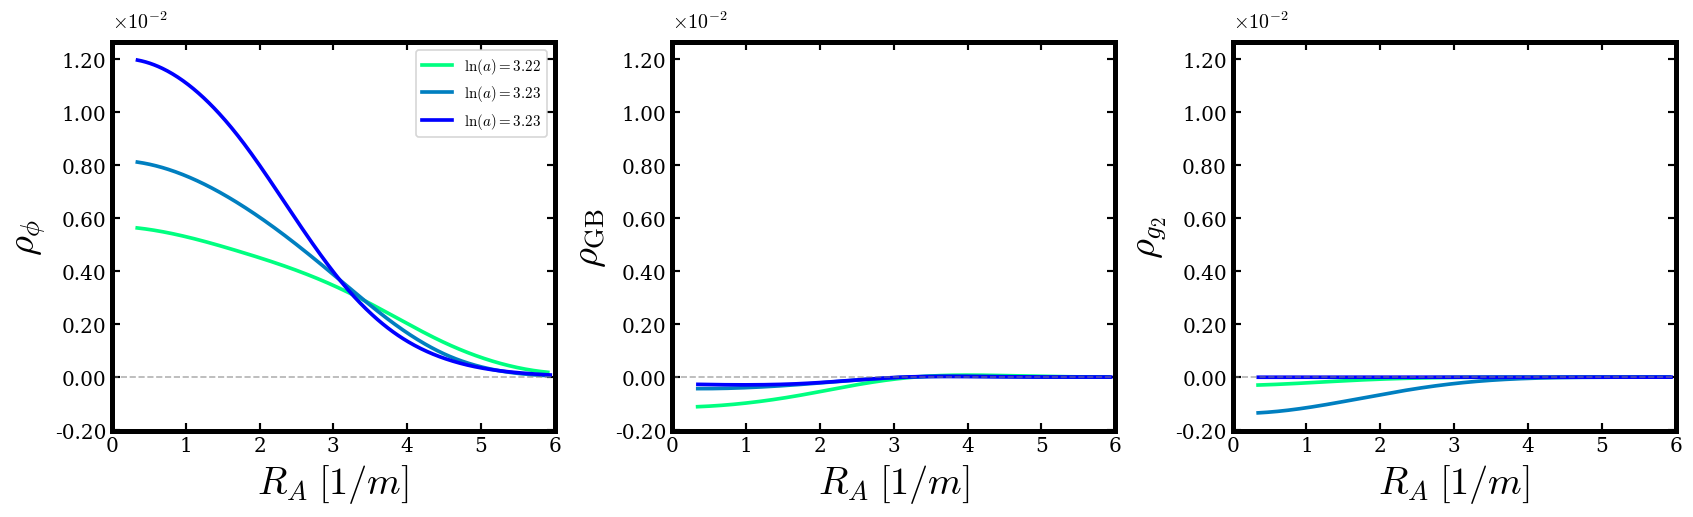

In [21]:
# Panel 6e — same as 6d, with one shared y-scale on all three panels.
# Reuses PLOT6D_* and the curves built by the cell above. Run that cell first.

from matplotlib.ticker import FuncFormatter

if "curves" not in globals() or len(curves) == 0:
    print("Run the panel 6d cell above first.")
else:
    cmaps = (
        plt.get_cmap(PLOT6D_CMAP_PHI),
        plt.get_cmap(PLOT6D_CMAP_GB),
        plt.get_cmap(PLOT6D_CMAP_G2),
    )
    ylabels = (
        r"$\rho_{\phi}$",
        r"$\rho_{\rm GB}$",
        r"$\rho_{g_2}$",
    )
    n = len(curves)
    _Y_SCALE = 1e-2
    _N_FINE = 400

    def _smooth(x, y):
        order = np.argsort(x)
        x = np.asarray(x[order], dtype=float)
        y = np.asarray(y[order], dtype=float)
        uniq = np.concatenate(([True], np.diff(x) > 1e-14))
        x, y = x[uniq], y[uniq]
        x_fine = np.linspace(x.min(), x.max(), _N_FINE)
        return x_fine, interp1d(x, y, kind="cubic")(x_fine)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True,
                             sharex=True, sharey=True)
    y_all = []
    for j, (lna_val, x, y_phi, y_GB, y_g2) in enumerate(curves):
        ys = (y_phi, y_GB, y_g2)
        lbl = rf"$\ln(a) = {lna_val:.2f}$"
        for ax, y, cmap in zip(axes, ys, cmaps):
            color = cmap(j / max(n - 1, 1))
            x_fine, y_fine = _smooth(x, y)
            ax.plot(x_fine, y_fine, color=color, lw=2.2, label=lbl)
            y_all.append(y_fine)

    y_all = np.concatenate(y_all)
    y_lo = float(np.nanmin(y_all))
    y_hi = float(np.nanmax(y_all))
    pad = 0.05 * (y_hi - y_lo if y_hi > y_lo else max(abs(y_hi), 1e-6))

    for ax, ylab in zip(axes, ylabels):
        ax.axhline(0.0, color="grey", ls="--", lw=1.0, alpha=0.6)
        ax.set_xlim(0, PLOT6D_R_MAX)
        ax.set_ylim(y_lo - pad, y_hi + pad)
        ax.set_xlabel(r"$R_A \; [1/m]$")
        ax.set_ylabel(ylab)
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda v, _pos: f"{v / _Y_SCALE:.2f}"))
        ax.annotate(r"$\times 10^{-2}$", xy=(0, 1), xycoords="axes fraction",
                    xytext=(0, 6), textcoords="offset points",
                    ha="left", va="bottom", fontsize=12)
        ax.tick_params(which="both", top=True, right=True, labelleft=True)

    axes[0].legend(fontsize=9, loc="best", frameon=True)
    save_fig(fig, PLOT6D_NAME + "_sharedy")
    plt.show()


## Panel 7 — 2D density-contrast slice $\delta(x, y)$

Renders the spherically-symmetric radial profile $\delta(r,\, t)$ as a 2D
heatmap on the $(x, y)$ plane by rotating it around the origin:

$$\delta(x, y) \;=\; \delta\!\bigl(\sqrt{x^2 + y^2},\, t\bigr).$$

This visualisation gives a "2D-slice" feel for a strictly 1D run; because
the underlying data is radial, the resulting image is necessarily
*concentric* (a single bullseye rather than several oscillons floating
around like in a true 2D/3D simulation).

The snapshot is picked by setting `PLOT7_LNA` to a value of (aligned)
$\ln(a)$ — the plot cell snaps to the closest available simulation
snapshot.

Edit `PLOT7_KEY`, `PLOT7_LNA`, `PLOT7_X_MAX`, `PLOT7_NPIX`, `PLOT7_CMAP`,
`PLOT7_VMIN`, `PLOT7_VMAX` and `PLOT7_NAME` below.

In [238]:
PLOT7_KEY   = (0, 0.08, 0, -0.02, 3.0, 0)
PLOT7_LNA   = 2.5
PLOT7_X_MAX = 1.5
PLOT7_NPIX  = 400
PLOT7_CMAP  = "jet"
PLOT7_VMIN  = None
PLOT7_VMAX  = None
PLOT7_NAME  = "delta_2D_lgb0_mu0.08_amp-0.02"

if PLOT7_KEY not in all_runs:
    print(f"Key {PLOT7_KEY} not found in all_runs.")
    print("Available keys:")
    for k in sorted(all_runs.keys()):
        print(f"  {k}  coupling={all_runs[k]['coupling']}")
else:
    s_ln_a_tmp = np.asarray(all_runs[PLOT7_KEY]["shifted_ln_a"])
    idx_tmp    = int(np.argmin(np.abs(s_ln_a_tmp - PLOT7_LNA)))
    print(f"Selected: {PLOT7_KEY}")
    print(f"  tag                    = {all_runs[PLOT7_KEY]['tag']}")
    print(f"  shift                  = {all_runs[PLOT7_KEY]['shift']:+.3f}")
    print(f"  requested ln(a)        = {PLOT7_LNA}")
    print(f"  closest snapshot ln(a) = {s_ln_a_tmp[idx_tmp]:.3f}  (idx={idx_tmp})")

Selected: (0, 0.08, 0, -0.02, 3.0, 0)
  tag                    = lgb0.0_mu0.08_a0.0_b0.0_amp-0.02_R3.0_dr0.041666666666666664_quadratic_0
  shift                  = +0.082
  requested ln(a)        = 2.5
  closest snapshot ln(a) = 2.500  (idx=310)


  saved delta_2D_lgb0_mu0.08_amp-0.02_lna2p50.pdf and delta_2D_lgb0_mu0.08_amp-0.02_lna2p50.png


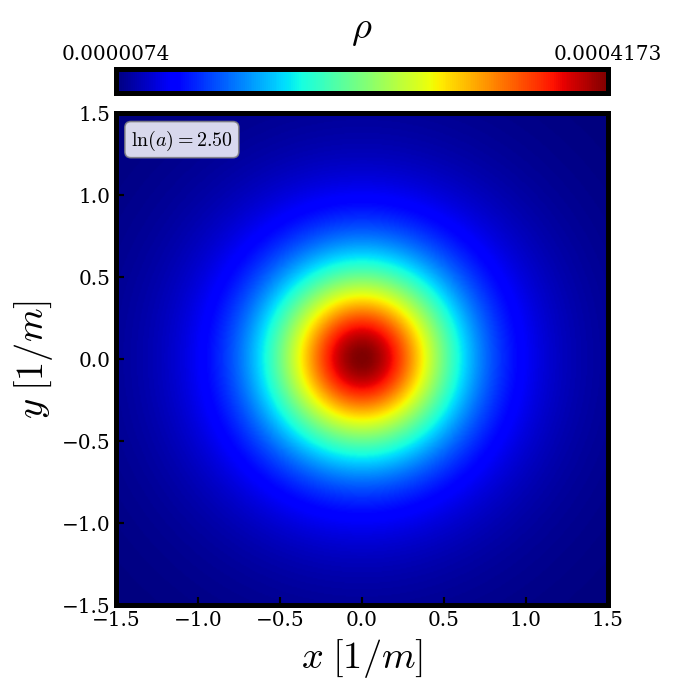

In [239]:
run    = all_runs[PLOT7_KEY]
osc    = run["osc"]
r_grid = np.asarray(osc["r"])
s_ln_a = np.asarray(run["shifted_ln_a"])

if "delta_rho" in osc:
    delta_rho = np.asarray(osc["rho"])
    #delta_rho = np.asarray(osc["rho"])
else:
    rho     = np.asarray(osc["rho"])
    rho_bar = np.asarray(osc["rho_bar"])
    delta_rho = rho / np.maximum(rho_bar[:, None], 1e-30) - 1.0

idx     = int(np.argmin(np.abs(s_ln_a - PLOT7_LNA)))
lna_val = s_ln_a[idx]
prof    = delta_rho[idx]

order    = np.argsort(r_grid)
r_sorted = r_grid[order]
p_sorted = prof[order]

n  = PLOT7_NPIX
xs = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
ys = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
X, Y = np.meshgrid(xs, ys)
R    = np.sqrt(X**2 + Y**2)

delta_2d = np.interp(R, r_sorted, p_sorted,
                     left=p_sorted[0], right=0.0)

vmin = float(np.nanmin(delta_2d)) if PLOT7_VMIN is None else PLOT7_VMIN
vmax = float(np.nanmax(delta_2d)) if PLOT7_VMAX is None else PLOT7_VMAX

fig, ax = plt.subplots(figsize=(5.5, 6.0), constrained_layout=True)
im = ax.imshow(
    delta_2d,
    extent=[-PLOT7_X_MAX, PLOT7_X_MAX, -PLOT7_X_MAX, PLOT7_X_MAX],
    origin="lower",
    cmap=PLOT7_CMAP,
    vmin=vmin, vmax=vmax,
    #vmin=vmin, vmax=200,
    aspect="equal",
    interpolation="bilinear",
)

ax.set_xlabel(r"$x \; [1/m]$")
ax.set_ylabel(r"$y \; [1/m]$")

cbar = fig.colorbar(im, ax=ax, orientation="horizontal", location="top",
                    fraction=0.05, pad=0.02)
cbar.set_label(r"$\rho$")
cbar.set_ticks([vmin, vmax])
#cbar.set_ticks([vmin, 200])
cbar.ax.tick_params(direction="in")

ax.text(0.03, 0.97, rf"$\ln(a) = {lna_val:.2f}$",
        transform=ax.transAxes, va="top", ha="left", fontsize=12,
        bbox=dict(boxstyle="round,pad=0.3",
                  facecolor="white", alpha=0.85, edgecolor="grey"))

save_fig(fig, PLOT7_NAME + f"_lna{lna_val:.2f}".replace(".", "p"))
plt.show()

  saved delta_2D_lgb0_mu0.08_amp-0.02_3d_lna2p50.pdf and delta_2D_lgb0_mu0.08_amp-0.02_3d_lna2p50.png


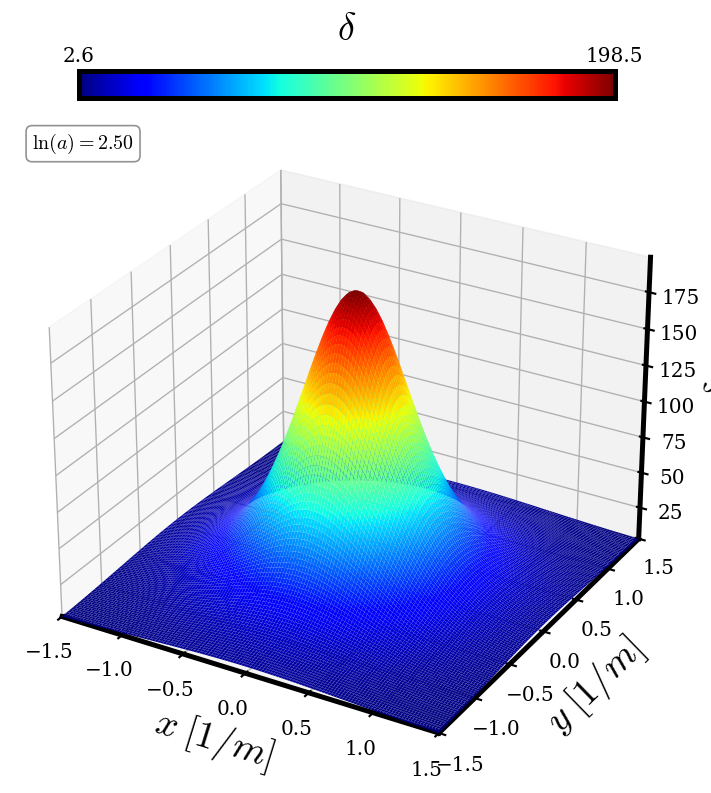

In [240]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3D projection)

run    = all_runs[PLOT7_KEY]
osc    = run["osc"]
r_grid = np.asarray(osc["r"])
s_ln_a = np.asarray(run["shifted_ln_a"])

if "delta_rho" in osc:
    delta_rho = np.asarray(osc["delta_rho"])
else:
    rho     = np.asarray(osc["rho"])
    rho_bar = np.asarray(osc["rho_bar"])
    delta_rho = rho / np.maximum(rho_bar[:, None], 1e-30) - 1.0

idx     = int(np.argmin(np.abs(s_ln_a - PLOT7_LNA)))
lna_val = s_ln_a[idx]
prof    = delta_rho[idx]

order    = np.argsort(r_grid)
r_sorted = r_grid[order]
p_sorted = prof[order]

n  = PLOT7_NPIX
xs = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
ys = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
X, Y = np.meshgrid(xs, ys)
R    = np.sqrt(X**2 + Y**2)

delta_2d = np.interp(R, r_sorted, p_sorted,
                     left=p_sorted[0], right=0.0)

vmin = float(np.nanmin(delta_2d)) if PLOT7_VMIN is None else PLOT7_VMIN
vmax = float(np.nanmax(delta_2d)) if PLOT7_VMAX is None else PLOT7_VMAX

stride = max(1, n // 120)

fig = plt.figure(figsize=(7.0, 6.5), constrained_layout=True)
ax  = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    X, Y, delta_2d,
    cmap=PLOT7_CMAP,
    vmin=vmin, vmax=vmax,
    rstride=stride, cstride=stride,
    linewidth=0, antialiased=True,
)

ax.set_xlabel(r"$x \; [1/m]$", labelpad=8)
ax.set_ylabel(r"$y \; [1/m]$", labelpad=8)
ax.set_zlabel(r"$\delta$",     labelpad=8)
ax.set_xlim(-PLOT7_X_MAX, PLOT7_X_MAX)
ax.set_ylim(-PLOT7_X_MAX, PLOT7_X_MAX)
ax.set_zlim(vmin, vmax)
ax.view_init(elev=28, azim=-60)

cbar = fig.colorbar(surf, ax=ax, orientation="horizontal", location="top",
                    fraction=0.04, pad=0.02, shrink=0.7)
cbar.set_label(r"$\delta$")
cbar.set_ticks([vmin, vmax])
cbar.ax.tick_params(direction="in")

ax.text2D(0.03, 0.97, rf"$\ln(a) = {lna_val:.2f}$",
          transform=ax.transAxes, va="top", ha="left", fontsize=12,
          bbox=dict(boxstyle="round,pad=0.3",
                    facecolor="white", alpha=0.85, edgecolor="grey"))

save_fig(fig, PLOT7_NAME + f"_3d_lna{lna_val:.2f}".replace(".", "p"))
plt.show()

  saved panel8_radial_and_2DD_lna2p50.pdf and panel8_radial_and_2DD_lna2p50.png


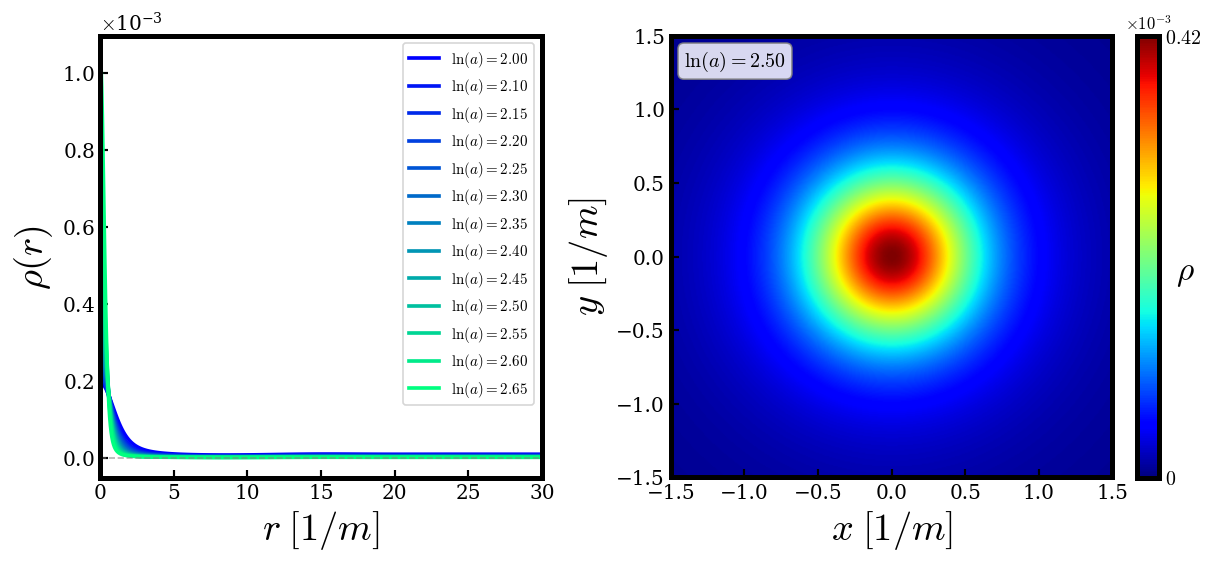

In [241]:
# Panel 8 — combined view: radial profiles (left) + rotated 2D slice (right).
# Uses the existing PLOT6_* and PLOT7_* selection variables, so re-run the
# Panel 6 and Panel 7 selection cells first if you change the parameters.

# ── Left-panel data: radial rho(r) profiles at PLOT6_SNAPS ─────────────────
run6    = all_runs[PLOT6_KEY]
osc6    = run6["osc"]
r6      = np.asarray(osc6["r"])
ln_a6   = np.asarray(run6["shifted_ln_a"])
field6  = np.asarray(osc6["rho"])
field6_label = r"$\rho(r)$"
R_osc_t6     = np.asarray(osc6["R"])
snap_idx6    = [int(np.argmin(np.abs(ln_a6 - v))) for v in PLOT6_SNAPS]

# ── Right-panel data: rotated 2D slice of delta(x, y) at PLOT7_LNA ─────────
run7   = all_runs[PLOT7_KEY]
osc7   = run7["osc"]
r7     = np.asarray(osc7["r"])
ln_a7  = np.asarray(run7["shifted_ln_a"])

if "delta_rho" in osc7:
    field7 = np.asarray(osc7["rho"])
else:
    rho     = np.asarray(osc7["rho"])
    rho_bar = np.asarray(osc7["rho_bar"])
    field7  = rho / np.maximum(rho_bar[:, None], 1e-30) - 1.0

idx7     = int(np.argmin(np.abs(ln_a7 - PLOT7_LNA)))
lna_val7 = ln_a7[idx7]
prof7    = field7[idx7]

order7    = np.argsort(r7)
r_sorted7 = r7[order7]
p_sorted7 = prof7[order7]

n  = PLOT7_NPIX
xs = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
ys = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
X, Y = np.meshgrid(xs, ys)
R    = np.sqrt(X**2 + Y**2)

delta_2d = np.interp(R, r_sorted7, p_sorted7,
                     left=p_sorted7[0], right=0.0)
vmin = float(np.nanmin(delta_2d)) if PLOT7_VMIN is None else PLOT7_VMIN
vmax = float(np.nanmax(delta_2d)) if PLOT7_VMAX is None else PLOT7_VMAX

# ── Side-by-side figure ───────────────────────────────────────────────────
fig, (axL, axR) = plt.subplots(
    1, 2, figsize=(10, 5), constrained_layout=True,
)
axL.set_box_aspect(1)

cmap6 = plt.cm.winter
m     = len(snap_idx6)
for j, idx in enumerate(snap_idx6):
    color = cmap6(j / max(m - 1, 1))
    lna_v = ln_a6[idx]
    yprof = field6[idx]

    if PLOT6_USE_OSC_RADIUS:
        R_osc = R_osc_t6[idx]
        if R_osc <= 0:
            print(f"Skipping ln(a)={lna_v:.2f}: R_osc = {R_osc:.3g} (no oscillon yet)")
            continue
        x_axis = r6 / R_osc
        x_mask = (r6 >= 0) & (x_axis <= PLOT6_X_NORM_MAX)
        lbl    = rf"$\ln(a) = {lna_v:.2f},\ R_{{\rm osc}} = {R_osc:.2f}$"
    else:
        x_axis = r6
        x_mask = (r6 >= 0) & (r6 <= PLOT6_R_MAX)
        lbl    = rf"$\ln(a) = {lna_v:.2f}$"

    axL.plot(x_axis[x_mask], yprof[x_mask], color=color, lw=2.2, label=lbl)

axL.axhline(0.0, color="grey", ls="--", lw=1.0, alpha=0.6)
if PLOT6_USE_OSC_RADIUS:
    axL.axvline(1.0, color="grey", ls=":", lw=1.2, alpha=0.7)
    axL.set_xlabel(r"$r / R_{\rm osc}(t)$")
    axL.set_xlim(0, PLOT6_X_NORM_MAX)
else:
    axL.set_xlabel(r"$r \; [1/m]$")
    axL.set_xlim(0, PLOT6_R_MAX)
axL.set_ylabel(field6_label)
axL.legend(fontsize=9, loc="best", frameon=True)

from matplotlib.ticker import ScalarFormatter

class _FixedOrderFormatter(ScalarFormatter):
    def __init__(self, order=0, **kwargs):
        self._fixed_order = order
        super().__init__(**kwargs)
    def _set_order_of_magnitude(self):
        self.orderOfMagnitude = self._fixed_order

_PLOT8_ORDER = -3
_fmtL = _FixedOrderFormatter(order=_PLOT8_ORDER, useMathText=True)
_fmtL.set_scientific(True)
_fmtL.set_powerlimits((_PLOT8_ORDER, _PLOT8_ORDER))
axL.yaxis.set_major_formatter(_fmtL)

im = axR.imshow(
    delta_2d,
    extent=[-PLOT7_X_MAX, PLOT7_X_MAX, -PLOT7_X_MAX, PLOT7_X_MAX],
    origin="lower",
    cmap=PLOT7_CMAP,
    vmin=0, vmax=vmax,
    aspect="equal",
    interpolation="bilinear",
)
axR.set_xlabel(r"$x \; [1/m]$")
axR.set_ylabel(r"$y \; [1/m]$")

cbar = fig.colorbar(im, ax=axR, orientation="vertical", location="right",fraction=0.05, pad=0.02)
cbar.set_label(r"$\rho$", rotation=0, labelpad=-10, fontsize=20)
cbar.set_ticks([0, vmax])
cbar.set_ticklabels([r"$0$", rf"${vmax * 10**(-_PLOT8_ORDER):.2f}$"])
cbar.ax.set_title(rf"$\times 10^{{{_PLOT8_ORDER}}}$", fontsize=10, pad=4)
cbar.ax.tick_params(direction="in")

axR.text(0.03, 0.97, rf"$\ln(a) = {lna_val7:.2f}$",
         transform=axR.transAxes, va="top", ha="left", fontsize=12,
         bbox=dict(boxstyle="round,pad=0.3",
                   facecolor="white", alpha=0.85, edgecolor="grey"))

save_fig(fig, "panel8_radial_and_2DD" + f"_lna{lna_val7:.2f}".replace(".", "p"))
plt.show()

  saved panel8_radial_RA_and_2D_lna2p50.pdf and panel8_radial_RA_and_2D_lna2p50.png


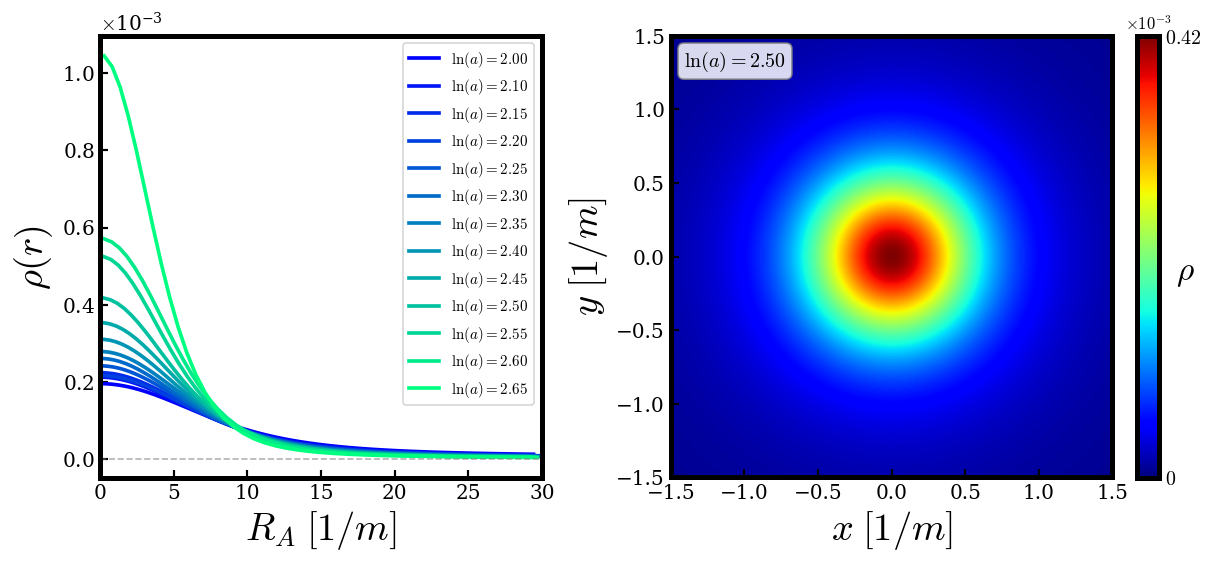

In [242]:
# Panel 8-RA — same as Panel 8 but left panel uses areal radius R_A on x-axis.
from bssn.bssnstatevariables import idx_phi, idx_htt, NUM_BSSN_VARS

run6    = all_runs[PLOT6_KEY]
osc6    = run6["osc"]
r6      = np.asarray(osc6["r"])
ln_a6   = np.asarray(run6["shifted_ln_a"])
field6  = np.asarray(osc6["rho"])
field6_label = r"$\rho(r)$"
R_osc_t6     = np.asarray(osc6["R"])
snap_idx6    = [int(np.argmin(np.abs(ln_a6 - v))) for v in PLOT6_SNAPS]

_sol8 = np.load(os.path.join(run6["run_dir"], "solution.npy"))
_N_grid8 = len(r6)

run7   = all_runs[PLOT7_KEY]
osc7   = run7["osc"]
r7     = np.asarray(osc7["r"])
ln_a7  = np.asarray(run7["shifted_ln_a"])

if "delta_rho" in osc7:
    field7 = np.asarray(osc7["rho"])
else:
    rho     = np.asarray(osc7["rho"])
    rho_bar = np.asarray(osc7["rho_bar"])
    field7  = rho / np.maximum(rho_bar[:, None], 1e-30) - 1.0

idx7     = int(np.argmin(np.abs(ln_a7 - PLOT7_LNA)))
lna_val7 = ln_a7[idx7]
prof7    = field7[idx7]

order7    = np.argsort(r7)
r_sorted7 = r7[order7]
p_sorted7 = prof7[order7]

n  = PLOT7_NPIX
xs = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
ys = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
X, Y = np.meshgrid(xs, ys)
R    = np.sqrt(X**2 + Y**2)

delta_2d = np.interp(R, r_sorted7, p_sorted7,
                     left=p_sorted7[0], right=0.0)
vmin = float(np.nanmin(delta_2d)) if PLOT7_VMIN is None else PLOT7_VMIN
vmax = float(np.nanmax(delta_2d)) if PLOT7_VMAX is None else PLOT7_VMAX

fig, (axL, axR) = plt.subplots(
    1, 2, figsize=(10, 5), constrained_layout=True,
)
axL.set_box_aspect(1)

cmap6 = plt.cm.winter
m     = len(snap_idx6)
for j, idx in enumerate(snap_idx6):
    color = cmap6(j / max(m - 1, 1))
    lna_v = ln_a6[idx]
    yprof = field6[idx]

    _state_i = _sol8[idx].reshape(-1, _N_grid8)
    _phi_i = _state_i[idx_phi]
    _htt_i = _state_i[idx_htt]
    x_axis = np.exp(2.0 * _phi_i) * r6 * np.sqrt(np.maximum(1.0 + _htt_i, 1e-30))
    x_mask = (r6 >= 0) & (x_axis <= PLOT6_R_MAX)
    lbl = rf"$\ln(a) = {lna_v:.2f}$"

    axL.plot(x_axis[x_mask], yprof[x_mask], color=color, lw=2.2, label=lbl)

del _sol8

axL.axhline(0.0, color="grey", ls="--", lw=1.0, alpha=0.6)
axL.set_xlabel(r"$R_A \; [1/m]$")
axL.set_xlim(0, PLOT6_R_MAX)
axL.set_ylabel(field6_label)
axL.legend(fontsize=9, loc="best", frameon=True)

from matplotlib.ticker import ScalarFormatter

class _FixedOrderFormatter(ScalarFormatter):
    def __init__(self, order=0, **kwargs):
        self._fixed_order = order
        super().__init__(**kwargs)
    def _set_order_of_magnitude(self):
        self.orderOfMagnitude = self._fixed_order

_PLOT8_ORDER = -3
_fmtL = _FixedOrderFormatter(order=_PLOT8_ORDER, useMathText=True)
_fmtL.set_scientific(True)
_fmtL.set_powerlimits((_PLOT8_ORDER, _PLOT8_ORDER))
axL.yaxis.set_major_formatter(_fmtL)

im = axR.imshow(
    delta_2d,
    extent=[-PLOT7_X_MAX, PLOT7_X_MAX, -PLOT7_X_MAX, PLOT7_X_MAX],
    origin="lower",
    cmap=PLOT7_CMAP,
    vmin=0, vmax=vmax,
    aspect="equal",
    interpolation="bilinear",
)
axR.set_xlabel(r"$x \; [1/m]$")
axR.set_ylabel(r"$y \; [1/m]$")

cbar = fig.colorbar(im, ax=axR, orientation="vertical", location="right",
                    fraction=0.05, pad=0.02)
cbar.set_label(r"$\rho$", rotation=0, labelpad=-10, fontsize=20)
cbar.set_ticks([0, vmax])
cbar.set_ticklabels([r"$0$", rf"${vmax * 10**(-_PLOT8_ORDER):.2f}$"])
cbar.ax.set_title(rf"$\times 10^{{{_PLOT8_ORDER}}}$", fontsize=10, pad=4)
cbar.ax.tick_params(direction="in")

axR.text(0.03, 0.97, rf"$\ln(a) = {lna_val7:.2f}$",
         transform=axR.transAxes, va="top", ha="left", fontsize=12,
         bbox=dict(boxstyle="round,pad=0.3",
                   facecolor="white", alpha=0.85, edgecolor="grey"))

save_fig(fig, "panel8_radial_RA_and_2D" + f"_lna{lna_val7:.2f}".replace(".", "p"))
plt.show()

  saved panel8_stacked_RA_2D_3D_lna2p50.pdf and panel8_stacked_RA_2D_3D_lna2p50.png


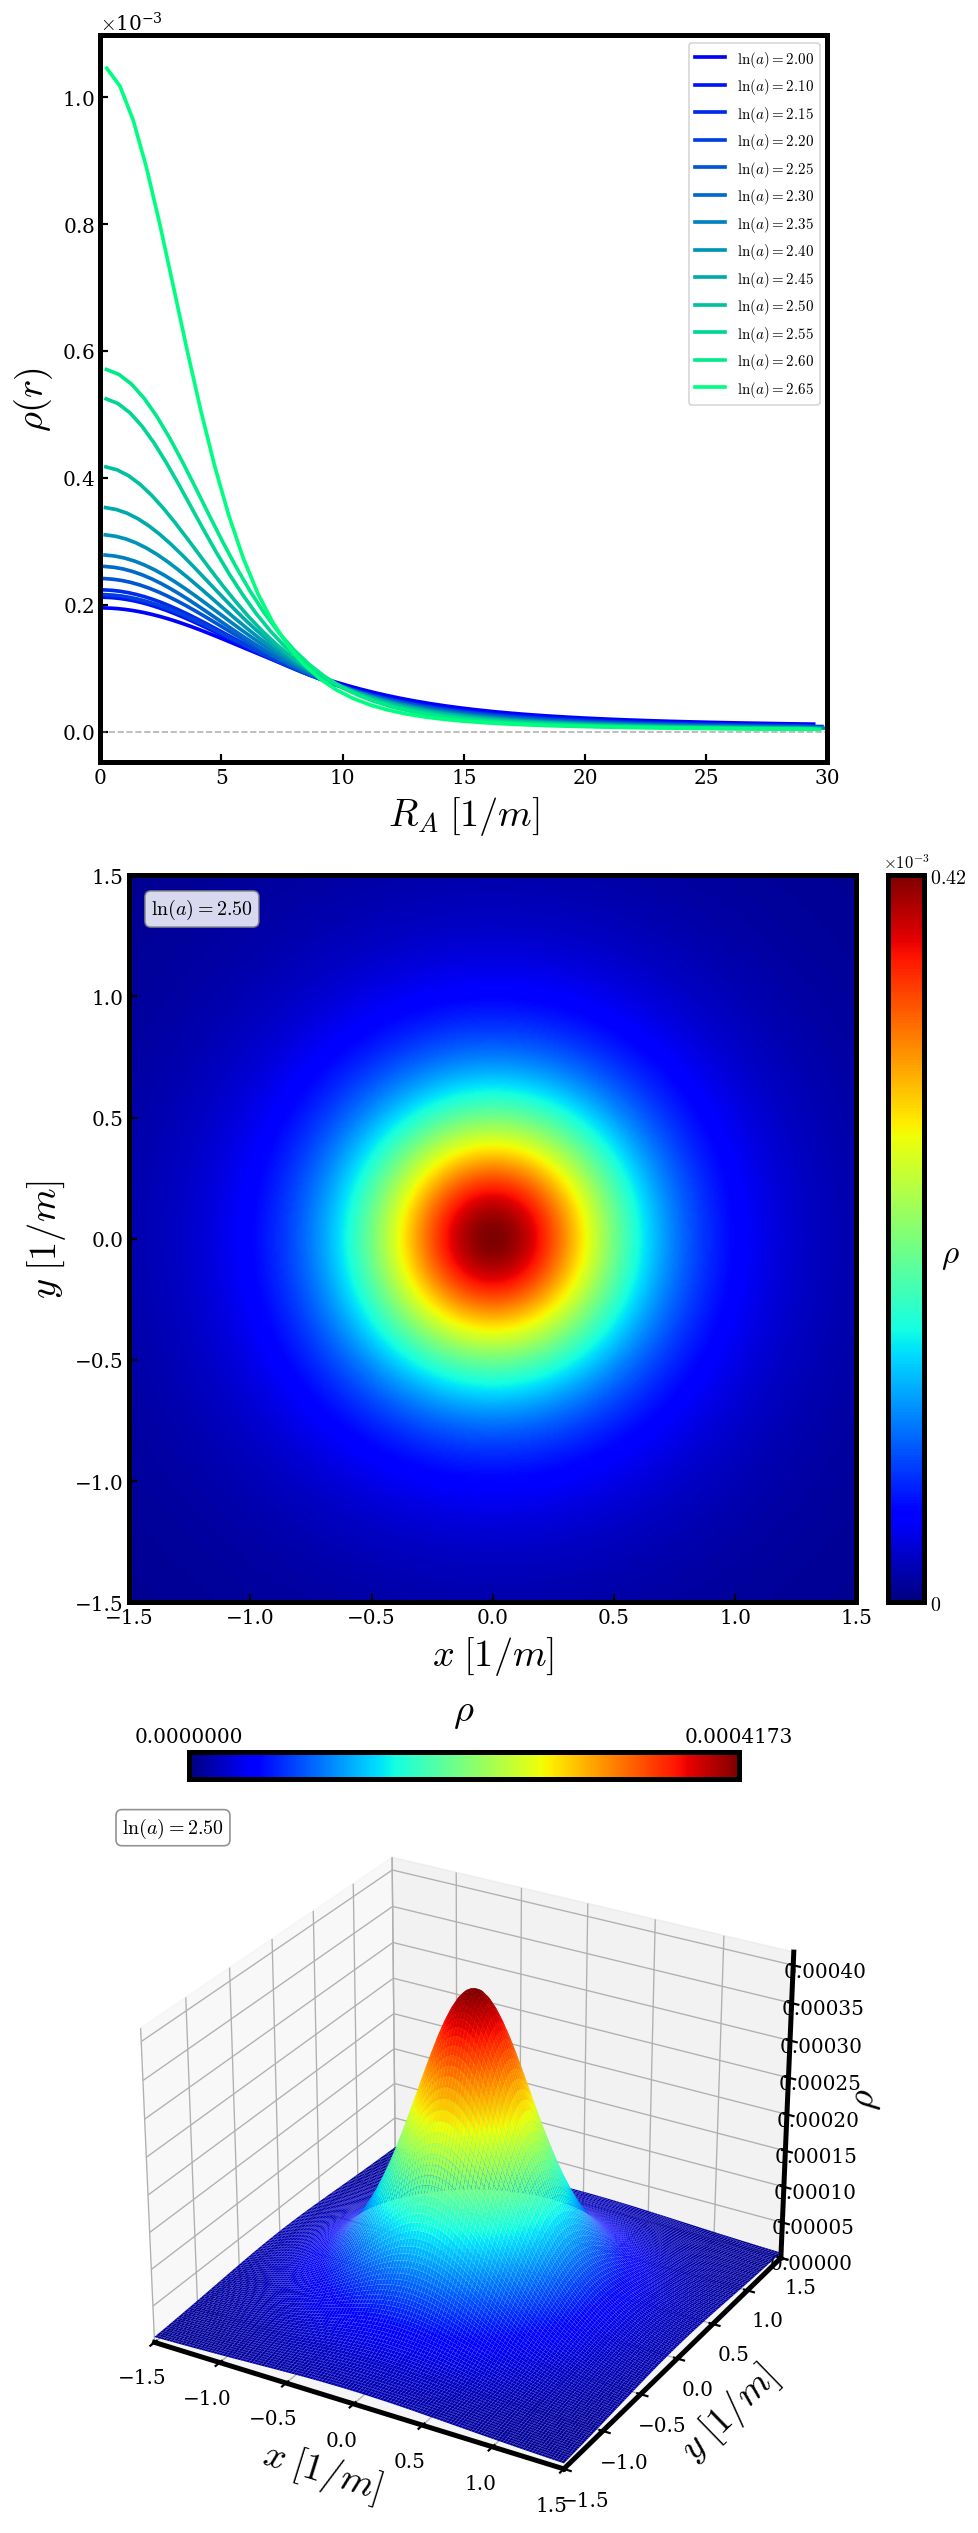

In [245]:
# Panel 8-RA stacked — 3 vertically stacked square panels:
# Top: radial rho(R_A), Middle: 2D rho cross-section, Bottom: 3D rho surface
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from bssn.bssnstatevariables import idx_phi, idx_htt

run6    = all_runs[PLOT6_KEY]
osc6    = run6["osc"]
r6      = np.asarray(osc6["r"])
ln_a6   = np.asarray(run6["shifted_ln_a"])
field6  = np.asarray(osc6["rho"])
snap_idx6 = [int(np.argmin(np.abs(ln_a6 - v))) for v in PLOT6_SNAPS]

_sol8 = np.load(os.path.join(run6["run_dir"], "solution.npy"))
_N_grid8 = len(r6)

run7   = all_runs[PLOT7_KEY]
osc7   = run7["osc"]
r7     = np.asarray(osc7["r"])
ln_a7  = np.asarray(run7["shifted_ln_a"])
rho7   = np.asarray(osc7["rho"])

idx7     = int(np.argmin(np.abs(ln_a7 - PLOT7_LNA)))
lna_val7 = ln_a7[idx7]
prof7    = rho7[idx7]

order7    = np.argsort(r7)
r_sorted7 = r7[order7]
p_sorted7 = prof7[order7]

n  = PLOT7_NPIX
xs = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
ys = np.linspace(-PLOT7_X_MAX, PLOT7_X_MAX, n)
X, Y = np.meshgrid(xs, ys)
R    = np.sqrt(X**2 + Y**2)

rho_2d = np.interp(R, r_sorted7, p_sorted7, left=p_sorted7[0], right=0.0)
vmin_rho = 0.0
vmax_rho = float(np.nanmax(rho_2d)) if PLOT7_VMAX is None else PLOT7_VMAX

from matplotlib.ticker import ScalarFormatter

class _FixedOrderFormatter2(ScalarFormatter):
    def __init__(self, order=0, **kwargs):
        self._fixed_order = order
        super().__init__(**kwargs)
    def _set_order_of_magnitude(self):
        self.orderOfMagnitude = self._fixed_order

_ORDER = -3

# --- Figure: 3 stacked square panels ---
fig = plt.figure(figsize=(8, 21), constrained_layout=True)
gs = fig.add_gridspec(3, 1, height_ratios=[1, 1, 1])

# --- Top panel: radial profile rho(R_A) ---
ax1 = fig.add_subplot(gs[0])
ax1.set_box_aspect(1)

cmap6 = plt.cm.winter
m = len(snap_idx6)
for j, idx in enumerate(snap_idx6):
    color = cmap6(j / max(m - 1, 1))
    lna_v = ln_a6[idx]
    yprof = field6[idx]

    _state_i = _sol8[idx].reshape(-1, _N_grid8)
    _phi_i = _state_i[idx_phi]
    _htt_i = _state_i[idx_htt]
    x_axis = np.exp(2.0 * _phi_i) * r6 * np.sqrt(np.maximum(1.0 + _htt_i, 1e-30))
    x_mask = (r6 >= 0) & (x_axis <= PLOT6_R_MAX)
    lbl = rf"$\ln(a) = {lna_v:.2f}$"
    ax1.plot(x_axis[x_mask], yprof[x_mask], color=color, lw=2.2, label=lbl)

del _sol8

ax1.axhline(0.0, color="grey", ls="--", lw=1.0, alpha=0.6)
ax1.set_xlabel(r"$R_A \; [1/m]$")
ax1.set_xlim(0, PLOT6_R_MAX)
ax1.set_ylabel(r"$\rho(r)$")
ax1.legend(fontsize=9, loc="best", frameon=True)

_fmt1 = _FixedOrderFormatter2(order=_ORDER, useMathText=True)
_fmt1.set_scientific(True)
_fmt1.set_powerlimits((_ORDER, _ORDER))
ax1.yaxis.set_major_formatter(_fmt1)

# --- Middle panel: 2D rho cross-section ---
ax2 = fig.add_subplot(gs[1])
ax2.set_box_aspect(1)

im = ax2.imshow(
    rho_2d,
    extent=[-PLOT7_X_MAX, PLOT7_X_MAX, -PLOT7_X_MAX, PLOT7_X_MAX],
    origin="lower",
    cmap=PLOT7_CMAP,
    vmin=vmin_rho, vmax=vmax_rho,
    aspect="equal",
    interpolation="bilinear",
)
ax2.set_xlabel(r"$x \; [1/m]$")
ax2.set_ylabel(r"$y \; [1/m]$")

cbar2 = fig.colorbar(im, ax=ax2, orientation="vertical", location="right",
                     fraction=0.05, pad=0.02)
cbar2.set_label(r"$\rho$", rotation=0, labelpad=-10, fontsize=20)
cbar2.set_ticks([0, vmax_rho])
cbar2.set_ticklabels([r"$0$", rf"${vmax_rho * 10**(-_ORDER):.2f}$"])
cbar2.ax.set_title(rf"$\times 10^{{{_ORDER}}}$", fontsize=10, pad=4)
cbar2.ax.tick_params(direction="in")

ax2.text(0.03, 0.97, rf"$\ln(a) = {lna_val7:.2f}$",
         transform=ax2.transAxes, va="top", ha="left", fontsize=12,
         bbox=dict(boxstyle="round,pad=0.3",
                   facecolor="white", alpha=0.85, edgecolor="grey"))

# --- Bottom panel: 3D rho surface ---
ax3 = fig.add_subplot(gs[2], projection="3d")

stride = max(1, n // 120)
surf = ax3.plot_surface(
    X, Y, rho_2d,
    cmap=PLOT7_CMAP,
    vmin=vmin_rho, vmax=vmax_rho,
    rstride=stride, cstride=stride,
    linewidth=0, antialiased=True,
)

ax3.set_xlabel(r"$x \; [1/m]$", labelpad=8)
ax3.set_ylabel(r"$y \; [1/m]$", labelpad=8)
ax3.set_zlabel(r"$\rho$", labelpad=8)
ax3.set_xlim(-PLOT7_X_MAX, PLOT7_X_MAX)
ax3.set_ylim(-PLOT7_X_MAX, PLOT7_X_MAX)
ax3.set_zlim(vmin_rho, vmax_rho)
ax3.view_init(elev=28, azim=-60)

cbar3 = fig.colorbar(surf, ax=ax3, orientation="horizontal", location="top",
                     fraction=0.04, pad=0.02, shrink=0.7)
cbar3.set_label(r"$\rho$")
cbar3.set_ticks([vmin_rho, vmax_rho])
cbar3.ax.tick_params(direction="in")

ax3.text2D(0.03, 0.97, rf"$\ln(a) = {lna_val7:.2f}$",
           transform=ax3.transAxes, va="top", ha="left", fontsize=12,
           bbox=dict(boxstyle="round,pad=0.3",
                     facecolor="white", alpha=0.85, edgecolor="grey"))

save_fig(fig, "panel8_stacked_RA_2D_3D" + f"_lna{lna_val7:.2f}".replace(".", "p"))
plt.show()

## Panel 4b — Compactness $\mathcal{C}$ vs $g_2$ (peak statistics, last 0.2 e-folds)

For each $(\lambda_{\rm GB}, g_2)$ run, the local maxima of $\mathcal{C}(t)$ are identified
inside the **last $\Delta\ln a = 0.2$ e-folds** of the aligned `shifted_ln_a` axis (the window
where the configuration has stabilised). The plotted point and error bar are

$$\langle\mathcal{C}\rangle = \overline{\mathcal{C}_{\rm peak}}, \qquad
  \sigma_{\mathcal{C}} = \mathrm{std}\bigl(\mathcal{C}_{\rm peak}\bigr).$$

This is the "peak-statistics" estimator: instead of mean $\pm$ std over the whole window
(which would mostly measure the breathing amplitude, not how well-determined the answer is),
the bar now reflects **cycle-to-cycle variation of the maximum compactness from one breath
to the next**. A virialised oscillon has nearly identical successive peaks and gives a small
bar; a still-settling or fragmenting one gives a large bar. Runs with fewer than two
interior peaks fall back to $\max\mathcal{C}$ in the window with a zero error bar (and are
flagged in the printout).

In [12]:
### --- Panel 4b selection (edit me) ---
P4B_MU       = 0.08
P4B_BETA     = 0
P4B_AMP      = -0.02
P4B_WIDTH    = 3.0

# Which lambda_GB curves to overlay (one curve per value).
P4B_LGB_SHOW = [0]

# Which g2 values appear on the x-axis (only those present in `all_runs` are used).
P4B_G2_SHOW  = [0,2,4,6, 8, 10, 12 ,14,16,18,20]

# Width of the averaging window (last `P4B_DLNA` e-folds of shifted_ln_a).
P4B_DLNA     = 0.5

P4B_NAME     = "compactness_vs_g2_last02efold"

print(f"lgb to plot: {P4B_LGB_SHOW}")
print(f"g2  to plot: {P4B_G2_SHOW}")
print(f"averaging window: last {P4B_DLNA} e-folds of shifted_ln_a")
print(f"filter:  beta={P4B_BETA}, mu={P4B_MU}, A={P4B_AMP}, R={P4B_WIDTH}")

lgb to plot: [0]
g2  to plot: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
averaging window: last 0.5 e-folds of shifted_ln_a
filter:  beta=0, mu=0.08, A=-0.02, R=3.0


lgb=0:
   g2=     0  n_peaks= 97   C_peak=4.4707e-03 +/- 1.37e-03
   g2=     2  n_peaks= 91   C_peak=4.7164e-03 +/- 1.35e-03
   g2=     4  n_peaks= 86   C_peak=5.3104e-03 +/- 1.49e-03
   g2=     6  n_peaks= 91   C_peak=5.9334e-03 +/- 1.63e-03
   g2=     8  n_peaks= 96   C_peak=6.1137e-03 +/- 1.52e-03
   g2=    10  n_peaks= 97   C_peak=6.8543e-03 +/- 1.61e-03
   g2=    12  n_peaks= 99   C_peak=6.9596e-03 +/- 1.57e-03
   g2=    14  n_peaks= 98   C_peak=7.5183e-03 +/- 1.67e-03
   g2=    16  n_peaks=102   C_peak=7.7774e-03 +/- 1.67e-03
   g2=    18  n_peaks=102   C_peak=7.9627e-03 +/- 1.61e-03
   g2=    20  n_peaks= 99   C_peak=8.2908e-03 +/- 1.63e-03
  saved compactness_vs_g2_last02efold.pdf and compactness_vs_g2_last02efold.png


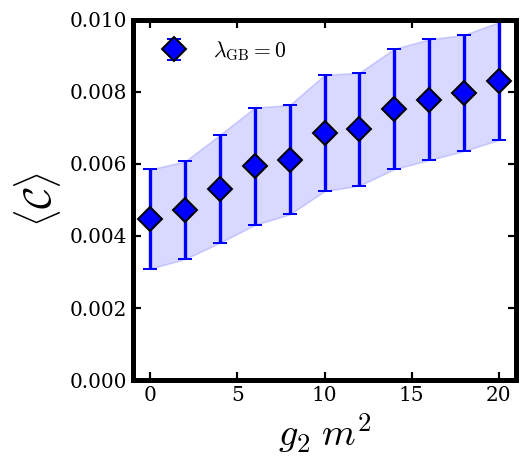

In [13]:
from collections import defaultdict
from scipy.signal import find_peaks


def _peak_stats_last_window(shifted_ln_a, C, dlna, prominence_rel=0.0,
                            min_separation=1):
    """Mean / std / count of local maxima of C(t) in the last `dlna` e-folds.

    Returns (peak_mean, peak_std, n_peaks). If fewer than one interior maximum
    is found, falls back to (max(C_window), 0.0, 0) so the run is still
    plotted with a zero error bar (and is flagged in the printout).

    Parameters
    ----------
    prominence_rel : float
        Minimum peak prominence as a fraction of the window's C-range. Set to
        a small value (e.g. 0.01) to ignore numerical ripples.
    min_separation : int
        Minimum spacing (in samples) between successive peaks.
    """
    sln = np.asarray(shifted_ln_a, dtype=float)
    C   = np.asarray(C,            dtype=float)
    finite = np.isfinite(sln) & np.isfinite(C)
    if not finite.any():
        return np.nan, np.nan, 0
    sln_f = sln[finite]
    C_f   = C[finite]
    lna_max = sln_f.max()
    mask = sln_f >= (lna_max - dlna)
    if not mask.any():
        return np.nan, np.nan, 0
    C_win = C_f[mask]
    if C_win.size < 3:
        return float(C_win.max()), 0.0, 0

    kw = {}
    if min_separation > 1:
        kw["distance"] = int(min_separation)
    if prominence_rel > 0.0:
        rng = float(C_win.max() - C_win.min())
        if rng > 0:
            kw["prominence"] = prominence_rel * rng

    peak_idx, _ = find_peaks(C_win, **kw)
    if peak_idx.size == 0:
        return float(C_win.max()), 0.0, 0
    peaks = C_win[peak_idx]
    return float(np.mean(peaks)), float(np.std(peaks)), int(peaks.size)


colors_lgb  = ["blue", "#f1c40f", "#8e44ad",
               "#e67e22", "#1abc9c", "#34495e", "#e74c3c", "#27ae60", "#2c3e50", "#c0392b"]
markers_lgb = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]

lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

all_lgbs = sorted(lgb_groups.keys())

fig, ax = plt.subplots(figsize=(4.5,4))

for idx, lgb_val in enumerate(all_lgbs):
    color  = colors_lgb[idx % len(colors_lgb)]
    marker = markers_lgb[idx % len(markers_lgb)]

    points = []
    for key in lgb_groups[lgb_val]:
        d   = all_runs[key]
        sln = d["shifted_ln_a"]
        C   = np.asarray(d["osc"]["C"])

        C_peak_mean, C_peak_std, n_peaks = _peak_stats_last_window(sln, C, P4B_DLNA)
        if not np.isfinite(C_peak_mean):
            continue

        points.append((key[5], C_peak_mean, C_peak_std, n_peaks))

    if not points:
        continue

    points = sorted(points, key=lambda p: p[0])
    x      = np.array([p[0] for p in points])
    y_mean = np.array([p[1] for p in points])
    y_err  = np.array([p[2] for p in points])

    label = rf"$\lambda_{{\rm GB}}={lgb_val:g}$"

    ax.fill_between(x, y_mean - y_err, y_mean + y_err, color=color, alpha=0.15)
    ax.errorbar(x, y_mean, yerr=y_err,
                fmt=marker, color=color,
                markeredgecolor="k", markeredgewidth=1.2,
                capsize=4, capthick=1.2, elinewidth=2, markersize=10,
                label=label)

    print(f"lgb={lgb_val:g}:")
    for g2v, Cm, Ce, n in points:
        if n == 0:
            tag = "  (fallback: 0 peaks, used max of window)"
        elif n == 1:
            tag = "  (1 peak only -> 0 error)"
        else:
            tag = ""
        print(f"   g2={g2v:>6g}  n_peaks={n:3d}   "
              f"C_peak={Cm:.4e} +/- {Ce:.2e}{tag}")

ax.set_xlabel(r"$g_2\;m^2$")
ax.set_ylabel(r"$\langle\mathcal{C}\rangle$")
ax.set_ylim(0, 0.01)
ax.tick_params(which="both", top=True, right=True)
ax.legend(loc="best", frameon=False)
fig.tight_layout()
save_fig(fig, P4B_NAME)
plt.show()

## Panel 4c — Compactness $\mathcal{C}$ vs $\lambda_{\rm GB}$ (peak statistics, last 0.2 e-folds)

Same estimator as Panel 4b, but the x-axis is now $\lambda_{\rm GB}$ and each curve
corresponds to a fixed $g_2$. In the **last $\Delta\ln a = 0.2$ e-folds** of the aligned
`shifted_ln_a` axis, the local maxima of $\mathcal{C}(t)$ are identified, and

$$\langle\mathcal{C}\rangle = \overline{\mathcal{C}_{\rm peak}}, \qquad
  \sigma_{\mathcal{C}} = \mathrm{std}\bigl(\mathcal{C}_{\rm peak}\bigr).$$

The error bar measures cycle-to-cycle scatter of the maximum compactness between successive
breaths, not the full oscillation amplitude.

In [14]:
### --- Panel 4c selection (edit me) ---
P4C_MU       = 0.08
P4C_BETA     = 0
P4C_AMP      = -0.02
P4C_WIDTH    = 3.0

# Which g2 curves to overlay (one curve per value).
P4C_G2_SHOW  = [0]

# Which lambda_GB values appear on the x-axis (only those present in `all_runs` are used).
P4C_LGB_SHOW = [0, 1, 2, 3,4,5]

# Width of the averaging window (last `P4C_DLNA` e-folds of shifted_ln_a).
P4C_DLNA     = 0.7

P4C_NAME     = "compactness_vs_lgb_last02efold"

print(f"g2  to plot: {P4C_G2_SHOW}")
print(f"lgb to plot: {P4C_LGB_SHOW}")
print(f"averaging window: last {P4C_DLNA} e-folds of shifted_ln_a")
print(f"filter:  beta={P4C_BETA}, mu={P4C_MU}, A={P4C_AMP}, R={P4C_WIDTH}")

g2  to plot: [0]
lgb to plot: [0, 1, 2, 3, 4, 5]
averaging window: last 0.7 e-folds of shifted_ln_a
filter:  beta=0, mu=0.08, A=-0.02, R=3.0


g2=0:
   lgb=     0  n_peaks=124   C_peak=4.1908e-03 +/- 1.33e-03
   lgb=     1  n_peaks=122   C_peak=4.2506e-03 +/- 1.36e-03
   lgb=     2  n_peaks=119   C_peak=4.5241e-03 +/- 1.51e-03
   lgb=     3  n_peaks=119   C_peak=4.7486e-03 +/- 1.58e-03
   lgb=     4  n_peaks=122   C_peak=4.8393e-03 +/- 1.56e-03
   lgb=     5  n_peaks=115   C_peak=5.1499e-03 +/- 1.59e-03
  saved compactness_vs_lgb_last02efold.pdf and compactness_vs_lgb_last02efold.png


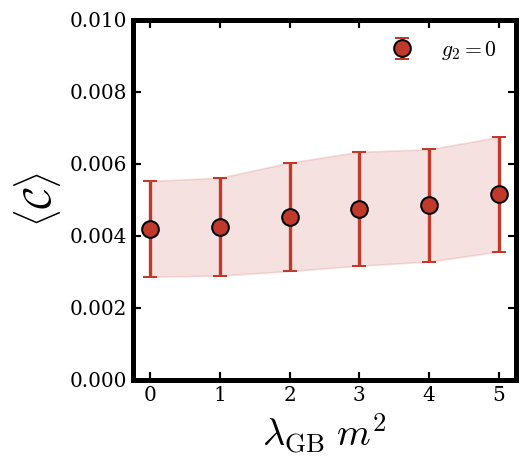

In [15]:
from collections import defaultdict
from scipy.signal import find_peaks

# `_peak_stats_last_window` is defined in Panel 4b; re-define here so this cell
# is self-contained if Panel 4b has not been executed in this session.
try:
    _peak_stats_last_window  # type: ignore[name-defined]
except NameError:
    def _peak_stats_last_window(shifted_ln_a, C, dlna, prominence_rel=0.0,
                                min_separation=1):
        """Mean / std / count of local maxima of C(t) in the last `dlna` e-folds."""
        sln = np.asarray(shifted_ln_a, dtype=float)
        C   = np.asarray(C,            dtype=float)
        finite = np.isfinite(sln) & np.isfinite(C)
        if not finite.any():
            return np.nan, np.nan, 0
        sln_f = sln[finite]
        C_f   = C[finite]
        lna_max = sln_f.max()
        mask = sln_f >= (lna_max - dlna)
        if not mask.any():
            return np.nan, np.nan, 0
        C_win = C_f[mask]
        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0
        kw = {}
        if min_separation > 1:
            kw["distance"] = int(min_separation)
        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())
            if rng > 0:
                kw["prominence"] = prominence_rel * rng
        peak_idx, _ = find_peaks(C_win, **kw)
        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0
        peaks = C_win[peak_idx]
        return float(np.mean(peaks)), float(np.std(peaks)), int(peaks.size)


colors_g2  = [ "#c0392b", "#2980b9", "#f1c40f", "#8e44ad",
              "#e67e22", "#1abc9c", "#34495e", "#e74c3c", "#27ae60","#2c3e50"]
markers_g2 = ["o", "s", "D", "^", "v", "<", ">", "P", "X"]

g2_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
        continue
    if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
        continue
    g2_groups[g2].append(key)

all_g2s = sorted(g2_groups.keys())

fig, ax = plt.subplots(figsize=(4.5,4))

for idx, g2_val in enumerate(all_g2s):
    color  = colors_g2[idx % len(colors_g2)]
    marker = markers_g2[idx % len(markers_g2)]

    points = []
    for key in g2_groups[g2_val]:
        d   = all_runs[key]
        sln = d["shifted_ln_a"]
        C   = np.asarray(d["osc"]["C"])

        C_peak_mean, C_peak_std, n_peaks = _peak_stats_last_window(sln, C, P4C_DLNA)
        if not np.isfinite(C_peak_mean):
            continue

        points.append((key[0], C_peak_mean, C_peak_std, n_peaks))

    if not points:
        continue

    points = sorted(points, key=lambda p: p[0])
    x      = np.array([p[0] for p in points])
    y_mean = np.array([p[1] for p in points])
    y_err  = np.array([p[2] for p in points])

    label = rf"$g_2={g2_val:g}$"

    ax.fill_between(x, y_mean - y_err, y_mean + y_err, color=color, alpha=0.15)
    ax.errorbar(x, y_mean, yerr=y_err,
                fmt=marker, color=color,
                markeredgecolor="k", markeredgewidth=1.2,
                capsize=4, capthick=1.2, elinewidth=2, markersize=10,
                label=label)

    print(f"g2={g2_val:g}:")
    for lgbv, Cm, Ce, n in points:
        if n == 0:
            tag = "  (fallback: 0 peaks, used max of window)"
        elif n == 1:
            tag = "  (1 peak only -> 0 error)"
        else:
            tag = ""
        print(f"   lgb={lgbv:>6g}  n_peaks={n:3d}   "
              f"C_peak={Cm:.4e} +/- {Ce:.2e}{tag}")

ax.set_xlabel(r"$\lambda_{\rm GB}\;m^2$")
ax.set_ylabel(r"$\langle\mathcal{C}\rangle$")
ax.set_ylim(0, 0.01)
ax.tick_params(which="both", top=True, right=True)
ax.legend(loc="best", frameon=False)
fig.tight_layout()
save_fig(fig, P4C_NAME)
plt.show()

## Panel 4d — Side-by-side $\mathcal{C}$ vs $\lambda_{\rm GB}$ and $\mathcal{C}$ vs $g_2$

Combines Panels 4c (left, $\mathcal{C}$ vs $\lambda_{\rm GB}$, one curve per $g_2$) and
4b (right, $\mathcal{C}$ vs $g_2$, one curve per $\lambda_{\rm GB}$) in a single 1×2
figure with a shared y-axis. Both panels use the same peak-statistics estimator
(`_peak_stats_last_window`) from Panel 4b and the existing `P4B_*` / `P4C_*` selection
variables, so editing either selection cell automatically updates this panel as well.

  saved compactness_vs_lgb_and_g2.pdf and compactness_vs_lgb_and_g2.png


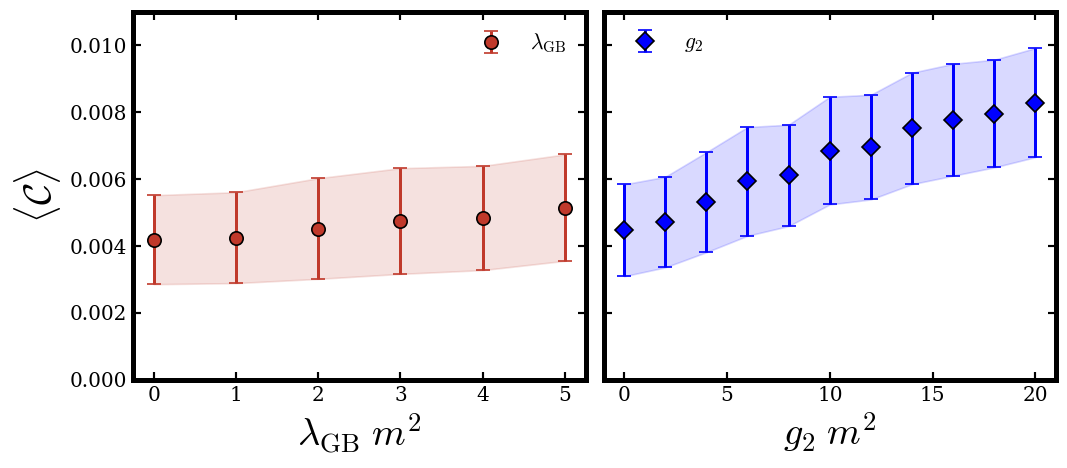

In [16]:
from collections import defaultdict
from scipy.signal import find_peaks
# Reuse `_peak_stats_last_window` from Panel 4b; re-define defensively so this
# cell stands on its own if Panel 4b has not been executed in this session.
try:
    _peak_stats_last_window  # type: ignore[name-defined]
except NameError:
    def _peak_stats_last_window(shifted_ln_a, C, dlna, prominence_rel=0.0,
                                min_separation=1):
        sln = np.asarray(shifted_ln_a, dtype=float)
        C   = np.asarray(C,            dtype=float)
        finite = np.isfinite(sln) & np.isfinite(C)
        if not finite.any():
            return np.nan, np.nan, 0
        sln_f = sln[finite]
        C_f   = C[finite]
        lna_max = sln_f.max()
        mask = sln_f >= (lna_max - dlna)
        if not mask.any():
            return np.nan, np.nan, 0
        C_win = C_f[mask]
        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0
        kw = {}
        if min_separation > 1:
            kw["distance"] = int(min_separation)
        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())
            if rng > 0:
                kw["prominence"] = prominence_rel * rng
        peak_idx, _ = find_peaks(C_win, **kw)
        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0
        peaks = C_win[peak_idx]
        return float(np.mean(peaks)), float(np.std(peaks)), int(peaks.size)


# Same palettes/markers used in Panels 4b and 4c.
_colors_lgb_d  = ["blue", "#f1c40f", "#8e44ad", "#e67e22", "#1abc9c",
                  "#34495e", "#e74c3c", "#27ae60", "#2c3e50", "#c0392b"]
_markers_lgb_d = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]

_colors_g2_d   = ["#c0392b", "#2980b9", "#f1c40f", "#8e44ad", "#e67e22",
                  "#1abc9c", "#34495e", "#e74c3c", "#27ae60", "#2c3e50"]
_markers_g2_d  = ["o", "s", "D", "^", "v", "<", ">", "P", "X"]


def _collect_points(groups, dlna, key_index):
    """For each group, return a sorted list of (x, C_peak_mean, C_peak_std)."""
    out = {}
    for grp_val, keys in groups.items():
        pts = []
        for key in keys:
            d = all_runs[key]
            Cm, Ce, n = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"]["C"]), dlna)
            if not np.isfinite(Cm):
                continue
            pts.append((key[key_index], Cm, Ce))
        if pts:
            out[grp_val] = sorted(pts, key=lambda p: p[0])
    return out


fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# ── Left panel: C vs lambda_GB, one curve per g2 (uses Panel 4c selection) ──
g2_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
        continue
    if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
        continue
    g2_groups[g2].append(key)

g2_points = _collect_points(g2_groups, P4C_DLNA, key_index=0)
for idx, g2_val in enumerate(sorted(g2_points.keys())):
    pts    = g2_points[g2_val]
    color  = _colors_g2_d[idx % len(_colors_g2_d)]
    marker = _markers_g2_d[idx % len(_markers_g2_d)]
    x  = np.array([p[0] for p in pts])
    y  = np.array([p[1] for p in pts])
    ye = np.array([p[2] for p in pts])
    ax_l.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
    ax_l.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                  markeredgecolor="k", markeredgewidth=1.0,
                  capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                  #label=rf"$g_2={g2_val:g}$")
                  label=rf"$\lambda_{{\rm GB}}$")

ax_l.set_xlabel(r"$\lambda_{\rm GB}\;m^2$")
ax_l.set_ylabel(r"$\langle\mathcal{C}\rangle$")
ax_l.set_ylim(0, 0.011)
ax_l.tick_params(which="both", top=True, right=True)
ax_l.legend(loc="best", frameon=False)

# ── Right panel: C vs g2, one curve per lambda_GB (uses Panel 4b selection) ──
lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

lgb_points = _collect_points(lgb_groups, P4B_DLNA, key_index=5)
for idx, lgb_val in enumerate(sorted(lgb_points.keys())):
    pts    = lgb_points[lgb_val]
    color  = _colors_lgb_d[idx % len(_colors_lgb_d)]
    marker = _markers_lgb_d[idx % len(_markers_lgb_d)]
    x  = np.array([p[0] for p in pts])
    y  = np.array([p[1] for p in pts])
    ye = np.array([p[2] for p in pts])
    ax_r.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
    ax_r.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                  markeredgecolor="k", markeredgewidth=1.0,
                  capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                  #label=rf"$\lambda_{{\rm GB}}={lgb_val:g}$")
                  label=rf"$g_2$")

ax_r.set_xlabel(r"$g_2\;m^2$")
ax_r.tick_params(which="both", top=True, right=True)
ax_r.legend(loc="best", frameon=False)

fig.tight_layout()
save_fig(fig, "compactness_vs_lgb_and_g2")
plt.show()

  saved compactness_vs_lgb_and_g2_shaded2.pdf and compactness_vs_lgb_and_g2_shaded2.png


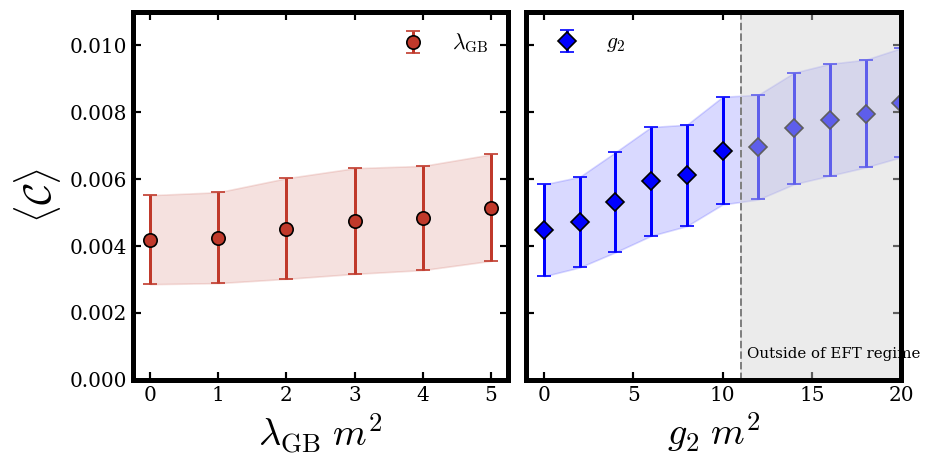

In [17]:
from collections import defaultdict
from scipy.signal import find_peaks
try:
    _peak_stats_last_window  # type: ignore[name-defined]
except NameError:
    def _peak_stats_last_window(shifted_ln_a, C, dlna, prominence_rel=0.0,
                                min_separation=1):
        sln = np.asarray(shifted_ln_a, dtype=float)
        C   = np.asarray(C,            dtype=float)
        finite = np.isfinite(sln) & np.isfinite(C)
        if not finite.any():
            return np.nan, np.nan, 0
        sln_f = sln[finite]
        C_f   = C[finite]
        lna_max = sln_f.max()
        mask = sln_f >= (lna_max - dlna)
        if not mask.any():
            return np.nan, np.nan, 0
        C_win = C_f[mask]
        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0
        kw = {}
        if min_separation > 1:
            kw["distance"] = int(min_separation)
        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())
            if rng > 0:
                kw["prominence"] = prominence_rel * rng
        peak_idx, _ = find_peaks(C_win, **kw)
        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0
        peaks = C_win[peak_idx]
        return float(np.mean(peaks)), float(np.std(peaks)), int(peaks.size)


_colors_lgb_d  = ["blue", "#f1c40f", "#8e44ad", "#e67e22", "#1abc9c",
                  "#34495e", "#e74c3c", "#27ae60", "#2c3e50", "#c0392b"]
_markers_lgb_d = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]

_colors_g2_d   = ["#c0392b", "#2980b9", "#f1c40f", "#8e44ad", "#e67e22",
                  "#1abc9c", "#34495e", "#e74c3c", "#27ae60", "#2c3e50"]
_markers_g2_d  = ["o", "s", "D", "^", "v", "<", ">", "P", "X"]


def _collect_points(groups, dlna, key_index):
    """For each group, return a sorted list of (x, C_peak_mean, C_peak_std)."""
    out = {}
    for grp_val, keys in groups.items():
        pts = []
        for key in keys:
            d = all_runs[key]
            Cm, Ce, n = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"]["C"]), dlna)
            if not np.isfinite(Cm):
                continue
            pts.append((key[key_index], Cm, Ce))
        if pts:
            out[grp_val] = sorted(pts, key=lambda p: p[0])
    return out


fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

# ── Left panel: C vs lambda_GB, one curve per g2 (uses Panel 4c selection) ──
g2_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
        continue
    if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
        continue
    g2_groups[g2].append(key)

g2_points = _collect_points(g2_groups, P4C_DLNA, key_index=0)
for idx, g2_val in enumerate(sorted(g2_points.keys())):
    pts    = g2_points[g2_val]
    color  = _colors_g2_d[idx % len(_colors_g2_d)]
    marker = _markers_g2_d[idx % len(_markers_g2_d)]
    x  = np.array([p[0] for p in pts])
    y  = np.array([p[1] for p in pts])
    ye = np.array([p[2] for p in pts])
    ax_l.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
    ax_l.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                  markeredgecolor="k", markeredgewidth=1.0,
                  capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                  label=rf"$\lambda_{{\rm GB}}$")

ax_l.set_xlabel(r"$\lambda_{\rm GB}\;m^2$")
ax_l.set_ylabel(r"$\langle\mathcal{C}\rangle$")
ax_l.set_ylim(0, 0.011)
ax_l.tick_params(which="both", top=True, right=True)
ax_l.legend(loc="best", frameon=False)

# ── Right panel: C vs g2, one curve per lambda_GB (uses Panel 4b selection) ──
lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

lgb_points = _collect_points(lgb_groups, P4B_DLNA, key_index=5)
for idx, lgb_val in enumerate(sorted(lgb_points.keys())):
    pts    = lgb_points[lgb_val]
    color  = _colors_lgb_d[idx % len(_colors_lgb_d)]
    marker = _markers_lgb_d[idx % len(_markers_lgb_d)]
    x  = np.array([p[0] for p in pts])
    y  = np.array([p[1] for p in pts])
    ye = np.array([p[2] for p in pts])
    ax_r.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
    ax_r.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                  markeredgecolor="k", markeredgewidth=1.0,
                  capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                  label=rf"$g_2$")

# Grey shaded region for g2 >= 10
ax_r.axvline(11, color="grey", ls="--", lw=1.2, zorder=5)
ax_r.axvspan(11, ax_r.get_xlim()[1], color="lightgrey", alpha=0.45, zorder=4)
ax_r.set_frame_on(True)
for spine in ax_r.spines.values():
    spine.set_zorder(10)

ax_r.set_xlabel(r"$g_2\;m^2$")
ax_r.set_xlim(-1,20)
ax_r.tick_params(which="both", top=True, right=True)
ax_r.legend(loc="best", frameon=False)
ax_r.text(0.59, 0.07, "Outside of EFT regime", transform=ax_r.transAxes,va="center", ha="left", fontsize=9, color="black", zorder=11)

fig.tight_layout()
save_fig(fig, "compactness_vs_lgb_and_g2_shaded2")
plt.show()

  saved compactness_vs_lgb_and_g2_normalized.pdf and compactness_vs_lgb_and_g2_normalized.png


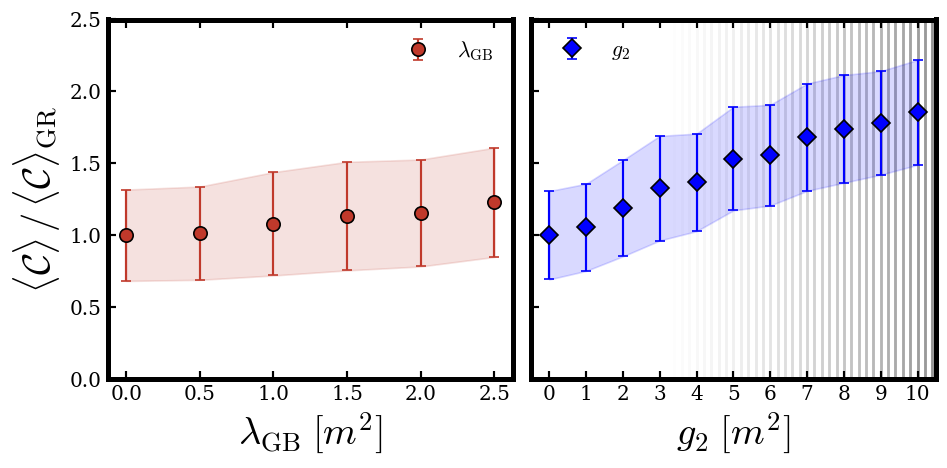

In [18]:
# === Same as the side-by-side compactness plot above, but:                ===
# ===   - y-values normalized to the GR baseline (stored at lgb=0, g2=0)    ===
# ===   - x-axis values divided by 2 (display physical g_2 m^2 / lambda m^2)===

from collections import defaultdict
from scipy.signal import find_peaks
try:
    _peak_stats_last_window  # type: ignore[name-defined]
except NameError:
    def _peak_stats_last_window(shifted_ln_a, C, dlna, prominence_rel=0.0,
                                min_separation=1):
        sln = np.asarray(shifted_ln_a, dtype=float)
        C   = np.asarray(C,            dtype=float)
        finite = np.isfinite(sln) & np.isfinite(C)
        if not finite.any():
            return np.nan, np.nan, 0
        sln_f = sln[finite]
        C_f   = C[finite]
        lna_max = sln_f.max()
        mask = sln_f >= (lna_max - dlna)
        if not mask.any():
            return np.nan, np.nan, 0
        C_win = C_f[mask]
        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0
        kw = {}
        if min_separation > 1:
            kw["distance"] = int(min_separation)
        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())
            if rng > 0:
                kw["prominence"] = prominence_rel * rng
        peak_idx, _ = find_peaks(C_win, **kw)
        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0
        peaks = C_win[peak_idx]
        return float(np.mean(peaks)), float(np.std(peaks)), int(peaks.size)


_colors_lgb_d  = ["blue", "#f1c40f", "#8e44ad", "#e67e22", "#1abc9c",
                  "#34495e", "#e74c3c", "#27ae60", "#2c3e50", "#c0392b"]
_markers_lgb_d = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]

_colors_g2_d   = ["#c0392b", "#2980b9", "#f1c40f", "#8e44ad", "#e67e22",
                  "#1abc9c", "#34495e", "#e74c3c", "#27ae60", "#2c3e50"]
_markers_g2_d  = ["o", "s", "D", "^", "v", "<", ">", "P", "X"]


def _C_GR_for(P_MU, P_BETA, P_AMP, P_WIDTH, P_DLNA):
    """Peak-mean compactness for the GR run (lgb=0, g2=0) matching the
    given (mu, beta, amp, width) cut. Returns NaN if no such run exists."""
    for k in all_runs:
        lgb_, mu_, beta_, amp_, width_, g2_ = k
        if lgb_ != 0 or g2_ != 0:
            continue
        if (mu_ == P_MU and beta_ == P_BETA and amp_ == P_AMP
                and width_ == P_WIDTH):
            d = all_runs[k]
            Cm, _, _ = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"]["C"]), P_DLNA)
            return float(Cm) if np.isfinite(Cm) and Cm > 0 else np.nan
    return np.nan


def _collect_points(groups, dlna, key_index):
    """For each group, return a sorted list of (x, C_peak_mean, C_peak_std)."""
    out = {}
    for grp_val, keys in groups.items():
        pts = []
        for key in keys:
            d = all_runs[key]
            Cm, Ce, n = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"]["C"]), dlna)
            if not np.isfinite(Cm):
                continue
            pts.append((key[key_index], Cm, Ce))
        if pts:
            out[grp_val] = sorted(pts, key=lambda p: p[0])
    return out


fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

# GR baselines (one per panel cut, in case P4B and P4C use different windows).
C_GR_left  = _C_GR_for(P4C_MU, P4C_BETA, P4C_AMP, P4C_WIDTH, P4C_DLNA)
C_GR_right = _C_GR_for(P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
if not np.isfinite(C_GR_left):
    print("[warn] no GR run found for P4C cut; left panel falls back to C_GR=1.")
    C_GR_left = 1.0
if not np.isfinite(C_GR_right):
    print("[warn] no GR run found for P4B cut; right panel falls back to C_GR=1.")
    C_GR_right = 1.0

# ── Left panel: C/C_GR vs lambda_GB/2, one curve per g2 (uses Panel 4c selection) ──
g2_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
        continue
    if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
        continue
    g2_groups[g2].append(key)

g2_points = _collect_points(g2_groups, P4C_DLNA, key_index=0)
for idx, g2_val in enumerate(sorted(g2_points.keys())):
    pts    = g2_points[g2_val]
    color  = _colors_g2_d[idx % len(_colors_g2_d)]
    marker = _markers_g2_d[idx % len(_markers_g2_d)]
    x  = np.array([p[0] for p in pts]) / 2.0
    y  = np.array([p[1] for p in pts]) / C_GR_left
    ye = np.array([p[2] for p in pts]) / C_GR_left
    ax_l.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
    ax_l.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                  markeredgecolor="k", markeredgewidth=1.0,
                  capsize=3, capthick=1.0, elinewidth=1.3, markersize=8,
                  label=rf"$\lambda_{{\rm GB}}$")

#ax_l.axhline(1.0, color="black", ls=":", lw=1.2, alpha=0)
ax_l.set_xlabel(r"$\lambda_{\rm GB}\;[m^2]$")
ax_l.set_ylabel(r"$\langle\mathcal{C}\rangle\,/\,\langle\mathcal{C}\rangle_{\rm GR}$")
ax_l.set_ylim(0.5, 2.3)
ax_l.tick_params(which="both", top=True, right=False)
ax_l.legend(loc="best", frameon=False)

# ── Right panel: C/C_GR vs g2/2, one curve per lambda_GB (uses Panel 4b selection) ──
lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

lgb_points = _collect_points(lgb_groups, P4B_DLNA, key_index=5)
for idx, lgb_val in enumerate(sorted(lgb_points.keys())):
    pts    = lgb_points[lgb_val]
    color  = _colors_lgb_d[idx % len(_colors_lgb_d)]
    marker = _markers_lgb_d[idx % len(_markers_lgb_d)]
    x  = np.array([p[0] for p in pts]) / 2.0
    y  = np.array([p[1] for p in pts]) / C_GR_right
    ye = np.array([p[2] for p in pts]) / C_GR_right
    ax_r.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
    ax_r.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                  markeredgecolor="k", markeredgewidth=1.0,
                  capsize=3, capthick=1.0, elinewidth=1.3, markersize=8,
                  label=rf"$g_2$")

# Grey shaded "Outside of EFT regime" — boundary at g2_stored=11 ⇒ g2/2 = 5.5
#_eft_x = 5.5
_eft_x = np.arange(3, 12, 0.2)
colors = plt.cm.Greys(np.linspace(-0.01, 0.6, len(_eft_x)))
#ax_r.axhline(1.0, color="black", ls=":", lw=1.2, alpha=0.1)
for i in range(len(_eft_x)):
    ax_r.axvline(_eft_x[i], color=colors[i], ls="-", lw=1.7, zorder=0.2)
ax_r.set_xlim(-0.5, 10.5)
ax_r.set_xticks(np.arange(0, 11, 1))
ax_r.set_yticks(np.arange(0, 2.8, 0.5))
#ax_r.axvspan(_eft_x, ax_r.get_xlim()[1], color="lightgrey", alpha=0.45, zorder=4)
ax_r.set_frame_on(True)
for spine in ax_r.spines.values():
    spine.set_zorder(10)

ax_r.set_xlabel(r"$g_2\;[m^2]$")
ax_r.tick_params(which="both", top=True, right=False)
ax_r.legend(loc="best", frameon=False)
#ax_r.text(0.55, 0.07, "Outside of EFT regime", transform=ax_r.transAxes,va="center", ha="left", fontsize=9, color="black", zorder=11)

fig.tight_layout()
save_fig(fig, "compactness_vs_lgb_and_g2_normalized")
plt.show()

  saved compactness_vs_lgb_and_g2_normalized2.pdf and compactness_vs_lgb_and_g2_normalized2.png


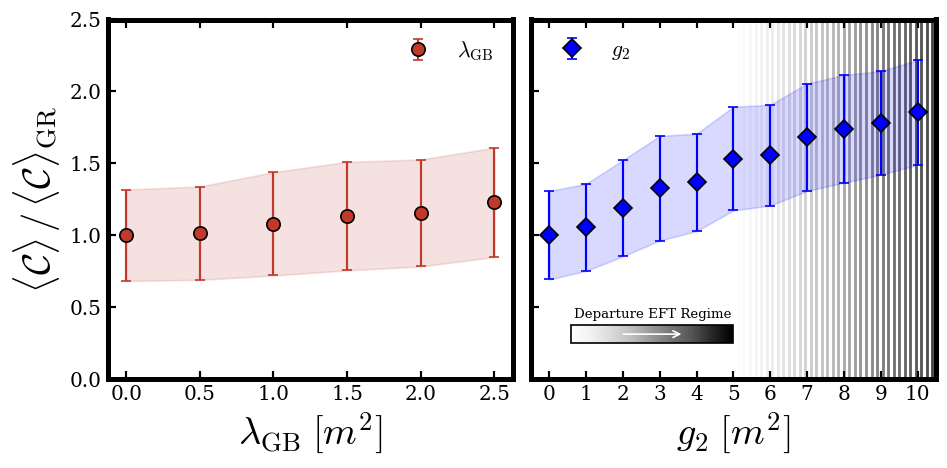

In [19]:
from collections import defaultdict
from scipy.signal import find_peaks
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

try:
    _peak_stats_last_window  # type: ignore[name-defined]

except NameError:

    def _peak_stats_last_window(
        shifted_ln_a,
        C,
        dlna,
        prominence_rel=0.0,
        min_separation=1
    ):

        sln = np.asarray(shifted_ln_a, dtype=float)
        C   = np.asarray(C, dtype=float)

        finite = np.isfinite(sln) & np.isfinite(C)

        if not finite.any():
            return np.nan, np.nan, 0

        sln_f = sln[finite]
        C_f   = C[finite]

        lna_max = sln_f.max()
        mask = sln_f >= (lna_max - dlna)

        if not mask.any():
            return np.nan, np.nan, 0

        C_win = C_f[mask]

        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0

        kw = {}

        if min_separation > 1:
            kw["distance"] = int(min_separation)

        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())

            if rng > 0:
                kw["prominence"] = prominence_rel * rng

        peak_idx, _ = find_peaks(C_win, **kw)

        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0

        peaks = C_win[peak_idx]

        return (
            float(np.mean(peaks)),
            float(np.std(peaks)),
            int(peaks.size)
        )


_colors_lgb_d = [
    "blue",
    "#f1c40f",
    "#8e44ad",
    "#e67e22",
    "#1abc9c",
    "#34495e",
    "#e74c3c",
    "#27ae60",
    "#2c3e50",
    "#c0392b"
]

_markers_lgb_d = [
    "D", "s", "D", "^", "v", "<", ">", "P", "X"
]

_colors_g2_d = [
    "#c0392b",
    "#2980b9",
    "#f1c40f",
    "#8e44ad",
    "#e67e22",
    "#1abc9c",
    "#34495e",
    "#e74c3c",
    "#27ae60",
    "#2c3e50"
]

_markers_g2_d = [
    "o", "s", "D", "^", "v", "<", ">", "P", "X"
]


def _C_GR_for(P_MU, P_BETA, P_AMP, P_WIDTH, P_DLNA):
    """
    Peak-mean compactness for the GR run (lgb=0, g2=0)
    matching the given (mu, beta, amp, width) cut.
    Returns NaN if no such run exists.
    """

    for k in all_runs:

        lgb_, mu_, beta_, amp_, width_, g2_ = k

        if lgb_ != 0 or g2_ != 0:
            continue

        if (
            mu_ == P_MU
            and beta_ == P_BETA
            and amp_ == P_AMP
            and width_ == P_WIDTH
        ):

            d = all_runs[k]

            Cm, _, _ = _peak_stats_last_window(
                d["shifted_ln_a"],
                np.asarray(d["osc"]["C"]),
                P_DLNA
            )

            return (
                float(Cm)
                if np.isfinite(Cm) and Cm > 0
                else np.nan
            )

    return np.nan


def _collect_points(groups, dlna, key_index):
    """
    For each group, return a sorted list of
    (x, C_peak_mean, C_peak_std).
    """

    out = {}

    for grp_val, keys in groups.items():

        pts = []

        for key in keys:

            d = all_runs[key]

            Cm, Ce, n = _peak_stats_last_window(
                d["shifted_ln_a"],
                np.asarray(d["osc"]["C"]),
                dlna
            )

            if not np.isfinite(Cm):
                continue

            pts.append(
                (
                    key[key_index],
                    Cm,
                    Ce
                )
            )

        if pts:
            out[grp_val] = sorted(
                pts,
                key=lambda p: p[0]
            )

    return out


# ============================================================
# Figure
# ============================================================

fig, (ax_l, ax_r) = plt.subplots(
    1,
    2,
    figsize=(8, 4),
    sharey=True
)


# ============================================================
# GR baselines
# ============================================================

C_GR_left = _C_GR_for(
    P4C_MU,
    P4C_BETA,
    P4C_AMP,
    P4C_WIDTH,
    P4C_DLNA
)

C_GR_right = _C_GR_for(
    P4B_MU,
    P4B_BETA,
    P4B_AMP,
    P4B_WIDTH,
    P4B_DLNA
)

if not np.isfinite(C_GR_left):

    print(
        "[warn] no GR run found for P4C cut; "
        "left panel falls back to C_GR=1."
    )

    C_GR_left = 1.0


if not np.isfinite(C_GR_right):

    print(
        "[warn] no GR run found for P4B cut; "
        "right panel falls back to C_GR=1."
    )

    C_GR_right = 1.0


# ============================================================
# LEFT PANEL
# C/C_GR vs lambda_GB
# one curve per g2
# ============================================================

g2_groups = defaultdict(list)

for key in all_runs:

    lgb, mu, beta, amp, width, g2 = key

    if (
        mu != P4C_MU
        or beta != P4C_BETA
        or amp != P4C_AMP
        or width != P4C_WIDTH
    ):
        continue

    if (
        g2 not in P4C_G2_SHOW
        or lgb not in P4C_LGB_SHOW
    ):
        continue

    g2_groups[g2].append(key)


g2_points = _collect_points(
    g2_groups,
    P4C_DLNA,
    key_index=0
)


for idx, g2_val in enumerate(
    sorted(g2_points.keys())
):

    pts = g2_points[g2_val]

    color = _colors_g2_d[
        idx % len(_colors_g2_d)
    ]

    marker = _markers_g2_d[
        idx % len(_markers_g2_d)
    ]

    x = np.array(
        [p[0] for p in pts]
    ) / 2.0

    y = np.array(
        [p[1] for p in pts]
    ) / C_GR_left

    ye = np.array(
        [p[2] for p in pts]
    ) / C_GR_left


    ax_l.fill_between(
        x,
        y - ye,
        y + ye,
        color=color,
        alpha=0.15
    )


    ax_l.errorbar(
        x,
        y,
        yerr=ye,
        fmt=marker,
        color=color,
        markeredgecolor="k",
        markeredgewidth=1.0,
        capsize=3,
        capthick=1.0,
        elinewidth=1.3,
        markersize=8,
        label=rf"$\lambda_{{\rm GB}}$"
    )


ax_l.set_xlabel(
    r"$\lambda_{\rm GB}\;[m^2]$"
)

ax_l.set_ylabel(
    r"$\langle\mathcal{C}\rangle"
    r"\,/\,"
    r"\langle\mathcal{C}\rangle_{\rm GR}$"
)

ax_l.set_ylim(
    0.5,
    2.3
)

ax_l.tick_params(
    which="both",
    top=True,
    right=False
)

ax_l.legend(
    loc="best",
    frameon=False
)


# ============================================================
# RIGHT PANEL
# C/C_GR vs g2
# one curve per lambda_GB
# ============================================================

lgb_groups = defaultdict(list)

for key in all_runs:

    lgb, mu, beta, amp, width, g2 = key

    if (
        mu != P4B_MU
        or beta != P4B_BETA
        or amp != P4B_AMP
        or width != P4B_WIDTH
    ):
        continue

    if (
        lgb not in P4B_LGB_SHOW
        or g2 not in P4B_G2_SHOW
    ):
        continue

    lgb_groups[lgb].append(key)


lgb_points = _collect_points(
    lgb_groups,
    P4B_DLNA,
    key_index=5
)


for idx, lgb_val in enumerate(
    sorted(lgb_points.keys())
):

    pts = lgb_points[lgb_val]

    color = _colors_lgb_d[
        idx % len(_colors_lgb_d)
    ]

    marker = _markers_lgb_d[
        idx % len(_markers_lgb_d)
    ]

    x = np.array(
        [p[0] for p in pts]
    ) / 2.0

    y = np.array(
        [p[1] for p in pts]
    ) / C_GR_right

    ye = np.array(
        [p[2] for p in pts]
    ) / C_GR_right


    ax_r.fill_between(
        x,
        y - ye,
        y + ye,
        color=color,
        alpha=0.15
    )


    ax_r.errorbar(
        x,
        y,
        yerr=ye,
        fmt=marker,
        color=color,
        markeredgecolor="k",
        markeredgewidth=1.0,
        capsize=3,
        capthick=1.0,
        elinewidth=1.3,
        markersize=8,
        label=rf"$g_2$"
    )


# ============================================================
# EFT gradient
# ============================================================

_eft_x = np.arange(
    5,
    12,
    0.15)

cmap = plt.cm.Greys

norm = Normalize(
    vmin=_eft_x.min(),
    vmax=_eft_x.max()
)


for xval in _eft_x:

    ax_r.axvline(
        xval,
        color=cmap(norm(xval)),
        ls="-",
        lw=1.7,
        zorder=0.2
    )


# ============================================================
# Right-panel formatting
# ============================================================

ax_r.set_xlim(
    -0.5,
    10.5
)

ax_r.set_xticks(
    np.arange(
        0,
        11,
        1
    )
)

ax_r.set_yticks(
    np.arange(
        0,
        2.8,
        0.5
    )
)

ax_r.set_xlabel(
    r"$g_2\;[m^2]$"
)

ax_r.tick_params(
    which="both",
    top=True,
    right=False
)


# Keep plot frame above the EFT gradient
ax_r.set_frame_on(True)

for spine in ax_r.spines.values():
    spine.set_zorder(10)


ax_r.legend(
    loc="best",
    frameon=False
)


# ============================================================
# Horizontal EFT colorbar inside right panel
# ============================================================

sm = ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])


# [left, bottom, width, height]
# all relative to the right-hand axes
cax = ax_r.inset_axes(
    [
        0.1,
        0.1,
        0.4,
        0.05
    ]
)


cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)


cbar.set_ticks(
    []
)

cbar.ax.tick_params(
    axis="x",
    labelsize=8,
    length=3,
    pad=5
)

cbar.set_label(
    r"Departure EFT Regime",
    fontsize=8,
    labelpad=-21
)
cbar.outline.set_linewidth(1)

cbar.ax.annotate(
    "",
    xy=(0.7, 0.5),      # arrow head
    xytext=(0.3, 0.5),  # arrow start
    xycoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        color="white",
        lw=1.0
    ),
    zorder=10
)


# ============================================================
# Layout / save
# ============================================================

fig.tight_layout()

save_fig(
    fig,
    "compactness_vs_lgb_and_g2_normalized2"
)

plt.show()

In [20]:
### --- Panel 4 selection (edit me) ---
PLOT4_KEYS = select_runs(
    lgb   = [0],
    mu    = [0.08],
    beta  = [250],
    amp   = [-0.02],
    width = [3.0],
    g2    = [0,1,2,3,4,5,6,7,8,9,10],
)
PLOT4_NAME = "rho_C_WCC_hyp"

PLOT4_USE_TAB_COLORS = True   # False = blue ramp; True = tab10 cycle (tab:blue, orange, green, ...)

# Optional: highlight a specific run in a distinct color, plotted behind the others.
# Set to a key tuple e.g. (0, 0.08, 250, -0.02, 3.0, 10) or None to disable.
#PLOT4_HIGHLIGHT_KEY   = None
PLOT4_HIGHLIGHT_KEY   = (0, 0.08, 250, -0.02, 3.0, 34)
PLOT4_HIGHLIGHT_COLOR = "red"
PLOT4_HIGHLIGHT_LW    = 2
PLOT4_HIGHLIGHT_ALPHA = 0.3

R_WCC_MAX           = 100.0   # only consider r in (0, R_WCC_MAX] for WCC / hyperbolicity maxima
FORCE_EFT_RECOMPUTE = False   # True = ignore any cached eft_diagnostics.npz and recompute

# Middle panel (weak-coupling condition) y-axis options.
PLOT4_WCC_LOG          = True            # True -> log y; False -> linear y
PLOT4_WCC_YLIM_LOG     = (1e-3, 1e1)     # used when PLOT4_WCC_LOG is True
PLOT4_WCC_YLIM_LINEAR  = (0.0, 1.2)      # used when PLOT4_WCC_LOG is False

print(f"{len(PLOT4_KEYS)} run(s) selected for Panel 4:")
for k in PLOT4_KEYS:
    print(" ", k, " coupling=", all_runs[k]["coupling"], " g2=", k[5])

# Compute / load EFT diagnostics only for the selected runs
for k in PLOT4_KEYS:
    d = all_runs[k]
    if "eft" in d and not FORCE_EFT_RECOMPUTE:
        continue
    run_dir  = d["run_dir"]
    eft_path = os.path.join(run_dir, "eft_diagnostics.npz")
    if os.path.exists(eft_path) and not FORCE_EFT_RECOMPUTE:
        d["eft"] = dict(np.load(eft_path, allow_pickle=True))
        print(f"  [EFT] loaded cache for {d['tag']}")
    else:
        sol_i    = np.load(os.path.join(run_dir, "solution.npy"))
        matter_i = ScalarMatter(scalar_mu, d["mu"])
        sv_i     = StateVector(matter_i)
        spacing_i = CubicSpacing(**CubicSpacing.get_parameters(
            d["run_r_max"], d["run_min_dr"], d["run_max_dr"]))
        grid_i   = Grid(spacing_i, sv_i)
        bg_i     = FlatSphericalBackground(grid_i.r)
        lgb_k, mu_k, beta_k, amp_k, width_k, g2_k = k
        params = (lgb_k, a_mg, b_mg, chi0, d["coupling"], g2_k)
        eft = get_eft_diagnostic(
            sol_i, d["t"], grid_i, bg_i,
            ScalarMatter(scalar_mu, d["mu"]),
            params,
        )
        np.savez(eft_path, **eft)
        d["eft"] = eft
        del sol_i
        verb = "recomputed" if FORCE_EFT_RECOMPUTE else "computed"
        print(f"  [EFT] {verb} & cached for {d['tag']}")


8 run(s) selected for Panel 4:
  (0.0, 0.08, 250.0, -0.02, 3.0, 0.0)  coupling= quadratic  g2= 0.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 1.0)  coupling= quadratic  g2= 1.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 2.0)  coupling= quadratic  g2= 2.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 3.0)  coupling= quadratic  g2= 3.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 4.0)  coupling= quadratic  g2= 4.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 5.0)  coupling= quadratic  g2= 5.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 6.0)  coupling= quadratic  g2= 6.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 10.0)  coupling= quadratic  g2= 10.0
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g20
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g21
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g22
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g23
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g24
  [EFT] loaded cac

[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0 N_peaks = 0
[EFT] loaded cache for lgb1_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT colour] (1.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0169974 N_peaks = 180
[EFT] loaded cache for lgb2_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT colour] (2.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0195093 N_peaks = 187
[EFT] loaded cache for lgb3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT colour] (3.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0212061 N_peaks = 188
[EFT] loaded cache for lgb4_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT colour] (4.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0262164 N_peaks = 172
[EFT] loaded cache for lgb5.0_mu0.08_a0.0_b0.0_amp-0.02_R3.0_dr0.041666666666666664_quadratic_0
[EFT colour] (5.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0210978 N_peaks = 170
[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0 N_p

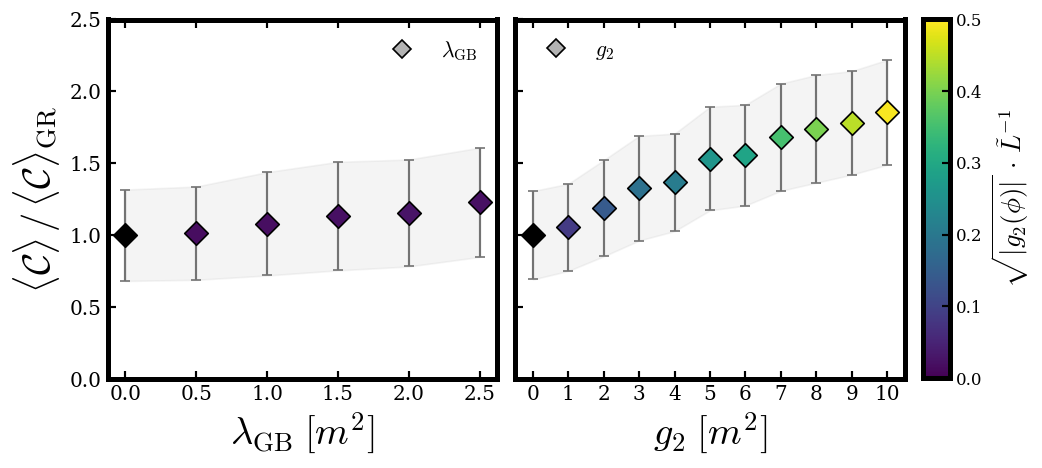

In [21]:
from collections import defaultdict

import os
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import find_peaks
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D


# ============================================================
# SETTINGS FOR THE EFT COLOUR CODING
# ============================================================

# Radial region used when taking max_r of the EFT diagnostic
EFT_R_MAX = 100.0

# False -> use eft_diagnostics.npz if it exists
# True  -> recompute EFT diagnostics from solution.npy
EFT_FORCE_RECOMPUTE = False

# Linear colour scale for the markers
EFT_COLOR_VMIN = 0.0
EFT_COLOR_VMAX = 0.5

# Colour map
EFT_CMAP = plt.cm.viridis

# Peak finding parameters for the EFT time series
EFT_PEAK_PROMINENCE_REL = 0.0
EFT_PEAK_MIN_SEPARATION = 1

# Reference value for leaving the EFT regime
EFT_THRESHOLD = 0.5


# ============================================================
# PEAK STATISTICS
# ============================================================

try:
    _peak_stats_last_window  # type: ignore[name-defined]

except NameError:

    def _peak_stats_last_window(
        shifted_ln_a,
        C,
        dlna,
        prominence_rel=0.0,
        min_separation=1,
    ):
        """
        Find local maxima in the final dlna interval of shifted_ln_a.

        Returns
        -------
        mean_peaks : float
            Mean value of the peaks.
        std_peaks : float
            Standard deviation of the peaks.
        n_peaks : int
            Number of detected peaks.

        If no peak is found, the maximum value in the window is returned.
        """

        sln = np.asarray(shifted_ln_a, dtype=float)
        C = np.asarray(C, dtype=float)

        # Protect against slightly different array lengths
        n = min(len(sln), len(C))
        sln = sln[:n]
        C = C[:n]

        finite = np.isfinite(sln) & np.isfinite(C)

        if not finite.any():
            return np.nan, np.nan, 0

        sln_f = sln[finite]
        C_f = C[finite]

        lna_max = sln_f.max()

        mask = sln_f >= (lna_max - dlna)

        if not mask.any():
            return np.nan, np.nan, 0

        C_win = C_f[mask]

        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0

        kw = {}

        if min_separation > 1:
            kw["distance"] = int(min_separation)

        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())

            if rng > 0:
                kw["prominence"] = prominence_rel * rng

        peak_idx, _ = find_peaks(C_win, **kw)

        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0

        peaks = C_win[peak_idx]

        return (
            float(np.mean(peaks)),
            float(np.std(peaks)),
            int(peaks.size),
        )


# ============================================================
# COMPUTE / LOAD EFT DIAGNOSTICS
# ============================================================

def _ensure_eft_for_key(key):
    """
    Make sure all_runs[key]["eft"] exists.

    If eft_diagnostics.npz exists, load it.
    Otherwise calculate it and cache it.
    """

    d = all_runs[key]

    if "eft" in d and d["eft"] is not None and not EFT_FORCE_RECOMPUTE:
        return d["eft"]

    run_dir = d["run_dir"]

    eft_path = os.path.join(
        run_dir,
        "eft_diagnostics.npz",
    )

    # --------------------------------------------------------
    # Load existing cache
    # --------------------------------------------------------

    if os.path.exists(eft_path) and not EFT_FORCE_RECOMPUTE:

        d["eft"] = dict(
            np.load(
                eft_path,
                allow_pickle=True,
            )
        )

        print(f"[EFT] loaded cache for {d['tag']}")

        return d["eft"]

    # --------------------------------------------------------
    # Otherwise calculate diagnostic
    # --------------------------------------------------------

    print(f"[EFT] computing diagnostic for {d['tag']}")

    sol_i = np.load(
        os.path.join(
            run_dir,
            "solution.npy",
        )
    )

    matter_i = ScalarMatter(
        scalar_mu,
        d["mu"],
    )

    sv_i = StateVector(matter_i)

    spacing_i = CubicSpacing(
        **CubicSpacing.get_parameters(
            d["run_r_max"],
            d["run_min_dr"],
            d["run_max_dr"],
        )
    )

    grid_i = Grid(
        spacing_i,
        sv_i,
    )

    bg_i = FlatSphericalBackground(
        grid_i.r
    )

    lgb_k, mu_k, beta_k, amp_k, width_k, g2_k = key

    params = (
        lgb_k,
        a_mg,
        b_mg,
        chi0,
        d["coupling"],
        g2_k,
    )

    eft = get_eft_diagnostic(
        sol_i,
        d["t"],
        grid_i,
        bg_i,
        ScalarMatter(
            scalar_mu,
            d["mu"],
        ),
        params,
    )

    np.savez(
        eft_path,
        **eft,
    )

    d["eft"] = eft

    del sol_i

    print(f"[EFT] computed and cached for {d['tag']}")

    return eft


# ============================================================
# TURN FULL EFT DIAGNOSTIC INTO ONE TIME SERIES W_EFT(t)
# ============================================================

def _eft_time_series(key):
    """
    Construct one EFT weak-coupling diagnostic W_EFT(t).

    For each active coupling:

        W_GB(t) = max_r wc_lambda_bare(t,r)

        W_g2(t) = max_r wc_g2_bare(t,r)

    with 0 < r <= EFT_R_MAX.

    If both couplings are active:

        W_EFT(t) = max(W_GB(t), W_g2(t))

    For GR, W_EFT = 0.
    """

    d = all_runs[key]

    lgb, mu, beta, amp, width, g2 = key

    # Pure GR
    if lgb == 0 and g2 == 0:
        ntime = len(d["shifted_ln_a"])
        return np.zeros(ntime, dtype=float)

    eft = _ensure_eft_for_key(key)

    if eft is None or "r" not in eft:
        return None

    r = np.asarray(
        eft["r"],
        dtype=float,
    )

    r_mask = (
        np.isfinite(r)
        & (r > 0)
        & (r <= EFT_R_MAX)
    )

    if not r_mask.any():
        return None

    active_diagnostics = []

    # --------------------------------------------------------
    # Gauss-Bonnet weak-coupling diagnostic
    # --------------------------------------------------------

    if lgb != 0 and "wc_lambda_bare" in eft:

        wc_lambda = np.asarray(
            eft["wc_lambda_bare"],
            dtype=float,
        )

        wc_lambda_t = np.nanmax(
            wc_lambda[:, r_mask],
            axis=1,
        )

        active_diagnostics.append(
            wc_lambda_t
        )

    # --------------------------------------------------------
    # g2 weak-coupling diagnostic
    # --------------------------------------------------------

    if g2 != 0 and "wc_g2_bare" in eft:

        wc_g2 = np.asarray(
            eft["wc_g2_bare"],
            dtype=float,
        )

        wc_g2_t = np.nanmax(
            wc_g2[:, r_mask],
            axis=1,
        )

        active_diagnostics.append(
            wc_g2_t
        )

    if len(active_diagnostics) == 0:
        return None

    # Make sure all arrays have the same length
    n = min(
        len(arr)
        for arr in active_diagnostics
    )

    active_diagnostics = [
        arr[:n]
        for arr in active_diagnostics
    ]

    if len(active_diagnostics) == 1:

        W_eft = active_diagnostics[0]

    else:

        W_eft = np.nanmax(
            np.vstack(active_diagnostics),
            axis=0,
        )

    return W_eft


# ============================================================
# ONE EFT NUMBER PER RUN
# ============================================================

def _eft_peak_mean_for_key(key, dlna):
    """
    Return the mean of the temporal peaks of W_EFT(t)
    over the final dlna interval.

    This value determines the marker colour.
    """

    lgb, mu, beta, amp, width, g2 = key

    # GR diagnostic = 0
    if lgb == 0 and g2 == 0:
        return 0.0, 0.0, 0

    d = all_runs[key]

    W_eft = _eft_time_series(key)

    if W_eft is None:
        return np.nan, np.nan, 0

    shifted_ln_a = np.asarray(
        d["shifted_ln_a"],
        dtype=float,
    )

    n = min(
        len(shifted_ln_a),
        len(W_eft),
    )

    shifted_ln_a = shifted_ln_a[:n]
    W_eft = np.asarray(
        W_eft[:n],
        dtype=float,
    )

    return _peak_stats_last_window(
        shifted_ln_a,
        W_eft,
        dlna,
        prominence_rel=EFT_PEAK_PROMINENCE_REL,
        min_separation=EFT_PEAK_MIN_SEPARATION,
    )


# ============================================================
# GR COMPACTNESS BASELINE
# ============================================================

def _C_GR_for(
    P_MU,
    P_BETA,
    P_AMP,
    P_WIDTH,
    P_DLNA,
):
    """
    Peak-mean compactness for the matching GR run.
    """

    for k in all_runs:

        lgb_, mu_, beta_, amp_, width_, g2_ = k

        if lgb_ != 0 or g2_ != 0:
            continue

        if (
            mu_ == P_MU
            and beta_ == P_BETA
            and amp_ == P_AMP
            and width_ == P_WIDTH
        ):

            d = all_runs[k]

            Cm, _, _ = _peak_stats_last_window(
                d["shifted_ln_a"],
                np.asarray(
                    d["osc"]["C"]
                ),
                P_DLNA,
            )

            return (
                float(Cm)
                if np.isfinite(Cm) and Cm > 0
                else np.nan
            )

    return np.nan


# ============================================================
# COLLECT COMPACTNESS + EFT INFORMATION
# ============================================================

def _collect_points(groups, dlna, key_index):
    """
    For each group return:

        (
            x_parameter,
            C_peak_mean,
            C_peak_std,
            EFT_peak_mean,
            EFT_peak_std,
            key
        )
    """

    out = {}

    for grp_val, keys in groups.items():

        pts = []

        for key in keys:

            d = all_runs[key]

            # Compactness statistics
            Cm, Ce, nC = _peak_stats_last_window(
                d["shifted_ln_a"],
                np.asarray(
                    d["osc"]["C"]
                ),
                dlna,
            )

            if not np.isfinite(Cm):
                continue

            # EFT statistics
            Em, Ee, nE = _eft_peak_mean_for_key(
                key,
                dlna,
            )

            pts.append(
                (
                    key[key_index],
                    Cm,
                    Ce,
                    Em,
                    Ee,
                    key,
                )
            )

            print(
                "[EFT colour]",
                key,
                f"<W_EFT>_peaks = {Em:.6g}",
                f"N_peaks = {nE}",
            )

        if pts:

            out[grp_val] = sorted(
                pts,
                key=lambda p: p[0],
            )

    return out


# ============================================================
# MARKER SHAPES
# ============================================================

_markers_lgb_d = [
    "D",
    "s",
    "D",
    "^",
    "v",
    "<",
    ">",
    "P",
    "X",
]

_markers_g2_d = [
    "D",
    "s",
    "D",
    "^",
    "v",
    "<",
    ">",
    "P",
    "X",
]


# ============================================================
# LINEAR COLOUR NORMALISATION
# ============================================================

eft_norm = Normalize(
    vmin=EFT_COLOR_VMIN,
    vmax=EFT_COLOR_VMAX,
    clip=True,
)


def _eft_marker_colour(value):
    """
    Convert EFT diagnostic into marker colour.

    GR -> black
    missing -> light grey
    EFT diagnostic -> linear viridis scale
    """

    if not np.isfinite(value):
        return "lightgrey"

    if value <= 0:
        return "black"

    return EFT_CMAP(
        eft_norm(value)
    )


# ============================================================
# CREATE FIGURE
# ============================================================

fig, (ax_l, ax_r) = plt.subplots(
    1,
    2,
    figsize=(9, 4),
    sharey=True,
)


# ============================================================
# GR BASELINES
# ============================================================

C_GR_left = _C_GR_for(
    P4C_MU,
    P4C_BETA,
    P4C_AMP,
    P4C_WIDTH,
    P4C_DLNA,
)

C_GR_right = _C_GR_for(
    P4B_MU,
    P4B_BETA,
    P4B_AMP,
    P4B_WIDTH,
    P4B_DLNA,
)

if not np.isfinite(C_GR_left):

    print(
        "[warn] no GR run found for P4C cut; "
        "left panel falls back to C_GR = 1."
    )

    C_GR_left = 1.0


if not np.isfinite(C_GR_right):

    print(
        "[warn] no GR run found for P4B cut; "
        "right panel falls back to C_GR = 1."
    )

    C_GR_right = 1.0


# ============================================================
# LEFT PANEL
#
# C/C_GR vs lambda_GB/2
# one marker family per g2
# ============================================================

g2_groups = defaultdict(list)

for key in all_runs:

    lgb, mu, beta, amp, width, g2 = key

    if (
        mu != P4C_MU
        or beta != P4C_BETA
        or amp != P4C_AMP
        or width != P4C_WIDTH
    ):
        continue

    if (
        g2 not in P4C_G2_SHOW
        or lgb not in P4C_LGB_SHOW
    ):
        continue

    g2_groups[g2].append(key)


g2_points = _collect_points(
    g2_groups,
    P4C_DLNA,
    key_index=0,
)


for idx, g2_val in enumerate(
    sorted(g2_points.keys())
):

    pts = g2_points[g2_val]

    marker = _markers_g2_d[
        idx % len(_markers_g2_d)
    ]

    x = np.array(
        [p[0] for p in pts],
        dtype=float,
    ) / 2.0

    y = np.array(
        [p[1] for p in pts],
        dtype=float,
    ) / C_GR_left

    ye = np.array(
        [p[2] for p in pts],
        dtype=float,
    ) / C_GR_left

    eft_values = np.array(
        [p[3] for p in pts],
        dtype=float,
    )

    # Uncertainty band
    ax_l.fill_between(
        x,
        y - ye,
        y + ye,
        color="0.65",
        alpha=0.12,
        zorder=1,
    )

    # Error bars
    ax_l.errorbar(
        x,
        y,
        yerr=ye,
        fmt="none",
        ecolor="0.45",
        capsize=3,
        capthick=1.0,
        elinewidth=1.3,
        zorder=3,
    )

    # Individually EFT-coloured markers
    for xi, yi, eft_val in zip(
        x,
        y,
        eft_values,
    ):

        ax_l.scatter(
            xi,
            yi,
            s=100,
            marker=marker,
            facecolor=_eft_marker_colour(eft_val),
            edgecolor="black",
            linewidth=1.0,
            zorder=5,
        )


# Dummy legend marker
left_legend_handle = Line2D(
    [0],
    [0],
    marker=_markers_g2_d[0],
    linestyle="none",
    markerfacecolor="0.7",
    markeredgecolor="black",
    markersize=8,
    label=rf"$\lambda_{{\rm GB}}$",
)

ax_l.set_xlabel(
    r"$\lambda_{\rm GB}\;[m^2]$"
)

ax_l.set_ylabel(
    r"$\langle\mathcal{C}\rangle"
    r"\,/\,"
    r"\langle\mathcal{C}\rangle_{\rm GR}$"
)

ax_l.set_ylim(
    0.5,
    2.3,
)

ax_l.tick_params(
    which="both",
    top=True,
    right=False,
)

ax_l.legend(
    handles=[left_legend_handle],
    loc="best",
    frameon=False,
)


# ============================================================
# RIGHT PANEL
#
# C/C_GR vs g2/2
# one marker family per lambda_GB
# ============================================================

lgb_groups = defaultdict(list)

for key in all_runs:

    lgb, mu, beta, amp, width, g2 = key

    if (
        mu != P4B_MU
        or beta != P4B_BETA
        or amp != P4B_AMP
        or width != P4B_WIDTH
    ):
        continue

    if (
        lgb not in P4B_LGB_SHOW
        or g2 not in P4B_G2_SHOW
    ):
        continue

    lgb_groups[lgb].append(key)


lgb_points = _collect_points(
    lgb_groups,
    P4B_DLNA,
    key_index=5,
)


for idx, lgb_val in enumerate(
    sorted(lgb_points.keys())
):

    pts = lgb_points[lgb_val]

    marker = _markers_lgb_d[
        idx % len(_markers_lgb_d)
    ]

    x = np.array(
        [p[0] for p in pts],
        dtype=float,
    ) / 2.0

    y = np.array(
        [p[1] for p in pts],
        dtype=float,
    ) / C_GR_right

    ye = np.array(
        [p[2] for p in pts],
        dtype=float,
    ) / C_GR_right

    eft_values = np.array(
        [p[3] for p in pts],
        dtype=float,
    )

    # Uncertainty band
    ax_r.fill_between(
        x,
        y - ye,
        y + ye,
        color="0.65",
        alpha=0.12,
        zorder=1,
    )

    # Error bars
    ax_r.errorbar(
        x,
        y,
        yerr=ye,
        fmt="none",
        ecolor="0.45",
        capsize=3,
        capthick=1.0,
        elinewidth=1.3,
        zorder=3,
    )

    # Individually EFT-coloured markers
    for xi, yi, eft_val in zip(
        x,
        y,
        eft_values,
    ):

        ax_r.scatter(
            xi,
            yi,
            s=100,
            marker=marker,
            facecolor=_eft_marker_colour(eft_val),
            edgecolor="black",
            linewidth=1.0,
            zorder=5,
        )


right_legend_handle = Line2D(
    [0],
    [0],
    marker=_markers_lgb_d[0],
    linestyle="none",
    markerfacecolor="0.7",
    markeredgecolor="black",
    markersize=8,
    label=rf"$g_2$",
)


ax_r.set_xlim(
    -0.5,
    10.5,
)

ax_r.set_xticks(
    np.arange(
        0,
        11,
        1,
    )
)

ax_r.set_yticks(
    np.arange(
        0,
        2.8,
        0.5,
    )
)

ax_r.set_frame_on(True)

for spine in ax_r.spines.values():
    spine.set_zorder(10)

ax_r.set_xlabel(
    r"$g_2\;[m^2]$"
)

ax_r.tick_params(
    which="both",
    top=True,
    right=False,
)

ax_r.legend(
    handles=[right_legend_handle],
    loc="best",
    frameon=False,
)


# ============================================================
# EFT COLOURBAR
# ============================================================

# Leave room for colourbar
fig.tight_layout(
    rect=[0.0, 0.0, 0.86, 1.0]
)

cax = fig.add_axes(
    [
        0.86,   # left
        0.20,   # bottom
        0.025,  # width
        0.747,   # height
    ]
)

sm = ScalarMappable(
    norm=eft_norm,
    cmap=EFT_CMAP,
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    cax=cax,
)

cbar.set_label(
    r"$\sqrt{|g_2(\phi)|}\,\cdot\, \tilde L^{-1}$",
    fontsize=16,
)

cbar.ax.tick_params(
    labelsize=10,
)


# ============================================================
# EFT THRESHOLD ON COLOURBAR
# ============================================================

if (
    EFT_COLOR_VMIN
    < EFT_THRESHOLD
    < EFT_COLOR_VMAX
):

    cbar.ax.axhline(
        EFT_THRESHOLD,
        color="black",
        linestyle="--",
        linewidth=1.2,
    )


# ============================================================
# OPTIONAL SAVE
# ============================================================

save_fig(fig,"compactness_vs_lgb_and_g2_normalized_EFT_coloured",)

plt.show()

[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0 N_peaks = 0
[EFT colour] (1.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0169974 N_peaks = 180
[EFT colour] (2.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0195093 N_peaks = 187
[EFT colour] (3.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0212061 N_peaks = 188
[EFT colour] (4.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0262164 N_peaks = 172
[EFT colour] (5.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0.0210978 N_peaks = 170
[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_peaks = 0 N_peaks = 0
[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 10.0) <W_EFT>_peaks = 0.260866 N_peaks = 95
[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 12.0) <W_EFT>_peaks = 0.292895 N_peaks = 94
[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 14.0) <W_EFT>_peaks = 0.351937 N_peaks = 94
[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 16.0) <W_EFT>_peaks = 0.399756 N_peaks = 92
[EFT colour] (0.0, 0.08, 0.0, -0.02, 3.0, 18.0) <W_EFT>_peaks = 0.4

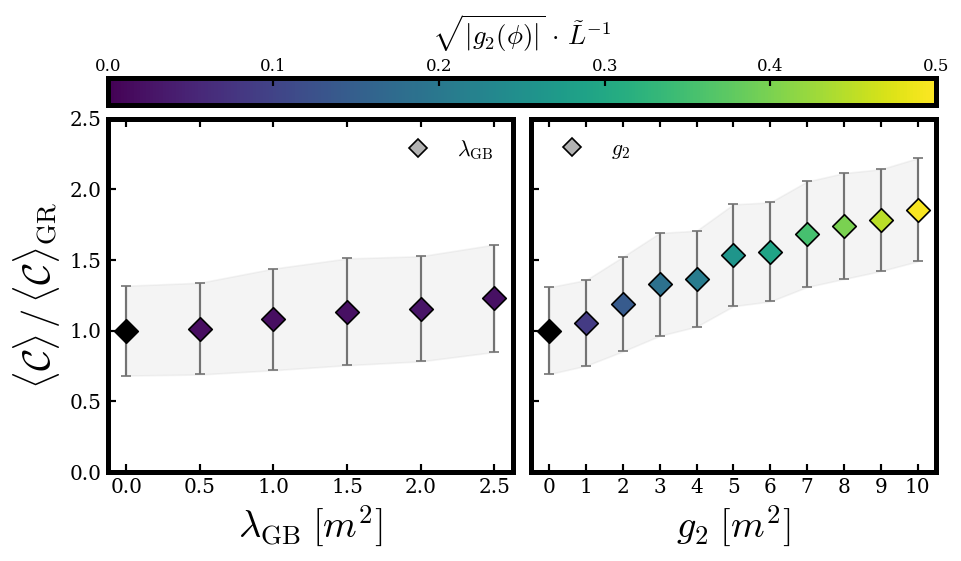

In [22]:
from collections import defaultdict

import os
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import find_peaks
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D


# ============================================================
# SETTINGS FOR THE EFT COLOUR CODING
# ============================================================

# Radial region used when taking max_r of the EFT diagnostic
EFT_R_MAX = 100.0

# False -> use eft_diagnostics.npz if it exists
# True  -> recompute EFT diagnostics from solution.npy
EFT_FORCE_RECOMPUTE = False

# Linear colour scale for the markers
EFT_COLOR_VMIN = 0.0
EFT_COLOR_VMAX = 0.5

# Colour map
EFT_CMAP = plt.cm.viridis

# Peak finding parameters for the EFT time series
EFT_PEAK_PROMINENCE_REL = 0.0
EFT_PEAK_MIN_SEPARATION = 1

# Reference value for leaving the EFT regime
EFT_THRESHOLD = 0.5


# ============================================================
# PEAK STATISTICS
# ============================================================

try:
    _peak_stats_last_window  # type: ignore[name-defined]

except NameError:

    def _peak_stats_last_window(
        shifted_ln_a,
        C,
        dlna,
        prominence_rel=0.0,
        min_separation=1,
    ):
        """
        Find local maxima in the final dlna interval of shifted_ln_a.

        Returns
        -------
        mean_peaks : float
            Mean value of the peaks.
        std_peaks : float
            Standard deviation of the peaks.
        n_peaks : int
            Number of detected peaks.

        If no peak is found, the maximum value in the window is returned.
        """

        sln = np.asarray(shifted_ln_a, dtype=float)
        C = np.asarray(C, dtype=float)

        # Protect against slightly different array lengths
        n = min(len(sln), len(C))
        sln = sln[:n]
        C = C[:n]

        finite = np.isfinite(sln) & np.isfinite(C)

        if not finite.any():
            return np.nan, np.nan, 0

        sln_f = sln[finite]
        C_f = C[finite]

        lna_max = sln_f.max()

        mask = sln_f >= (lna_max - dlna)

        if not mask.any():
            return np.nan, np.nan, 0

        C_win = C_f[mask]

        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0

        kw = {}

        if min_separation > 1:
            kw["distance"] = int(min_separation)

        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())

            if rng > 0:
                kw["prominence"] = prominence_rel * rng

        peak_idx, _ = find_peaks(C_win, **kw)

        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0

        peaks = C_win[peak_idx]

        return (
            float(np.mean(peaks)),
            float(np.std(peaks)),
            int(peaks.size),
        )


# ============================================================
# COMPUTE / LOAD EFT DIAGNOSTICS
# ============================================================

def _ensure_eft_for_key(key):
    """
    Make sure all_runs[key]["eft"] exists.

    If eft_diagnostics.npz exists, load it.
    Otherwise calculate it and cache it.
    """

    d = all_runs[key]

    if "eft" in d and d["eft"] is not None and not EFT_FORCE_RECOMPUTE:
        return d["eft"]

    run_dir = d["run_dir"]

    eft_path = os.path.join(
        run_dir,
        "eft_diagnostics.npz",
    )

    # --------------------------------------------------------
    # Load existing cache
    # --------------------------------------------------------

    if os.path.exists(eft_path) and not EFT_FORCE_RECOMPUTE:

        d["eft"] = dict(
            np.load(
                eft_path,
                allow_pickle=True,
            )
        )

        print(f"[EFT] loaded cache for {d['tag']}")

        return d["eft"]

    # --------------------------------------------------------
    # Otherwise calculate diagnostic
    # --------------------------------------------------------

    print(f"[EFT] computing diagnostic for {d['tag']}")

    sol_i = np.load(
        os.path.join(
            run_dir,
            "solution.npy",
        )
    )

    matter_i = ScalarMatter(
        scalar_mu,
        d["mu"],
    )

    sv_i = StateVector(matter_i)

    spacing_i = CubicSpacing(
        **CubicSpacing.get_parameters(
            d["run_r_max"],
            d["run_min_dr"],
            d["run_max_dr"],
        )
    )

    grid_i = Grid(
        spacing_i,
        sv_i,
    )

    bg_i = FlatSphericalBackground(
        grid_i.r
    )

    lgb_k, mu_k, beta_k, amp_k, width_k, g2_k = key

    params = (
        lgb_k,
        a_mg,
        b_mg,
        chi0,
        d["coupling"],
        g2_k,
    )

    eft = get_eft_diagnostic(
        sol_i,
        d["t"],
        grid_i,
        bg_i,
        ScalarMatter(
            scalar_mu,
            d["mu"],
        ),
        params,
    )

    np.savez(
        eft_path,
        **eft,
    )

    d["eft"] = eft

    del sol_i

    print(f"[EFT] computed and cached for {d['tag']}")

    return eft


# ============================================================
# TURN FULL EFT DIAGNOSTIC INTO ONE TIME SERIES W_EFT(t)
# ============================================================

def _eft_time_series(key):
    """
    Construct one EFT weak-coupling diagnostic W_EFT(t).

    For each active coupling:

        W_GB(t) = max_r wc_lambda_bare(t,r)

        W_g2(t) = max_r wc_g2_bare(t,r)

    with 0 < r <= EFT_R_MAX.

    If both couplings are active:

        W_EFT(t) = max(W_GB(t), W_g2(t))

    For GR, W_EFT = 0.
    """

    d = all_runs[key]

    lgb, mu, beta, amp, width, g2 = key

    # Pure GR
    if lgb == 0 and g2 == 0:
        ntime = len(d["shifted_ln_a"])
        return np.zeros(ntime, dtype=float)

    eft = _ensure_eft_for_key(key)

    if eft is None or "r" not in eft:
        return None

    r = np.asarray(
        eft["r"],
        dtype=float,
    )

    r_mask = (
        np.isfinite(r)
        & (r > 0)
        & (r <= EFT_R_MAX)
    )

    if not r_mask.any():
        return None

    active_diagnostics = []

    # --------------------------------------------------------
    # Gauss-Bonnet weak-coupling diagnostic
    # --------------------------------------------------------

    if lgb != 0 and "wc_lambda_bare" in eft:

        wc_lambda = np.asarray(
            eft["wc_lambda_bare"],
            dtype=float,
        )

        wc_lambda_t = np.nanmax(
            wc_lambda[:, r_mask],
            axis=1,
        )

        active_diagnostics.append(
            wc_lambda_t
        )

    # --------------------------------------------------------
    # g2 weak-coupling diagnostic
    # --------------------------------------------------------

    if g2 != 0 and "wc_g2_bare" in eft:

        wc_g2 = np.asarray(
            eft["wc_g2_bare"],
            dtype=float,
        )

        wc_g2_t = np.nanmax(
            wc_g2[:, r_mask],
            axis=1,
        )

        active_diagnostics.append(
            wc_g2_t
        )

    if len(active_diagnostics) == 0:
        return None

    # Make sure all arrays have the same length
    n = min(
        len(arr)
        for arr in active_diagnostics
    )

    active_diagnostics = [
        arr[:n]
        for arr in active_diagnostics
    ]

    if len(active_diagnostics) == 1:

        W_eft = active_diagnostics[0]

    else:

        W_eft = np.nanmax(
            np.vstack(active_diagnostics),
            axis=0,
        )

    return W_eft


# ============================================================
# ONE EFT NUMBER PER RUN
# ============================================================

def _eft_peak_mean_for_key(key, dlna):
    """
    Return the mean of the temporal peaks of W_EFT(t)
    over the final dlna interval.

    This value determines the marker colour.
    """

    lgb, mu, beta, amp, width, g2 = key

    # GR diagnostic = 0
    if lgb == 0 and g2 == 0:
        return 0.0, 0.0, 0

    d = all_runs[key]

    W_eft = _eft_time_series(key)

    if W_eft is None:
        return np.nan, np.nan, 0

    shifted_ln_a = np.asarray(
        d["shifted_ln_a"],
        dtype=float,
    )

    n = min(
        len(shifted_ln_a),
        len(W_eft),
    )

    shifted_ln_a = shifted_ln_a[:n]

    W_eft = np.asarray(
        W_eft[:n],
        dtype=float,
    )

    return _peak_stats_last_window(
        shifted_ln_a,
        W_eft,
        dlna,
        prominence_rel=EFT_PEAK_PROMINENCE_REL,
        min_separation=EFT_PEAK_MIN_SEPARATION,
    )


# ============================================================
# GR COMPACTNESS BASELINE
# ============================================================

def _C_GR_for(
    P_MU,
    P_BETA,
    P_AMP,
    P_WIDTH,
    P_DLNA,
):
    """
    Peak-mean compactness for the matching GR run.
    """

    for k in all_runs:

        lgb_, mu_, beta_, amp_, width_, g2_ = k

        if lgb_ != 0 or g2_ != 0:
            continue

        if (
            mu_ == P_MU
            and beta_ == P_BETA
            and amp_ == P_AMP
            and width_ == P_WIDTH
        ):

            d = all_runs[k]

            Cm, _, _ = _peak_stats_last_window(
                d["shifted_ln_a"],
                np.asarray(
                    d["osc"]["C"]
                ),
                P_DLNA,
            )

            return (
                float(Cm)
                if np.isfinite(Cm) and Cm > 0
                else np.nan
            )

    return np.nan


# ============================================================
# COLLECT COMPACTNESS + EFT INFORMATION
# ============================================================

def _collect_points(groups, dlna, key_index):
    """
    For each group return:

        (
            x_parameter,
            C_peak_mean,
            C_peak_std,
            EFT_peak_mean,
            EFT_peak_std,
            key
        )
    """

    out = {}

    for grp_val, keys in groups.items():

        pts = []

        for key in keys:

            d = all_runs[key]

            # Compactness statistics
            Cm, Ce, nC = _peak_stats_last_window(
                d["shifted_ln_a"],
                np.asarray(
                    d["osc"]["C"]
                ),
                dlna,
            )

            if not np.isfinite(Cm):
                continue

            # EFT statistics
            Em, Ee, nE = _eft_peak_mean_for_key(
                key,
                dlna,
            )

            pts.append(
                (
                    key[key_index],
                    Cm,
                    Ce,
                    Em,
                    Ee,
                    key,
                )
            )

            print(
                "[EFT colour]",
                key,
                f"<W_EFT>_peaks = {Em:.6g}",
                f"N_peaks = {nE}",
            )

        if pts:

            out[grp_val] = sorted(
                pts,
                key=lambda p: p[0],
            )

    return out


# ============================================================
# MARKER SHAPES
# ============================================================

_markers_lgb_d = [
    "D",
    "s",
    "D",
    "^",
    "v",
    "<",
    ">",
    "P",
    "X",
]

_markers_g2_d = [
    "D",
    "s",
    "D",
    "^",
    "v",
    "<",
    ">",
    "P",
    "X",
]


# ============================================================
# LINEAR COLOUR NORMALISATION
# ============================================================

eft_norm = Normalize(
    vmin=EFT_COLOR_VMIN,
    vmax=EFT_COLOR_VMAX,
    clip=True,
)


def _eft_marker_colour(value):
    """
    Convert EFT diagnostic into marker colour.

    GR -> black
    missing -> light grey
    EFT diagnostic -> linear viridis scale
    """

    if not np.isfinite(value):
        return "lightgrey"

    if value <= 0:
        return "black"

    return EFT_CMAP(
        eft_norm(value)
    )


# ============================================================
# CREATE FIGURE
# ============================================================

fig, (ax_l, ax_r) = plt.subplots(
    1,
    2,
    figsize=(8, 5),
    sharey=True,
)


# ============================================================
# GR BASELINES
# ============================================================

C_GR_left = _C_GR_for(
    P4C_MU,
    P4C_BETA,
    P4C_AMP,
    P4C_WIDTH,
    P4C_DLNA,
)

C_GR_right = _C_GR_for(
    P4B_MU,
    P4B_BETA,
    P4B_AMP,
    P4B_WIDTH,
    P4B_DLNA,
)

if not np.isfinite(C_GR_left):

    print(
        "[warn] no GR run found for P4C cut; "
        "left panel falls back to C_GR = 1."
    )

    C_GR_left = 1.0


if not np.isfinite(C_GR_right):

    print(
        "[warn] no GR run found for P4B cut; "
        "right panel falls back to C_GR = 1."
    )

    C_GR_right = 1.0


# ============================================================
# LEFT PANEL
#
# C/C_GR vs lambda_GB/2
# one marker family per g2
# ============================================================

g2_groups = defaultdict(list)

for key in all_runs:

    lgb, mu, beta, amp, width, g2 = key

    if (
        mu != P4C_MU
        or beta != P4C_BETA
        or amp != P4C_AMP
        or width != P4C_WIDTH
    ):
        continue

    if (
        g2 not in P4C_G2_SHOW
        or lgb not in P4C_LGB_SHOW
    ):
        continue

    g2_groups[g2].append(key)


g2_points = _collect_points(
    g2_groups,
    P4C_DLNA,
    key_index=0,
)


for idx, g2_val in enumerate(
    sorted(g2_points.keys())
):

    pts = g2_points[g2_val]

    marker = _markers_g2_d[
        idx % len(_markers_g2_d)
    ]

    x = np.array(
        [p[0] for p in pts],
        dtype=float,
    ) / 2.0

    y = np.array(
        [p[1] for p in pts],
        dtype=float,
    ) / C_GR_left

    ye = np.array(
        [p[2] for p in pts],
        dtype=float,
    ) / C_GR_left

    eft_values = np.array(
        [p[3] for p in pts],
        dtype=float,
    )

    # Uncertainty band
    ax_l.fill_between(
        x,
        y - ye,
        y + ye,
        color="0.65",
        alpha=0.12,
        zorder=1,
    )

    # Error bars
    ax_l.errorbar(
        x,
        y,
        yerr=ye,
        fmt="none",
        ecolor="0.45",
        capsize=3,
        capthick=1.0,
        elinewidth=1.3,
        zorder=3,
    )

    # Individually EFT-coloured markers
    for xi, yi, eft_val in zip(
        x,
        y,
        eft_values,
    ):

        ax_l.scatter(
            xi,
            yi,
            s=100,
            marker=marker,
            facecolor=_eft_marker_colour(eft_val),
            edgecolor="black",
            linewidth=1.0,
            zorder=5,
        )


# Dummy legend marker
left_legend_handle = Line2D(
    [0],
    [0],
    marker=_markers_g2_d[0],
    linestyle="none",
    markerfacecolor="0.7",
    markeredgecolor="black",
    markersize=8,
    label=rf"$\lambda_{{\rm GB}}$",
)

ax_l.set_xlabel(
    r"$\lambda_{\rm GB}\;[m^2]$"
)

ax_l.set_ylabel(
    r"$\langle\mathcal{C}\rangle"
    r"\,/\,"
    r"\langle\mathcal{C}\rangle_{\rm GR}$"
)

ax_l.set_ylim(
    0.5,
    2.3,
)

ax_l.tick_params(
    which="both",
    top=True,
    right=False,
)

ax_l.legend(
    handles=[left_legend_handle],
    loc="best",
    frameon=False,
)


# ============================================================
# RIGHT PANEL
#
# C/C_GR vs g2/2
# one marker family per lambda_GB
# ============================================================

lgb_groups = defaultdict(list)

for key in all_runs:

    lgb, mu, beta, amp, width, g2 = key

    if (
        mu != P4B_MU
        or beta != P4B_BETA
        or amp != P4B_AMP
        or width != P4B_WIDTH
    ):
        continue

    if (
        lgb not in P4B_LGB_SHOW
        or g2 not in P4B_G2_SHOW
    ):
        continue

    lgb_groups[lgb].append(key)


lgb_points = _collect_points(
    lgb_groups,
    P4B_DLNA,
    key_index=5,
)


for idx, lgb_val in enumerate(
    sorted(lgb_points.keys())
):

    pts = lgb_points[lgb_val]

    marker = _markers_lgb_d[
        idx % len(_markers_lgb_d)
    ]

    x = np.array(
        [p[0] for p in pts],
        dtype=float,
    ) / 2.0

    y = np.array(
        [p[1] for p in pts],
        dtype=float,
    ) / C_GR_right

    ye = np.array(
        [p[2] for p in pts],
        dtype=float,
    ) / C_GR_right

    eft_values = np.array(
        [p[3] for p in pts],
        dtype=float,
    )

    # Uncertainty band
    ax_r.fill_between(
        x,
        y - ye,
        y + ye,
        color="0.65",
        alpha=0.12,
        zorder=1,
    )

    # Error bars
    ax_r.errorbar(
        x,
        y,
        yerr=ye,
        fmt="none",
        ecolor="0.45",
        capsize=3,
        capthick=1.0,
        elinewidth=1.3,
        zorder=3,
    )

    # Individually EFT-coloured markers
    for xi, yi, eft_val in zip(
        x,
        y,
        eft_values,
    ):

        ax_r.scatter(
            xi,
            yi,
            s=100,
            marker=marker,
            facecolor=_eft_marker_colour(eft_val),
            edgecolor="black",
            linewidth=1.0,
            zorder=5,
        )


right_legend_handle = Line2D(
    [0],
    [0],
    marker=_markers_lgb_d[0],
    linestyle="none",
    markerfacecolor="0.7",
    markeredgecolor="black",
    markersize=8,
    label=rf"$g_2$",
)


ax_r.set_xlim(
    -0.5,
    10.5,
)

ax_r.set_xticks(
    np.arange(
        0,
        11,
        1,
    )
)

ax_r.set_yticks(
    np.arange(
        0,
        2.8,
        0.5,
    )
)

ax_r.set_frame_on(True)

for spine in ax_r.spines.values():
    spine.set_zorder(10)

ax_r.set_xlabel(
    r"$g_2\;[m^2]$"
)

ax_r.tick_params(
    which="both",
    top=True,
    right=False,
)

ax_r.legend(
    handles=[right_legend_handle],
    loc="best",
    frameon=False,
)


# ============================================================
# LAYOUT
#
# Leave room ABOVE the two panels for the horizontal colourbar.
# ============================================================

fig.tight_layout(
    rect=[0.0, 0.0, 1.0, 0.79]
)

# Get the final positions of both plotting axes AFTER tight_layout.
# This allows the colourbar to start exactly at the left edge of
# the left panel and finish exactly at the right edge of the
# right panel.
pos_l = ax_l.get_position()
pos_r = ax_r.get_position()


# ============================================================
# EFT COLOURBAR — HORIZONTAL ACROSS BOTH PANELS
# ============================================================

cax = fig.add_axes(
    [
        pos_l.x0,                    # same left edge as left panel
        0.77,                        # vertical position
        pos_r.x1 - pos_l.x0,         # full width of both panels
        0.045,                       # colourbar height
    ]
)

sm = ScalarMappable(
    norm=eft_norm,
    cmap=EFT_CMAP,
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal",
)

# Put ticks above the colourbar
cbar.ax.xaxis.set_ticks_position("top")
cbar.ax.xaxis.set_label_position("top")

cbar.set_label(
    r"$\sqrt{|g_2(\phi)|}\,\cdot\,\tilde L^{-1}$",
    fontsize=16,
    labelpad=8,
)

cbar.ax.tick_params(
    labelsize=10,
    pad=2,
)


# ============================================================
# EFT THRESHOLD ON COLOURBAR
# ============================================================

if (
    EFT_COLOR_VMIN
    < EFT_THRESHOLD
    < EFT_COLOR_VMAX
):

    cbar.ax.axvline(
        EFT_THRESHOLD,
        color="black",
        linestyle="--",
        linewidth=1.2,
    )


# ============================================================
# OPTIONAL SAVE
# ============================================================

save_fig(
    fig,
    "compactness_vs_lgb_and_g2_normalized_EFT_coloured",
)

plt.show()

[EFT] computing diagnostic for lgb-1_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT] computed and cached for lgb-1_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT envelope] (-1.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.0408058 N_broad_peaks = 2
[EFT] computing diagnostic for lgb-2_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT] computed and cached for lgb-2_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT envelope] (-2.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.0403344 N_broad_peaks = 3
[EFT] computing diagnostic for lgb-3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT] computed and cached for lgb-3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT envelope] (-3.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.0382364 N_broad_peaks = 2
[EFT] computing diagnostic for lgb-4_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
[EFT] computed and cached for lgb-4_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_

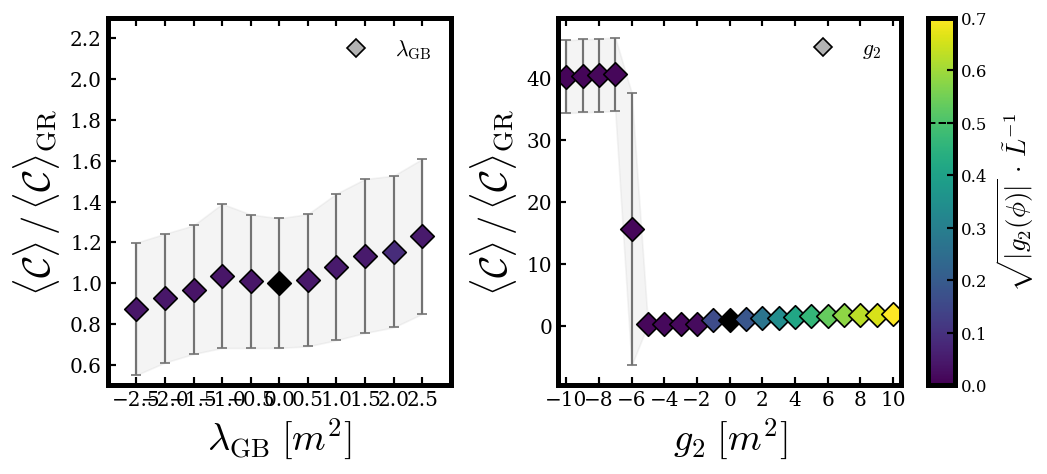

In [23]:
from collections import defaultdict

import os
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D


# ============================================================
# SETTINGS FOR THE EFT COLOUR CODING
# ============================================================

# Radial region used when taking max_r of the EFT diagnostic
EFT_R_MAX = 100.0

# False -> use eft_diagnostics.npz if it exists
# True  -> recompute EFT diagnostics from solution.npy
EFT_FORCE_RECOMPUTE = False

# Linear colour scale
EFT_COLOR_VMIN = 0.0
EFT_COLOR_VMAX = 0.7

# Colour map
EFT_CMAP = plt.cm.viridis

# Reference weak-coupling value
EFT_THRESHOLD = 0.5


# ============================================================
# EFT ENVELOPE-PEAK SETTINGS
# ============================================================

# Gaussian smoothing scale measured directly in Delta ln(a).
#
# Larger value:
#     removes more of the rapid oscillations
#     and gives a smoother envelope.
#
# Smaller value:
#     retains more small-scale structure.
EFT_ENVELOPE_SMOOTH_SIGMA_LNA = 0.03


# Minimum allowed separation between two BROAD envelope peaks,
# again measured directly in Delta ln(a).
#
# Increasing this strongly suppresses the many small in-between peaks.
EFT_ENVELOPE_MIN_SEPARATION_LNA = 0.10


# Required prominence of an envelope peak as a fraction of the
# full range of the smoothed diagnostic in the selected time window.
#
# e.g. 0.05 means a broad peak must have at least 5% prominence.
EFT_ENVELOPE_PROMINENCE_REL = 0.05


# Once a broad peak has been identified from the smoothed curve,
# search this far to either side in the ORIGINAL diagnostic and
# take the actual local maximum.
#
# This means the final average uses the real "high highs", not the
# slightly reduced values of the smoothed curve.
EFT_ENVELOPE_REFINE_HALF_WIDTH_LNA = 0.035


# ============================================================
# ORIGINAL COMPACTNESS PEAK STATISTICS
#
# Keep this unchanged for the compactness points/error bars.
# ============================================================

try:
    _peak_stats_last_window  # type: ignore[name-defined]

except NameError:

    def _peak_stats_last_window(
        shifted_ln_a,
        C,
        dlna,
        prominence_rel=0.0,
        min_separation=1,
    ):

        sln = np.asarray(
            shifted_ln_a,
            dtype=float,
        )

        C = np.asarray(
            C,
            dtype=float,
        )

        n = min(
            len(sln),
            len(C),
        )

        sln = sln[:n]
        C = C[:n]

        finite = (
            np.isfinite(sln)
            & np.isfinite(C)
        )

        if not finite.any():
            return np.nan, np.nan, 0

        sln_f = sln[finite]
        C_f = C[finite]

        lna_max = sln_f.max()

        mask = (
            sln_f
            >= lna_max - dlna
        )

        if not mask.any():
            return np.nan, np.nan, 0

        C_win = C_f[mask]

        if C_win.size < 3:
            return (
                float(C_win.max()),
                0.0,
                0,
            )

        kw = {}

        if min_separation > 1:

            kw["distance"] = int(
                min_separation
            )

        if prominence_rel > 0.0:

            rng = float(
                C_win.max()
                - C_win.min()
            )

            if rng > 0:

                kw["prominence"] = (
                    prominence_rel
                    * rng
                )

        peak_idx, _ = find_peaks(
            C_win,
            **kw,
        )

        if peak_idx.size == 0:

            return (
                float(C_win.max()),
                0.0,
                0,
            )

        peaks = C_win[
            peak_idx
        ]

        return (
            float(np.mean(peaks)),
            float(np.std(peaks)),
            int(peaks.size),
        )


# ============================================================
# BROAD EFT ENVELOPE PEAK STATISTICS
# ============================================================

def _eft_envelope_peak_stats_last_window(
    shifted_ln_a,
    W_eft,
    dlna,
):
    """
    Find only the BROAD peaks of the EFT diagnostic envelope.

    Procedure
    ---------
    1. Restrict to the last `dlna` interval.
    2. Smooth W_EFT as a function of ln(a).
    3. Detect well-separated peaks of the smoothed envelope.
    4. Around each envelope peak, return to the ORIGINAL W_EFT
       curve and find the actual local maximum.
    5. Average those original high values.

    Returns
    -------
    mean_peak : float
        Mean height of the broad-envelope peaks.

    std_peak : float
        Standard deviation of those peak heights.

    n_peaks : int
        Number of broad envelope peaks found.
    """

    x = np.asarray(
        shifted_ln_a,
        dtype=float,
    )

    y = np.asarray(
        W_eft,
        dtype=float,
    )

    # --------------------------------------------------------
    # Match lengths
    # --------------------------------------------------------

    n = min(
        len(x),
        len(y),
    )

    x = x[:n]
    y = y[:n]

    # --------------------------------------------------------
    # Remove NaNs / infinities
    # --------------------------------------------------------

    finite = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    if not finite.any():

        return (
            np.nan,
            np.nan,
            0,
        )

    x = x[finite]
    y = y[finite]

    # --------------------------------------------------------
    # Sort in increasing ln(a), just to be safe
    # --------------------------------------------------------

    order = np.argsort(x)

    x = x[order]
    y = y[order]

    # --------------------------------------------------------
    # Restrict to the same final Delta ln(a) window
    # --------------------------------------------------------

    x_max = np.max(x)

    mask = (
        x
        >= x_max - dlna
    )

    x_win = x[mask]
    y_win = y[mask]

    if len(y_win) < 5:

        if len(y_win) == 0:
            return np.nan, np.nan, 0

        return (
            float(np.nanmax(y_win)),
            0.0,
            1,
        )

    # --------------------------------------------------------
    # Characteristic sampling interval in ln(a)
    # --------------------------------------------------------

    dx_array = np.diff(
        x_win
    )

    dx_array = dx_array[
        np.isfinite(dx_array)
        & (dx_array > 0)
    ]

    if dx_array.size == 0:

        return (
            float(np.nanmax(y_win)),
            0.0,
            1,
        )

    dx = float(
        np.median(dx_array)
    )

    # --------------------------------------------------------
    # Convert physical smoothing scale Delta ln(a)
    # into Gaussian sigma measured in samples
    # --------------------------------------------------------

    sigma_samples = (
        EFT_ENVELOPE_SMOOTH_SIGMA_LNA
        / dx
    )

    sigma_samples = max(
        sigma_samples,
        1.0,
    )

    # --------------------------------------------------------
    # Smooth away the rapid sub-oscillations
    # --------------------------------------------------------

    y_smooth = gaussian_filter1d(
        y_win,
        sigma=sigma_samples,
        mode="nearest",
    )

    # --------------------------------------------------------
    # Convert desired broad-peak separation from Delta ln(a)
    # into number of samples
    # --------------------------------------------------------

    distance_samples = int(
        round(
            EFT_ENVELOPE_MIN_SEPARATION_LNA
            / dx
        )
    )

    distance_samples = max(
        distance_samples,
        1,
    )

    # --------------------------------------------------------
    # Peak prominence from the range of the SMOOTHED envelope
    # --------------------------------------------------------

    smooth_range = float(
        np.nanmax(y_smooth)
        - np.nanmin(y_smooth)
    )

    peak_kwargs = {
        "distance": distance_samples,
    }

    if (
        EFT_ENVELOPE_PROMINENCE_REL > 0
        and smooth_range > 0
    ):

        peak_kwargs["prominence"] = (
            EFT_ENVELOPE_PROMINENCE_REL
            * smooth_range
        )

    # --------------------------------------------------------
    # Find BROAD peaks
    # --------------------------------------------------------

    broad_idx, properties = find_peaks(
        y_smooth,
        **peak_kwargs,
    )

    # --------------------------------------------------------
    # Fallback if no broad peak is found
    # --------------------------------------------------------

    if broad_idx.size == 0:

        i_max = int(
            np.nanargmax(
                y_win
            )
        )

        return (
            float(y_win[i_max]),
            0.0,
            1,
        )

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # We do NOT average y_smooth[broad_idx].
    #
    # Instead, for every broad envelope peak, we return to the
    # original unsmoothed diagnostic and locate the highest value
    # close to that broad peak.
    #
    # This gives the actual "high highs".
    # --------------------------------------------------------

    refined_peak_values = []

    refined_peak_positions = []

    for idx in broad_idx:

        x_peak = x_win[idx]

        local_mask = (
            np.abs(
                x_win - x_peak
            )
            <= EFT_ENVELOPE_REFINE_HALF_WIDTH_LNA
        )

        if not local_mask.any():
            continue

        local_y = y_win[
            local_mask
        ]

        local_x = x_win[
            local_mask
        ]

        local_i = int(
            np.nanargmax(
                local_y
            )
        )

        refined_peak_values.append(
            float(
                local_y[local_i]
            )
        )

        refined_peak_positions.append(
            float(
                local_x[local_i]
            )
        )

    refined_peak_values = np.asarray(
        refined_peak_values,
        dtype=float,
    )

    if refined_peak_values.size == 0:

        return (
            float(np.nanmax(y_win)),
            0.0,
            1,
        )

    return (
        float(
            np.mean(
                refined_peak_values
            )
        ),
        float(
            np.std(
                refined_peak_values
            )
        ),
        int(
            refined_peak_values.size
        ),
    )


# ============================================================
# COMPUTE / LOAD EFT DIAGNOSTICS
# ============================================================

def _ensure_eft_for_key(key):

    d = all_runs[key]

    if (
        "eft" in d
        and d["eft"] is not None
        and not EFT_FORCE_RECOMPUTE
    ):

        return d["eft"]

    run_dir = d[
        "run_dir"
    ]

    eft_path = os.path.join(
        run_dir,
        "eft_diagnostics.npz",
    )

    # --------------------------------------------------------
    # Load existing cache
    # --------------------------------------------------------

    if (
        os.path.exists(eft_path)
        and not EFT_FORCE_RECOMPUTE
    ):

        d["eft"] = dict(
            np.load(
                eft_path,
                allow_pickle=True,
            )
        )

        print(
            f"[EFT] loaded cache for {d['tag']}"
        )

        return d["eft"]

    # --------------------------------------------------------
    # Otherwise compute diagnostic
    # --------------------------------------------------------

    print(
        f"[EFT] computing diagnostic for {d['tag']}"
    )

    sol_i = np.load(
        os.path.join(
            run_dir,
            "solution.npy",
        )
    )

    matter_i = ScalarMatter(
        scalar_mu,
        d["mu"],
    )

    sv_i = StateVector(
        matter_i
    )

    spacing_i = CubicSpacing(
        **CubicSpacing.get_parameters(
            d["run_r_max"],
            d["run_min_dr"],
            d["run_max_dr"],
        )
    )

    grid_i = Grid(
        spacing_i,
        sv_i,
    )

    bg_i = FlatSphericalBackground(
        grid_i.r
    )

    (
        lgb_k,
        mu_k,
        beta_k,
        amp_k,
        width_k,
        g2_k,
    ) = key

    params = (
        lgb_k,
        a_mg,
        b_mg,
        chi0,
        d["coupling"],
        g2_k,
    )

    eft = get_eft_diagnostic(
        sol_i,
        d["t"],
        grid_i,
        bg_i,
        ScalarMatter(
            scalar_mu,
            d["mu"],
        ),
        params,
    )

    np.savez(
        eft_path,
        **eft,
    )

    d["eft"] = eft

    del sol_i

    print(
        f"[EFT] computed and cached for {d['tag']}"
    )

    return eft


# ============================================================
# BUILD W_EFT(t)
# ============================================================

def _eft_time_series(key):
    """
    Construct one EFT diagnostic time series.

    For each active coupling:

        W_GB(t) = max_r wc_lambda_bare

        W_g2(t) = max_r wc_g2_bare

    If both couplings are present:

        W_EFT(t) = max(W_GB, W_g2)
    """

    d = all_runs[key]

    (
        lgb,
        mu,
        beta,
        amp,
        width,
        g2,
    ) = key

    # --------------------------------------------------------
    # Pure GR
    # --------------------------------------------------------

    if (
        lgb == 0
        and g2 == 0
    ):

        ntime = len(
            d["shifted_ln_a"]
        )

        return np.zeros(
            ntime,
            dtype=float,
        )

    eft = _ensure_eft_for_key(
        key
    )

    if (
        eft is None
        or "r" not in eft
    ):

        return None

    r = np.asarray(
        eft["r"],
        dtype=float,
    )

    r_mask = (
        np.isfinite(r)
        & (r > 0)
        & (r <= EFT_R_MAX)
    )

    if not r_mask.any():

        return None

    active_diagnostics = []

    # --------------------------------------------------------
    # Gauss-Bonnet
    # --------------------------------------------------------

    if (
        lgb != 0
        and "wc_lambda_bare" in eft
    ):

        wc_lambda = np.asarray(
            eft[
                "wc_lambda_bare"
            ],
            dtype=float,
        )

        wc_lambda_t = np.nanmax(
            wc_lambda[
                :,
                r_mask,
            ],
            axis=1,
        )

        active_diagnostics.append(
            wc_lambda_t
        )

    # --------------------------------------------------------
    # g2
    # --------------------------------------------------------

    if (
        g2 != 0
        and "wc_g2_bare" in eft
    ):

        wc_g2 = np.asarray(
            eft[
                "wc_g2_bare"
            ],
            dtype=float,
        )

        wc_g2_t = np.nanmax(
            wc_g2[
                :,
                r_mask,
            ],
            axis=1,
        )

        active_diagnostics.append(
            wc_g2_t
        )

    if (
        len(active_diagnostics)
        == 0
    ):

        return None

    n = min(
        len(arr)
        for arr
        in active_diagnostics
    )

    active_diagnostics = [
        arr[:n]
        for arr
        in active_diagnostics
    ]

    if (
        len(active_diagnostics)
        == 1
    ):

        W_eft = (
            active_diagnostics[0]
        )

    else:

        W_eft = np.nanmax(
            np.vstack(
                active_diagnostics
            ),
            axis=0,
        )

    return W_eft


# ============================================================
# ONE EFT NUMBER PER RUN
#
# THIS NOW USES BROAD ENVELOPE PEAKS
# ============================================================

def _eft_peak_mean_for_key(
    key,
    dlna,
):

    (
        lgb,
        mu,
        beta,
        amp,
        width,
        g2,
    ) = key

    # GR diagnostic = 0
    if (
        lgb == 0
        and g2 == 0
    ):

        return (
            0.0,
            0.0,
            0,
        )

    d = all_runs[key]

    W_eft = _eft_time_series(
        key
    )

    if W_eft is None:

        return (
            np.nan,
            np.nan,
            0,
        )

    shifted_ln_a = np.asarray(
        d["shifted_ln_a"],
        dtype=float,
    )

    n = min(
        len(shifted_ln_a),
        len(W_eft),
    )

    shifted_ln_a = (
        shifted_ln_a[:n]
    )

    W_eft = np.asarray(
        W_eft[:n],
        dtype=float,
    )

    # --------------------------------------------------------
    # BROAD ENVELOPE PEAK STATISTICS
    # --------------------------------------------------------

    return _eft_envelope_peak_stats_last_window(
        shifted_ln_a,
        W_eft,
        dlna,
    )


# ============================================================
# GR COMPACTNESS BASELINE
# ============================================================

def _C_GR_for(
    P_MU,
    P_BETA,
    P_AMP,
    P_WIDTH,
    P_DLNA,
):

    for k in all_runs:

        (
            lgb_,
            mu_,
            beta_,
            amp_,
            width_,
            g2_,
        ) = k

        if (
            lgb_ != 0
            or g2_ != 0
        ):

            continue

        if (
            mu_ == P_MU
            and beta_ == P_BETA
            and amp_ == P_AMP
            and width_ == P_WIDTH
        ):

            d = all_runs[k]

            Cm, _, _ = (
                _peak_stats_last_window(
                    d[
                        "shifted_ln_a"
                    ],
                    np.asarray(
                        d["osc"]["C"]
                    ),
                    P_DLNA,
                )
            )

            return (
                float(Cm)
                if (
                    np.isfinite(Cm)
                    and Cm > 0
                )
                else np.nan
            )

    return np.nan


# ============================================================
# COLLECT COMPACTNESS + EFT INFORMATION
# ============================================================

def _collect_points(
    groups,
    dlna,
    key_index,
):

    out = {}

    for grp_val, keys in groups.items():

        pts = []

        for key in keys:

            d = all_runs[key]

            # ------------------------------------------------
            # Compactness
            # ------------------------------------------------

            Cm, Ce, nC = (
                _peak_stats_last_window(
                    d[
                        "shifted_ln_a"
                    ],
                    np.asarray(
                        d["osc"]["C"]
                    ),
                    dlna,
                )
            )

            if not np.isfinite(Cm):
                continue

            # ------------------------------------------------
            # BROAD EFT ENVELOPE PEAKS
            # ------------------------------------------------

            Em, Ee, nE = (
                _eft_peak_mean_for_key(
                    key,
                    dlna,
                )
            )

            pts.append(
                (
                    key[
                        key_index
                    ],
                    Cm,
                    Ce,
                    Em,
                    Ee,
                    key,
                )
            )

            print(
                "[EFT envelope]",
                key,
                f"<W_EFT>_broad_peaks = {Em:.6g}",
                f"N_broad_peaks = {nE}",
            )

        if pts:

            out[grp_val] = sorted(
                pts,
                key=lambda p: p[0],
            )

    return out


# ============================================================
# MARKER SHAPES
# ============================================================

_markers_lgb_d = [
    "D",
    "s",
    "D",
    "^",
    "v",
    "<",
    ">",
    "P",
    "X",
]

_markers_g2_d = [
    "D",
    "s",
    "D",
    "^",
    "v",
    "<",
    ">",
    "P",
    "X",
]


# ============================================================
# LINEAR COLOUR NORMALISATION
# ============================================================

eft_norm = Normalize(
    vmin=EFT_COLOR_VMIN,
    vmax=EFT_COLOR_VMAX,
    clip=True,
)


def _eft_marker_colour(
    value,
):

    if not np.isfinite(
        value
    ):

        return "lightgrey"

    if value <= 0:

        return "black"

    return EFT_CMAP(
        eft_norm(
            value
        )
    )


# Same couplings as the money plot, plus the sign-flipped counterparts.
# Local lists, so the other panels keep P4B_G2_SHOW and P4C_LGB_SHOW.
_G2_SHOW_NEG = (
    [v for v in P4B_G2_SHOW if v != 0]
    + [-v for v in P4B_G2_SHOW if v != 0]
    + [0]
)
_LGB_SHOW_NEG = (
    [v for v in P4C_LGB_SHOW if v != 0]
    + [-v for v in P4C_LGB_SHOW if v != 0]
    + [0]
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, (
    ax_l,
    ax_r,
) = plt.subplots(
    1,
    2,
    figsize=(9, 4),
    sharey=False,
)


# ============================================================
# GR BASELINES
# ============================================================

C_GR_left = _C_GR_for(
    P4C_MU,
    P4C_BETA,
    P4C_AMP,
    P4C_WIDTH,
    P4C_DLNA,
)

C_GR_right = _C_GR_for(
    P4B_MU,
    P4B_BETA,
    P4B_AMP,
    P4B_WIDTH,
    P4B_DLNA,
)

if not np.isfinite(
    C_GR_left
):

    print(
        "[warn] no GR run found for P4C cut; "
        "left panel falls back to C_GR = 1."
    )

    C_GR_left = 1.0


if not np.isfinite(
    C_GR_right
):

    print(
        "[warn] no GR run found for P4B cut; "
        "right panel falls back to C_GR = 1."
    )

    C_GR_right = 1.0


# ============================================================
# LEFT PANEL
#
# C/C_GR vs lambda_GB/2
# ============================================================

g2_groups = defaultdict(
    list
)

for key in all_runs:

    (
        lgb,
        mu,
        beta,
        amp,
        width,
        g2,
    ) = key

    if (
        mu != P4C_MU
        or beta != P4C_BETA
        or amp != P4C_AMP
        or width != P4C_WIDTH
    ):

        continue

    if (
        g2 not in P4C_G2_SHOW
        or lgb not in _LGB_SHOW_NEG
    ):

        continue

    g2_groups[
        g2
    ].append(
        key
    )


g2_points = _collect_points(
    g2_groups,
    P4C_DLNA,
    key_index=0,
)


for idx, g2_val in enumerate(
    sorted(
        g2_points.keys()
    )
):

    pts = g2_points[
        g2_val
    ]

    marker = _markers_g2_d[
        idx
        % len(
            _markers_g2_d
        )
    ]

    x = np.array(
        [
            p[0]
            for p
            in pts
        ],
        dtype=float,
    ) / 2.0

    y = np.array(
        [
            p[1]
            for p
            in pts
        ],
        dtype=float,
    ) / C_GR_left

    ye = np.array(
        [
            p[2]
            for p
            in pts
        ],
        dtype=float,
    ) / C_GR_left

    eft_values = np.array(
        [
            p[3]
            for p
            in pts
        ],
        dtype=float,
    )

    # --------------------------------------------------------
    # Uncertainty band
    # --------------------------------------------------------

    ax_l.fill_between(
        x,
        y - ye,
        y + ye,
        color="0.65",
        alpha=0.12,
        zorder=1,
    )

    # --------------------------------------------------------
    # Error bars
    # --------------------------------------------------------

    ax_l.errorbar(
        x,
        y,
        yerr=ye,
        fmt="none",
        ecolor="0.45",
        capsize=3,
        capthick=1.0,
        elinewidth=1.3,
        zorder=3,
    )

    # --------------------------------------------------------
    # EFT-coloured markers
    # --------------------------------------------------------

    for (
        xi,
        yi,
        eft_val,
    ) in zip(
        x,
        y,
        eft_values,
    ):

        ax_l.scatter(
            xi,
            yi,
            s=100,
            marker=marker,
            facecolor=(
                _eft_marker_colour(
                    eft_val
                )
            ),
            edgecolor="black",
            linewidth=1.0,
            zorder=5,
        )


left_legend_handle = Line2D(
    [0],
    [0],
    marker=(
        _markers_g2_d[0]
    ),
    linestyle="none",
    markerfacecolor="0.7",
    markeredgecolor="black",
    markersize=8,
    label=(
        r"$\lambda_{\rm GB}$"
    ),
)

ax_l.set_xlim(
    -3.0,
    3.0,
)

ax_l.set_xticks(
    np.arange(
        -2.5,
        3.0,
        0.5,
    )
)

ax_l.set_xlabel(
    r"$\lambda_{\rm GB}\;[m^2]$"
)

ax_l.set_ylabel(
    r"$\langle\mathcal{C}\rangle"
    r"\,/\,"
    r"\langle\mathcal{C}\rangle_{\rm GR}$"
)

ax_l.set_ylim(
    0.5,
    2.3,
)

ax_l.tick_params(
    which="both",
    top=True,
    right=False,
)

ax_l.legend(
    handles=[
        left_legend_handle
    ],
    loc="best",
    frameon=False,
)


# ============================================================
# RIGHT PANEL
#
# C/C_GR vs g2/2
# ============================================================

lgb_groups = defaultdict(
    list
)

for key in all_runs:

    (
        lgb,
        mu,
        beta,
        amp,
        width,
        g2,
    ) = key

    if (
        mu != P4B_MU
        or beta != P4B_BETA
        or amp != P4B_AMP
        or width != P4B_WIDTH
    ):

        continue

    if (
        lgb not in P4B_LGB_SHOW
        or g2 not in _G2_SHOW_NEG
    ):

        continue

    lgb_groups[
        lgb
    ].append(
        key
    )


lgb_points = _collect_points(
    lgb_groups,
    P4B_DLNA,
    key_index=5,
)


for idx, lgb_val in enumerate(
    sorted(
        lgb_points.keys()
    )
):

    pts = lgb_points[
        lgb_val
    ]

    marker = _markers_lgb_d[
        idx
        % len(
            _markers_lgb_d
        )
    ]

    x = np.array(
        [
            p[0]
            for p
            in pts
        ],
        dtype=float,
    ) / 2.0

    y = np.array(
        [
            p[1]
            for p
            in pts
        ],
        dtype=float,
    ) / C_GR_right

    ye = np.array(
        [
            p[2]
            for p
            in pts
        ],
        dtype=float,
    ) / C_GR_right

    eft_values = np.array(
        [
            p[3]
            for p
            in pts
        ],
        dtype=float,
    )

    # --------------------------------------------------------
    # Uncertainty band
    # --------------------------------------------------------

    ax_r.fill_between(
        x,
        y - ye,
        y + ye,
        color="0.65",
        alpha=0.12,
        zorder=1,
    )

    # --------------------------------------------------------
    # Error bars
    # --------------------------------------------------------

    ax_r.errorbar(
        x,
        y,
        yerr=ye,
        fmt="none",
        ecolor="0.45",
        capsize=3,
        capthick=1.0,
        elinewidth=1.3,
        zorder=3,
    )

    # --------------------------------------------------------
    # EFT-coloured markers
    # --------------------------------------------------------

    for (
        xi,
        yi,
        eft_val,
    ) in zip(
        x,
        y,
        eft_values,
    ):

        ax_r.scatter(
            xi,
            yi,
            s=100,
            marker=marker,
            facecolor=(
                _eft_marker_colour(
                    eft_val
                )
            ),
            edgecolor="black",
            linewidth=1.0,
            zorder=5,
        )


right_legend_handle = Line2D(
    [0],
    [0],
    marker=(
        _markers_lgb_d[0]
    ),
    linestyle="none",
    markerfacecolor="0.7",
    markeredgecolor="black",
    markersize=8,
    label=r"$g_2$",
)


_y_right = [
    (p[1] + s * p[2]) / C_GR_right
    for pts in lgb_points.values()
    for p in pts
    for s in (-1.0, 0.0, 1.0)
    if np.isfinite(p[1]) and np.isfinite(p[2])
]

if _y_right:
    _y_lo = min(_y_right)
    _y_hi = max(_y_right)
    _pad = 0.06 * (_y_hi - _y_lo) if _y_hi > _y_lo else 0.2
    ax_r.set_ylim(
        min(0.0, _y_lo) - _pad,
        _y_hi + _pad,
    )

ax_r.set_xlim(
    -10.5,
    10.5,
)

ax_r.set_xticks(
    np.arange(
        -10,
        11,
        2,
    )
)

ax_r.set_ylabel(
    r"$\langle\mathcal{C}\rangle"
    r"\,/\,"
    r"\langle\mathcal{C}\rangle_{\rm GR}$"
)

ax_r.set_frame_on(
    True
)

for spine in (
    ax_r.spines.values()
):

    spine.set_zorder(
        10
    )

ax_r.set_xlabel(
    r"$g_2\;[m^2]$"
)

ax_r.tick_params(
    which="both",
    top=True,
    right=False,
)

ax_r.legend(
    handles=[
        right_legend_handle
    ],
    loc="best",
    frameon=False,
)


# ============================================================
# LAYOUT
#
# Leave room on the RIGHT for the vertical colourbar.
# ============================================================

fig.tight_layout(
    rect=[
        0.0,
        0.0,
        0.86,
        1.0,
    ]
)


# ============================================================
# EFT COLOURBAR
#
# Vertical again.
#
# Bottom exactly aligned with bottom of right panel.
# Top exactly aligned with top of right panel.
# ============================================================

pos_r = ax_r.get_position()

cbar_gap = 0.025
cbar_width = 0.025

cax = fig.add_axes(
    [
        pos_r.x1 + cbar_gap,
        pos_r.y0,
        cbar_width,
        pos_r.height,
    ]
)


sm = ScalarMappable(
    norm=eft_norm,
    cmap=EFT_CMAP,
)

sm.set_array(
    []
)

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="vertical",
)

cbar.set_label(
    r"$\sqrt{|g_2(\phi)|}"
    r"\,\cdot\,"
    r"\tilde L^{-1}$",
    fontsize=16,
)

cbar.ax.tick_params(
    labelsize=10,
)


# ============================================================
# EFT THRESHOLD ON COLOURBAR
# ============================================================

if (
    EFT_COLOR_VMIN
    <= EFT_THRESHOLD
    <= EFT_COLOR_VMAX
):

    cbar.ax.axhline(
        EFT_THRESHOLD,
        color="black",
        linestyle="--",
        linewidth=1.2,
    )


# ============================================================
# SAVE
# ============================================================

save_fig(
    fig,
    "compactness_vs_lgb_and_g2_normalized_EFT_coloured",
)

plt.show()


  saved radius_min_vs_lgb_and_g2.pdf and radius_min_vs_lgb_and_g2.png


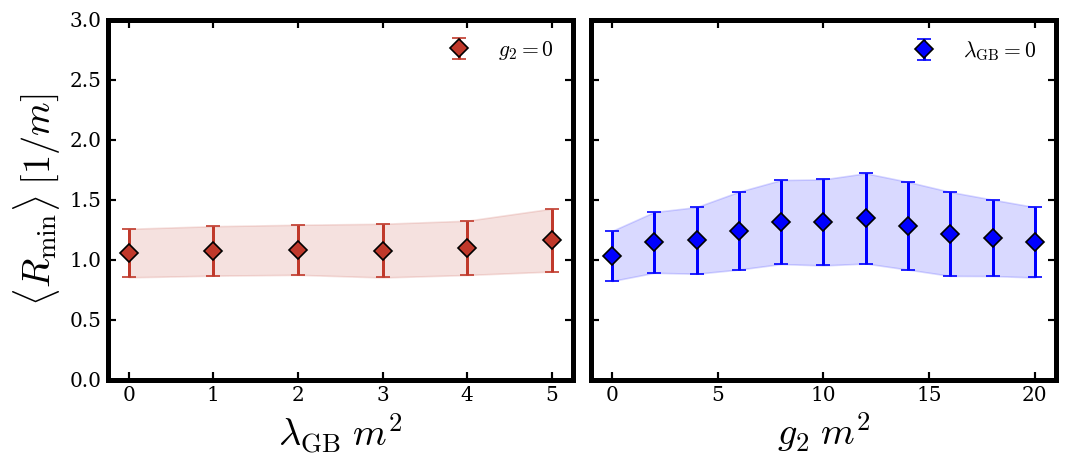

In [23]:
# Panel 4d-R — Same layout as Panel 4d (side-by-side: vs lambda_GB and vs g2)
# but plotting the oscillon radius R(t) trough (minima) statistics instead of
# the compactness maxima. Reuses the Panel 4b / 4c selection variables and the
# same palettes/markers, so it stays visually consistent with Panel 4d.

from collections import defaultdict
from scipy.signal import find_peaks


def _trough_stats_last_window(shifted_ln_a, C, dlna, prominence_rel=0.0,
                              min_separation=1):
    """Mean / std / count of local minima of C(t) in the last `dlna` e-folds.

    Mirror of `_peak_stats_last_window` but detects troughs by running
    `find_peaks` on `-C_window`. Falls back to `min(C_window)` with zero error
    when no interior minimum is found.
    """
    sln = np.asarray(shifted_ln_a, dtype=float)
    C   = np.asarray(C,            dtype=float)
    finite = np.isfinite(sln) & np.isfinite(C)
    if not finite.any():
        return np.nan, np.nan, 0
    sln_f = sln[finite]
    C_f   = C[finite]
    lna_max = sln_f.max()
    mask = sln_f >= (lna_max - dlna)
    if not mask.any():
        return np.nan, np.nan, 0
    C_win = C_f[mask]
    if C_win.size < 3:
        return float(C_win.min()), 0.0, 0

    kw = {}
    if min_separation > 1:
        kw["distance"] = int(min_separation)
    if prominence_rel > 0.0:
        rng = float(C_win.max() - C_win.min())
        if rng > 0:
            kw["prominence"] = prominence_rel * rng

    trough_idx, _ = find_peaks(-C_win, **kw)
    if trough_idx.size == 0:
        return float(C_win.min()), 0.0, 0
    troughs = C_win[trough_idx]
    return float(np.mean(troughs)), float(np.std(troughs)), int(troughs.size)


def _collect_points_R(groups, dlna, key_index):
    """For each group, return a sorted list of (x, R_min_mean, R_min_std)."""
    out = {}
    for grp_val, keys in groups.items():
        pts = []
        for key in keys:
            d = all_runs[key]
            Rm, Re, n = _trough_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"]["M"]), dlna)
            if not np.isfinite(Rm):
                continue
            pts.append((key[key_index], Rm, Re))
        if pts:
            out[grp_val] = sorted(pts, key=lambda p: p[0])
    return out


fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# ── Left panel: R vs lambda_GB, one curve per g2 (uses Panel 4c selection) ──
g2_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
        continue
    if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
        continue
    g2_groups[g2].append(key)

g2_points = _collect_points_R(g2_groups, P4C_DLNA, key_index=0)
for idx, g2_val in enumerate(sorted(g2_points.keys())):
    pts    = g2_points[g2_val]
    color  = _colors_g2_d[idx % len(_colors_g2_d)]
    marker = _markers_g2_d[idx % len(_markers_g2_d)]
    x  = np.array([p[0] for p in pts])
    y  = np.array([p[1] for p in pts])
    ye = np.array([p[2] for p in pts])
    ax_l.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
    ax_l.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                  markeredgecolor="k", markeredgewidth=1.0,
                  capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                  label=rf"$g_2={g2_val:g}$")

ax_l.set_xlabel(r"$\lambda_{\rm GB}\;m^2$")
ax_l.set_ylabel(r"$\langle R_{\min} \rangle \; [1/m]$")
ax_l.tick_params(which="both", top=True, right=True)
ax_l.legend(loc="best", frameon=False)

# ── Right panel: R vs g2, one curve per lambda_GB (uses Panel 4b selection) ──
lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

lgb_points = _collect_points_R(lgb_groups, P4B_DLNA, key_index=5)
for idx, lgb_val in enumerate(sorted(lgb_points.keys())):
    pts    = lgb_points[lgb_val]
    color  = _colors_lgb_d[idx % len(_colors_lgb_d)]
    marker = _markers_lgb_d[idx % len(_markers_lgb_d)]
    x  = np.array([p[0] for p in pts])
    y  = np.array([p[1] for p in pts])
    ye = np.array([p[2] for p in pts])
    ax_r.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
    ax_r.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                  markeredgecolor="k", markeredgewidth=1.0,
                  capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                  label=rf"$\lambda_{{\rm GB}}={lgb_val:g}$")

ax_r.set_xlabel(r"$g_2\;m^2$")
ax_r.tick_params(which="both", top=True, right=True)
ax_r.legend(loc="best", frameon=False)
ax_r.set_ylim(0,3)
fig.tight_layout()
save_fig(fig, "radius_min_vs_lgb_and_g2")
plt.show()

  saved radius_mass_max_vs_GR_lgb_and_g2.pdf and radius_mass_max_vs_GR_lgb_and_g2.png


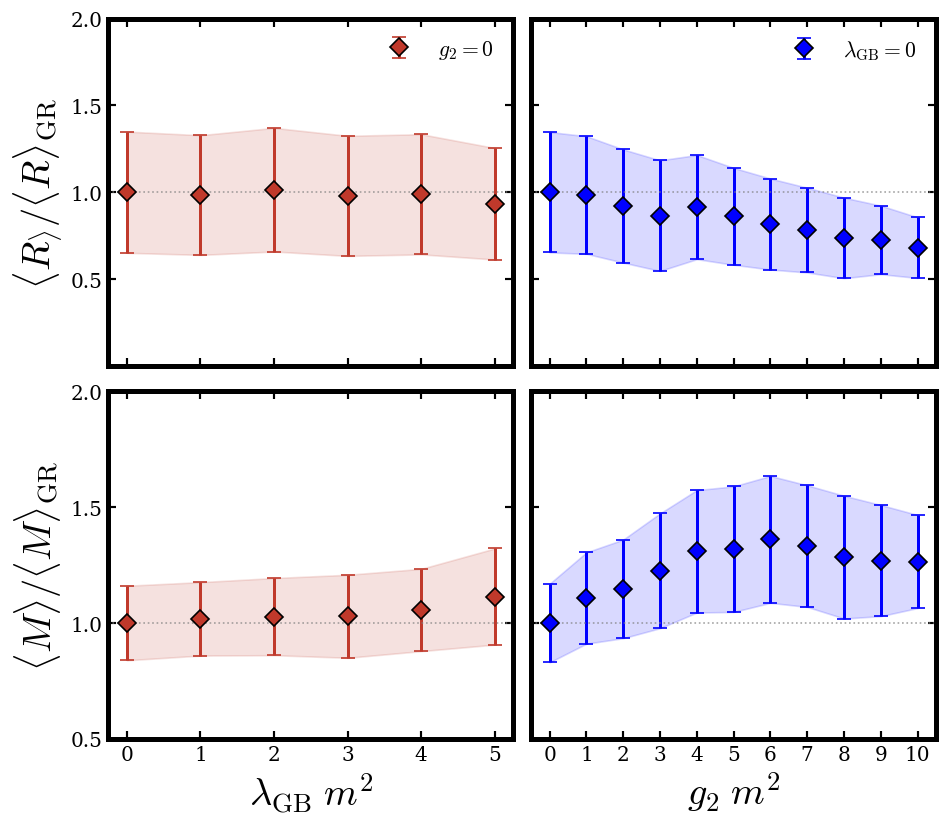

In [24]:
# Panel 4d-R/M vs GR — Same side-by-side layout as Panel 4d-R
# (left: vs lambda_GB using P4C selection; right: vs g2 using P4B selection),
# but each quantity is divided by the GR baseline (lgb=0, g2=0) at the same
# (mu, beta, amp, width) cut. Top row: radius peaks; bottom row: mass peaks,
# using the same `_peak_stats_last_window` estimator as compactness.
# Palettes/markers match Panel 4d so the panels stay visually consistent.

from collections import defaultdict
from scipy.signal import find_peaks

try:
    _peak_stats_last_window  # type: ignore[name-defined]
except NameError:
    def _peak_stats_last_window(shifted_ln_a, C, dlna, prominence_rel=0.0,
                                min_separation=1):
        sln = np.asarray(shifted_ln_a, dtype=float)
        C   = np.asarray(C,            dtype=float)
        finite = np.isfinite(sln) & np.isfinite(C)
        if not finite.any():
            return np.nan, np.nan, 0
        sln_f = sln[finite]
        C_f   = C[finite]
        lna_max = sln_f.max()
        mask = sln_f >= (lna_max - dlna)
        if not mask.any():
            return np.nan, np.nan, 0
        C_win = C_f[mask]
        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0
        kw = {}
        if min_separation > 1:
            kw["distance"] = int(min_separation)
        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())
            if rng > 0:
                kw["prominence"] = prominence_rel * rng
        peak_idx, _ = find_peaks(C_win, **kw)
        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0
        peaks = C_win[peak_idx]
        return float(np.mean(peaks)), float(np.std(peaks)), int(peaks.size)

try:
    _colors_g2_d
except NameError:
    _colors_lgb_d  = ["blue", "#f1c40f", "#8e44ad", "#e67e22", "#1abc9c",
                      "#34495e", "#e74c3c", "#27ae60", "#2c3e50", "#c0392b"]
    _markers_lgb_d = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]
    _colors_g2_d   = ["#c0392b", "#2980b9", "#f1c40f", "#8e44ad", "#e67e22",
                      "#1abc9c", "#34495e", "#e74c3c", "#27ae60", "#2c3e50"]
    _markers_g2_d  = ["o", "s", "D", "^", "v", "<", ">", "P", "X"]


def _qty_GR_for(qty, P_MU, P_BETA, P_AMP, P_WIDTH, P_DLNA):
    """Peak-mean of `qty` for the GR run (lgb=0, g2=0) matching this cut."""
    for k in all_runs:
        lgb_, mu_, beta_, amp_, width_, g2_ = k
        if lgb_ != 0 or g2_ != 0:
            continue
        if (mu_ == P_MU and beta_ == P_BETA and amp_ == P_AMP
                and width_ == P_WIDTH):
            d = all_runs[k]
            ym, _, _ = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"][qty]), P_DLNA)
            return float(ym) if np.isfinite(ym) and ym > 0 else np.nan
    return np.nan


def _collect_points_qty(groups, dlna, key_index, qty):
    """For each group, return a sorted list of (x, peak_mean, peak_std)."""
    out = {}
    for grp_val, keys in groups.items():
        pts = []
        for key in keys:
            d = all_runs[key]
            ym, ye, n = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"][qty]), dlna)
            if not np.isfinite(ym):
                continue
            pts.append((key[key_index], ym, ye))
        if pts:
            out[grp_val] = sorted(pts, key=lambda p: p[0])
    return out


def _plot_ratio_curves(ax, points, colors, markers, y_GR, label_fmt):
    for idx, grp_val in enumerate(sorted(points.keys())):
        pts    = points[grp_val]
        color  = colors[idx % len(colors)]
        marker = markers[idx % len(markers)]
        x  = np.array([p[0] for p in pts]) 
        y  = np.array([p[1] for p in pts]) / y_GR
        ye = np.array([p[2] for p in pts]) / y_GR
        ax.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
        ax.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                    markeredgecolor="k", markeredgewidth=1.0,
                    capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                    label=label_fmt.format(val=grp_val))
    ax.axhline(1.0, color="grey", ls=":", lw=1.0, alpha=0.7)

def _plot_ratio_curves2(ax, points, colors, markers, y_GR, label_fmt):
    for idx, grp_val in enumerate(sorted(points.keys())):
        pts    = points[grp_val]
        color  = colors[idx % len(colors)]
        marker = markers[idx % len(markers)]
        x  = np.array([p[0] for p in pts]) /2
        y  = np.array([p[1] for p in pts]) / y_GR
        ye = np.array([p[2] for p in pts]) / y_GR
        ax.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
        ax.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                    markeredgecolor="k", markeredgewidth=1.0,
                    capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                    label=label_fmt.format(val=grp_val))
    ax.axhline(1.0, color="grey", ls=":", lw=1.0, alpha=0.7)


R_GR_left  = _qty_GR_for("R", P4C_MU, P4C_BETA, P4C_AMP, P4C_WIDTH, P4C_DLNA)
R_GR_right = _qty_GR_for("R", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
M_GR_left  = _qty_GR_for("M", P4C_MU, P4C_BETA, P4C_AMP, P4C_WIDTH, P4C_DLNA)
M_GR_right = _qty_GR_for("M", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
for name, val in (("R_GR_left", R_GR_left), ("R_GR_right", R_GR_right),
                  ("M_GR_left", M_GR_left), ("M_GR_right", M_GR_right)):
    if not np.isfinite(val):
        print(f"[warn] no GR run found for {name}; falling back to 1.")
        if name.startswith("R_GR_left"):
            R_GR_left = 1.0
        elif name.startswith("R_GR_right"):
            R_GR_right = 1.0
        elif name.startswith("M_GR_left"):
            M_GR_left = 1.0
        else:
            M_GR_right = 1.0

# Same run grouping as Panel 4d-R.
g2_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
        continue
    if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
        continue
    g2_groups[g2].append(key)

lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

g2_R = _collect_points_qty(g2_groups,  P4C_DLNA, key_index=0, qty="R")
g2_M = _collect_points_qty(g2_groups,  P4C_DLNA, key_index=0, qty="M")
lgb_R = _collect_points_qty(lgb_groups, P4B_DLNA, key_index=5, qty="R")
lgb_M = _collect_points_qty(lgb_groups, P4B_DLNA, key_index=5, qty="M")

fig, axes = plt.subplots(2, 2, figsize=(8, 7), sharex="col", sharey="row")
(ax_Rl, ax_Rr), (ax_Ml, ax_Mr) = axes

_plot_ratio_curves(ax_Rl, g2_R,  _colors_g2_d,  _markers_g2_d,R_GR_left,  r"$g_2={val:g}$")
_plot_ratio_curves2(ax_Rr, lgb_R, _colors_lgb_d, _markers_lgb_d,R_GR_right, r"$\lambda_{{\rm GB}}={val:g}$")
_plot_ratio_curves(ax_Ml, g2_M,  _colors_g2_d,  _markers_g2_d,M_GR_left,  r"$g_2={val:g}$")
_plot_ratio_curves2(ax_Mr, lgb_M, _colors_lgb_d, _markers_lgb_d,M_GR_right, r"$\lambda_{{\rm GB}}={val:g}$")

ax_Rl.set_ylabel(r"$\langle R_\rangle / \langle R\rangle_{\rm GR}$")
ax_Ml.set_ylabel(r"$\langle M\rangle / \langle M\rangle_{\rm GR}$")
ax_Ml.set_xlabel(r"$\lambda_{\rm GB}\;m^2$")
ax_Mr.set_xlabel(r"$g_2\;m^2$")

ax_Rl.set_xticks(np.arange(0, 6, 1))
ax_Rl.set_yticks(np.arange(0, 2.3, 0.5))

ax_Rr.set_xticks(np.arange(0, 11, 1))
ax_Rr.set_yticks(np.arange(0.5, 2.3, 0.5))

ax_Ml.set_xticks(np.arange(0, 5.9, 1))
ax_Ml.set_yticks(np.arange(0.5, 2.5, 0.5))

ax_Mr.set_xticks(np.arange(0, 11, 1))
ax_Mr.set_yticks(np.arange(0.5, 2.5, 0.5))

for ax in axes.flat:
    ax.tick_params(which="both", top=True, right=True)
ax_Rl.legend(loc="best", frameon=False)
ax_Rr.legend(loc="best", frameon=False)

fig.tight_layout()
save_fig(fig, "radius_mass_max_vs_GR_lgb_and_g2")
plt.show()


  saved radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured.pdf and radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured.png


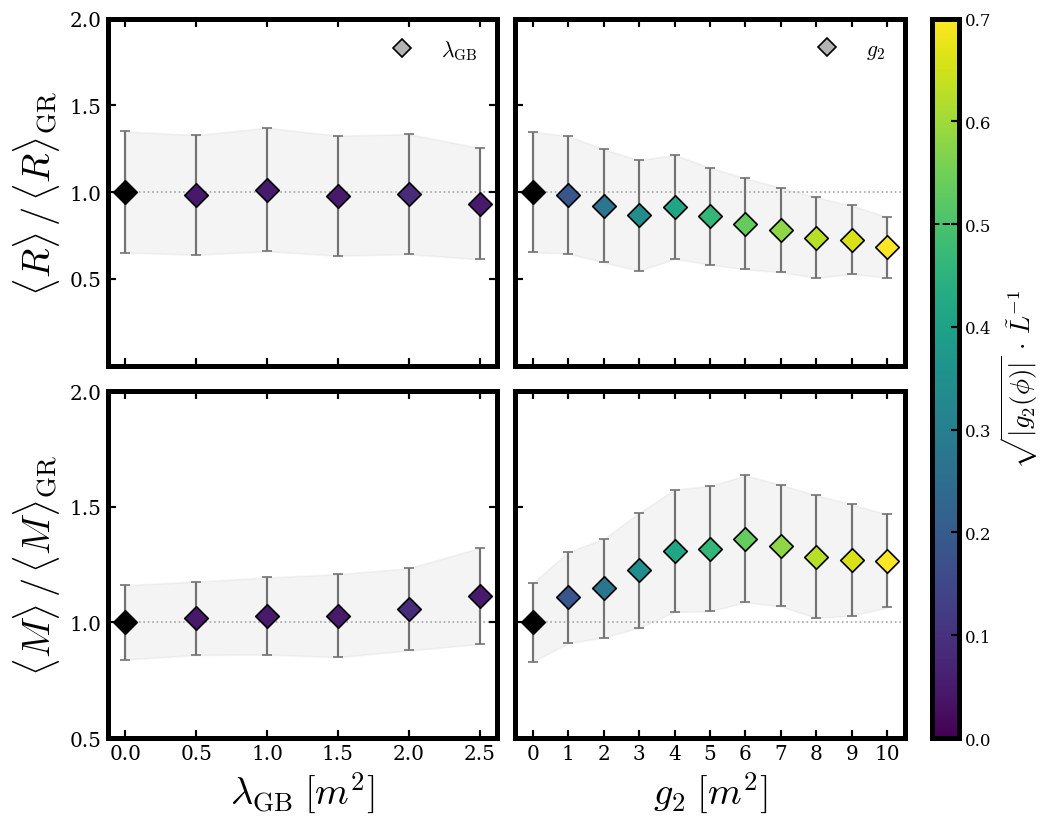

In [43]:
# Panel 4d-R/M vs GR, EFT-coloured — same quantities as the ratio plot above
# (left: vs lambda_GB/2, P4C selection; right: vs g2/2, P4B selection;
# top: radius peaks; bottom: mass peaks), drawn with the money-plot style:
# grey uncertainty bands, grey error bars, and markers coloured by the same
# weak-coupling envelope peak used for compactness. A given (lambda_GB, g2)
# run therefore has the same colour here as on the compactness figure.
# The colourbar spans the full right column, from the bottom of the lower
# panel to the top of the upper panel.

from collections import defaultdict
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

for _name in (
    "_peak_stats_last_window",
    "_eft_peak_mean_for_key",
    "_eft_marker_colour",
    "eft_norm",
    "EFT_CMAP",
    "EFT_THRESHOLD",
    "EFT_COLOR_VMIN",
    "EFT_COLOR_VMAX",
):
    if _name not in globals():
        raise RuntimeError(
            f"{_name} is not defined. Run the EFT-coloured compactness "
            "cell before this one."
        )

# Same marker cycle as the compactness money plot.
_markers_g2_eft = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]
_markers_lgb_eft = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]

_eft_colour_cache = {}


def _wcc_for_key(key, dlna):
    """Weak-coupling envelope peak, identical to the compactness money plot."""
    cached = _eft_colour_cache.get((key, dlna))
    if cached is None:
        Em, _, _ = _eft_peak_mean_for_key(key, dlna)
        cached = float(Em)
        _eft_colour_cache[(key, dlna)] = cached
    return cached


def _collect_qty_wcc(groups, dlna, key_index, qty):
    """Sorted (x, peak_mean, peak_std, WCC) per group."""
    out = {}
    for grp_val, keys in groups.items():
        pts = []
        for key in keys:
            d = all_runs[key]
            ym, ye, _ = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"][qty]), dlna)
            if not np.isfinite(ym):
                continue
            pts.append((key[key_index], ym, ye, _wcc_for_key(key, dlna)))
        if pts:
            out[grp_val] = sorted(pts, key=lambda p: p[0])
    return out


def _plot_wcc_ratio(ax, points, markers, y_GR, x_div=1.0):
    """Money-plot markers and error bars, y divided by the GR baseline."""
    for idx, grp_val in enumerate(sorted(points.keys())):
        pts = points[grp_val]
        marker = markers[idx % len(markers)]
        x = np.array([p[0] for p in pts], dtype=float) / x_div
        y = np.array([p[1] for p in pts], dtype=float) / y_GR
        ye = np.array([p[2] for p in pts], dtype=float) / y_GR
        wcc = np.array([p[3] for p in pts], dtype=float)

        ax.fill_between(x, y - ye, y + ye, color="0.65", alpha=0.12, zorder=1)
        ax.errorbar(
            x, y, yerr=ye, fmt="none", ecolor="0.45",
            capsize=3, capthick=1.0, elinewidth=1.3, zorder=3,
        )
        for xi, yi, ev in zip(x, y, wcc):
            ax.scatter(
                xi, yi, s=100, marker=marker,
                facecolor=_eft_marker_colour(ev),
                edgecolor="black", linewidth=1.0, zorder=5,
            )
    ax.axhline(1.0, color="grey", ls=":", lw=1.0, alpha=0.7, zorder=0)


# Same run grouping and GR baselines as the ratio plot above.
g2_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
        continue
    if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
        continue
    g2_groups[g2].append(key)

lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

g2_R = _collect_qty_wcc(g2_groups, P4C_DLNA, key_index=0, qty="R")
g2_M = _collect_qty_wcc(g2_groups, P4C_DLNA, key_index=0, qty="M")
lgb_R = _collect_qty_wcc(lgb_groups, P4B_DLNA, key_index=5, qty="R")
lgb_M = _collect_qty_wcc(lgb_groups, P4B_DLNA, key_index=5, qty="M")

fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex="col", sharey="row")
(ax_Rl, ax_Rr), (ax_Ml, ax_Mr) = axes

_plot_wcc_ratio(ax_Rl, g2_R, _markers_g2_eft, R_GR_left, x_div=2.0)
_plot_wcc_ratio(ax_Rr, lgb_R, _markers_lgb_eft, R_GR_right, x_div=2.0)
_plot_wcc_ratio(ax_Ml, g2_M, _markers_g2_eft, M_GR_left, x_div=2.0)
_plot_wcc_ratio(ax_Mr, lgb_M, _markers_lgb_eft, M_GR_right, x_div=2.0)

ax_Rl.set_ylabel(
    r"$\langle R\rangle\,/\,\langle R\rangle_{\rm GR}$"
)
ax_Ml.set_ylabel(
    r"$\langle M\rangle\,/\,\langle M\rangle_{\rm GR}$"
)
ax_Ml.set_xlabel(r"$\lambda_{\rm GB}\;[m^2]$")
ax_Mr.set_xlabel(r"$g_2\;[m^2]$")

ax_Rl.set_xlim(-0.125, 2.625)
ax_Rl.set_xticks(np.arange(0.0, 3.0, 0.5))
ax_Rl.set_yticks(np.arange(0, 2.3, 0.5))
ax_Rr.set_xticks(np.arange(0, 11, 1))
ax_Rr.set_yticks(np.arange(0.5, 2.3, 0.5))
ax_Ml.set_yticks(np.arange(0.5, 2.5, 0.5))
ax_Mr.set_xticks(np.arange(0, 11, 1))
ax_Mr.set_yticks(np.arange(0.5, 2.5, 0.5))

for ax in (ax_Rl, ax_Ml):
    ax.tick_params(which="both", top=True, right=True)
for ax in (ax_Rr, ax_Mr):
    ax.tick_params(which="both", top=True, right=False)

ax_Rl.legend(
    handles=[Line2D(
        [0], [0], marker=_markers_g2_eft[0], linestyle="none",
        markerfacecolor="0.7", markeredgecolor="black", markersize=8,
        label=r"$\lambda_{\rm GB}$",
    )],
    loc="best", frameon=False,
)
ax_Rr.legend(
    handles=[Line2D(
        [0], [0], marker=_markers_lgb_eft[0], linestyle="none",
        markerfacecolor="0.7", markeredgecolor="black", markersize=8,
        label=r"$g_2$",
    )],
    loc="best", frameon=False,
)

# Room on the right for a colourbar that covers both right-hand panels.
fig.tight_layout(rect=[0.0, 0.0, 0.86, 1.0])

pos_top = ax_Rr.get_position()
pos_bot = ax_Mr.get_position()
cbar_gap = 0.025
cbar_width = 0.025
cax = fig.add_axes([
    pos_top.x1 + cbar_gap,
    pos_bot.y0,
    cbar_width,
    pos_top.y1 - pos_bot.y0,
])

sm = ScalarMappable(norm=eft_norm, cmap=EFT_CMAP)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax, orientation="vertical")
cbar.set_label(
    r"$\sqrt{|g_2(\phi)|}\,\cdot\,\tilde L^{-1}$",
    fontsize=16,
)
cbar.ax.tick_params(labelsize=10)

if EFT_COLOR_VMIN <= EFT_THRESHOLD <= EFT_COLOR_VMAX:
    cbar.ax.axhline(
        EFT_THRESHOLD, color="black", linestyle="--", linewidth=1.2,
    )

save_fig(fig, "radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured")
plt.show()


  saved C_M_R_vs_g2_normalized.pdf and C_M_R_vs_g2_normalized.png


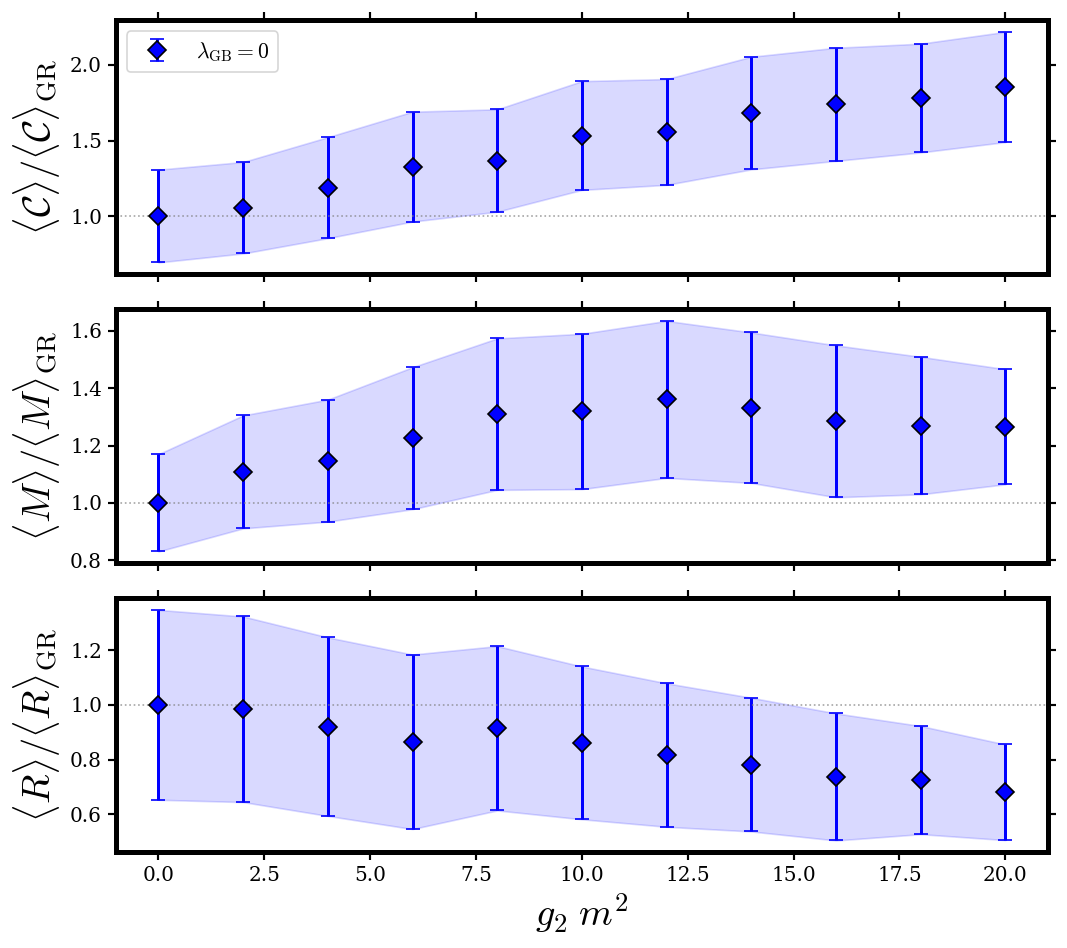

In [22]:
# Panel 4d-C/M/R vs g2 — GR-normalized 3-stack for the g2 coupling.
# Same peak-window estimator and GR baseline (lgb=0, g2=0) as the 2x2
# panel above, but only the Panel 4b selection (vs g2, one curve per
# lambda_GB). Top: compactness; middle: mass; bottom: radius.

from collections import defaultdict
from scipy.signal import find_peaks

try:
    _peak_stats_last_window  # type: ignore[name-defined]
except NameError:
    def _peak_stats_last_window(shifted_ln_a, C, dlna, prominence_rel=0.0,
                                min_separation=1):
        sln = np.asarray(shifted_ln_a, dtype=float)
        C   = np.asarray(C,            dtype=float)
        finite = np.isfinite(sln) & np.isfinite(C)
        if not finite.any():
            return np.nan, np.nan, 0
        sln_f = sln[finite]
        C_f   = C[finite]
        lna_max = sln_f.max()
        mask = sln_f >= (lna_max - dlna)
        if not mask.any():
            return np.nan, np.nan, 0
        C_win = C_f[mask]
        if C_win.size < 3:
            return float(C_win.max()), 0.0, 0
        kw = {}
        if min_separation > 1:
            kw["distance"] = int(min_separation)
        if prominence_rel > 0.0:
            rng = float(C_win.max() - C_win.min())
            if rng > 0:
                kw["prominence"] = prominence_rel * rng
        peak_idx, _ = find_peaks(C_win, **kw)
        if peak_idx.size == 0:
            return float(C_win.max()), 0.0, 0
        peaks = C_win[peak_idx]
        return float(np.mean(peaks)), float(np.std(peaks)), int(peaks.size)

try:
    _qty_GR_for  # type: ignore[name-defined]
except NameError:
    def _qty_GR_for(qty, P_MU, P_BETA, P_AMP, P_WIDTH, P_DLNA):
        for k in all_runs:
            lgb_, mu_, beta_, amp_, width_, g2_ = k
            if lgb_ != 0 or g2_ != 0:
                continue
            if (mu_ == P_MU and beta_ == P_BETA and amp_ == P_AMP
                    and width_ == P_WIDTH):
                d = all_runs[k]
                ym, _, _ = _peak_stats_last_window(
                    d["shifted_ln_a"], np.asarray(d["osc"][qty]), P_DLNA)
                return float(ym) if np.isfinite(ym) and ym > 0 else np.nan
        return np.nan

try:
    _collect_points_qty  # type: ignore[name-defined]
except NameError:
    def _collect_points_qty(groups, dlna, key_index, qty):
        out = {}
        for grp_val, keys in groups.items():
            pts = []
            for key in keys:
                d = all_runs[key]
                ym, ye, n = _peak_stats_last_window(
                    d["shifted_ln_a"], np.asarray(d["osc"][qty]), dlna)
                if not np.isfinite(ym):
                    continue
                pts.append((key[key_index], ym, ye))
            if pts:
                out[grp_val] = sorted(pts, key=lambda p: p[0])
        return out

try:
    _plot_ratio_curves  # type: ignore[name-defined]
except NameError:
    def _plot_ratio_curves(ax, points, colors, markers, y_GR, label_fmt):
        for idx, grp_val in enumerate(sorted(points.keys())):
            pts    = points[grp_val]
            color  = colors[idx % len(colors)]
            marker = markers[idx % len(markers)]
            x  = np.array([p[0] for p in pts])
            y  = np.array([p[1] for p in pts]) / y_GR
            ye = np.array([p[2] for p in pts]) / y_GR
            ax.fill_between(x, y - ye, y + ye, color=color, alpha=0.15)
            ax.errorbar(x, y, yerr=ye, fmt=marker, color=color,
                        markeredgecolor="k", markeredgewidth=1.0,
                        capsize=4, capthick=1.0, elinewidth=1.8, markersize=8,
                        label=label_fmt.format(val=grp_val))
        ax.axhline(1.0, color="grey", ls=":", lw=1.0, alpha=0.7)

try:
    _colors_lgb_d
except NameError:
    _colors_lgb_d  = ["blue", "#f1c40f", "#8e44ad", "#e67e22", "#1abc9c",
                      "#34495e", "#e74c3c", "#27ae60", "#2c3e50", "#c0392b"]
    _markers_lgb_d = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]


lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

C_GR = _qty_GR_for("C", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
M_GR = _qty_GR_for("M", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
R_GR = _qty_GR_for("R", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
for name, val in (("C_GR", C_GR), ("M_GR", M_GR), ("R_GR", R_GR)):
    if not np.isfinite(val):
        print(f"[warn] no GR run found for {name}; falling back to 1.")
        if name == "C_GR":
            C_GR = 1.0
        elif name == "M_GR":
            M_GR = 1.0
        else:
            R_GR = 1.0

lgb_C = _collect_points_qty(lgb_groups, P4B_DLNA, key_index=5, qty="C")
lgb_M = _collect_points_qty(lgb_groups, P4B_DLNA, key_index=5, qty="M")
lgb_R = _collect_points_qty(lgb_groups, P4B_DLNA, key_index=5, qty="R")

fig, (ax_C, ax_M, ax_R) = plt.subplots(3, 1, figsize=(9, 8), sharex=True)

_plot_ratio_curves(ax_C, lgb_C, _colors_lgb_d, _markers_lgb_d,
                   C_GR, r"$\lambda_{{\rm GB}}={val:g}$")
_plot_ratio_curves(ax_M, lgb_M, _colors_lgb_d, _markers_lgb_d,
                   M_GR, r"$\lambda_{{\rm GB}}={val:g}$")
_plot_ratio_curves(ax_R, lgb_R, _colors_lgb_d, _markers_lgb_d,
                   R_GR, r"$\lambda_{{\rm GB}}={val:g}$")

ax_C.set_ylabel(r"$\langle\mathcal{C}\rangle / \langle\mathcal{C}\rangle_{\rm GR}$")
ax_M.set_ylabel(r"$\langle M\rangle / \langle M\rangle_{\rm GR}$")
ax_R.set_ylabel(r"$\langle R\rangle / \langle R\rangle_{\rm GR}$")
ax_R.set_xlabel(r"$g_2\;m^2$")

for ax in (ax_C, ax_M, ax_R):
    ax.tick_params(which="both", top=True, right=True)
ax_C.legend(loc="best", frameon=True)

fig.tight_layout()
save_fig(fig, "C_M_R_vs_g2_normalized")
plt.show()


  saved M_R_vs_lna_compare.pdf and M_R_vs_lna_compare.png


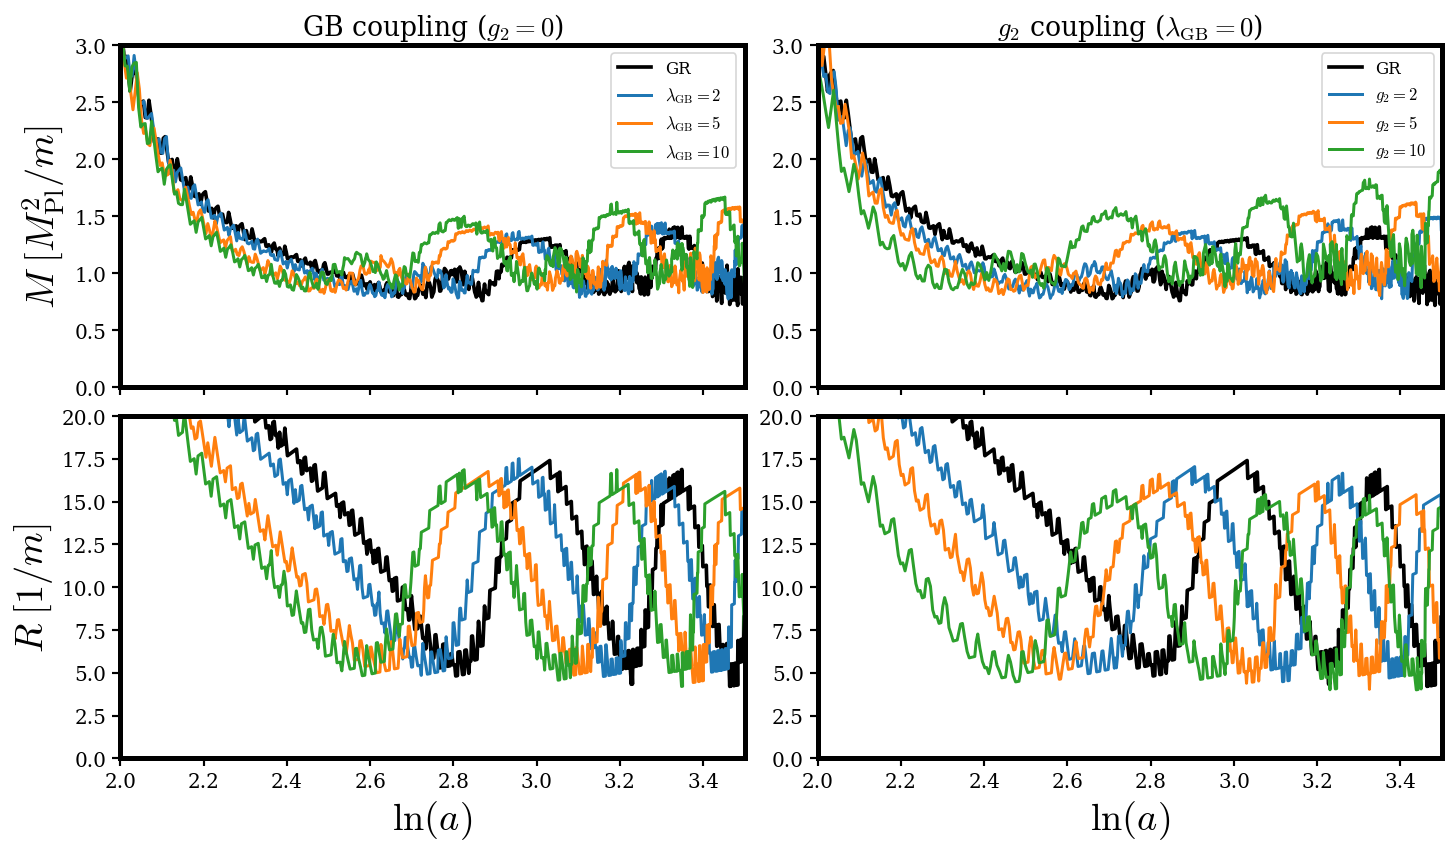

In [24]:
# Panel — M(t) and R(t) stacked, for selected (lgb, g2) combinations.
# Edit P_MR_RUNS to choose which runs to overlay. Each entry is (lgb, g2).
# mu/beta/amp/width are shared across all entries (set below).

P_MR_MU    = 0.08
P_MR_BETA  = 0
P_MR_AMP   = -0.02
P_MR_WIDTH = 3.0

# Left panel: nonzero GB coupling (g2=0). List lgb values.
P_MR_LGB_RUNS = [2, 5, 10]

# Right panel: nonzero g2 coupling (lgb=0). List g2 values.
P_MR_G2_RUNS  = [2, 5, 10]

P_MR_LNA_MIN  = 2.0
P_MR_LNA_MAX  = 3.5
P_MR_LNA_FORM = 2.0
P_MR_NAME     = "M_R_vs_lna_compare"

fig_mr, axes_mr = plt.subplots(2, 2, figsize=(12, 7), sharex=True,
                                constrained_layout=True)
ax_M_l, ax_M_r = axes_mr[0]
ax_R_l, ax_R_r = axes_mr[1]

_tab10_mr = plt.cm.tab10

def _plot_mr_run(lgb_v, g2_v, ax_m, ax_r, color, lw, lbl):
    key_mr = (float(lgb_v), float(P_MR_MU), float(P_MR_BETA),
              float(P_MR_AMP), float(P_MR_WIDTH), float(g2_v))
    if key_mr not in all_runs:
        print(f"Key {key_mr} not found — skipping.")
        return
    run_mr = all_runs[key_mr]
    osc_mr = run_mr["osc"]
    x_mr   = np.asarray(run_mr["shifted_ln_a"])
    ax_m.plot(x_mr, np.asarray(osc_mr["M"]), color=color, lw=lw, label=lbl)
    ax_r.plot(x_mr, np.asarray(osc_mr["R"]), color=color, lw=lw, label=lbl)

# GR on both sides
_plot_mr_run(0, 0, ax_M_l, ax_R_l, "k", 2.2, "GR")
_plot_mr_run(0, 0, ax_M_r, ax_R_r, "k", 2.2, "GR")

# Left: GB coupling runs (g2=0)
for i, lgb_v in enumerate(P_MR_LGB_RUNS):
    color = _tab10_mr(i % 10)
    lbl = rf"$\lambda_{{\rm GB}}={lgb_v:g}$"
    _plot_mr_run(lgb_v, 0, ax_M_l, ax_R_l, color, 1.8, lbl)

# Right: g2 coupling runs (lgb=0)
for i, g2_v in enumerate(P_MR_G2_RUNS):
    color = _tab10_mr(i % 10)
    lbl = rf"$g_2={g2_v:g}$"
    _plot_mr_run(0, g2_v, ax_M_r, ax_R_r, color, 1.8, lbl)

ax_M_l.set_ylabel(r"$M \; [M_{\rm Pl}^2/m]$")
ax_M_l.set_ylim(0,3)
ax_M_r.set_ylim(0,3)
ax_R_l.set_ylim(0,20)
ax_R_r.set_ylim(0,20)

ax_R_l.set_ylabel(r"$R \; [1/m]$")
ax_R_l.set_xlabel(r"$\ln(a)$")
ax_R_r.set_xlabel(r"$\ln(a)$")
ax_M_l.set_title(r"GB coupling ($g_2=0$)")
ax_M_r.set_title(r"$g_2$ coupling ($\lambda_{\rm GB}=0$)")
for ax in axes_mr.flat:
    ax.axvline(P_MR_LNA_FORM, color="grey", ls=":", lw=1.4, alpha=0.8)
    ax.set_xlim(P_MR_LNA_MIN, P_MR_LNA_MAX)

ax_M_l.legend(fontsize=10, loc="best", frameon=True)
ax_M_r.legend(fontsize=10, loc="best", frameon=True)

save_fig(fig_mr, P_MR_NAME)
plt.show()

  saved M_R_vs_lna_compare_ramp.pdf and M_R_vs_lna_compare_ramp.png


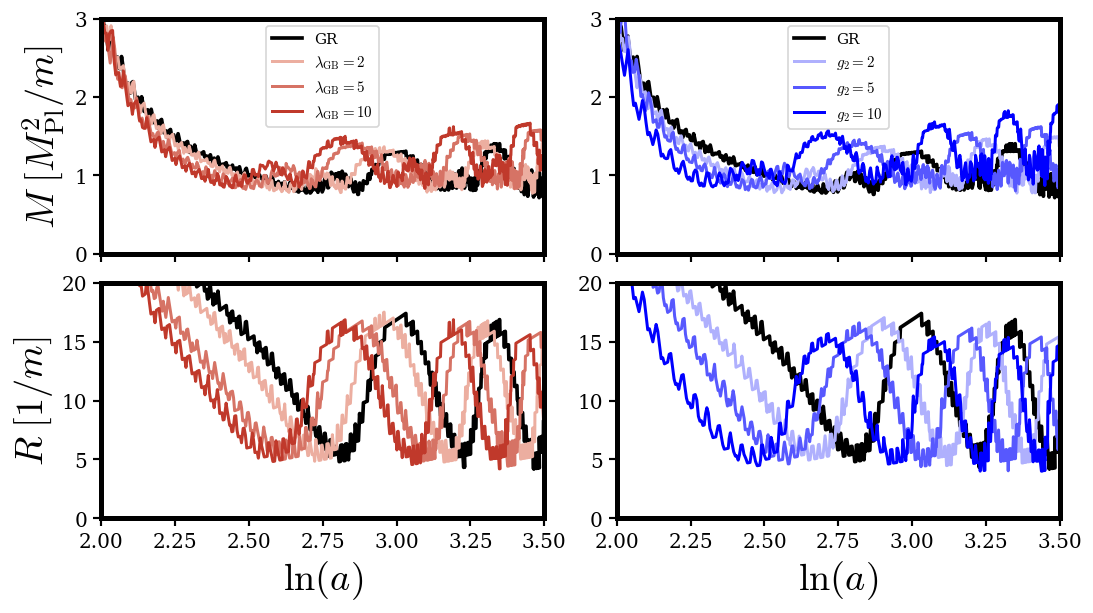

In [25]:
# Same as above but with red ramp for GB (left) and blue ramp for g2 (right).
from matplotlib.colors import LinearSegmentedColormap as _LSC

_REDS_MR  = _LSC.from_list("_lgb_reds_mr",  ["#fee0d2", "#c0392b"])
_BLUES_MR = _LSC.from_list("_g2_blues_mr",  ["#fafbfc", "blue"])

fig_mr2, axes_mr2 = plt.subplots(2, 2, figsize=(9, 5), sharex=True,
                                  constrained_layout=True)
ax_M_l2, ax_M_r2 = axes_mr2[0]
ax_R_l2, ax_R_r2 = axes_mr2[1]

def _plot_mr_run2(lgb_v, g2_v, ax_m, ax_r, color, lw, lbl):
    key_mr = (float(lgb_v), float(P_MR_MU), float(P_MR_BETA),
              float(P_MR_AMP), float(P_MR_WIDTH), float(g2_v))
    if key_mr not in all_runs:
        print(f"Key {key_mr} not found — skipping.")
        return
    run_mr = all_runs[key_mr]
    osc_mr = run_mr["osc"]
    x_mr   = np.asarray(run_mr["shifted_ln_a"])
    ax_m.plot(x_mr, np.asarray(osc_mr["M"]), color=color, lw=lw, label=lbl)
    ax_r.plot(x_mr, np.asarray(osc_mr["R"]), color=color, lw=lw, label=lbl)

# GR on both sides
_plot_mr_run2(0, 0, ax_M_l2, ax_R_l2, "k", 2.2, "GR")
_plot_mr_run2(0, 0, ax_M_r2, ax_R_r2, "k", 2.2, "GR")

# Left: GB coupling runs — red ramp
_n_lgb = len(P_MR_LGB_RUNS)
for i, lgb_v in enumerate(P_MR_LGB_RUNS):
    frac = 0.30 + 0.70 * i / max(_n_lgb - 1, 1)
    color = _REDS_MR(frac)
    lbl = rf"$\lambda_{{\rm GB}}={lgb_v:g}$"
    _plot_mr_run2(lgb_v, 0, ax_M_l2, ax_R_l2, color, 1.8, lbl)

# Right: g2 coupling runs — blue ramp
_n_g2 = len(P_MR_G2_RUNS)
for i, g2_v in enumerate(P_MR_G2_RUNS):
    frac = 0.30 + 0.70 * i / max(_n_g2 - 1, 1)
    color = _BLUES_MR(frac)
    lbl = rf"$g_2={g2_v:g}$"
    _plot_mr_run2(0, g2_v, ax_M_r2, ax_R_r2, color, 1.8, lbl)

ax_M_l2.set_ylabel(r"$M \; [M_{\rm Pl}^2/m]$")
ax_M_l2.set_ylim(0, 3)
ax_M_r2.set_ylim(0, 3)
ax_R_l2.set_ylim(0, 20)
ax_R_r2.set_ylim(0, 20)

ax_R_l2.set_ylabel(r"$R \; [1/m]$")
ax_R_l2.set_xlabel(r"$\ln(a)$")
ax_R_r2.set_xlabel(r"$\ln(a)$")
#ax_M_l2.set_title(r"GB coupling ($g_2=0$)")
#ax_M_r2.set_title(r"$g_2$ coupling ($\lambda_{\rm GB}=0$)")

for ax in axes_mr2.flat:
    ax.axvline(P_MR_LNA_FORM, color="grey", ls=":", lw=1.4, alpha=0.8)
    ax.set_xlim(P_MR_LNA_MIN, P_MR_LNA_MAX)

ax_M_l2.legend(fontsize=9, loc="best", frameon=True)
ax_M_r2.legend(fontsize=9, loc="best", frameon=True)

save_fig(fig_mr2, P_MR_NAME + "_ramp")
plt.show()

## Panel 4a — Max compactness heatmap over $(\lambda_{\rm GB},\, g_2)$

2D heatmap (discrete blocks) of the maximum compactness $\max_{\ln(a)>2}\mathcal{C}$ for each
available run with $\beta=0$ at the chosen $(\mu, A, R)$. The plot is filled from the runs already
loaded into `all_runs` (so only 1/24 resolution since `FILTER_DR=1/24`); missing cells are shown in
grey and listed under the plot as a TODO list of runs you may want to compute.

Both axes default to integer step (`0, 1, 2, ..., 20`). Change `P4A_STEP_LGB` / `P4A_STEP_G2` to
`2`, `5`, etc. to thin the grid.

In [35]:
### --- Panel 4a selection (edit me) ---
P4A_MU     = 0.08
P4A_BETA   = 0
P4A_AMP    = -0.02
P4A_WIDTH  = 3.0

P4A_LGB_MIN, P4A_LGB_MAX = 0, 10
P4A_G2_MIN,  P4A_G2_MAX  = 0, 20
P4A_STEP_LGB = 2    # 1, 2, 5, ...
P4A_STEP_G2  = 2     # 1, 2, 5, ...

P4A_LNA_MIN  = 2.0   # max compactness measured on shifted_ln_a > this
P4A_CMAP     = "Blues"
P4A_VMIN     = None  # log-norm lower bound; None = auto from data
P4A_VMAX     = None  # log-norm upper bound; None = auto from data
P4A_NLEVELS  = 8     # number of discrete colour blocks (cells + colourbar)

P4A_NAME = "compactness_heatmap_lgb_g2"

P4A_LGB_VALUES = np.arange(P4A_LGB_MIN, P4A_LGB_MAX + P4A_STEP_LGB, P4A_STEP_LGB)
P4A_G2_VALUES  = np.arange(P4A_G2_MIN,  P4A_G2_MAX  + P4A_STEP_G2,  P4A_STEP_G2)

print(f"lgb grid ({len(P4A_LGB_VALUES)} pts): {list(P4A_LGB_VALUES)}")
print(f"g2  grid ({len(P4A_G2_VALUES)} pts): {list(P4A_G2_VALUES)}")
print(f"filter:  beta={P4A_BETA}, mu={P4A_MU}, A={P4A_AMP}, R={P4A_WIDTH}, dr=1/24 (from loader)")

lgb grid (6 pts): [0, 2, 4, 6, 8, 10]
g2  grid (11 pts): [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
filter:  beta=0, mu=0.08, A=-0.02, R=3.0, dr=1/24 (from loader)


Filled 65 / 66 cells.
  saved compactness_heatmap_lgb_g2.pdf and compactness_heatmap_lgb_g2.png


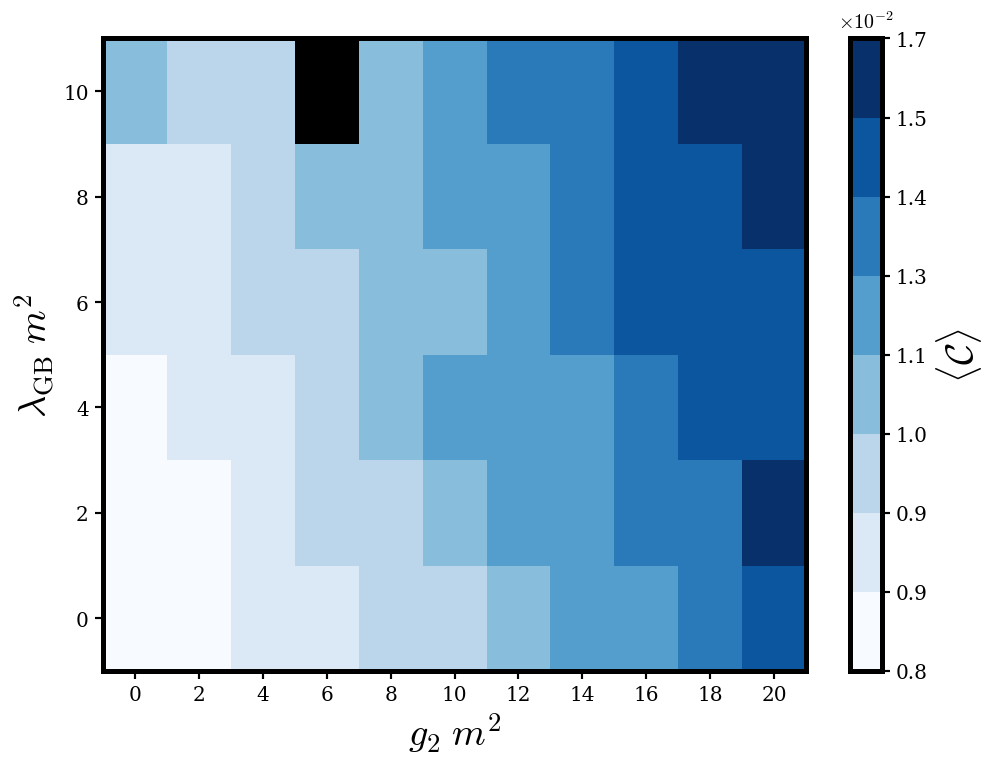


--- Suggested runs to compute (1/24 resolution) ---

Run exists but has no data for shifted_ln_a > 2.0 (1 runs):
  lgb= 10, g2=6


In [9]:
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import FuncFormatter
from collections import defaultdict

ny, nx = len(P4A_LGB_VALUES), len(P4A_G2_VALUES)
Z = np.full((ny, nx), np.nan)

missing_no_run     = []
missing_no_late_C  = []
for i, lgb in enumerate(P4A_LGB_VALUES):
    for j, g2 in enumerate(P4A_G2_VALUES):
        key = (float(lgb), float(P4A_MU), float(P4A_BETA),
               float(P4A_AMP), float(P4A_WIDTH), float(g2))
        if key not in all_runs:
            missing_no_run.append((int(lgb), float(g2)))
            continue
        d   = all_runs[key]
        sln = d["shifted_ln_a"]
        C   = np.asarray(d["osc"]["C"])
        m   = sln > P4A_LNA_MIN
        if m.any() and np.isfinite(C[m]).any():
            Z[i, j] = float(np.nanmax(C[m]))
        else:
            missing_no_late_C.append((int(lgb), float(g2)))

filled = int(np.isfinite(Z).sum())
print(f"Filled {filled} / {ny*nx} cells.")

# Cell edges (half-step on each side of every grid point)
def _edges(vals, step):
    v = np.asarray(vals, dtype=float)
    return np.concatenate([v - step / 2.0, v[-1:] + step / 2.0])
g2_edges  = _edges(P4A_G2_VALUES,  P4A_STEP_G2)
lgb_edges = _edges(P4A_LGB_VALUES, P4A_STEP_LGB)

finite = Z[np.isfinite(Z) & (Z > 0)]
vmin = P4A_VMIN if P4A_VMIN is not None else (float(finite.min()) if finite.size else 1e-4)
vmax = P4A_VMAX if P4A_VMAX is not None else (float(finite.max()) if finite.size else 1e-1)

# Log-spaced discrete levels -> discrete cells AND discrete colourbar blocks.
levels = np.logspace(np.log10(vmin), np.log10(vmax), P4A_NLEVELS + 1)
cmap   = plt.get_cmap(P4A_CMAP, P4A_NLEVELS).copy()
cmap.set_bad("black")
norm   = BoundaryNorm(boundaries=levels, ncolors=P4A_NLEVELS)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
pc = ax.pcolormesh(g2_edges, lgb_edges, Z, shading="flat",
                   norm=norm, cmap=cmap)
_CBAR_SCALE = 1e-2
cbar = fig.colorbar(pc, ax=ax, ticks=levels, spacing="uniform",
                    format=FuncFormatter(lambda v, _pos: f"{v / _CBAR_SCALE:.1f}"))
#cbar.set_label(r"$\max\;\mathcal{C}$")
cbar.set_label(r"$\langle\mathcal{C}\rangle$")
cbar.ax.set_title(r"$\times 10^{-2}$", fontsize=12, pad=6)

ax.set_xlabel(r"$g_2\;m^2$")
ax.set_ylabel(r"$\lambda_{\rm GB}\;m^2$")
#ax.set_title(rf"Max compactness vs $(\lambda_{{\rm GB}},\, g_2)$; "rf"$\beta={P4A_BETA},\ \mu={P4A_MU},\ A={P4A_AMP},\ R={P4A_WIDTH}$")
ax.set_xticks(P4A_G2_VALUES)
ax.set_yticks(P4A_LGB_VALUES)
ax.set_aspect("auto")
ax.grid(False)

fig.tight_layout()
save_fig(fig, P4A_NAME)
plt.show()

# Suggested runs: missing (lgb, g2) cells
if missing_no_run or missing_no_late_C:
    print("\n--- Suggested runs to compute (1/24 resolution) ---")
    if missing_no_run:
        by_lgb = defaultdict(list)
        for lgb, g2 in missing_no_run:
            by_lgb[lgb].append(g2)
        print(f"\nMissing entirely ({len(missing_no_run)} runs):")
        for lgb in sorted(by_lgb):
            print(f"  lgb={lgb:>3d}: g2 = {by_lgb[lgb]}")
    if missing_no_late_C:
        print(f"\nRun exists but has no data for shifted_ln_a > {P4A_LNA_MIN} ({len(missing_no_late_C)} runs):")
        for lgb, g2 in sorted(missing_no_late_C):
            print(f"  lgb={lgb:>3d}, g2={g2:g}")
else:
    print("\nAll requested cells are filled.")

In [24]:
# === Panel 4a (normalized to GR) ============================================
# Same heatmap as the cell above, but:
#   * Z is normalized to the GR cell  Z[lgb=0, g2=0]:  shows  <C> / <C>_GR.
#   * x- and y-axis values are divided by 2 (rescaled couplings).
#   * Colorbar label is the ratio fraction, written upright (rotation=0)
#     instead of the default 90° sideways orientation.
#   * Grey "Outside of EFT regime" shading at the same boundary as the
#     side-by-side compactness plot:  g2/2 = 5.5/2 = 2.75.
# ============================================================================
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import FuncFormatter

ny, nx = len(P4A_LGB_VALUES), len(P4A_G2_VALUES)
Z = np.full((ny, nx), np.nan)
for i, lgb in enumerate(P4A_LGB_VALUES):
    for j, g2 in enumerate(P4A_G2_VALUES):
        key = (float(lgb), float(P4A_MU), float(P4A_BETA),
               float(P4A_AMP), float(P4A_WIDTH), float(g2))
        if key not in all_runs:
            continue
        d   = all_runs[key]
        sln = d["shifted_ln_a"]
        C   = np.asarray(d["osc"]["C"])
        m   = sln > P4A_LNA_MIN
        if m.any() and np.isfinite(C[m]).any():
            Z[i, j] = float(np.nanmax(C[m]))

# GR baseline: cell at (lgb=0, g2=0).
try:
    i_gr = list(P4A_LGB_VALUES).index(0)
    j_gr = list(P4A_G2_VALUES).index(0)
    Z_GR = Z[i_gr, j_gr]
except ValueError:
    Z_GR = np.nan

if not np.isfinite(Z_GR) or Z_GR <= 0:
    print("⚠ GR baseline (lgb=0, g2=0) unavailable; cannot build normalized heatmap.")
else:
    Z_norm = Z / Z_GR

    # Halve every axis quantity.
    G2_VALUES_D2  = np.asarray(P4A_G2_VALUES,  dtype=float) / 2.0
    LGB_VALUES_D2 = np.asarray(P4A_LGB_VALUES, dtype=float) / 2.0

    # Patch the missing (lambda=5, g_2=3) cell with the mean of its two
    # g_2-neighbours at the same lambda. Indices are looked up in the
    # *halved* axes so the values match the plot's tick labels directly.
    _ip = np.where(np.isclose(LGB_VALUES_D2, 5.0))[0]
    _jp = np.where(np.isclose(G2_VALUES_D2,  3.0))[0]
    _jl = np.where(np.isclose(G2_VALUES_D2,  2.0))[0]
    _jh = np.where(np.isclose(G2_VALUES_D2,  4.0))[0]
    if _ip.size and _jp.size and _jl.size and _jh.size:
        _i, _jp0, _jl0, _jh0 = _ip[0], _jp[0], _jl[0], _jh[0]
        if not np.isfinite(Z_norm[_i, _jp0]):
            Z_norm[_i, _jp0] = 0.5 * (Z_norm[_i, _jl0] + Z_norm[_i, _jh0])
            print(f"  patched Z_norm[lambda=5, g_2=3] = "
                  f"0.5*(Z_norm[lambda=5,g_2=2] + Z_norm[lambda=5,g_2=4]) "
                  f"= {Z_norm[_i, _jp0]:.4f}")
    STEP_G2_D2    = P4A_STEP_G2  / 2.0
    STEP_LGB_D2   = P4A_STEP_LGB / 2.0

    def _edges_d2(vals, step):
        v = np.asarray(vals, dtype=float)
        return np.concatenate([v - step / 2.0, v[-1:] + step / 2.0])
    g2_edges_d2  = _edges_d2(G2_VALUES_D2,  STEP_G2_D2)
    lgb_edges_d2 = _edges_d2(LGB_VALUES_D2, STEP_LGB_D2)

    finite = Z_norm[np.isfinite(Z_norm) & (Z_norm > 0)]
    P4AN_VMIN = float(finite.min()) if finite.size else 1e-2
    P4AN_VMAX = float(finite.max()) if finite.size else 1e1
    levels = np.logspace(np.log10(P4AN_VMIN), np.log10(P4AN_VMAX), P4A_NLEVELS + 1)
    cmap   = plt.get_cmap(P4A_CMAP, P4A_NLEVELS).copy()
    cmap.set_bad("black")
    norm   = BoundaryNorm(boundaries=levels, ncolors=P4A_NLEVELS)

    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    pc = ax.pcolormesh(g2_edges_d2, lgb_edges_d2, Z_norm, shading="flat",
                       norm=norm, cmap=cmap)

    cbar = fig.colorbar(pc, ax=ax, ticks=levels, spacing="uniform",
                        format=FuncFormatter(lambda v, _pos: f"{v:.2f}"))
    cbar.set_label(
        r"$\dfrac{\langle\mathcal{C}\rangle}{\langle\mathcal{C}\rangle_{\rm GR}}$",
        rotation=0, labelpad=26, fontsize=16,
    )

    ax.set_xlabel(r"$g_2\;[m^2]$")
    ax.set_ylabel(r"$\lambda_{\rm GB}\;[m^2]$")
    ax.set_xticks(G2_VALUES_D2)
    ax.set_yticks(LGB_VALUES_D2)
    ax.set_aspect("auto")
    ax.grid(False)
    
    # Grey "Outside of EFT regime" region — same boundary as the side-by-side
    # compactness plot uses:  _eft_x = 5.5 / 2.0  in the rescaled g2 units.

    _eft_x =11/2
    ax.axvline(_eft_x, color="black", ls="--", lw=3, zorder=5)
    _xmax = ax.get_xlim()[1]
    ax.axvspan(_eft_x, _xmax, color="grey", alpha=0.6, zorder=4)
    ax.set_frame_on(True)
    for _sp in ax.spines.values():
        _sp.set_zorder(10)
    ax.text(6, 0.07, "Outside of EFT regime",
          va="center", ha="left", fontsize=12, color="black", zorder=11)


    fig.tight_layout()
    save_fig(fig, P4A_NAME + "_normGR")
    plt.show()


NameError: name 'P4A_LGB_VALUES' is not defined

  saved panel4a_radial_compare.pdf and panel4a_radial_compare.png


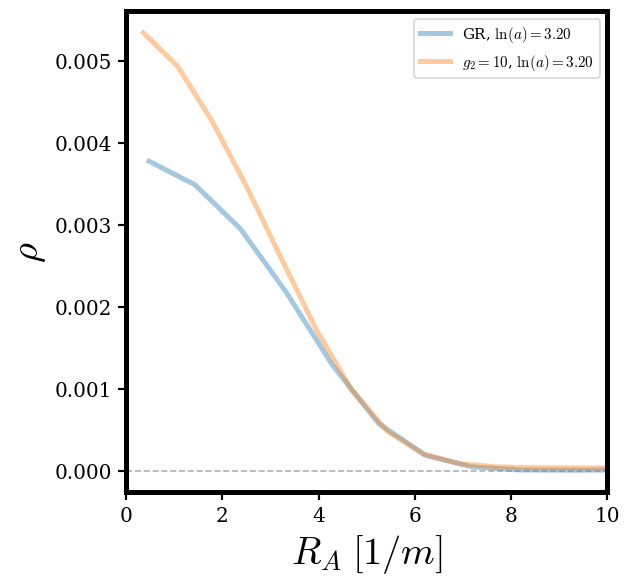

In [143]:
# Panel 4a-spatial (radial only) — overlay radial rho(r) profiles from
# two different parameter combinations at different times on a single plot.
#
# Each entry in P4A8_COMPARE is a dict with:
#   "lgb", "g2"   — which run to use (mu/beta/amp/width from Panel 4a selection)
#   "snaps"       — list of ln(a) values at which to draw profiles
#   "color"       — base color for this run's curves
#   "label_prefix"— string prepended to legend entries

P4A8_COMPARE = [
    dict(lgb=0,  g2=0,  snaps=[3.2], color="tab:blue",  lw=5, label_prefix=r"GR"),
    dict(lgb=0,  g2=10, snaps=[3.2], color="tab:orange", lw=5, label_prefix=r"$g_2=10$"),
]

P4A8C_R_MAX          = 20
P4A8C_USE_OSC_RADIUS = False
P4A8C_USE_AREAL_R    = True   # True = x-axis is areal radius R_A; False = coordinate r
P4A8C_X_NORM_MAX     = 5.0
P4A8C_NAME           = "panel4a_radial_compare"

fig, ax = plt.subplots(figsize=(6, 5))
ax.set_box_aspect(1)

from bssn.bssnstatevariables import idx_phi, idx_htt, NUM_BSSN_VARS

for entry in P4A8_COMPARE:
    key_c = (float(entry["lgb"]), float(P4A_MU), float(P4A_BETA),
             float(P4A_AMP), float(P4A_WIDTH), float(entry["g2"]))
    if key_c not in all_runs:
        print(f"Key {key_c} not found — skipping.")
        continue
    run_c  = all_runs[key_c]
    osc_c  = run_c["osc"]
    r_c    = np.asarray(osc_c["r"])
    ln_a_c = np.asarray(run_c["shifted_ln_a"])
    rho_c  = np.asarray(osc_c["rho"])
    R_osc_c = np.asarray(osc_c["R"])

    # Load solution for areal radius if needed
    _sol_c = None
    if P4A8C_USE_AREAL_R:
        _sol_path = os.path.join(run_c["run_dir"], "solution.npy")
        _sol_c = np.load(_sol_path)
        _N_grid = len(r_c)

    base_color = entry["color"]
    snaps_c    = entry["snaps"]
    n_snaps    = len(snaps_c)

    for j, snap_lna in enumerate(snaps_c):
        idx_c = int(np.argmin(np.abs(ln_a_c - snap_lna)))
        lna_v = ln_a_c[idx_c]
        yprof = rho_c[idx_c]
        alpha = 0.4 + 0.6 * j / max(n_snaps - 1, 1)

        if P4A8C_USE_AREAL_R:
            # Extract phi and htt from state vector at this time step
            _state_i = _sol_c[idx_c].reshape(-1, _N_grid)
            _phi_i = _state_i[idx_phi]
            _htt_i = _state_i[idx_htt]
            # R_areal = e^{2 phi} * r * sqrt(1 + htt)
            _e2phi = np.exp(2.0 * _phi_i)
            x_axis = _e2phi * r_c * np.sqrt(np.maximum(1.0 + _htt_i, 1e-30))
            x_mask = (r_c >= 0) & (x_axis <= P4A8C_R_MAX)
        elif P4A8C_USE_OSC_RADIUS:
            R_osc = R_osc_c[idx_c]
            if R_osc <= 0:
                print(f"Skipping {entry['label_prefix']} ln(a)={lna_v:.2f}: R_osc={R_osc:.3g}")
                continue
            x_axis = r_c / R_osc
            x_mask = (r_c >= 0) & (x_axis <= P4A8C_X_NORM_MAX)
        else:
            x_axis = r_c
            x_mask = (r_c >= 0) & (r_c <= P4A8C_R_MAX)

        lbl = rf"{entry['label_prefix']}, $\ln(a)={lna_v:.2f}$"
        ax.plot(x_axis[x_mask], yprof[x_mask], color=base_color,
                lw=3, alpha=alpha, label=lbl)

    del _sol_c

ax.axhline(0.0, color="grey", ls="--", lw=1.0, alpha=0.6)
if P4A8C_USE_AREAL_R:
    ax.set_xlabel(r"$R_A \; [1/m]$")
    ax.set_xlim(0, P4A8C_R_MAX)
elif P4A8C_USE_OSC_RADIUS:
    ax.axvline(1.0, color="grey", ls=":", lw=1.2, alpha=0.7)
    ax.set_xlabel(r"$r / R_{\rm osc}(t)$")
    ax.set_xlim(0, P4A8C_X_NORM_MAX)
else:
    ax.set_xlabel(r"$r \; [1/m]$")
    ax.set_xlim(0, P4A8C_R_MAX)
ax.set_ylabel(r"$\rho$")
ax.set_xlim(0,10)
ax.legend(fontsize=9, loc="best", frameon=True)

fig.tight_layout()
save_fig(fig, P4A8C_NAME)
plt.show()

## Panel 4 — Compactness, weak-coupling and $g_2$ hyperbolicity

Three stacked panels sharing the x-axis (aligned $\ln(a)$, fixed to $[2,\,3.5]$):
1. Compactness $\mathcal{C}$
2. Weak-coupling condition $\max_r \sqrt{|\lambda'|}\,L^{-1}$ (and $\sqrt{|g_2|}\,\tilde L^{-1}$ dashed where $g_2 \neq 0$)
3. $g_2$ hyperbolicity: $\min_r$ of $\det(g^{\rm eff}_{\mu\nu})/\det(g_{\mu\nu})$

GR (`lgb=0, g2=0`) is drawn as a thick black line. EFT diagnostics are computed (and cached
on disk) only for the selected runs. Set `FORCE_EFT_RECOMPUTE = True` to overwrite the
cached `eft_diagnostics.npz`.

In [54]:
### --- Panel 4 selection (edit me) ---
"""PLOT4_KEYS = select_runs(
    lgb   = [0],
    mu    = [0.08],
    beta  = [250],
    amp   = [-0.02],
    width = [3.0],
    g2    = [0,10, -8],
)"""

PLOT4_KEYS = select_runs(
    lgb   = [0],
    mu    = [0.08],
    beta  = [0],
    amp   = [-0.02],
    width = [3.0],
    g2    = [0,34],
)

PLOT4_NAME = "rho_C_WCC_hyp"

PLOT4_USE_TAB_COLORS = False   # False = blue ramp; True = tab10 cycle (tab:blue, orange, green, ...)

# Optional: highlight a specific run in a distinct color, plotted behind the others.
# Set to a key tuple e.g. (0, 0.08, 250, -0.02, 3.0, 10) or None to disable.
#PLOT4_HIGHLIGHT_KEY   = None
PLOT4_HIGHLIGHT_KEY   = (0, 0.08, 250, -0.02, 3.0, 34)
PLOT4_HIGHLIGHT_COLOR = "red"
PLOT4_HIGHLIGHT_LW    = 2
PLOT4_HIGHLIGHT_ALPHA = 0.3

R_WCC_MAX           = 100.0   # only consider r in (0, R_WCC_MAX] for WCC / hyperbolicity maxima
FORCE_EFT_RECOMPUTE = True   # True = ignore any cached eft_diagnostics.npz and recompute

# Middle panel (weak-coupling condition) y-axis options.
PLOT4_WCC_LOG          = True            # True -> log y; False -> linear y
PLOT4_WCC_YLIM_LOG     = (1e-3, 1e1)     # used when PLOT4_WCC_LOG is True
PLOT4_WCC_YLIM_LINEAR  = (0.0, 1.2)      # used when PLOT4_WCC_LOG is False

print(f"{len(PLOT4_KEYS)} run(s) selected for Panel 4:")
for k in PLOT4_KEYS:
    print(" ", k, " coupling=", all_runs[k]["coupling"], " g2=", k[5])

# Compute / load EFT diagnostics only for the selected runs
for k in PLOT4_KEYS:
    d = all_runs[k]
    if "eft" in d and not FORCE_EFT_RECOMPUTE:
        continue
    run_dir  = d["run_dir"]
    eft_path = os.path.join(run_dir, "eft_diagnostics.npz")
    if os.path.exists(eft_path) and not FORCE_EFT_RECOMPUTE:
        d["eft"] = dict(np.load(eft_path, allow_pickle=True))
        print(f"  [EFT] loaded cache for {d['tag']}")
    else:
        sol_i    = np.load(os.path.join(run_dir, "solution.npy"))
        matter_i = ScalarMatter(scalar_mu, d["mu"])
        sv_i     = StateVector(matter_i)
        spacing_i = CubicSpacing(**CubicSpacing.get_parameters(
            d["run_r_max"], d["run_min_dr"], d["run_max_dr"]))
        grid_i   = Grid(spacing_i, sv_i)
        bg_i     = FlatSphericalBackground(grid_i.r)
        lgb_k, mu_k, beta_k, amp_k, width_k, g2_k = k
        params = (lgb_k, a_mg, b_mg, chi0, d["coupling"], g2_k)
        eft = get_eft_diagnostic(
            sol_i, d["t"], grid_i, bg_i,
            ScalarMatter(scalar_mu, d["mu"]),
            params,
        )
        np.savez(eft_path, **eft)
        d["eft"] = eft
        del sol_i
        verb = "recomputed" if FORCE_EFT_RECOMPUTE else "computed"
        print(f"  [EFT] {verb} & cached for {d['tag']}")

1 run(s) selected for Panel 4:
  (0.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0  g2= 0.0
  [EFT] recomputed & cached for lgb0.0_mu0.08_a0.0_b0.0_amp-0.02_R3.0_dr0.041666666666666664_quadratic_0


No keys selected for Panel 4.


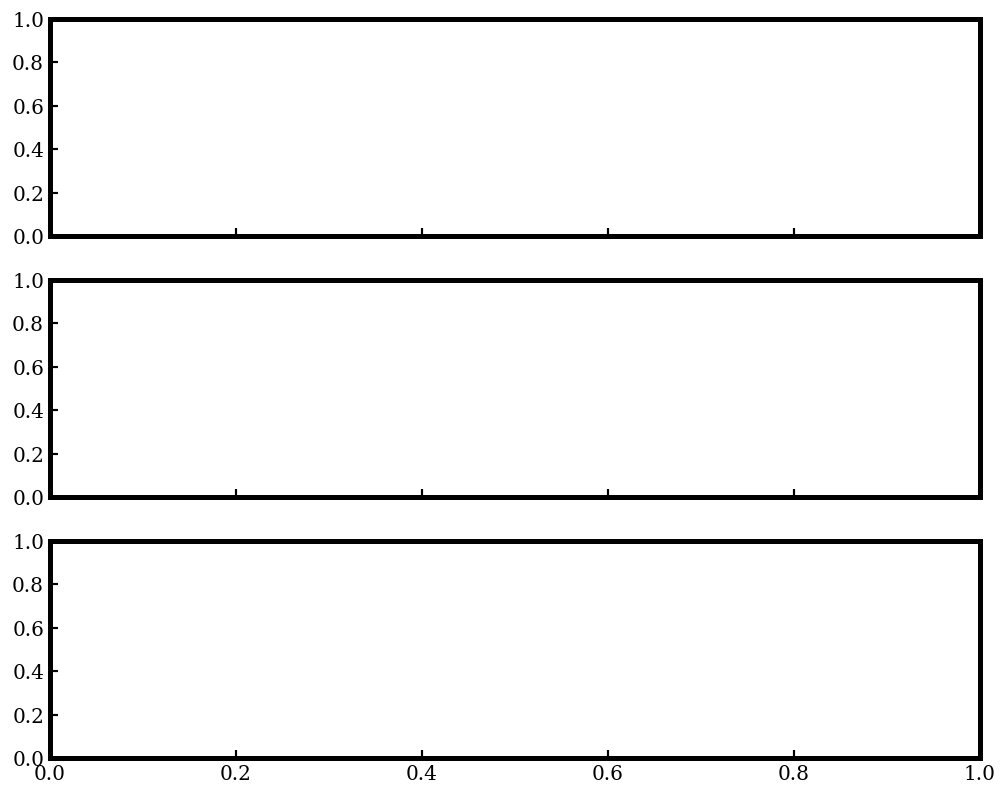

In [52]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Curves coloured by g2 magnitude: light blue = weak g2, dark blue = strong g2.
# The darkest shade is the matplotlib named colour "blue" (matching the blue
# used in Panel 4d's right axes) and is assigned to the *highest* selected g2.
# GR (lgb=0, g2=0) still overrides to black.
from matplotlib.colors import LinearSegmentedColormap as _LSC
_unique_g2  = sorted({k[5] for k in PLOT4_KEYS})
_BLUES_RAMP = _LSC.from_list("_g2_blues", ["#fafbfc", "blue"])
_TAB10 = plt.cm.tab10

def _color_for_g2(g2_val):
    if PLOT4_USE_TAB_COLORS:
        rank = _unique_g2.index(g2_val)
        return _TAB10(rank % 10)
    if len(_unique_g2) <= 1:
        return _BLUES_RAMP(1.0)
    rank = _unique_g2.index(g2_val)
    frac = 0.30 + 0.70 * rank / (len(_unique_g2) - 1)
    return _BLUES_RAMP(frac)

def _rmask_for_eft(eft, r_cut=R_WCC_MAX):
    """Build (r > 0) & (r <= r_cut) from this run's own eft["r"], so runs
    with different grids (e.g. different r_max) don't share a mask."""
    if eft is None or "r" not in eft:
        return None
    r = np.asarray(eft["r"])
    return (r > 0) & (r <= r_cut)

if len(PLOT4_KEYS) == 0:
    print("No keys selected for Panel 4.")
else:
    # Draw highlighted run first (behind everything) if requested
    _highlight_legend_handle = None
    if PLOT4_HIGHLIGHT_KEY is not None and PLOT4_HIGHLIGHT_KEY in all_runs:
        _hk  = PLOT4_HIGHLIGHT_KEY
        _hr  = all_runs[_hk]
        _ho  = _hr["osc"]
        _he  = _hr.get("eft", None)
        _hx  = _hr["shifted_ln_a"]
        _h_rmask = _rmask_for_eft(_he)
        _hlgb, _hmu, _hbeta, _hamp, _hwidth, _hg2 = _hk
        _hlbl = rf"$g_2\;m^2={_hg2/2:g}$"
        _hl, = axes[0].plot(_hx, _ho["C"], color=PLOT4_HIGHLIGHT_COLOR,
                     lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                     zorder=1)
        _highlight_legend_handle = (_hl, _hlbl)
        if _he is not None and _h_rmask is not None:
            _hwc = np.nanmax(_he["wc_lambda_bare"][:, _h_rmask], axis=1)
            axes[1].plot(_hx, _hwc, color=PLOT4_HIGHLIGHT_COLOR,
                         lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                         zorder=1)
            if _hg2 != 0 and "wc_g2_bare" in _he:
                _hwcg2 = np.nanmax(_he["wc_g2_bare"][:, _h_rmask], axis=1)
                axes[1].plot(_hx, _hwcg2, color=PLOT4_HIGHLIGHT_COLOR,
                             lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                             ls="-", zorder=1)
        if _he is not None and "disc_g2" in _he and _h_rmask is not None:
            _hdisc = np.nanmin(_he["disc_g2"][:, _h_rmask], axis=1)
            axes[2].plot(_hx, _hdisc, color=PLOT4_HIGHLIGHT_COLOR,
                         lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                         zorder=1)

    for i, key in enumerate(PLOT4_KEYS):
        run = all_runs[key]
        osc = run["osc"]
        eft = run.get("eft", None)
        lgb, mu, beta, amp, width, g2 = key

        is_gr = (lgb == 0.0 and g2 == 0.0)
        beta_str = rf", \beta={int(beta)}" if (beta is not None and beta != 250) else ""
        g2_str   = rf"g_2\;m^2={g2/2:g}"
        if is_gr:
            label = rf"GR, ${g2_str}$"
        else:
            label = rf"${g2_str}$"
        if is_gr:
            color = "k"
        elif PLOT4_USE_TAB_COLORS:
            color = _TAB10(i % 10)
        else:
            color = _color_for_g2(g2)
        lw    = 2.2 if is_gr else 1.8

        x = run["shifted_ln_a"]
        r_mask_run = _rmask_for_eft(eft)

        # Panel 0: compactness
        axes[0].plot(x, osc["C"], color=color, lw=lw, label=label, zorder=5)

        # Panel 1: weak-coupling conditions (need eft data)
        if eft is not None and r_mask_run is not None:
            wc_lam = np.nanmax(eft["wc_lambda_bare"][:, r_mask_run], axis=1)
            axes[1].plot(x, wc_lam, color=color, lw=lw, label=label, zorder=5)
            if g2 != 0 and "wc_g2_bare" in eft:
                wc_g2 = np.nanmax(eft["wc_g2_bare"][:, r_mask_run], axis=1)
                axes[1].plot(x, wc_g2, color=color, lw=2, ls="-", alpha=0.85, zorder=5)

        # Panel 2: g2 hyperbolicity
        if eft is not None and "disc_g2" in eft and r_mask_run is not None:
            disc_g2_min = np.nanmin(eft["disc_g2"][:, r_mask_run], axis=1)
            axes[2].plot(x, disc_g2_min, color=color, lw=lw, label=label, zorder=5)

    axes[0].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[0].set_ylabel(r"$\mathcal{C}$", fontsize=16)
    #axes[0].set_title(r"Compactness $\mathcal{C}$")
    #axes[0].grid(False, alpha=0.3)
    axes[0].set_ylim(0, 0.02)

    #axes[1].axhline(1.0, color="k", lw=1.0, ls=":", alpha=0.7)
    axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    #axes[1].set_ylabel(r"$\max_r\,\sqrt{|\mathrm{coupling}|}\,\cdot\, \tilde L^{-1}$")
    #axes[1].set_ylabel(r"$\max_r\,\sqrt{|g_2|}\,\cdot\, \tilde L^{-1}$")
    axes[1].set_ylabel(r"$\sqrt{|g_2(\phi)|}\,\cdot\, \tilde L^{-1}$", fontsize=16)


    #axes[1].set_title(r"Weak-coupling condition") #(GB length scale $L^{-1}$; $g_2$ length scale $\tilde L^{-1}$, dashed)")
    if PLOT4_WCC_LOG:
        axes[1].set_yscale("log")
        axes[1].set_ylim(*PLOT4_WCC_YLIM_LOG)
    else:
        axes[1].set_yscale("linear")
        axes[1].set_ylim(*PLOT4_WCC_YLIM_LINEAR)
    #axes[1].grid(False, alpha=0.3)

    axes[2].axhline(0.0, color="k", lw=1.0, ls="--", alpha=0.8)
    axes[2].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[2].set_ylabel(r"$\det(g^{\rm eff}_{\mu\nu})/\det(g_{\mu\nu})$", fontsize=16)
    #axes[2].set_title(r"$g_2$ hyperbolicity") # (min over $r$)")

    #axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].axhspan(0.5, 10, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.8, 0.70, "Outside of EFT regime", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].axhspan(0, -1, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.8, -0.1, "Loss of Hyperbolicity", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)
    



    axes[2].set_ylim(-0.2,1.2)
    #axes[2].grid(False, alpha=0.3)

    axes[2].set_xlabel(r"$\ln(a)$")
    # shared x across all three rows via sharex=True
    axes[0].set_xlim(2, 3.5)

    # Build legend: main curves sorted by g2, then highlighted run last
    _handles, _labels = axes[0].get_legend_handles_labels()
    if _highlight_legend_handle is not None:
        _leg_handles = _handles
        _leg_labels  = _labels
        _leg_handles.append(_highlight_legend_handle[0])
        _leg_labels.append(_highlight_legend_handle[1])
    else:
        _leg_handles = _handles
        _leg_labels  = _labels
    axes[0].legend(_leg_handles, _leg_labels, fontsize=13, ncol=1, loc="upper left")
    #axes[1].legend(fontsize=13, ncol=1, loc="upper left")
    #axes[2].legend(fontsize=13, ncol=1, loc="upper left")

    # Ensure axes borders (spines) are drawn on top of all data
    for ax in axes:
        ax.set_axisbelow(False)
        for spine in ax.spines.values():
            spine.set_zorder(20)

    fig.tight_layout()
    save_fig(fig, PLOT4_NAME)
    plt.show()

No keys selected for Panel 4.


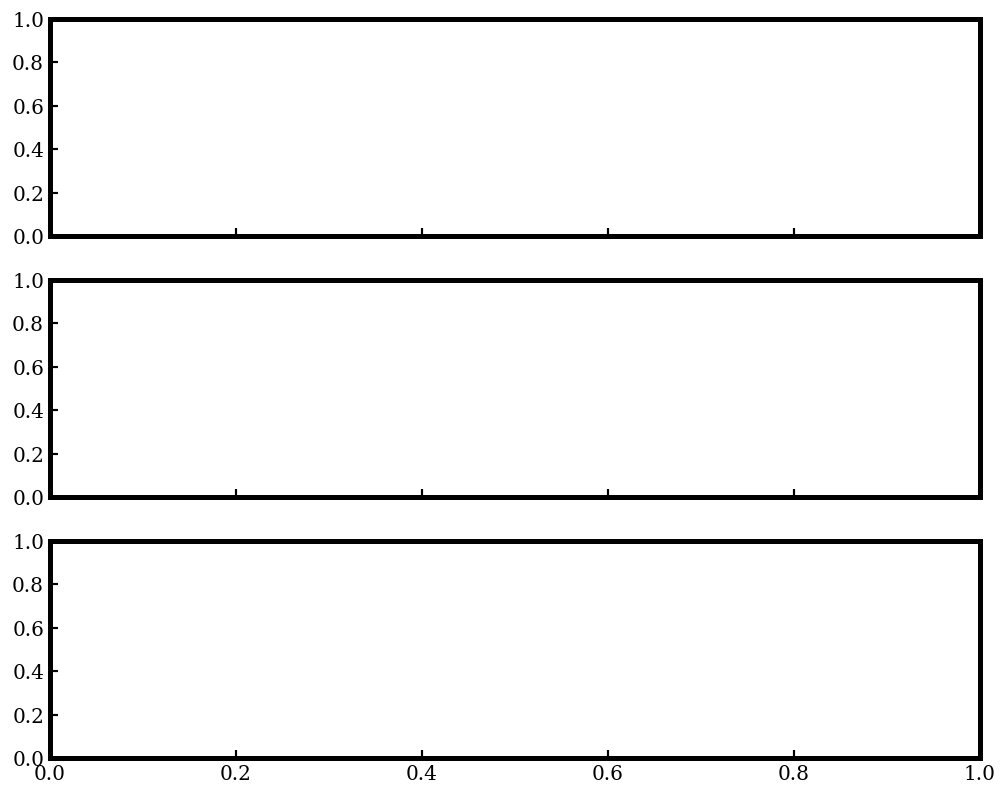

In [53]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Curves coloured by g2 magnitude: light blue = weak g2, dark blue = strong g2.
# The darkest shade is the matplotlib named colour "blue" (matching the blue
# used in Panel 4d's right axes) and is assigned to the *highest* selected g2.
# GR (lgb=0, g2=0) still overrides to black.
from matplotlib.colors import LinearSegmentedColormap as _LSC
_unique_g2  = sorted({k[5] for k in PLOT4_KEYS})
#_BLUES_RAMP = _LSC.from_list("_g2_blues", ["#fafbfc", "blue"])
_BLUES_RAMP = _LSC.from_list("_g2_blues", ["#fafbfc", "blue"])
_TAB10 = plt.cm.tab10

def _color_for_g2(g2_val):
    if PLOT4_USE_TAB_COLORS:
        rank = _unique_g2.index(g2_val)
        return _TAB10(rank % 10)
    if len(_unique_g2) <= 1:
        return _BLUES_RAMP(1.0)
    rank = _unique_g2.index(g2_val)
    frac = 0.30 + 0.70 * rank / (len(_unique_g2) - 1)
    return _BLUES_RAMP(frac)

def _rmask_for_eft(eft, r_cut=R_WCC_MAX):
    """Build (r > 0) & (r <= r_cut) from this run's own eft["r"], so runs
    with different grids (e.g. different r_max) don't share a mask."""
    if eft is None or "r" not in eft:
        return None
    r = np.asarray(eft["r"])
    return (r > 0) & (r <= r_cut)

if len(PLOT4_KEYS) == 0:
    print("No keys selected for Panel 4.")
else:
    # Draw highlighted run first (behind everything) if requested
    _highlight_legend_handle = None
    if PLOT4_HIGHLIGHT_KEY is not None and PLOT4_HIGHLIGHT_KEY in all_runs:
        _hk  = PLOT4_HIGHLIGHT_KEY
        _hr  = all_runs[_hk]
        _ho  = _hr["osc"]
        _he  = _hr.get("eft", None)
        _hx  = _hr["shifted_ln_a"]
        _h_rmask = _rmask_for_eft(_he)
        _hlgb, _hmu, _hbeta, _hamp, _hwidth, _hg2 = _hk
        _hlbl = rf"$g_2\;m^2={_hg2/2:g}$"
        _hl, = axes[0].plot(_hx, _ho["C"], color=PLOT4_HIGHLIGHT_COLOR,
                     lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                     zorder=1)
        _highlight_legend_handle = (_hl, _hlbl)
        if _he is not None and _h_rmask is not None:
            _hwc = np.nanmax(_he["wc_lambda_bare"][:, _h_rmask], axis=1)
            axes[1].plot(_hx, _hwc, color=PLOT4_HIGHLIGHT_COLOR,
                         lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                         zorder=1)
            if _hg2 != 0 and "wc_g2_bare" in _he:
                _hwcg2 = np.nanmax(_he["wc_g2_bare"][:, _h_rmask], axis=1)
                axes[1].plot(_hx, _hwcg2, color=PLOT4_HIGHLIGHT_COLOR,
                             lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                             ls="-", zorder=1)
        if _he is not None and "disc_g2" in _he and _h_rmask is not None:
            _hdisc = np.nanmin(_he["disc_g2"][:, _h_rmask], axis=1)
            axes[2].plot(_hx, _hdisc, color=PLOT4_HIGHLIGHT_COLOR,
                         lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                         zorder=1)

    for i, key in enumerate(PLOT4_KEYS):
        run = all_runs[key]
        osc = run["osc"]
        eft = run.get("eft", None)
        lgb, mu, beta, amp, width, g2 = key

        is_gr = (lgb == 0.0 and g2 == 0.0)
        beta_str = rf", \beta={int(beta)}" if (beta is not None and beta != 250) else ""
        g2_str   = rf"g_2\;m^2={g2/2:g}"
        if is_gr:
            label = rf"GR, ${g2_str}$"
        else:
            label = rf"${g2_str}$"
        if is_gr:
            color = "k"
        elif PLOT4_USE_TAB_COLORS:
            color = _TAB10(i % 10)
        else:
            color = _color_for_g2(g2)
        lw    = 2.2 if is_gr else 1.8

        x = run["shifted_ln_a"]
        r_mask_run = _rmask_for_eft(eft)

        # Panel 0: compactness
        axes[0].plot(x, osc["C"], color=color, lw=lw, label=label, zorder=5)

        # Panel 1: weak-coupling conditions (need eft data)
        if eft is not None and r_mask_run is not None:
            wc_lam = np.nanmax(eft["wc_lambda_bare"][:, r_mask_run], axis=1)
            axes[1].plot(x, wc_lam, color=color, lw=lw, label=label, zorder=5)
            if g2 != 0 and "wc_g2_bare" in eft:
                wc_g2 = np.nanmax(eft["wc_g2_bare"][:, r_mask_run], axis=1)
                axes[1].plot(x, wc_g2, color=color, lw=2, ls="-", alpha=0.85, zorder=5)

        # Panel 2: g2 hyperbolicity
        if eft is not None and "disc_g2" in eft and r_mask_run is not None:
            disc_g2_min = np.nanmin(eft["disc_g2"][:, r_mask_run], axis=1)
            axes[2].plot(x, disc_g2_min, color=color, lw=lw, label=label, zorder=5)

    axes[0].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[0].set_ylabel(r"$\mathcal{C}$")
    #axes[0].set_title(r"Compactness $\mathcal{C}$")
    #axes[0].grid(False, alpha=0.3)
    axes[0].set_ylim(0, 0.02)

    #axes[1].axhline(1.0, color="k", lw=1.0, ls=":", alpha=0.7)
    axes[1].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    #axes[1].set_ylabel(r"$\max_r\,\sqrt{|\mathrm{coupling}|}\,\cdot\, \tilde L^{-1}$")
    #axes[1].set_ylabel(r"$\max_r\,\sqrt{|g_2|}\,\cdot\, \tilde L^{-1}$")
    axes[1].set_ylabel(r"$\sqrt{|g_2(\phi)|}\,\cdot\, \tilde L^{-1}$")


    #axes[1].set_title(r"Weak-coupling condition") #(GB length scale $L^{-1}$; $g_2$ length scale $\tilde L^{-1}$, dashed)")
    if PLOT4_WCC_LOG:
        axes[1].set_yscale("linear")
        axes[1].set_ylim(0,1.2)
    else:
        axes[1].set_yscale("linear")
        axes[1].set_ylim(*PLOT4_WCC_YLIM_LINEAR)
    #axes[1].grid(False, alpha=0.3)

    axes[2].axhline(0.0, color="k", lw=1.0, ls="--", alpha=0.8)
    axes[2].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[2].set_ylabel(r"$\det(g^{\rm eff}_{\mu\nu})/\det(g_{\mu\nu})$")
    #axes[2].set_title(r"$g_2$ hyperbolicity") # (min over $r$)")

    #axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[1].transAxes, axes[1].transData)
    #axes[1].text(0.8, 4, "Outside of EFT regime", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].axhspan(0, -1, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.8, -0.1, "Loss of Hyperbolicity", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)
    



    axes[2].set_ylim(-0.2,1.2)
    #axes[2].grid(False, alpha=0.3)

    axes[2].set_xlabel(r"$\ln(a)$")
    # shared x across all three rows via sharex=True
    axes[0].set_xlim(2, 3.5)

    # Build legend: main curves sorted by g2, then highlighted run last
    _handles, _labels = axes[0].get_legend_handles_labels()
    if _highlight_legend_handle is not None:
        _leg_handles = _handles
        _leg_labels  = _labels
        _leg_handles.append(_highlight_legend_handle[0])
        _leg_labels.append(_highlight_legend_handle[1])
    else:
        _leg_handles = _handles
        _leg_labels  = _labels
    axes[0].legend(_leg_handles, _leg_labels, fontsize=13, ncol=1, loc="upper left")
    #axes[1].legend(fontsize=13, ncol=1, loc="upper left")
    #axes[2].legend(fontsize=13, ncol=1, loc="upper left")



    from matplotlib.ticker import ScalarFormatter
    class _FixedOrderFormatter(ScalarFormatter):
        
        def __init__(self, order=0, **kwargs):
            self._fixed_order = order
            super().__init__(**kwargs)
        def _set_order_of_magnitude(self):
            self.orderOfMagnitude = self._fixed_order
    
    _PLOT8_ORDER = -2
    _fmtL = _FixedOrderFormatter(order=_PLOT8_ORDER, useMathText=True)
    _fmtL.set_scientific(True)
    _fmtL.set_powerlimits((_PLOT8_ORDER, _PLOT8_ORDER))
    axes[0].yaxis.set_major_formatter(_fmtL)



    # Ensure axes borders (spines) are drawn on top of all data
    for ax in axes:
        ax.set_axisbelow(False)
        for spine in ax.spines.values():
            spine.set_zorder(20)

    # Gradient shading in panel 1: lightgrey at y=0.5 fading to white as y increases.
    # Placed after axes[0].set_xlim so extent matches the final displayed x-range.
    '''
    from matplotlib.colors import LinearSegmentedColormap as _LSC_grad
    _eft_grad_cmap = _LSC_grad.from_list(
        "_eft_grad",
        [(1.0, 1.0, 1.0, 1.0),(0.827, 0.827, 0.827, 1)]
    )
    _x0, _x1 = axes[1].get_xlim()
    _y0, _y1 = axes[1].get_ylim()
    _grad = np.linspace(0.0, 1.0, 512).reshape(-1, 1)
    axes[1].imshow(
        _grad, aspect="auto", cmap=_eft_grad_cmap,
        extent=[_x0, _x1, 0.05, _y1], origin="lower",
        interpolation="bilinear", zorder=0,
    )
    # imshow can nudge limits; restore
    axes[1].set_xlim(_x0, _x1)
    axes[1].set_ylim(_y0, _y1)
    '''

    from matplotlib.ticker import FormatStrFormatter

    axes[2].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    '''
    #_eft_x = np.arange(0.5, 1, 0.03)
    _eft_x = np.arange(0.55, 1.3, 0.03)
    colors = plt.cm.Greys(np.linspace(0, 0.6, len(_eft_x)))
    for i in range(len(_eft_x)):
        axes[1].axhline(_eft_x[i], color=colors[i], ls="-", lw=1.7, zorder=0.2)
    '''
    '''
    _eft_x = np.arange(
        5,
        12,
        0.15)

    cmap = plt.cm.Greys

    norm = Normalize(
        vmin=_eft_x.min(),
        vmax=_eft_x.max()
    )
    sm = ScalarMappable(
    norm=norm,
    cmap=cmap
    )

    sm.set_array([])

    # [left, bottom, width, height]
    # all relative to the right-hand axes
    cax = axes[1].inset_axes(
        [
            0.9,0.3,0.02,0.6
        ]
    )


    cbar = fig.colorbar(
        sm,
        cax=cax,
        orientation="vertical"
    )


    cbar.set_ticks(
        []
    )

    cbar.ax.tick_params(
        axis="x",
        labelsize=8,
        length=3,
        pad=5
    )

    cbar.set_label(
        r"Departure EFT Regime",
        fontsize=8,
        labelpad=-50
    )
    cbar.outline.set_linewidth(1)

    cbar.ax.annotate(
        "",
        xy=(0.5, 0.7),      # arrow head
        xytext=(0.5, 0.1),  # arrow start
        xycoords="axes fraction",
        arrowprops=dict(
            arrowstyle="->",
            color="white",
            lw=1.0
        ),
        zorder=10
    )
    ''' 

    fig.tight_layout()
    save_fig(fig, PLOT4_NAME + "_grad")
    plt.show()

  saved rho_C_WCC_hyp_shifted.pdf and rho_C_WCC_hyp_shifted.png


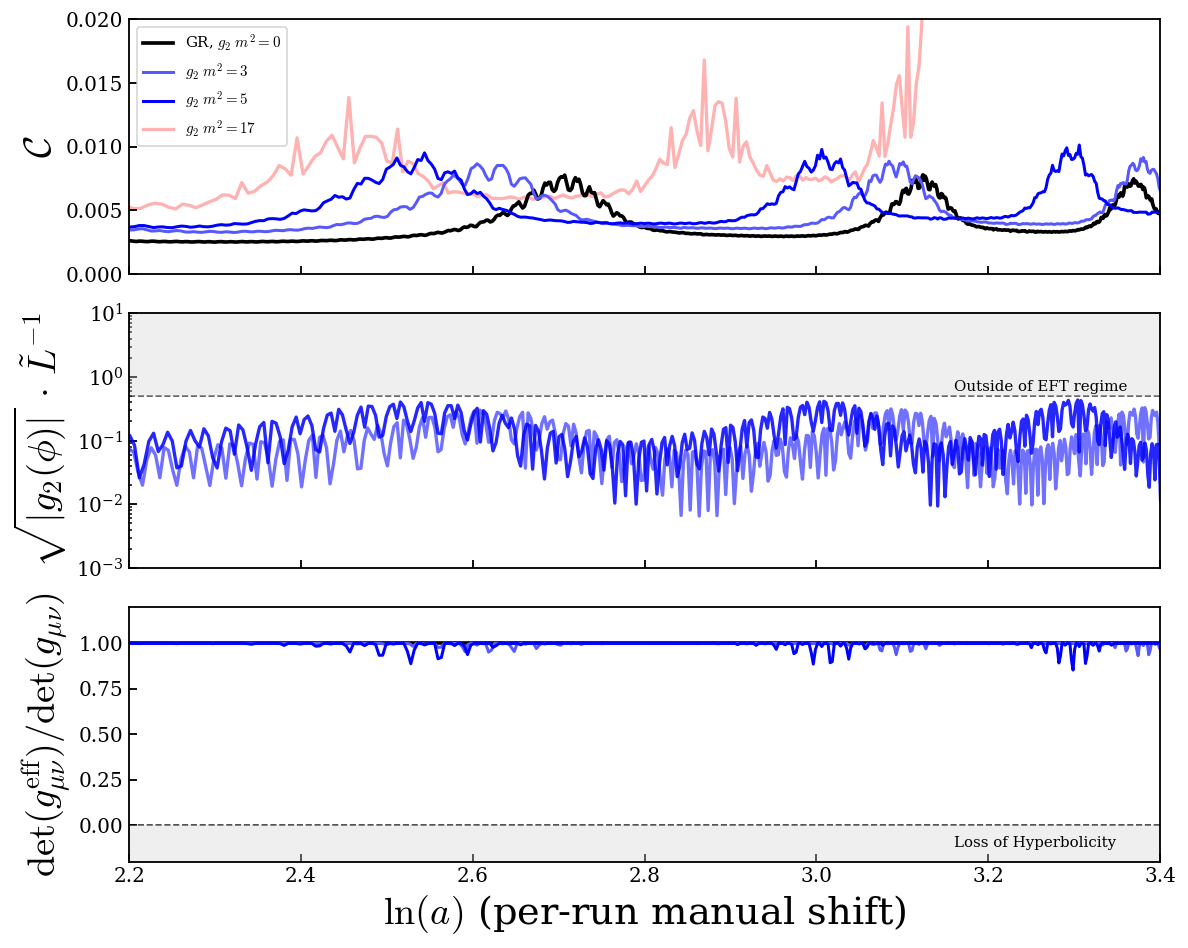

In [77]:
# === Same as the Panel 4 plot above, but each parameter combination can be ===
# === shifted horizontally by hand via the KEY_X_SHIFTS dictionary below.   ===
# === The same shift is applied to all three stacked panels (C, WCC, hyp).  ===

# Edit these numbers to slide individual curves left/right (in ln(a) units).
# Keys are the full run-key tuples (lgb, mu, beta, amp, width, g2). Any run not
# listed gets a shift of 0. The PLOT4_HIGHLIGHT_KEY can also be added here.
ha = 0
KEY_X_SHIFTS = {
    (0,  0.08, 250, -0.02, 3.0,  0.0):  -0.09 +ha,    # GR
    (0,  0.08, 250, -0.02, 3.0,  6.0):  0.18 -0.09,    # g2 = 3   (stored 6)
    (0,  0.08, 250, -0.02, 3.0, 10.0):  0.25 -0.17,    # g2 = 5   (stored 10)
    (0,  0.08, 250, -0.02, 3.0, 34.0):  0.42 -0.25,    # highlight (g2 = 17)
}

def _x_shift_for(key):
    return float(KEY_X_SHIFTS.get(tuple(key), 0.0))


fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Colour scheme: identical to the Panel 4 cell above.
from matplotlib.colors import LinearSegmentedColormap as _LSC
_unique_g2  = sorted({k[5] for k in PLOT4_KEYS})
_BLUES_RAMP = _LSC.from_list("_g2_blues", ["#fafbfc", "blue"])
_TAB10 = plt.cm.tab10

def _color_for_g2(g2_val):
    if PLOT4_USE_TAB_COLORS:
        rank = _unique_g2.index(g2_val)
        return _TAB10(rank % 10)
    if len(_unique_g2) <= 1:
        return _BLUES_RAMP(1.0)
    rank = _unique_g2.index(g2_val)
    frac = 0.30 + 0.70 * rank / (len(_unique_g2) - 1)
    return _BLUES_RAMP(frac)

def _rmask_for_eft(eft, r_cut=R_WCC_MAX):
    if eft is None or "r" not in eft:
        return None
    r = np.asarray(eft["r"])
    return (r > 0) & (r <= r_cut)

if len(PLOT4_KEYS) == 0:
    print("No keys selected for Panel 4 (manual shift).")
else:
    # Highlighted run first (behind everything) if requested
    _highlight_legend_handle = None
    if PLOT4_HIGHLIGHT_KEY is not None and PLOT4_HIGHLIGHT_KEY in all_runs:
        _hk  = PLOT4_HIGHLIGHT_KEY
        _hr  = all_runs[_hk]
        _ho  = _hr["osc"]
        _he  = _hr.get("eft", None)
        _hdx = _x_shift_for(_hk)
        _hx  = np.asarray(_hr["shifted_ln_a"]) + _hdx
        _h_rmask = _rmask_for_eft(_he)
        _hlgb, _hmu, _hbeta, _hamp, _hwidth, _hg2 = _hk
        _hlbl = rf"$g_2\;m^2={_hg2/2:g}$"
        _hl, = axes[0].plot(_hx, _ho["C"], color=PLOT4_HIGHLIGHT_COLOR,
                     lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                     zorder=1)
        _highlight_legend_handle = (_hl, _hlbl)
        if _he is not None and _h_rmask is not None:
            _hwc = np.nanmax(_he["wc_lambda_bare"][:, _h_rmask], axis=1)
            axes[1].plot(_hx, _hwc, color=PLOT4_HIGHLIGHT_COLOR,
                         lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                         zorder=1)
            if _hg2 != 0 and "wc_g2_bare" in _he:
                _hwcg2 = np.nanmax(_he["wc_g2_bare"][:, _h_rmask], axis=1)
                axes[1].plot(_hx, _hwcg2, color=PLOT4_HIGHLIGHT_COLOR,
                             lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                             ls="-", zorder=1)
        if _he is not None and "disc_g2" in _he and _h_rmask is not None:
            _hdisc = np.nanmin(_he["disc_g2"][:, _h_rmask], axis=1)
            axes[2].plot(_hx, _hdisc, color=PLOT4_HIGHLIGHT_COLOR,
                         lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                         zorder=1)

    for i, key in enumerate(PLOT4_KEYS):
        run = all_runs[key]
        osc = run["osc"]
        eft = run.get("eft", None)
        lgb, mu, beta, amp, width, g2 = key

        is_gr = (lgb == 0.0 and g2 == 0.0)
        beta_str = rf", \beta={int(beta)}" if (beta is not None and beta != 250) else ""
        g2_str   = rf"g_2\;m^2={g2/2:g}"
        if is_gr:
            label = rf"GR, ${g2_str}$"
        else:
            label = rf"${g2_str}$"
        if is_gr:
            color = "k"
        elif PLOT4_USE_TAB_COLORS:
            color = _TAB10(i % 10)
        else:
            color = _color_for_g2(g2)
        lw    = 2.2 if is_gr else 1.8

        dx = _x_shift_for(key)
        x  = np.asarray(run["shifted_ln_a"]) + dx
        r_mask_run = _rmask_for_eft(eft)

        axes[0].plot(x, osc["C"], color=color, lw=lw, label=label, zorder=5)

        if eft is not None and r_mask_run is not None:
            wc_lam = np.nanmax(eft["wc_lambda_bare"][:, r_mask_run], axis=1)
            axes[1].plot(x, wc_lam, color=color, lw=lw, label=label, zorder=5)
            if g2 != 0 and "wc_g2_bare" in eft:
                wc_g2 = np.nanmax(eft["wc_g2_bare"][:, r_mask_run], axis=1)
                axes[1].plot(x, wc_g2, color=color, lw=2, ls="-", alpha=0.85, zorder=5)

        if eft is not None and "disc_g2" in eft and r_mask_run is not None:
            disc_g2_min = np.nanmin(eft["disc_g2"][:, r_mask_run], axis=1)
            axes[2].plot(x, disc_g2_min, color=color, lw=lw, label=label, zorder=5)

    axes[0].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[0].set_ylabel(r"$\mathcal{C}$")
    axes[0].set_ylim(0, 0.02)

    axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[1].set_ylabel(r"$\sqrt{|g_2(\phi)|}\,\cdot\, \tilde L^{-1}$")
    if PLOT4_WCC_LOG:
        axes[1].set_yscale("log")
        axes[1].set_ylim(*PLOT4_WCC_YLIM_LOG)
    else:
        axes[1].set_yscale("linear")
        axes[1].set_ylim(*PLOT4_WCC_YLIM_LINEAR)

    axes[2].axhline(0.0, color="k", lw=1.0, ls="--", alpha=0.8)
    axes[2].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[2].set_ylabel(r"$\det(g^{\rm eff}_{\mu\nu})/\det(g_{\mu\nu})$")

    axes[1].axhspan(0.5, 10, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.8, 0.70, "Outside of EFT regime", transform=_trans1,
                 va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].axhspan(0, -1, facecolor="lightgrey", alpha=0.35, zorder=10)
    _trans2 = blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.8, -0.1, "Loss of Hyperbolicity", transform=_trans2,
                 va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].set_ylim(-0.2, 1.2)
    axes[2].set_xlabel(r"$\ln(a)$ (per-run manual shift)")
    axes[0].set_xlim(2.2, 3.4)

    _handles, _labels = axes[0].get_legend_handles_labels()
    if _highlight_legend_handle is not None:
        _leg_handles = _handles
        _leg_labels  = _labels
        _leg_handles.append(_highlight_legend_handle[0])
        _leg_labels.append(_highlight_legend_handle[1])
    else:
        _leg_handles = _handles
        _leg_labels  = _labels
    axes[0].legend(_leg_handles, _leg_labels, fontsize=9, ncol=1, loc="upper left")

    for ax in axes:
        ax.set_axisbelow(False)
        for spine in ax.spines.values():
            spine.set_zorder(20)

    fig.tight_layout()
    save_fig(fig, PLOT4_NAME + "_shifted")
    plt.show()

## Panel 4-GB — Compactness, weak-coupling and GB hyperbolicity

Sister of Panel 4 but for the **Gauss-Bonnet** sector. Three stacked panels sharing
the x-axis (aligned $\ln(a)$, fixed to $[2,\,3.5]$):

1. Compactness $\mathcal{C}$
2. GB weak-coupling condition $\max_r \sqrt{|\lambda'|}\,L^{-1}$ (from `wc_lambda_bare`)
3. GB hyperbolicity: $\min_r \det(M_{\rm eff})$ (from `disc_GB`)

GR (`lgb=0, g2=0`) is drawn as a thick black line. Per-curve labels show $\lambda_{\rm GB}$
(the varied parameter). EFT diagnostics are computed (and cached on disk) only for the
selected runs. Set `FORCE_EFT_RECOMPUTE_GB = True` to overwrite the cached
`eft_diagnostics.npz`.

In [15]:
### --- Panel 4-GB selection (edit me) ---
PLOT4GB_KEYS = select_runs(
    #lgb   = [0,2,5, 8, 9, 10, 11, 12],
    lgb   = [0,1,2,3,4,5],
    mu    = [0.08],
    beta  = [0],
    amp   = [-0.02],
    width = [3.0],
    g2    = [0],
)
PLOT4GB_NAME = "rho_C_WCC_GB_hyp"

PLOT4GB_USE_TAB_COLORS = False   # False = red ramp; True = tab10 cycle (tab:blue, orange, green, ...)

# Optional: highlight a specific run in a distinct color, plotted behind the others.
# Set to a key tuple e.g. (5, 0.08, 0, -0.02, 3.0, 0) or None to disable.
PLOT4GB_HIGHLIGHT_KEY   = None
PLOT4GB_HIGHLIGHT_COLOR = "red"
PLOT4GB_HIGHLIGHT_LW    = 3.0
PLOT4GB_HIGHLIGHT_ALPHA = 0.5

R_WCC_MAX_GB           = 100.0   # only consider r in (0, R_WCC_MAX_GB] for WCC / hyperbolicity maxima
FORCE_EFT_RECOMPUTE_GB = False   # True = ignore any cached eft_diagnostics.npz and recompute

# Middle panel (GB weak-coupling condition) y-axis options.
PLOT4GB_WCC_LOG          = True            # True -> log y; False -> linear y
PLOT4GB_WCC_YLIM_LOG     = (1e-3, 1e1)     # used when PLOT4GB_WCC_LOG is True
PLOT4GB_WCC_YLIM_LINEAR  = (0.0, 1.2)      # used when PLOT4GB_WCC_LOG is False

print(f"{len(PLOT4GB_KEYS)} run(s) selected for Panel 4-GB:")
for k in PLOT4GB_KEYS:
    print(" ", k, " coupling=", all_runs[k]["coupling"], " lgb=", k[0])

# Compute / load EFT diagnostics only for the selected runs
for k in PLOT4GB_KEYS:
    d = all_runs[k]
    if "eft" in d and not FORCE_EFT_RECOMPUTE_GB:
        continue
    run_dir  = d["run_dir"]
    eft_path = os.path.join(run_dir, "eft_diagnostics.npz")
    if os.path.exists(eft_path) and not FORCE_EFT_RECOMPUTE_GB:
        d["eft"] = dict(np.load(eft_path, allow_pickle=True))
        print(f"  [EFT] loaded cache for {d['tag']}")
    else:
        sol_i    = np.load(os.path.join(run_dir, "solution.npy"))
        matter_i = ScalarMatter(scalar_mu, d["mu"])
        sv_i     = StateVector(matter_i)
        spacing_i = CubicSpacing(**CubicSpacing.get_parameters(
            d["run_r_max"], d["run_min_dr"], d["run_max_dr"]))
        grid_i   = Grid(spacing_i, sv_i)
        bg_i     = FlatSphericalBackground(grid_i.r)
        lgb_k, mu_k, beta_k, amp_k, width_k, g2_k = k
        params = (lgb_k, a_mg, b_mg, chi0, d["coupling"], g2_k)
        eft = get_eft_diagnostic(
            sol_i, d["t"], grid_i, bg_i,
            ScalarMatter(scalar_mu, d["mu"]),
            params,
        )
        np.savez(eft_path, **eft)
        d["eft"] = eft
        del sol_i
        verb = "recomputed" if FORCE_EFT_RECOMPUTE_GB else "computed"
        print(f"  [EFT] {verb} & cached for {d['tag']}")

6 run(s) selected for Panel 4-GB:
  (0.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0  lgb= 0.0
  (1.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0  lgb= 1.0
  (2.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0  lgb= 2.0
  (3.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0  lgb= 3.0
  (4.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0  lgb= 4.0
  (5.0, 0.08, 0.0, -0.02, 3.0, 0.0)  coupling= quadratic_0  lgb= 5.0
  [EFT] loaded cache for lgb0.0_mu0.08_a0.0_b0.0_amp-0.02_R3.0_dr0.041666666666666664_quadratic_0
  [EFT] loaded cache for lgb1_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
  [EFT] loaded cache for lgb2_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
  [EFT] loaded cache for lgb3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20
  [EFT] loaded cache for lgb4_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20


  saved rho_C_WCC_GB_hyp.pdf and rho_C_WCC_GB_hyp.png


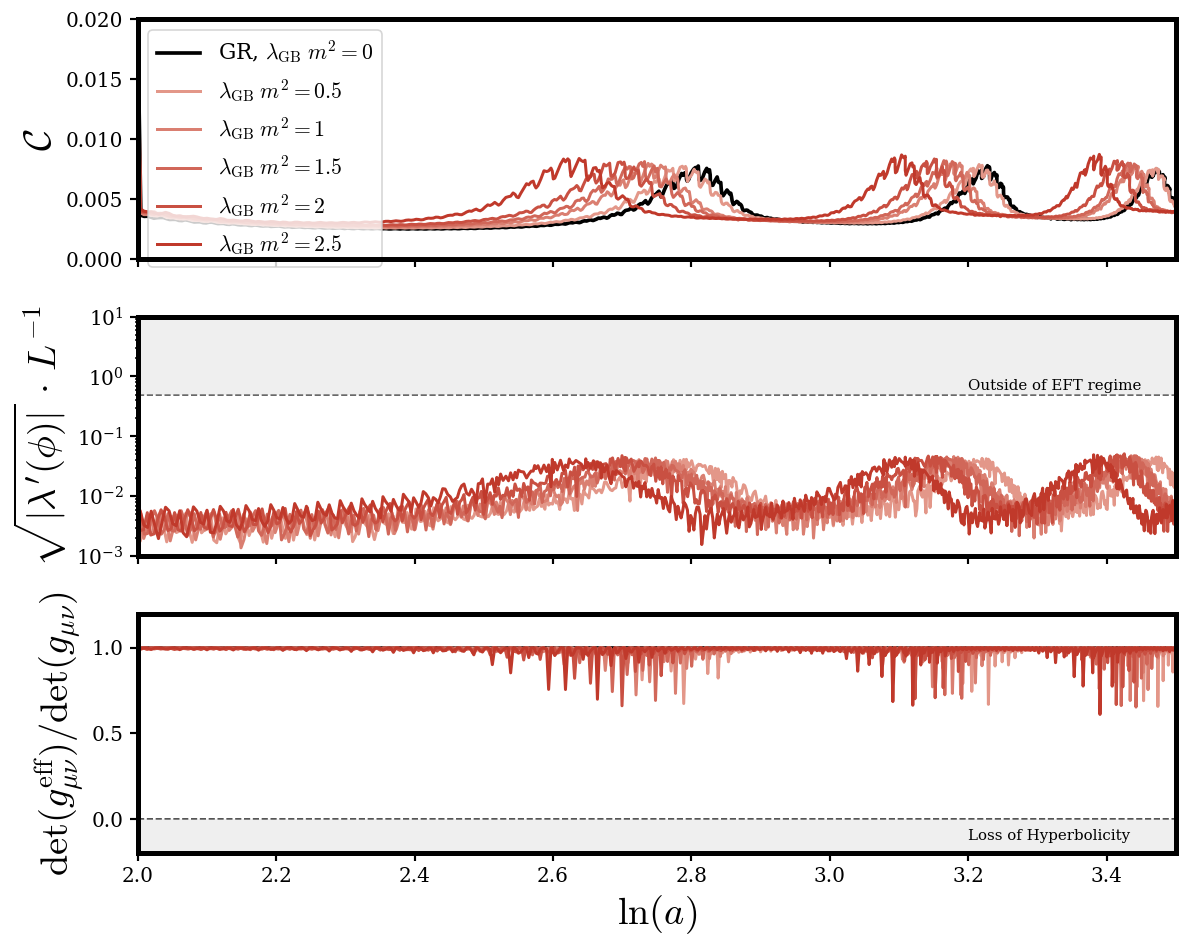

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Curves coloured by |lambda_GB|: light red = weak GB, dark red = strong GB.
# The darkest shade is "#c0392b" (matching the red used in Panel 4d's left
# axes) and is assigned to the *highest* selected |lambda_GB|. Ranking uses
# (|lgb|, lgb) so that lgb=0 is lightest and ties between +lgb and -lgb of
# the same magnitude are broken by sign. GR (lgb=0, g2=0) overrides to black.
from matplotlib.colors import LinearSegmentedColormap as _LSC
_unique_lgb = sorted({k[0] for k in PLOT4GB_KEYS}, key=lambda v: (abs(v), v))
_REDS_RAMP  = _LSC.from_list("_lgb_reds", ["#fee0d2", "#c0392b"])
_TAB10_GB   = plt.cm.tab10

def _color_for_lgb(lgb_val):
    if PLOT4GB_USE_TAB_COLORS:
        rank = _unique_lgb.index(lgb_val)
        return _TAB10_GB(rank % 10)
    if len(_unique_lgb) <= 1:
        return _REDS_RAMP(1.0)
    rank = _unique_lgb.index(lgb_val)
    frac = 0.30 + 0.70 * rank / (len(_unique_lgb) - 1)
    return _REDS_RAMP(frac)

def _rmask_for_eft(eft, r_cut=R_WCC_MAX_GB):
    """Build (r > 0) & (r <= r_cut) from this run's own eft["r"], so runs
    with different grids (e.g. different r_max) don't share a mask."""
    if eft is None or "r" not in eft:
        return None
    r = np.asarray(eft["r"])
    return (r > 0) & (r <= r_cut)

if len(PLOT4GB_KEYS) == 0:
    print("No keys selected for Panel 4-GB.")
else:
    # Draw highlighted run first (behind everything) if requested
    _highlight_legend_handle_gb = None
    if PLOT4GB_HIGHLIGHT_KEY is not None and PLOT4GB_HIGHLIGHT_KEY in all_runs:
        _hk  = PLOT4GB_HIGHLIGHT_KEY
        _hr  = all_runs[_hk]
        _ho  = _hr["osc"]
        _he  = _hr.get("eft", None)
        _hx  = _hr["shifted_ln_a"]
        _h_rmask = _rmask_for_eft(_he)
        _hlgb, _hmu, _hbeta, _hamp, _hwidth, _hg2 = _hk
        _hlbl = rf"$\lambda_{{\rm GB}}={_hlgb:g}$"
        _hl, = axes[0].plot(_hx, _ho["C"], color=PLOT4GB_HIGHLIGHT_COLOR,
                     lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                     zorder=1)
        _highlight_legend_handle_gb = (_hl, _hlbl)
        if _he is not None and _h_rmask is not None and "wc_lambda_bare" in _he:
            _hwc = np.nanmax(_he["wc_lambda_bare"][:, _h_rmask], axis=1)
            axes[1].plot(_hx, _hwc, color=PLOT4GB_HIGHLIGHT_COLOR,
                         lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                         zorder=1)
        if _he is not None and "disc_GB" in _he and _h_rmask is not None:
            _hdisc = np.nanmin(_he["disc_GB"][:, _h_rmask], axis=1)
            axes[2].plot(_hx, _hdisc, color=PLOT4GB_HIGHLIGHT_COLOR,
                         lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                         zorder=1)

    for i, key in enumerate(PLOT4GB_KEYS):
        run = all_runs[key]
        osc = run["osc"]
        eft = run.get("eft", None)
        lgb, mu, beta, amp, width, g2 = key

        is_gr   = (lgb == 0.0 and g2 == 0.0)
        lgb_str = rf"\lambda_{{\rm GB}}\;m^2 ={lgb/2:g} "
        if is_gr:
            label = rf"GR, ${lgb_str}$"
        else:
            label = rf"${lgb_str}$"
        if is_gr:
            color = "k"
        elif PLOT4GB_USE_TAB_COLORS:
            color = _TAB10_GB(i % 10)
        else:
            color = _color_for_lgb(lgb)
        lw    = 2.2 if is_gr else 1.8

        x = run["shifted_ln_a"]
        r_mask_run = _rmask_for_eft(eft)

        # Panel 0: compactness
        axes[0].plot(x, osc["C"], color=color, lw=lw, label=label, zorder=5)

        # Panel 1: GB weak-coupling condition  max_r sqrt(|lambda'|) * L^{-1}
        if eft is not None and r_mask_run is not None and "wc_lambda_bare" in eft:
            wc_lam = np.nanmax(eft["wc_lambda_bare"][:, r_mask_run], axis=1)
            axes[1].plot(x, wc_lam, color=color, lw=lw, label=label, zorder=5)

        # Panel 2: GB hyperbolicity  min_r det(M_eff)
        if eft is not None and "disc_GB" in eft and r_mask_run is not None:
            disc_GB_min = np.nanmin(eft["disc_GB"][:, r_mask_run], axis=1)
            axes[2].plot(x, disc_GB_min, color=color, lw=lw, label=label, zorder=5)

    axes[0].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[0].set_ylabel(r"$\mathcal{C}$")
    axes[0].set_ylim(0, 0.02)
    #axes[0].set_ylim(0, 0.05)

    #axes[1].axhline(1.0, color="k", lw=1.0, ls=":", alpha=0.7)
    axes[1].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    #axes[1].set_ylabel(r"$\max_r\,\sqrt{|\lambda^{GB}|}\,\cdot\, L^{-1}$")
    axes[1].set_ylabel(r"$\sqrt{|\lambda'(\phi)|}\,\cdot\, L^{-1}$")
    if PLOT4GB_WCC_LOG:
        axes[1].set_yscale("log")
        axes[1].set_ylim(*PLOT4GB_WCC_YLIM_LOG)
    else:
        axes[1].set_yscale("linear")
        axes[1].set_ylim(*PLOT4GB_WCC_YLIM_LINEAR)

    axes[2].axhline(0.0, color="k", lw=1.0, ls="--", alpha=0.8)
    axes[2].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[2].set_ylim(-0.2,1.2)
    #axes[2].set_ylabel(r"$\min_r\,\det(M_{\rm eff})$")
    axes[2].set_ylabel(r"$\det(g^{\rm eff}_{\mu\nu})/\det(g_{\mu\nu})$")
    axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].axhspan(0.5, 10, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.8, 0.70, "Outside of EFT regime", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].axhspan(0, -1, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.8, -0.1, "Loss of Hyperbolicity", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)
    #axes[1].axhline(0.1, color="k", lw=1.0, ls="--", alpha=0.7)
    # disc_GB scale differs from g2 det(g_eff); leave y-axis auto. Uncomment
    # the next line if you want a fixed range:
    # axes[2].set_ylim(0, 1.6)

    axes[2].set_xlabel(r"$\ln(a)$")
    axes[0].set_xlim(2, 3.5)

    # Build legend: main curves first, then highlighted run last
    _handles, _labels = axes[0].get_legend_handles_labels()
    if _highlight_legend_handle_gb is not None:
        _handles.append(_highlight_legend_handle_gb[0])
        _labels.append(_highlight_legend_handle_gb[1])
    axes[0].legend(_handles, _labels, fontsize=13, ncol=1, loc="upper left")
    #axes[1].legend(fontsize=13, ncol=1, loc="upper left")
    #axes[2].legend(fontsize=13, ncol=1, loc="upper left")

    # Ensure axes borders (spines) are drawn on top of all data
    for ax in axes:
        ax.set_axisbelow(False)
        for spine in ax.spines.values():
            spine.set_zorder(20)

    fig.tight_layout()
    save_fig(fig, PLOT4GB_NAME)
    plt.show()

  saved rho_C_WCC_GB_hyp.pdf and rho_C_WCC_GB_hyp.png


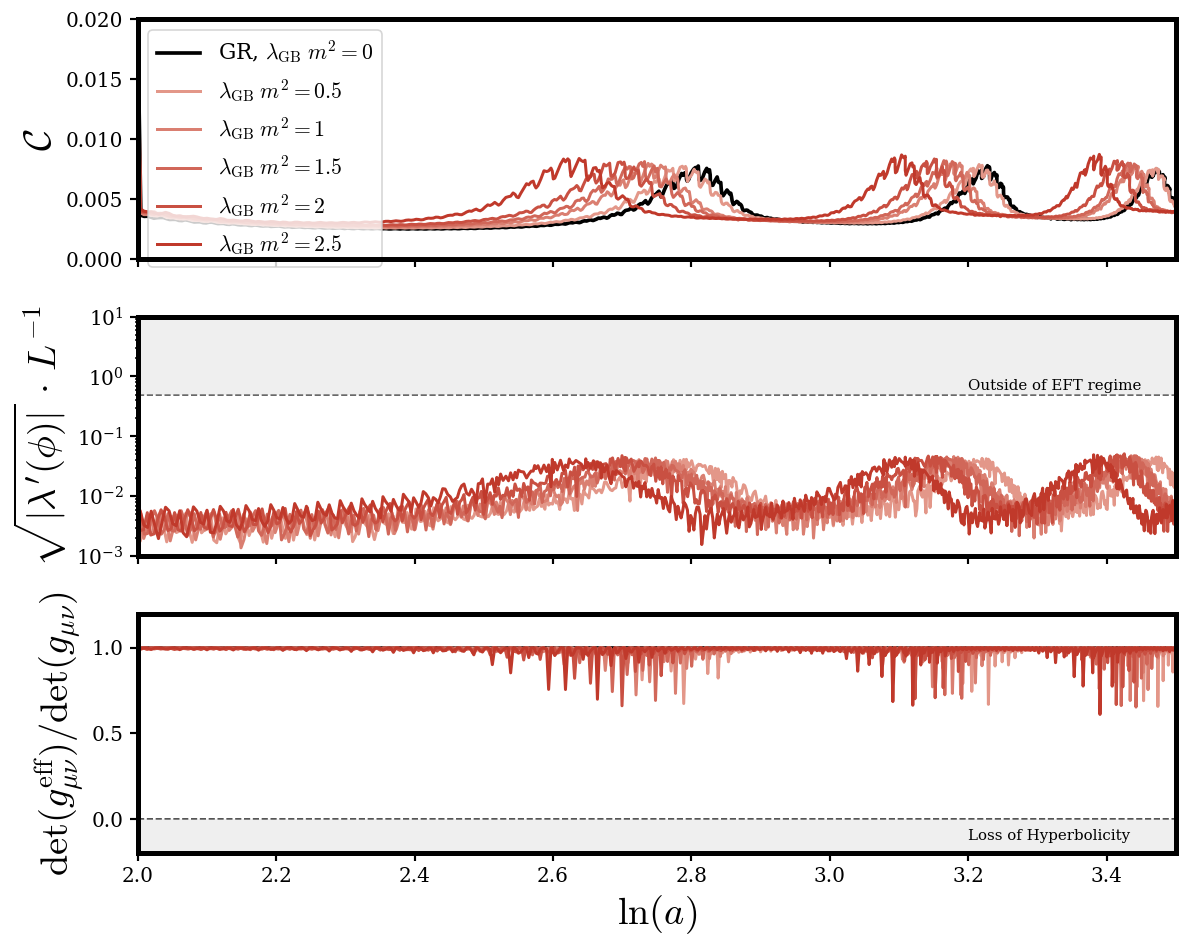

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Curves coloured by |lambda_GB|: light red = weak GB, dark red = strong GB.
# The darkest shade is "#c0392b" (matching the red used in Panel 4d's left
# axes) and is assigned to the *highest* selected |lambda_GB|. Ranking uses
# (|lgb|, lgb) so that lgb=0 is lightest and ties between +lgb and -lgb of
# the same magnitude are broken by sign. GR (lgb=0, g2=0) overrides to black.
from matplotlib.colors import LinearSegmentedColormap as _LSC
_unique_lgb = sorted({k[0] for k in PLOT4GB_KEYS}, key=lambda v: (abs(v), v))
_REDS_RAMP  = _LSC.from_list("_lgb_reds", ["#fee0d2", "#c0392b"])
_TAB10_GB   = plt.cm.tab10

def _color_for_lgb(lgb_val):
    if PLOT4GB_USE_TAB_COLORS:
        rank = _unique_lgb.index(lgb_val)
        return _TAB10_GB(rank % 10)
    if len(_unique_lgb) <= 1:
        return _REDS_RAMP(1.0)
    rank = _unique_lgb.index(lgb_val)
    frac = 0.30 + 0.70 * rank / (len(_unique_lgb) - 1)
    return _REDS_RAMP(frac)

def _rmask_for_eft(eft, r_cut=R_WCC_MAX_GB):
    """Build (r > 0) & (r <= r_cut) from this run's own eft["r"], so runs
    with different grids (e.g. different r_max) don't share a mask."""
    if eft is None or "r" not in eft:
        return None
    r = np.asarray(eft["r"])
    return (r > 0) & (r <= r_cut)

if len(PLOT4GB_KEYS) == 0:
    print("No keys selected for Panel 4-GB.")
else:
    # Draw highlighted run first (behind everything) if requested
    _highlight_legend_handle_gb = None
    if PLOT4GB_HIGHLIGHT_KEY is not None and PLOT4GB_HIGHLIGHT_KEY in all_runs:
        _hk  = PLOT4GB_HIGHLIGHT_KEY
        _hr  = all_runs[_hk]
        _ho  = _hr["osc"]
        _he  = _hr.get("eft", None)
        _hx  = _hr["shifted_ln_a"]
        _h_rmask = _rmask_for_eft(_he)
        _hlgb, _hmu, _hbeta, _hamp, _hwidth, _hg2 = _hk
        _hlbl = rf"$\lambda_{{\rm GB}}={_hlgb:g}$"
        _hl, = axes[0].plot(_hx, _ho["C"], color=PLOT4GB_HIGHLIGHT_COLOR,
                     lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                     zorder=1)
        _highlight_legend_handle_gb = (_hl, _hlbl)
        if _he is not None and _h_rmask is not None and "wc_lambda_bare" in _he:
            _hwc = np.nanmax(_he["wc_lambda_bare"][:, _h_rmask], axis=1)
            axes[1].plot(_hx, _hwc, color=PLOT4GB_HIGHLIGHT_COLOR,
                         lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                         zorder=1)
        if _he is not None and "disc_GB" in _he and _h_rmask is not None:
            _hdisc = np.nanmin(_he["disc_GB"][:, _h_rmask], axis=1)
            axes[2].plot(_hx, _hdisc, color=PLOT4GB_HIGHLIGHT_COLOR,
                         lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                         zorder=1)

    for i, key in enumerate(PLOT4GB_KEYS):
        run = all_runs[key]
        osc = run["osc"]
        eft = run.get("eft", None)
        lgb, mu, beta, amp, width, g2 = key

        is_gr   = (lgb == 0.0 and g2 == 0.0)
        lgb_str = rf"\lambda_{{\rm GB}}\;m^2 ={lgb/2:g} "
        if is_gr:
            label = rf"GR, ${lgb_str}$"
        else:
            label = rf"${lgb_str}$"
        if is_gr:
            color = "k"
        elif PLOT4GB_USE_TAB_COLORS:
            color = _TAB10_GB(i % 10)
        else:
            color = _color_for_lgb(lgb)
        lw    = 2.2 if is_gr else 1.8

        x = run["shifted_ln_a"]
        r_mask_run = _rmask_for_eft(eft)

        # Panel 0: compactness
        axes[0].plot(x, osc["C"], color=color, lw=lw, label=label, zorder=5)

        # Panel 1: GB weak-coupling condition  max_r sqrt(|lambda'|) * L^{-1}
        if eft is not None and r_mask_run is not None and "wc_lambda_bare" in eft:
            wc_lam = np.nanmax(eft["wc_lambda_bare"][:, r_mask_run], axis=1)
            axes[1].plot(x, wc_lam, color=color, lw=lw, label=label, zorder=5)

        # Panel 2: GB hyperbolicity  min_r det(M_eff)
        if eft is not None and "disc_GB" in eft and r_mask_run is not None:
            disc_GB_min = np.nanmin(eft["disc_GB"][:, r_mask_run], axis=1)
            axes[2].plot(x, disc_GB_min, color=color, lw=lw, label=label, zorder=5)

    axes[0].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[0].set_ylabel(r"$\mathcal{C}$")
    axes[0].set_ylim(0, 0.02)
    #axes[0].set_ylim(0, 0.05)

    #axes[1].axhline(1.0, color="k", lw=1.0, ls=":", alpha=0.7)
    axes[1].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    #axes[1].set_ylabel(r"$\max_r\,\sqrt{|\lambda^{GB}|}\,\cdot\, L^{-1}$")
    axes[1].set_ylabel(r"$\sqrt{|\lambda'(\phi)|}\,\cdot\, L^{-1}$")
    if PLOT4GB_WCC_LOG:
        axes[1].set_yscale("log")
        axes[1].set_ylim(*PLOT4GB_WCC_YLIM_LOG)
    else:
        axes[1].set_yscale("linear")
        axes[1].set_ylim(*PLOT4GB_WCC_YLIM_LINEAR)

    axes[2].axhline(0.0, color="k", lw=1.0, ls="--", alpha=0.8)
    axes[2].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[2].set_ylim(-0.2,1.2)
    #axes[2].set_ylabel(r"$\min_r\,\det(M_{\rm eff})$")
    axes[2].set_ylabel(r"$\det(g^{\rm eff}_{\mu\nu})/\det(g_{\mu\nu})$")
    axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].axhspan(0.5, 10, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.8, 0.70, "Outside of EFT regime", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].axhspan(0, -1, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.8, -0.1, "Loss of Hyperbolicity", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)
    #axes[1].axhline(0.1, color="k", lw=1.0, ls="--", alpha=0.7)
    # disc_GB scale differs from g2 det(g_eff); leave y-axis auto. Uncomment
    # the next line if you want a fixed range:
    # axes[2].set_ylim(0, 1.6)

    axes[2].set_xlabel(r"$\ln(a)$")
    axes[0].set_xlim(2, 3.5)

    # Build legend: main curves first, then highlighted run last
    _handles, _labels = axes[0].get_legend_handles_labels()
    if _highlight_legend_handle_gb is not None:
        _handles.append(_highlight_legend_handle_gb[0])
        _labels.append(_highlight_legend_handle_gb[1])
    axes[0].legend(_handles, _labels, fontsize=13, ncol=1, loc="upper left")
    #axes[1].legend(fontsize=13, ncol=1, loc="upper left")
    #axes[2].legend(fontsize=13, ncol=1, loc="upper left")

    # Ensure axes borders (spines) are drawn on top of all data
    for ax in axes:
        ax.set_axisbelow(False)
        for spine in ax.spines.values():
            spine.set_zorder(20)

    fig.tight_layout()
    save_fig(fig, PLOT4GB_NAME)
    plt.show()

  saved rho_C_WCC_GB_hyp_shifted.pdf and rho_C_WCC_GB_hyp_shifted.png


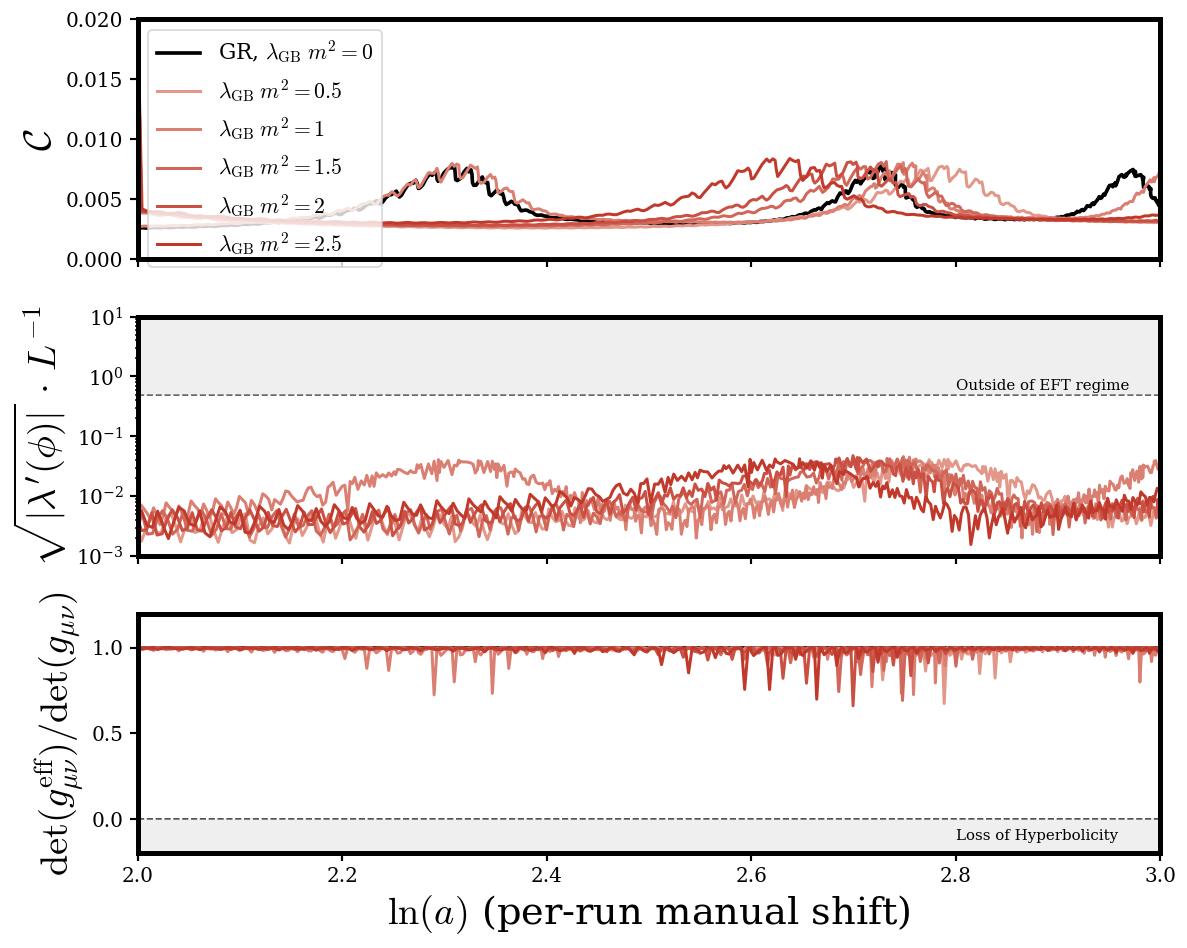

In [18]:
# === Same as the Panel 4-GB plot above, but each parameter combination can ===
# === be shifted horizontally by hand via the KEYGB_X_SHIFTS dictionary.    ===
# === The same shift is applied to all three stacked panels (C, WCC, hyp).  ===

# Edit these numbers to slide individual curves left/right (in ln(a) units).
# Keys are the full run-key tuples (lgb, mu, beta, amp, width, g2). Any run
# not listed gets a shift of 0. PLOT4GB_HIGHLIGHT_KEY can also be added here.
ho = 0.5
KEYGB_X_SHIFTS = {
    (0,  0.08, 0, -0.02, 3.0, 0):  0.0-ho,    # GR
    (2,  0.08, 0, -0.02, 3.0, 0):  0.07-ho,    # lgb m^2 = 1
    (6,  0.08, 0, -0.02, 3.0, 0):  0.16-ho,    # lgb m^2 = 3
    (10, 0.08, 0, -0.02, 3.0, 0):  0.23-ho,    # lgb m^2 = 5
}

def _x_shift_for_gb(key):
    return float(KEYGB_X_SHIFTS.get(tuple(key), 0.0))


fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Colour scheme: identical to the Panel 4-GB cell above.
from matplotlib.colors import LinearSegmentedColormap as _LSC
_unique_lgb = sorted({k[0] for k in PLOT4GB_KEYS}, key=lambda v: (abs(v), v))
_REDS_RAMP  = _LSC.from_list("_lgb_reds", ["#fee0d2", "#c0392b"])
_TAB10_GB   = plt.cm.tab10

def _color_for_lgb(lgb_val):
    if PLOT4GB_USE_TAB_COLORS:
        rank = _unique_lgb.index(lgb_val)
        return _TAB10_GB(rank % 10)
    if len(_unique_lgb) <= 1:
        return _REDS_RAMP(1.0)
    rank = _unique_lgb.index(lgb_val)
    frac = 0.30 + 0.70 * rank / (len(_unique_lgb) - 1)
    return _REDS_RAMP(frac)

def _rmask_for_eft(eft, r_cut=R_WCC_MAX_GB):
    if eft is None or "r" not in eft:
        return None
    r = np.asarray(eft["r"])
    return (r > 0) & (r <= r_cut)

if len(PLOT4GB_KEYS) == 0:
    print("No keys selected for Panel 4-GB (manual shift).")
else:
    # Highlighted run first (behind everything) if requested
    _highlight_legend_handle_gb = None
    if PLOT4GB_HIGHLIGHT_KEY is not None and PLOT4GB_HIGHLIGHT_KEY in all_runs:
        _hk  = PLOT4GB_HIGHLIGHT_KEY
        _hr  = all_runs[_hk]
        _ho  = _hr["osc"]
        _he  = _hr.get("eft", None)
        _hdx = _x_shift_for_gb(_hk)
        _hx  = np.asarray(_hr["shifted_ln_a"]) + _hdx
        _h_rmask = _rmask_for_eft(_he)
        _hlgb, _hmu, _hbeta, _hamp, _hwidth, _hg2 = _hk
        _hlbl = rf"$\lambda_{{\rm GB}}={_hlgb:g}$"
        _hl, = axes[0].plot(_hx, _ho["C"], color=PLOT4GB_HIGHLIGHT_COLOR,
                     lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                     zorder=1)
        _highlight_legend_handle_gb = (_hl, _hlbl)
        if _he is not None and _h_rmask is not None and "wc_lambda_bare" in _he:
            _hwc = np.nanmax(_he["wc_lambda_bare"][:, _h_rmask], axis=1)
            axes[1].plot(_hx, _hwc, color=PLOT4GB_HIGHLIGHT_COLOR,
                         lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                         zorder=1)
        if _he is not None and "disc_GB" in _he and _h_rmask is not None:
            _hdisc = np.nanmin(_he["disc_GB"][:, _h_rmask], axis=1)
            axes[2].plot(_hx, _hdisc, color=PLOT4GB_HIGHLIGHT_COLOR,
                         lw=PLOT4GB_HIGHLIGHT_LW, alpha=PLOT4GB_HIGHLIGHT_ALPHA,
                         zorder=1)

    for i, key in enumerate(PLOT4GB_KEYS):
        run = all_runs[key]
        osc = run["osc"]
        eft = run.get("eft", None)
        lgb, mu, beta, amp, width, g2 = key

        is_gr   = (lgb == 0.0 and g2 == 0.0)
        lgb_str = rf"\lambda_{{\rm GB}}\;m^2 ={lgb/2:g} "
        if is_gr:
            label = rf"GR, ${lgb_str}$"
        else:
            label = rf"${lgb_str}$"
        if is_gr:
            color = "k"
        elif PLOT4GB_USE_TAB_COLORS:
            color = _TAB10_GB(i % 10)
        else:
            color = _color_for_lgb(lgb)
        lw    = 2.2 if is_gr else 1.8

        dx = _x_shift_for_gb(key)
        x  = np.asarray(run["shifted_ln_a"]) + dx
        r_mask_run = _rmask_for_eft(eft)

        axes[0].plot(x, osc["C"], color=color, lw=lw, label=label, zorder=5)

        if eft is not None and r_mask_run is not None and "wc_lambda_bare" in eft:
            wc_lam = np.nanmax(eft["wc_lambda_bare"][:, r_mask_run], axis=1)
            axes[1].plot(x, wc_lam, color=color, lw=lw, label=label, zorder=5)

        if eft is not None and "disc_GB" in eft and r_mask_run is not None:
            disc_GB_min = np.nanmin(eft["disc_GB"][:, r_mask_run], axis=1)
            axes[2].plot(x, disc_GB_min, color=color, lw=lw, label=label, zorder=5)

    axes[0].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[0].set_ylabel(r"$\mathcal{C}$")
    axes[0].set_ylim(0, 0.02)

    axes[1].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[1].set_ylabel(r"$\sqrt{|\lambda'(\phi)|}\,\cdot\, L^{-1}$")
    if PLOT4GB_WCC_LOG:
        axes[1].set_yscale("log")
        axes[1].set_ylim(*PLOT4GB_WCC_YLIM_LOG)
    else:
        axes[1].set_yscale("linear")
        axes[1].set_ylim(*PLOT4GB_WCC_YLIM_LINEAR)

    axes[2].axhline(0.0, color="k", lw=1.0, ls="--", alpha=0.8)
    axes[2].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[2].set_ylim(-0.2, 1.2)
    axes[2].set_ylabel(r"$\det(g^{\rm eff}_{\mu\nu})/\det(g_{\mu\nu})$")

    axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].axhspan(0.5, 10, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.8, 0.70, "Outside of EFT regime", transform=_trans1,
                 va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].axhspan(0, -1, facecolor="lightgrey", alpha=0.35, zorder=10)
    _trans2 = blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.8, -0.1, "Loss of Hyperbolicity", transform=_trans2,
                 va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].set_xlabel(r"$\ln(a)$ (per-run manual shift)")
    axes[0].set_xlim(2, 3)

    _handles, _labels = axes[0].get_legend_handles_labels()
    if _highlight_legend_handle_gb is not None:
        _handles.append(_highlight_legend_handle_gb[0])
        _labels.append(_highlight_legend_handle_gb[1])
    axes[0].legend(_handles, _labels, fontsize=13, ncol=1, loc="upper left")

    for ax in axes:
        ax.set_axisbelow(False)
        for spine in ax.spines.values():
            spine.set_zorder(20)

    fig.tight_layout()
    save_fig(fig, PLOT4GB_NAME + "_shifted")
    plt.show()

## Panel 4-MIX — Mixed $\lambda_{\rm GB}$ + $g_2$ runs with a unified EFT length scale

Sister of Panels 4 and 4-GB for runs where **both** $\lambda_{\rm GB}$ and $g_2$ are
non-zero. Three stacked panels (shared x-axis, aligned $\ln(a) \in [2,\,3.5]$):

1. Compactness $\mathcal{C}$
2. **Unified weak-coupling condition.** The EFT length scale is taken as the
   *shortest* of the two natural scales,
   $$L_{\rm eff}^{-1}(t, r) \;=\; \max\bigl(L^{-1}(t, r),\, \tilde L^{-1}(t, r)\bigr),$$
   and **both** couplings are compared against the same $L_{\rm eff}^{-1}$:
   $$\sqrt{|\lambda'|}\, L_{\rm eff}^{-1} \quad\text{(solid)},\qquad
     \sqrt{|g_2|}\, L_{\rm eff}^{-1} \quad\text{(dashed)}.$$
   Each is maximised over $r$ inside `R_WCC_MAX_MIX`. The reference horizontal
   line at $1$ marks the EFT validity bound for both channels.
3. Hyperbolicity diagnostics together: $\min_r \det(M_{\rm eff})$ (GB, solid)
   and $\min_r \det(g^{\rm eff})/\det(g)$ ($g_2$, dashed).

Curves are coloured in shades of purple — neither pure-blue ($g_2$) nor pure-red
(GB) — to signal the mixed regime. GR (`lgb=0, g2=0`) stays thick black.

In [19]:
### --- Panel 4-MIX selection (edit me) ---
PLOT4MIX_KEYS = select_runs(
    lgb   = [3,4,5],
    mu    = [0.08],
    beta  = [0],
    amp   = [-0.02],
    width = [3.0],
    g2    = [10],
)
PLOT4MIX_NAME = "rho_C_WCC_unified_hyp"

R_WCC_MAX_MIX           = 100.0   # only consider r in (0, R_WCC_MAX_MIX] for WCC / hyperbolicity
FORCE_EFT_RECOMPUTE_MIX = True   # True = ignore cached eft_diagnostics.npz and recompute

print(f"{len(PLOT4MIX_KEYS)} run(s) selected for Panel 4-MIX:")
for k in PLOT4MIX_KEYS:
    print(" ", k, " coupling=", all_runs[k]["coupling"], " (lgb, g2) =", (k[0], k[5]))

# Compute / load EFT diagnostics only for the selected runs
for k in PLOT4MIX_KEYS:
    d = all_runs[k]
    if "eft" in d and not FORCE_EFT_RECOMPUTE_MIX:
        continue
    run_dir  = d["run_dir"]
    eft_path = os.path.join(run_dir, "eft_diagnostics.npz")
    if os.path.exists(eft_path) and not FORCE_EFT_RECOMPUTE_MIX:
        d["eft"] = dict(np.load(eft_path, allow_pickle=True))
        print(f"  [EFT] loaded cache for {d['tag']}")
    else:
        sol_i    = np.load(os.path.join(run_dir, "solution.npy"))
        matter_i = ScalarMatter(scalar_mu, d["mu"])
        sv_i     = StateVector(matter_i)
        spacing_i = CubicSpacing(**CubicSpacing.get_parameters(
            d["run_r_max"], d["run_min_dr"], d["run_max_dr"]))
        grid_i   = Grid(spacing_i, sv_i)
        bg_i     = FlatSphericalBackground(grid_i.r)
        lgb_k, mu_k, beta_k, amp_k, width_k, g2_k = k
        params = (lgb_k, a_mg, b_mg, chi0, d["coupling"], g2_k)
        eft = get_eft_diagnostic(
            sol_i, d["t"], grid_i, bg_i,
            ScalarMatter(scalar_mu, d["mu"]),
            params,
        )
        np.savez(eft_path, **eft)
        d["eft"] = eft
        del sol_i
        verb = "recomputed" if FORCE_EFT_RECOMPUTE_MIX else "computed"
        print(f"  [EFT] {verb} & cached for {d['tag']}")

3 run(s) selected for Panel 4-MIX:
  (3.0, 0.08, 0.0, -0.02, 3.0, 10.0)  coupling= quadratic_0  (lgb, g2) = (3.0, 10.0)
  (4.0, 0.08, 0.0, -0.02, 3.0, 10.0)  coupling= quadratic_0  (lgb, g2) = (4.0, 10.0)
  (5.0, 0.08, 0.0, -0.02, 3.0, 10.0)  coupling= quadratic_0  (lgb, g2) = (5.0, 10.0)
  [EFT] recomputed & cached for lgb3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g210
  [EFT] recomputed & cached for lgb4_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g210
  [EFT] recomputed & cached for lgb5_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g210


  (lgb=0, g2=0):  L^-1 wins in 98.7% of (t,r),  L_tilde^-1 wins in  1.3%  ->  L^-1 (GB) dominates
     at WCC-binding radius:  lambda' channel uses L^-1 in 86.9% of t,  g2 channel uses L^-1 in 86.9% of t
  (lgb=3, g2=10):  L^-1 wins in 98.5% of (t,r),  L_tilde^-1 wins in  1.5%  ->  L^-1 (GB) dominates
     at WCC-binding radius:  lambda' channel uses L^-1 in 95.7% of t,  g2 channel uses L^-1 in 99.3% of t
  (lgb=4, g2=10):  L^-1 wins in 97.9% of (t,r),  L_tilde^-1 wins in  2.1%  ->  L^-1 (GB) dominates
     at WCC-binding radius:  lambda' channel uses L^-1 in 91.1% of t,  g2 channel uses L^-1 in 98.5% of t
  (lgb=5, g2=10):  L^-1 wins in 97.8% of (t,r),  L_tilde^-1 wins in  2.2%  ->  L^-1 (GB) dominates
     at WCC-binding radius:  lambda' channel uses L^-1 in 90.9% of t,  g2 channel uses L^-1 in 97.9% of t
  saved rho_C_WCC_unified_hyp.pdf and rho_C_WCC_unified_hyp.png


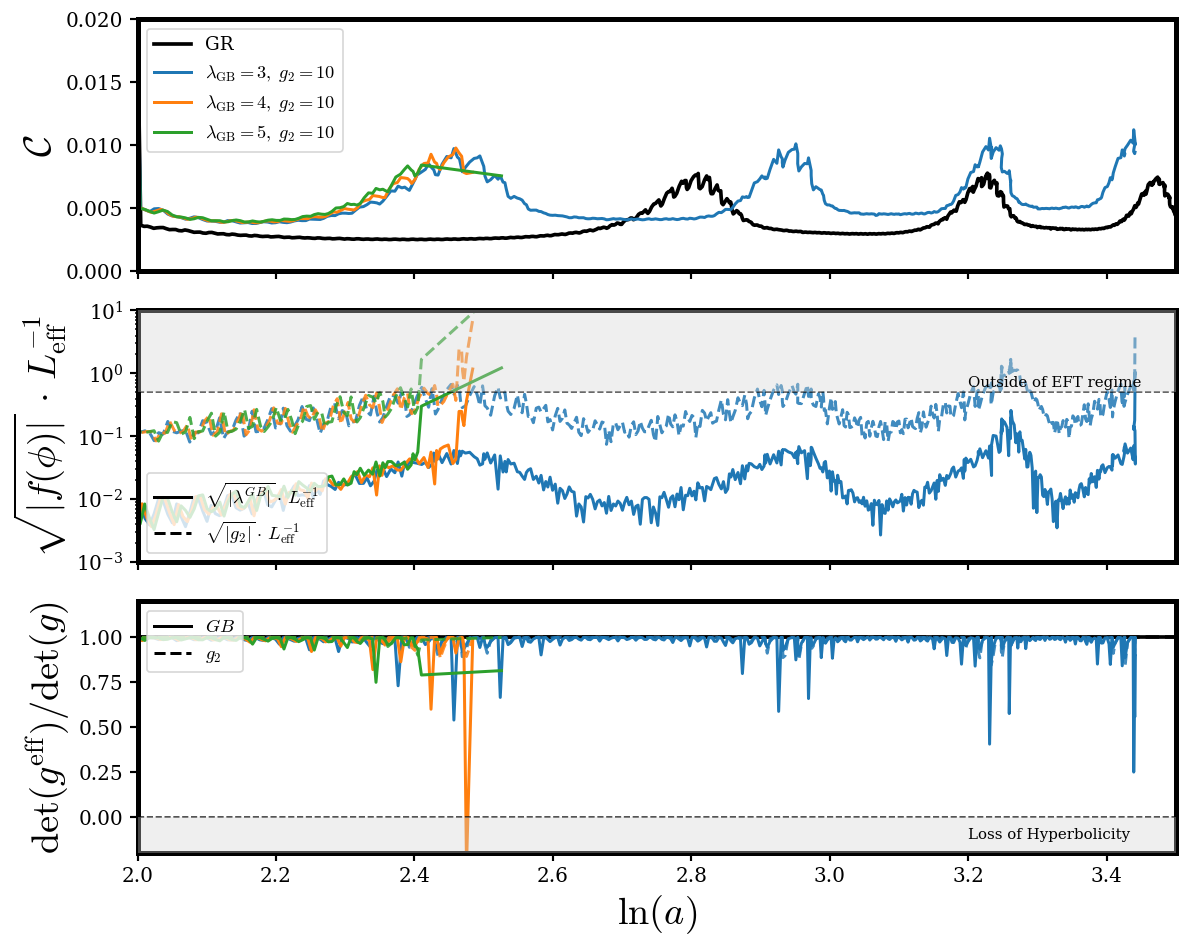

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Mixed lgb + g2 regime: use a multi-stop purple ramp (ColorBrewer-style) so
# adjacent runs are visually distinct even when several curves are overlaid.
# Within a run: solid = lambda' channel; dashed = g2 channel (panels 1 and 2).
from matplotlib.colors import LinearSegmentedColormap as _LSC
from matplotlib.lines  import Line2D
_PURPLES_RAMP = _LSC.from_list(
    "_mix_purples",
    ["blue", "#9e9ac8", "#6a51a3", "#3f007d"],
)

# Sort selected keys by a combined "coupling strength" (max(|lgb|, |g2|), then
# |lgb|, then |g2|) so that the darkest purple is the strongest mixed run.
# Automatically include GR (lgb=0, g2=0) if available, shown in black.
_gr_key_mix = None
for _k in all_runs:
    if _k[0] == 0.0 and _k[5] == 0.0 and (_k[1], _k[2], _k[3], _k[4]) == (
        PLOT4MIX_KEYS[0][1], PLOT4MIX_KEYS[0][2], PLOT4MIX_KEYS[0][3], PLOT4MIX_KEYS[0][4]
    ):
        _gr_key_mix = _k
        break

_keys_sorted = sorted(
    PLOT4MIX_KEYS,
    key=lambda k: (max(abs(k[0]), abs(k[5])), abs(k[0]), abs(k[5])),
)
if _gr_key_mix is not None and _gr_key_mix not in _keys_sorted:
    _keys_sorted.insert(0, _gr_key_mix)
_n_mix = len([k for k in _keys_sorted if not (k[0] == 0.0 and k[5] == 0.0)])

_TAB10_MIX = plt.cm.tab10

def _color_for_mix(color_idx):
    return _TAB10_MIX(color_idx % 10)


if len(_keys_sorted) == 0:
    print("No keys selected for Panel 4-MIX.")
else:
    first = all_runs[_keys_sorted[0]]
    r0    = first["eft"]["r"] if ("eft" in first) else None
    r_mask = (r0 > 0) & (r0 <= R_WCC_MAX_MIX) if r0 is not None else None

    _color_counter = 0
    for idx, key in enumerate(_keys_sorted):
        run = all_runs[key]
        osc = run["osc"]
        eft = run.get("eft", None)
        lgb, mu, beta, amp, width, g2 = key

        is_gr = (lgb == 0.0 and g2 == 0.0)
        label = (rf"GR" if is_gr else
                 rf"$\lambda_{{\rm GB}}={lgb:g},\;g_2={g2:g}$")
        if is_gr:
            color = "k"
        else:
            color = _color_for_mix(_color_counter)
            _color_counter += 1
        lw    = 2.2 if is_gr else 1.8

        x = run["shifted_ln_a"]

        # Panel 0: compactness
        axes[0].plot(x, osc["C"], color=color, lw=lw, label=label)

        # Panel 1: unified weak-coupling condition. L_eff^{-1} = max(L^{-1}, L_tilde^{-1}).
        if eft is not None and r_mask is not None and all(
            k_ in eft for k_ in ("L_inv", "L_tilde_inv", "lambda_prime_bare", "g2_bare")
        ):
            L_inv_full     = eft["L_inv"]
            L_tilde_inv_f  = eft["L_tilde_inv"]
            L_eff_inv      = np.maximum(L_inv_full, L_tilde_inv_f)  # (T, N)
            wc_lam_unified = np.sqrt(np.maximum(eft["lambda_prime_bare"], 0.0)) * L_eff_inv
            wc_g2_unified  = np.sqrt(np.maximum(eft["g2_bare"],            0.0)) * L_eff_inv

            wc_lam_max = np.nanmax(wc_lam_unified[:, r_mask], axis=1)
            wc_g2_max  = np.nanmax(wc_g2_unified[:,  r_mask], axis=1)
            axes[1].plot(x, wc_lam_max, color=color, lw=lw, ls="-",  label=label)
            axes[1].plot(x, wc_g2_max,  color=color, lw=lw, ls="--", alpha=0.85)

            # ── Which length scale is actually setting L_eff^{-1}? ──
            # Global statistic over the (t, r in r_mask) region.
            L_inv_m  = L_inv_full[:,    r_mask]
            L_til_m  = L_tilde_inv_f[:, r_mask]
            frac_GB  = float(np.mean(L_inv_m > L_til_m))
            frac_g2  = float(np.mean(L_til_m > L_inv_m))
            if frac_GB > 0.8:
                verdict = "L^-1 (GB) dominates"
            elif frac_g2 > 0.8:
                verdict = "L_tilde^-1 (g2) dominates"
            else:
                verdict = "mixed (neither dominates >80%)"
            # Same check, but only at the radius that *binds* each WCC channel
            # (i.e. where sqrt(|coupling|)*L_eff^{-1} is maximised) per time.
            T_steps   = L_inv_m.shape[0]
            t_idx_    = np.arange(T_steps)
            r_idx_lam = np.nanargmax(wc_lam_unified[:, r_mask], axis=1)
            r_idx_g2  = np.nanargmax(wc_g2_unified[:,  r_mask], axis=1)
            bind_lam_GB = float(np.mean(
                L_inv_m[t_idx_, r_idx_lam] > L_til_m[t_idx_, r_idx_lam]))
            bind_g2_GB  = float(np.mean(
                L_inv_m[t_idx_, r_idx_g2]  > L_til_m[t_idx_, r_idx_g2]))
            print(
                f"  (lgb={lgb:g}, g2={g2:g}):  "
                f"L^-1 wins in {frac_GB:5.1%} of (t,r),  "
                f"L_tilde^-1 wins in {frac_g2:5.1%}  ->  {verdict}\n"
                f"     at WCC-binding radius:  "
                f"lambda' channel uses L^-1 in {bind_lam_GB:5.1%} of t,  "
                f"g2 channel uses L^-1 in {bind_g2_GB:5.1%} of t"
            )

        # Panel 2: hyperbolicity — disc_GB (solid) and disc_g2 (dashed) together.
        if eft is not None and r_mask is not None:
            if "disc_GB" in eft:
                disc_GB_min = np.nanmin(eft["disc_GB"][:, r_mask], axis=1)
                axes[2].plot(x, disc_GB_min, color=color, lw=lw, ls="-",  label=label)
            if "disc_g2" in eft:
                disc_g2_min = np.nanmin(eft["disc_g2"][:, r_mask], axis=1)
                axes[2].plot(x, disc_g2_min, color=color, lw=lw, ls="--", alpha=0.85)

    axes[0].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[0].set_ylabel(r"$\mathcal{C}$")
    axes[0].set_ylim(0, 0.02)

    #axes[1].axhline(1.0, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[1].set_ylabel(r"$\sqrt{|f(\phi)|}\,\cdot\, L_{\rm eff}^{-1}$")
    axes[1].set_yscale("log")
    axes[1].set_ylim(1e-3, 1e1)

    axes[2].set_ylabel(r"$\det(g^{\rm eff})/\det(g)$")
    axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
    axes[1].axhspan(0.5, 10, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.8, 0.7, "Outside of EFT regime", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].axhspan(0, -1, facecolor="lightgrey", alpha=0.35, zorder=10)
    from matplotlib.transforms import blended_transform_factory
    _trans1 = blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.8, -0.1, "Loss of Hyperbolicity", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)

    axes[2].axhline(0.0, color="k", lw=1.0, ls="--", alpha=0.8)
    axes[2].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
    axes[2].set_ylabel(r"$\det(g^{\rm eff})/\det(g)$")

    axes[2].set_xlabel(r"$\ln(a)$")
    axes[0].set_xlim(2, 3.5)
    axes[2].set_ylim(-0.2,1.2)

    # Per-run colour legend on the compactness panel.
    axes[0].legend(fontsize=11, ncol=1, loc="upper left")

    # Linestyle legends on the WCC and hyperbolicity panels (coupling channel).
    style_wcc = [
        Line2D([0], [0], color="k", ls="-",  lw=1.8,
               label=r"$\sqrt{|\lambda^{GB}|}\cdot \,L_{\rm eff}^{-1}$"),
        Line2D([0], [0], color="k", ls="--", lw=1.8,
               label=r"$\sqrt{|g_2|}\cdot\,L_{\rm eff}^{-1}$"),
    ]
    axes[1].legend(handles=style_wcc, fontsize=11, loc="lower left")

    style_hyp = [
        Line2D([0], [0], color="k", ls="-",  lw=1.8,
               label=r"$GB$"),
        Line2D([0], [0], color="k", ls="--", lw=1.8,
               label=r"$g_2$"),
    ]
    axes[2].legend(handles=style_hyp, fontsize=11, loc="upper left")

    fig.tight_layout()
    save_fig(fig, PLOT4MIX_NAME)
    plt.show()

In [ ]:
# phi_center and compactness vs aligned ln(a).
# Runs by itself: finds the runs on disk, reads solution.npy, and
# recomputes compactness from rho_phi + rho_GB + rho_g2.
# diagnostics.npz is read only, to reuse the existing ln(a) alignment.
# It is not modified.

import os, sys, re, glob
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _ROOT not in sys.path:
    sys.path.insert(0, _ROOT)

from paths import RUN_DATA
from core.grid import Grid
from core.spacing import CubicSpacing
from core.statevector import StateVector
from matter.scalarmatter_MG import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnvars import BSSNVars
from bssn.ModifiedGravity import GBVars, get_gb_core, get_esgb_br_terms

_SCALAR_MU = 1.0
_CHI0 = 0.15
_R_MAX_DEFAULT = 150.0
_MAX_DR_DEFAULT = 2.0
_SURFACE = 0.05
_STRIDE = 1
_ALIGN_LNA = 2.0
_LNA_MIN, _LNA_MAX = 2.0, 3.5
_FILTER_A, _FILTER_B = 0.0, 0.0
_FILTER_DR = 1.0 / 24.0
_C_CROSS = {-0.02: 0.02, -0.05: 0.04, -0.1: 0.06, -0.5: 0.125}
_C_CROSS_DEFAULT = 0.02

# (lgb, mu, beta, amp, width, g2)
_KEYS = [
    (0, 0.08, 0, -0.02, 3.0, 0),
    (10, 0.08, 0, -0.02, 3.0, 0),
]

_FIG_DIR = Path(os.getcwd()) / "GoodFigures"
_FIG_DIR.mkdir(exist_ok=True)

def _save(fig, name):
    fig.savefig(_FIG_DIR / f"{name}.pdf")
    fig.savefig(_FIG_DIR / f"{name}.png")
    print(f"  saved {name}.pdf and {name}.png")

def _last_crossing(ln_a, C, level):
    mask = ln_a > 0.0
    if not np.any(mask):
        return np.nan
    idx = np.where(mask)[0]
    C_sub, ln_sub = C[idx], ln_a[idx]
    above = C_sub > level
    crossings = np.where(above[:-1] & ~above[1:])[0]
    if len(crossings) == 0:
        return np.nan
    last = crossings[-1]
    frac = (level - C_sub[last + 1]) / (C_sub[last] - C_sub[last + 1])
    return ln_sub[last] * frac + ln_sub[last + 1] * (1.0 - frac)

def _match_key(tag, meta):
    m_lgb = re.search(r"lgb([0-9eE.+-]+)", tag)
    m_mu = re.search(r"mu([0-9eE.+-]+)", tag)
    m_amp = re.search(r"_amp([0-9eE.+-]+)", tag)
    m_R = re.search(r"_R([0-9eE.+-]+)", tag)
    m_a = re.search(r"_a([0-9eE.+-]+)_b", tag)
    m_b = re.search(r"_b([0-9eE.+-]+)_amp", tag)
    m_dr = re.search(r"_dr([0-9eE.+-]+)", tag)
    if not m_lgb or not m_mu:
        return None
    lgb = float(m_lgb.group(1))
    mu = float(m_mu.group(1))
    amp = float(m_amp.group(1)) if m_amp else -0.02
    width = float(m_R.group(1)) if m_R else 3.0
    tag_a = float(m_a.group(1)) if m_a else 0.2
    tag_b = float(m_b.group(1)) if m_b else 0.4
    tag_dr = float(m_dr.group(1)) if m_dr else 0.0625
    if abs(tag_a - _FILTER_A) > 1e-10 or abs(tag_b - _FILTER_B) > 1e-10:
        return None
    if abs(tag_dr - _FILTER_DR) > 1e-4:
        return None
    cpl = str(meta["coupling"]) if "coupling" in meta else "quadratic_0"
    if cpl == "linear":
        beta = None
    elif cpl.startswith("quadratic"):
        parts = cpl.split("_")
        beta = float(parts[1]) if len(parts) > 1 else 250.0
    else:
        beta = None
    g2 = float(meta["g2"]) if "g2" in meta else 0.0
    m_g2 = re.search(r"_g2([0-9eE.+-]+)", tag)
    if m_g2:
        g2 = float(m_g2.group(1))
    return (lgb, mu, beta, amp, width, g2), cpl, tag_dr

def _find_run(want):
    best = None
    for run_dir in sorted(glob.glob(os.path.join(str(RUN_DATA), "lgb*"))):
        if not os.path.exists(os.path.join(run_dir, "solution.npy")):
            continue
        if not os.path.exists(os.path.join(run_dir, "diagnostics.npz")):
            continue
        meta_path = os.path.join(run_dir, "metadata.npz")
        meta = dict(np.load(meta_path, allow_pickle=True)) if os.path.exists(meta_path) else {}
        parsed = _match_key(os.path.basename(run_dir), meta)
        if parsed is None:
            continue
        key, coupling, tag_dr = parsed
        if key != want and not all(
            (a is None and b is None) or (a is not None and b is not None and abs(float(a) - float(b)) < 1e-8)
            for a, b in zip(key, want)
        ):
            continue
        osc = dict(np.load(os.path.join(run_dir, "diagnostics.npz"), allow_pickle=True))
        span = float(np.ptp(np.asarray(osc["ln_a"])))
        if best is None or span > best["span"]:
            best = dict(run_dir=run_dir, tag=os.path.basename(run_dir), key=key,
                        coupling=coupling, tag_dr=tag_dr, meta=meta, osc=osc, span=span)
    return best

def _compactness_total(run, s_ln_a, stride):
    sol = np.load(os.path.join(run["run_dir"], "solution.npy"))
    meta = run["meta"]
    r_max = float(meta["r_max"]) if "r_max" in meta else _R_MAX_DEFAULT
    min_dr = float(meta["min_dr"]) if "min_dr" in meta else run["tag_dr"]
    max_dr = float(meta["max_dr"]) if "max_dr" in meta else _MAX_DR_DEFAULT
    matter = ScalarMatter(_SCALAR_MU, run["key"][1])
    sv = StateVector(matter)
    spacing = CubicSpacing(**CubicSpacing.get_parameters(r_max, min_dr, max_dr))
    grid = Grid(spacing, sv)
    bg = FlatSphericalBackground(grid.r)
    r = grid.r
    gb = GBVars(grid.N)
    bssn = BSSNVars(grid.N)
    phys = r > grid.min_dr * 0.5
    n_t = min(sol.shape[0], len(s_ln_a))
    idxs = np.arange(0, n_t, max(int(stride), 1))
    lna = np.empty(len(idxs))
    phi_c = np.empty(len(idxs))
    C = np.full(len(idxs), np.nan)
    lgb, g2 = run["key"][0], run["key"][5]
    for k, it in enumerate(idxs):
        state = sol[it].reshape(grid.NUM_VARS, -1)
        bssn.set_bssn_vars(state)
        matter.set_matter_vars(state, bssn, grid)
        d1 = grid.get_d1_metric_quantities(state)
        d2 = grid.get_d2_metric_quantities(state)
        phi_c[k] = float(state[12, 0])
        if lgb != 0 or g2 != 0:
            get_gb_core(gb, r, bssn, d1, d2, grid, bg, lgb, _CHI0)
            get_esgb_br_terms(gb, r, matter, bssn, d1, d2, grid, bg,
                              lgb, _CHI0, run["coupling"], g2)
            rho = matter.get_emtensor(r, bssn, bg, gb).rho + gb.rho_GB + gb.rho_g2
        else:
            rho = matter.get_emtensor(r, bssn, bg, gb).rho
        e6 = np.exp(6.0 * bssn.phi)
        rho_c = np.max(rho[phys])
        mask = phys & (rho > _SURFACE * rho_c)
        if np.any(mask):
            rp, rh, e6m = r[mask], rho[mask], e6[mask]
            dV = 4.0 * np.pi * rp**2 * e6m
            M = float(np.trapezoid(rh * dV, rp))
            V = float(np.trapezoid(dV, rp))
            R = (3.0 * V / (4.0 * np.pi)) ** (1.0 / 3.0)
            C[k] = M / (8.0 * np.pi * R)
        lna[k] = s_ln_a[it]
        if (k + 1) % 50 == 0 or k + 1 == len(idxs):
            print(f"    {k + 1:4d}/{len(idxs)}  ln(a)={s_ln_a[it]:.3f}")
    del sol
    return lna, phi_c, C

for want in _KEYS:
    run = _find_run(want)
    if run is None:
        print(f"No run on disk for {want}")
        continue
    osc = run["osc"]
    ln_a = np.asarray(osc["ln_a"], dtype=float)
    level = _C_CROSS.get(run["key"][3], _C_CROSS_DEFAULT)
    anchor = _last_crossing(ln_a, np.asarray(osc["C"], dtype=float), level)
    shift = _ALIGN_LNA - anchor if np.isfinite(anchor) else 0.0
    s_ln_a = ln_a + shift
    print(f"lgb={run['key'][0]:g} g2={run['key'][5]:g}  tag={run['tag']}  shift={shift:+.3f}")
    lna_C, phi_c, C = _compactness_total(run, s_ln_a, _STRIDE)

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(9, 5), sharex=True,
        gridspec_kw={"height_ratios": [2, 1]})
    ax_top.plot(lna_C, phi_c, color="b", lw=1.5, alpha=0.9)
    ax_top.set_ylabel(r"$\phi_{center}$")
    ax_top.set_xlim(_LNA_MIN, _LNA_MAX)
    ax_bot.plot(lna_C, C, color="k", lw=1.5, alpha=0.9)
    ax_bot.set_ylabel(r"$\mathcal{C}$")
    ax_bot.set_xlabel(r"$\ln(a)$")
    ax_bot.set_xlim(_LNA_MIN, _LNA_MAX)
    ax_bot.set_ylim(0, 1e-2)
    fig.tight_layout()
    lgb, mu, beta, amp, width, g2 = run["key"]
    tag = f"lgb{lgb:g}_mu{mu}_beta{beta}_amp{amp}_w{width}_g2{g2:g}"
    _save(fig, f"phi_c_compactness_tot_{tag}")
    plt.show()
